# Learned Hybrid Metric for Reference-Based Evaluation of AI-Generated Summaries

## REALSumm Experiment

This notebook contains the reproducible implementation of the REALSumm experiment used in the thesis.

The experiment combines lexical, semantic, NLI-derived factuality, and structural features to develop and evaluate a Learned Hybrid metric for automatic summary evaluation.

## 1. Environment Setup and Reproducibility

This section prepares the Python environment, imports the required libraries, sets the random seed, defines project paths and output directories, and records software versions for reproducibility.

In [2]:
%pip install -q pandas numpy scipy scikit-learn matplotlib joblib


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import json
import platform
import re
import sys
import warnings

from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

# Fixed seed for reproducible experiments
RANDOM_SEED = 20260723

np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")
print("Random seed:", RANDOM_SEED)

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Libraries imported successfully.
Random seed: 20260723


In [3]:
PROJECT_ROOT = Path.cwd()

DATA_PATH = PROJECT_ROOT / "REALSumm_data.csv"

OUTPUT_ROOT = PROJECT_ROOT / "mr604_outputs"
PREPARED_DATA_DIR = OUTPUT_ROOT / "prepared_data"
SPLIT_DIR = OUTPUT_ROOT / "splits"
FEATURE_DIR = OUTPUT_ROOT / "features"
MODEL_DIR = OUTPUT_ROOT / "models"
RESULT_DIR = OUTPUT_ROOT / "results"
FIGURE_DIR = OUTPUT_ROOT / "figures"

project_folders = [
    OUTPUT_ROOT,
    PREPARED_DATA_DIR,
    SPLIT_DIR,
    FEATURE_DIR,
    MODEL_DIR,
    RESULT_DIR,
    FIGURE_DIR
]

for folder in project_folders:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:")
print(PROJECT_ROOT)

print("\nDataset expected at:")
print(DATA_PATH)

print("\nOutput folders created successfully.")

Project folder:
/Users/sudip

Dataset expected at:
/Users/sudip/REALSumm_data.csv

Output folders created successfully.


## 2. REALSumm Dataset Loading, Preparation, and Validation

This section loads the REALSumm dataset, verifies the required fields and dataset structure, prepares the research variables, cleans the source and summary text, validates numerical and textual data, and records the dataset characteristics used in the experiment.

In [7]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "REALSumm_data.csv was not found.\n"
        "Place REALSumm_data.csv in the same folder as the notebook."
    )

print("Dataset found successfully.")
print("Dataset path:")
print(DATA_PATH)

Dataset found successfully.
Dataset path:
/Users/sudip/REALSumm_data.csv


In [5]:
PACKAGE_NAMES = [
    "pandas",
    "numpy",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

package_versions = {}

for package_name in PACKAGE_NAMES:
    try:
        package_versions[package_name] = version(package_name)
    except PackageNotFoundError:
        package_versions[package_name] = "Not installed"

environment_information = {
    "python_version": sys.version,
    "operating_system": platform.platform(),
    "random_seed": RANDOM_SEED,
    "package_versions": package_versions
}

environment_path = OUTPUT_ROOT / "environment_information.json"

with open(environment_path, "w", encoding="utf-8") as file:
    json.dump(
        environment_information,
        file,
        indent=4
    )

environment_table = pd.DataFrame(
    package_versions.items(),
    columns=["Package", "Version"]
)

display(environment_table)

print("Environment information saved to:")
print(environment_path)

,Package,Version
0,pandas,3.0.1
1,numpy,1.26.4
2,scipy,1.13.1
3,scikit-learn,1.5.1
4,matplotlib,3.10.8
5,joblib,1.4.2


Environment information saved to:
/Users/sudip/mr604_outputs/environment_information.json


In [9]:
raw_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Number of rows:", raw_df.shape[0])
print("Number of columns:", raw_df.shape[1])

display(raw_df.head(3))

Dataset loaded successfully.
Number of rows: 1400
Number of columns: 21


,index,doc_id,rouge_1_f_score,rouge_2_recall,rouge_l_recall,rouge_2_precision,rouge_2_f_score,rouge_1_precision,rouge_1_recall,rouge_l_precision,...,js-2,mover_score,bert_recall_score,bert_precision_score,bert_f_score,litepyramid_recall,model,model_summary,ref_summary,source
0,0,0,0.20000,0.02500,0.19512,0.02632,0.02564,0.20513,0.19512,0.20513,...,-0.673612,0.145815,0.081319,0.079391,0.081849,0.000000,presumm_out_trans_abs.txt,"<t> anuradha koirala , who rescues victims of ...",<t> Anuradha Koirala and 425 young women and g...,( cnn ) two cnn heroes are among the earthquak...
1,1,1,0.42202,0.11628,0.43182,0.07812,0.09345,0.35385,0.52273,0.29231,...,-0.621066,0.254801,0.137194,0.090899,0.115382,0.090909,presumm_out_trans_abs.txt,<t> thousands of bacteria colonies were discov...,<t> Students from the University of Surrey dis...,they may look like as if they come from a plag...
2,2,2,0.35165,0.15909,0.35556,0.15556,0.15731,0.34783,0.35556,0.34783,...,-0.620128,0.191368,0.047441,0.171007,0.109913,0.000000,presumm_out_trans_abs.txt,<t> james rodriguez is another player off the ...,<t> danilo this week agreed to join real madri...,with the confirmation of danilo 's summer swit...


In [11]:
column_table = pd.DataFrame({
    "Column number": range(1, len(raw_df.columns) + 1),
    "Column name": raw_df.columns
})

display(column_table)

,Column number,Column name
0,1,index
1,2,doc_id
2,3,rouge_1_f_score
3,4,rouge_2_recall
4,5,rouge_l_recall
5,6,rouge_2_precision
6,7,rouge_2_f_score
7,8,rouge_1_precision
8,9,rouge_1_recall
9,10,rouge_l_precision


In [13]:
REQUIRED_COLUMNS = [
    "index",
    "doc_id",
    "model",
    "source",
    "ref_summary",
    "model_summary",
    "rouge_l_f_score",
    "bert_f_score",
    "mover_score",
    "litepyramid_recall"
]

missing_required_columns = [
    column
    for column in REQUIRED_COLUMNS
    if column not in raw_df.columns
]

if missing_required_columns:
    raise ValueError(
        "The following required columns are missing: "
        f"{missing_required_columns}"
    )

print("All required research columns are available.")

for column in REQUIRED_COLUMNS:
    print("-", column)

All required research columns are available.
- index
- doc_id
- model
- source
- ref_summary
- model_summary
- rouge_l_f_score
- bert_f_score
- mover_score
- litepyramid_recall


In [15]:
summaries_per_document = (
    raw_df
    .groupby("doc_id")
    .size()
)

complete_duplicate_rows = raw_df.duplicated().sum()

duplicate_document_model_pairs = (
    raw_df[
        ["doc_id", "model"]
    ]
    .duplicated()
    .sum()
)

total_missing_cells = int(
    raw_df.isna().sum().sum()
)

audit_table = pd.DataFrame({
    "Dataset property": [
        "Total rows",
        "Total columns",
        "Unique source documents",
        "Unique summarisation models",
        "Minimum summaries per source document",
        "Maximum summaries per source document",
        "Completely duplicated rows",
        "Duplicated document-model pairs",
        "Total missing cells"
    ],
    "Value": [
        len(raw_df),
        len(raw_df.columns),
        raw_df["doc_id"].nunique(),
        raw_df["model"].nunique(),
        summaries_per_document.min(),
        summaries_per_document.max(),
        complete_duplicate_rows,
        duplicate_document_model_pairs,
        total_missing_cells
    ]
})

display(audit_table)

,Dataset property,Value
0,Total rows,1400
1,Total columns,21
2,Unique source documents,100
3,Unique summarisation models,14
4,Minimum summaries per source document,14
5,Maximum summaries per source document,14
6,Completely duplicated rows,0
7,Duplicated document-model pairs,0
8,Total missing cells,0


In [17]:
missing_value_table = pd.DataFrame({
    "Column": raw_df.columns,
    "Missing values": [
        raw_df[column].isna().sum()
        for column in raw_df.columns
    ],
    "Missing percentage": [
        raw_df[column].isna().mean() * 100
        for column in raw_df.columns
    ]
})

missing_value_table = (
    missing_value_table
    .sort_values(
        by="Missing values",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    missing_value_table.round(4)
)

,Column,Missing values,Missing percentage
0,index,0,0.0
1,js-2,0,0.0
2,ref_summary,0,0.0
3,model_summary,0,0.0
4,model,0,0.0
5,litepyramid_recall,0,0.0
6,bert_f_score,0,0.0
7,bert_precision_score,0,0.0
8,bert_recall_score,0,0.0
9,mover_score,0,0.0


In [19]:
prepared_df = raw_df[
    REQUIRED_COLUMNS
].copy()

prepared_df = prepared_df.rename(columns={
    "index": "summary_id",
    "ref_summary": "reference_summary",
    "model_summary": "candidate_summary",
    "rouge_l_f_score": "rougeL",
    "bert_f_score": "bertScoreF1",
    "mover_score": "moverScore",
    "litepyramid_recall": "human_content_coverage"
})

print("Prepared dataset shape:")
print(prepared_df.shape)

display(prepared_df.head(3))

Prepared dataset shape:
(1400, 10)


,summary_id,doc_id,model,source,reference_summary,candidate_summary,rougeL,bertScoreF1,moverScore,human_content_coverage
0,0,0,presumm_out_trans_abs.txt,( cnn ) two cnn heroes are among the earthquak...,<t> Anuradha Koirala and 425 young women and g...,"<t> anuradha koirala , who rescues victims of ...",0.20000,0.081849,0.145815,0.000000
1,1,1,presumm_out_trans_abs.txt,they may look like as if they come from a plag...,<t> Students from the University of Surrey dis...,<t> thousands of bacteria colonies were discov...,0.34863,0.115382,0.254801,0.090909
2,2,2,presumm_out_trans_abs.txt,with the confirmation of danilo 's summer swit...,<t> danilo this week agreed to join real madri...,<t> james rodriguez is another player off the ...,0.35165,0.109913,0.191368,0.000000


In [21]:
NUMERIC_COLUMNS = [
    "summary_id",
    "doc_id",
    "rougeL",
    "bertScoreF1",
    "moverScore",
    "human_content_coverage"
]

for column in NUMERIC_COLUMNS:
    prepared_df[column] = pd.to_numeric(
        prepared_df[column],
        errors="coerce"
    )

invalid_numeric_table = pd.DataFrame({
    "Column": NUMERIC_COLUMNS,
    "Invalid or missing values": [
        prepared_df[column].isna().sum()
        for column in NUMERIC_COLUMNS
    ]
})

display(invalid_numeric_table)

if invalid_numeric_table[
    "Invalid or missing values"
].sum() > 0:
    raise ValueError(
        "Invalid numerical values were found. "
        "The data must be reviewed before continuing."
    )

print("All required numerical columns are valid.")

,Column,Invalid or missing values
0,summary_id,0
1,doc_id,0
2,rougeL,0
3,bertScoreF1,0
4,moverScore,0
5,human_content_coverage,0


All required numerical columns are valid.


In [23]:
def normalise_whitespace(text):
    """
    Replace repeated spaces, tabs and line breaks
    with one normal space.
    """
    text = str(text)

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


def clean_summary_text(text):
    """
    Remove REALSumm <t> and </t> summary tags
    and normalise the remaining text.
    """
    text = str(text)

    text = re.sub(
        r"</?t>",
        " ",
        text,
        flags=re.IGNORECASE
    )

    return normalise_whitespace(text)


print("Text-cleaning functions created successfully.")

Text-cleaning functions created successfully.


In [25]:
prepared_df["source_clean"] = (
    prepared_df["source"]
    .apply(normalise_whitespace)
)

prepared_df["reference_clean"] = (
    prepared_df["reference_summary"]
    .apply(clean_summary_text)
)

prepared_df["candidate_clean"] = (
    prepared_df["candidate_summary"]
    .apply(clean_summary_text)
)

display(
    prepared_df[
        [
            "source_clean",
            "reference_clean",
            "candidate_clean"
        ]
    ].head(2)
)

,source_clean,reference_clean,candidate_clean
0,( cnn ) two cnn heroes are among the earthquak...,Anuradha Koirala and 425 young women and girls...,"anuradha koirala , who rescues victims of sex ..."
1,they may look like as if they come from a plag...,Students from the University of Surrey discove...,thousands of bacteria colonies were discovered...


In [27]:
TEXT_COLUMNS = [
    "source_clean",
    "reference_clean",
    "candidate_clean"
]

empty_text_table = pd.DataFrame({
    "Text field": TEXT_COLUMNS,
    "Empty records": [
        prepared_df[column]
        .str.strip()
        .eq("")
        .sum()
        for column in TEXT_COLUMNS
    ]
})

display(empty_text_table)

if empty_text_table["Empty records"].sum() > 0:
    raise ValueError(
        "Empty source, reference or candidate text was found."
    )

print("No empty text records were found.")

,Text field,Empty records
0,source_clean,0
1,reference_clean,0
2,candidate_clean,0


No empty text records were found.


In [29]:
SCORE_COLUMNS = [
    "rougeL",
    "bertScoreF1",
    "moverScore",
    "human_content_coverage"
]

score_summary = (
    prepared_df[
        SCORE_COLUMNS
    ]
    .agg([
        "min",
        "max",
        "mean",
        "std",
        "median"
    ])
    .transpose()
    .reset_index()
    .rename(columns={
        "index": "Score"
    })
)

display(
    score_summary.round(6)
)

,Score,min,max,mean,std,median
0,rougeL,0.074070,0.826090,0.400006,0.120550,0.395600
1,bertScoreF1,-0.204646,0.759015,0.273715,0.140599,0.273268
2,moverScore,0.008218,0.712943,0.284896,0.091662,0.276588
3,human_content_coverage,0.000000,1.000000,0.428492,0.236864,0.428571


In [31]:
assert len(prepared_df) == 1400, (
    "The dataset does not contain the expected 1,400 rows."
)

assert prepared_df["summary_id"].is_unique, (
    "Summary IDs are not unique."
)

assert prepared_df["doc_id"].nunique() == 100, (
    "The dataset does not contain 100 source documents."
)

assert prepared_df["model"].nunique() == 14, (
    "The dataset does not contain 14 summarisation models."
)

assert (
    prepared_df
    .groupby("doc_id")
    .size()
    .eq(14)
    .all()
), (
    "Not every source document contains 14 candidate summaries."
)

assert not prepared_df[
    ["doc_id", "model"]
].duplicated().any(), (
    "Duplicate document-model combinations were found."
)

assert prepared_df[
    "human_content_coverage"
].between(0, 1).all(), (
    "Human content-coverage values are outside the 0–1 range."
)

assert np.isfinite(
    prepared_df[SCORE_COLUMNS].to_numpy()
).all(), (
    "Infinite numerical values were found."
)

print("All Phase 1 dataset validation checks passed.")

All Phase 1 dataset validation checks passed.


In [33]:
column_dictionary = pd.DataFrame({
    "Column": [
        "summary_id",
        "doc_id",
        "model",
        "source",
        "reference_summary",
        "candidate_summary",
        "source_clean",
        "reference_clean",
        "candidate_clean",
        "rougeL",
        "bertScoreF1",
        "moverScore",
        "human_content_coverage"
    ],
    "Meaning": [
        "Unique candidate-summary record identifier",
        "Source-document identifier",
        "Name of the summarisation system",
        "Original source article",
        "Original human reference summary",
        "Original AI-generated candidate summary",
        "Cleaned source article",
        "Cleaned human reference summary",
        "Cleaned AI candidate summary",
        "ROUGE-L F1 lexical-overlap score",
        "BERTScore F1 semantic-similarity score",
        "MoverScore semantic-similarity score",
        "LitePyramid human content-coverage judgement"
    ]
})

display(column_dictionary)

,Column,Meaning
0,summary_id,Unique candidate-summary record identifier
1,doc_id,Source-document identifier
2,model,Name of the summarisation system
3,source,Original source article
4,reference_summary,Original human reference summary
5,candidate_summary,Original AI-generated candidate summary
6,source_clean,Cleaned source article
7,reference_clean,Cleaned human reference summary
8,candidate_clean,Cleaned AI candidate summary
9,rougeL,ROUGE-L F1 lexical-overlap score


In [35]:
PREPARED_DATA_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_phase_1_prepared.csv"
)

AUDIT_PATH = (
    RESULT_DIR
    / "phase_1_dataset_audit.csv"
)

SCORE_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_1_score_summary.csv"
)

COLUMN_DICTIONARY_PATH = (
    RESULT_DIR
    / "phase_1_column_dictionary.csv"
)

prepared_df.to_csv(
    PREPARED_DATA_PATH,
    index=False
)

audit_table.to_csv(
    AUDIT_PATH,
    index=False
)

score_summary.to_csv(
    SCORE_SUMMARY_PATH,
    index=False
)

column_dictionary.to_csv(
    COLUMN_DICTIONARY_PATH,
    index=False
)

print("Phase 1 outputs saved successfully.")

print("\nPrepared dataset:")
print(PREPARED_DATA_PATH)

print("\nDataset audit:")
print(AUDIT_PATH)

print("\nScore summary:")
print(SCORE_SUMMARY_PATH)

print("\nColumn dictionary:")
print(COLUMN_DICTIONARY_PATH)

Phase 1 outputs saved successfully.

Prepared dataset:
/Users/sudip/mr604_outputs/prepared_data/realsumm_phase_1_prepared.csv

Dataset audit:
/Users/sudip/mr604_outputs/results/phase_1_dataset_audit.csv

Score summary:
/Users/sudip/mr604_outputs/results/phase_1_score_summary.csv

Column dictionary:
/Users/sudip/mr604_outputs/results/phase_1_column_dictionary.csv


In [37]:
phase_1_summary = pd.DataFrame({
    "Item": [
        "Original rows",
        "Original columns",
        "Source documents",
        "Summarisation systems",
        "Summaries per document",
        "Duplicate rows",
        "Missing cells",
        "Human target",
        "Prepared dataset saved"
    ],
    "Value": [
        len(raw_df),
        len(raw_df.columns),
        prepared_df["doc_id"].nunique(),
        prepared_df["model"].nunique(),
        prepared_df.groupby("doc_id").size().iloc[0],
        raw_df.duplicated().sum(),
        int(raw_df.isna().sum().sum()),
        "LitePyramid human content coverage",
        PREPARED_DATA_PATH.name
    ]
})

display(phase_1_summary)

print("PHASE 1 COMPLETED SUCCESSFULLY")

,Item,Value
0,Original rows,1400
1,Original columns,21
2,Source documents,100
3,Summarisation systems,14
4,Summaries per document,14
5,Duplicate rows,0
6,Missing cells,0
7,Human target,LitePyramid human content coverage
8,Prepared dataset saved,realsumm_phase_1_prepared.csv


PHASE 1 COMPLETED SUCCESSFULLY


## 3. Document-Grouped Development and Locked Holdout Split

REALSumm is divided at the source-document level to prevent information leakage between development and final evaluation. All candidate summaries generated from the same source document remain within the same partition.

The final split contains 80 development documents (1,120 summaries) and 20 locked holdout documents (280 summaries), with zero source-document overlap. The development partition is used for feature development, grouped cross-validation, model selection, hyperparameter tuning, and ablation analysis. The locked holdout is reserved for final evaluation.

In [41]:
import hashlib

from sklearn.model_selection import GroupShuffleSplit

print("Phase 2 libraries imported successfully.")

Phase 2 libraries imported successfully.


In [43]:
PREPARED_DATA_PATH = (
    Path.cwd()
    / "mr604_outputs"
    / "prepared_data"
    / "realsumm_phase_1_prepared.csv"
)

if not PREPARED_DATA_PATH.exists():
    raise FileNotFoundError(
        "The Phase 1 prepared dataset could not be found.\n"
        "Complete Phase 1 before continuing."
    )

prepared_df = pd.read_csv(
    PREPARED_DATA_PATH
)

print("Prepared dataset loaded successfully.")
print("Rows:", len(prepared_df))
print(
    "Source documents:",
    prepared_df["doc_id"].nunique()
)

display(prepared_df.head(3))

Prepared dataset loaded successfully.
Rows: 1400
Source documents: 100


,summary_id,doc_id,model,source,reference_summary,candidate_summary,rougeL,bertScoreF1,moverScore,human_content_coverage,source_clean,reference_clean,candidate_clean
0,0,0,presumm_out_trans_abs.txt,( cnn ) two cnn heroes are among the earthquak...,<t> Anuradha Koirala and 425 young women and g...,"<t> anuradha koirala , who rescues victims of ...",0.20000,0.081849,0.145815,0.000000,( cnn ) two cnn heroes are among the earthquak...,Anuradha Koirala and 425 young women and girls...,"anuradha koirala , who rescues victims of sex ..."
1,1,1,presumm_out_trans_abs.txt,they may look like as if they come from a plag...,<t> Students from the University of Surrey dis...,<t> thousands of bacteria colonies were discov...,0.34863,0.115382,0.254801,0.090909,they may look like as if they come from a plag...,Students from the University of Surrey discove...,thousands of bacteria colonies were discovered...
2,2,2,presumm_out_trans_abs.txt,with the confirmation of danilo 's summer swit...,<t> danilo this week agreed to join real madri...,<t> james rodriguez is another player off the ...,0.35165,0.109913,0.191368,0.000000,with the confirmation of danilo 's summer swit...,danilo this week agreed to join real madrid in...,james rodriguez is another player off the port...


In [45]:
assert len(prepared_df) == 1400, (
    "Expected 1,400 prepared rows."
)

assert prepared_df["doc_id"].nunique() == 100, (
    "Expected 100 source documents."
)

assert (
    prepared_df
    .groupby("doc_id")
    .size()
    .eq(14)
    .all()
), (
    "Every source document must have exactly 14 candidate summaries."
)

print("Prepared dataset is ready for grouped division.")

Prepared dataset is ready for grouped division.


In [47]:
PILOT_SPLIT_SEED = 42

pilot_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=PILOT_SPLIT_SEED
)

pilot_development_index, pilot_test_index = next(
    pilot_splitter.split(
        X=prepared_df,
        y=prepared_df["human_content_coverage"],
        groups=prepared_df["doc_id"]
    )
)

pilot_test_document_ids = set(
    prepared_df
    .iloc[pilot_test_index]["doc_id"]
    .unique()
)

pilot_development_document_ids = set(
    prepared_df
    .iloc[pilot_development_index]["doc_id"]
    .unique()
)

print(
    "Previous trial development documents:",
    len(pilot_development_document_ids)
)

print(
    "Previous trial test documents:",
    len(pilot_test_document_ids)
)

print(
    "Previous trial document overlap:",
    len(
        pilot_development_document_ids.intersection(
            pilot_test_document_ids
        )
    )
)

Previous trial development documents: 80
Previous trial test documents: 20
Previous trial document overlap: 0


In [49]:
all_document_ids = set(
    prepared_df["doc_id"].unique()
)

eligible_final_test_document_ids = (
    all_document_ids
    - pilot_test_document_ids
)

print(
    "Total source documents:",
    len(all_document_ids)
)

print(
    "Documents previously used for trial testing:",
    len(pilot_test_document_ids)
)

print(
    "Documents eligible for new final testing:",
    len(eligible_final_test_document_ids)
)

Total source documents: 100
Documents previously used for trial testing: 20
Documents eligible for new final testing: 80


In [51]:
FINAL_SPLIT_SEED = RANDOM_SEED

eligible_document_array = np.array(
    sorted(eligible_final_test_document_ids)
)

random_generator = np.random.default_rng(
    FINAL_SPLIT_SEED
)

final_test_document_ids = set(
    random_generator.choice(
        eligible_document_array,
        size=20,
        replace=False
    ).tolist()
)

development_document_ids = (
    all_document_ids
    - final_test_document_ids
)

print(
    "Development documents:",
    len(development_document_ids)
)

print(
    "New final-test documents:",
    len(final_test_document_ids)
)

print(
    "Final-test overlap with previous trial test:",
    len(
        final_test_document_ids.intersection(
            pilot_test_document_ids
        )
    )
)

print(
    "Development and final-test overlap:",
    len(
        development_document_ids.intersection(
            final_test_document_ids
        )
    )
)

Development documents: 80
New final-test documents: 20
Final-test overlap with previous trial test: 0
Development and final-test overlap: 0


In [53]:
development_df = (
    prepared_df[
        prepared_df["doc_id"].isin(
            development_document_ids
        )
    ]
    .copy()
    .reset_index(drop=True)
)

final_test_df = (
    prepared_df[
        prepared_df["doc_id"].isin(
            final_test_document_ids
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("Development rows:", len(development_df))
print("Final-test rows:", len(final_test_df))

print(
    "Development source documents:",
    development_df["doc_id"].nunique()
)

print(
    "Final-test source documents:",
    final_test_df["doc_id"].nunique()
)

Development rows: 1120
Final-test rows: 280
Development source documents: 80
Final-test source documents: 20


In [55]:
development_ids_check = set(
    development_df["doc_id"].unique()
)

final_test_ids_check = set(
    final_test_df["doc_id"].unique()
)

document_overlap = (
    development_ids_check
    .intersection(final_test_ids_check)
)

assert len(development_df) == 1120, (
    "Expected 1,120 development rows."
)

assert len(final_test_df) == 280, (
    "Expected 280 final-test rows."
)

assert development_df["doc_id"].nunique() == 80, (
    "Expected 80 development documents."
)

assert final_test_df["doc_id"].nunique() == 20, (
    "Expected 20 final-test documents."
)

assert len(document_overlap) == 0, (
    "Source-document leakage was detected."
)

assert final_test_document_ids.isdisjoint(
    pilot_test_document_ids
), (
    "The final test contains documents used in the earlier trial test."
)

assert (
    development_df
    .groupby("doc_id")
    .size()
    .eq(14)
    .all()
), (
    "A development document does not contain all 14 summaries."
)

assert (
    final_test_df
    .groupby("doc_id")
    .size()
    .eq(14)
    .all()
), (
    "A final-test document does not contain all 14 summaries."
)

assert set(development_df["model"]) == set(
    final_test_df["model"]
), (
    "Development and final-test model sets are different."
)

print("All grouped split validation checks passed.")

All grouped split validation checks passed.


In [57]:
development_model_counts = (
    development_df["model"]
    .value_counts()
    .sort_index()
)

final_test_model_counts = (
    final_test_df["model"]
    .value_counts()
    .sort_index()
)

model_distribution_table = pd.DataFrame({
    "Model": development_model_counts.index,
    "Development summaries": (
        development_model_counts.values
    ),
    "Final-test summaries": (
        final_test_model_counts[
            development_model_counts.index
        ].values
    )
})

display(model_distribution_table)

,Model,Development summaries,Final-test summaries
0,bart_out.txt,80,20
1,bottom_up_out.txt,80,20
2,fast_abs_rl_out_rerank.txt,80,20
3,presumm_out_abs.txt,80,20
4,presumm_out_ext_abs.txt,80,20
5,presumm_out_trans_abs.txt,80,20
6,ptr_generator_out_pointer_gen_cov.txt,80,20
7,semsim_out.txt,80,20
8,t5_out_11B.txt,80,20
9,t5_out_base.txt,80,20


In [59]:
target_distribution_table = pd.DataFrame({
    "Dataset": [
        "Full dataset",
        "Development dataset",
        "Final-test dataset"
    ],
    "Rows": [
        len(prepared_df),
        len(development_df),
        len(final_test_df)
    ],
    "Documents": [
        prepared_df["doc_id"].nunique(),
        development_df["doc_id"].nunique(),
        final_test_df["doc_id"].nunique()
    ],
    "Mean target": [
        prepared_df[
            "human_content_coverage"
        ].mean(),
        development_df[
            "human_content_coverage"
        ].mean(),
        final_test_df[
            "human_content_coverage"
        ].mean()
    ],
    "Standard deviation": [
        prepared_df[
            "human_content_coverage"
        ].std(),
        development_df[
            "human_content_coverage"
        ].std(),
        final_test_df[
            "human_content_coverage"
        ].std()
    ],
    "Median target": [
        prepared_df[
            "human_content_coverage"
        ].median(),
        development_df[
            "human_content_coverage"
        ].median(),
        final_test_df[
            "human_content_coverage"
        ].median()
    ],
    "Minimum target": [
        prepared_df[
            "human_content_coverage"
        ].min(),
        development_df[
            "human_content_coverage"
        ].min(),
        final_test_df[
            "human_content_coverage"
        ].min()
    ],
    "Maximum target": [
        prepared_df[
            "human_content_coverage"
        ].max(),
        development_df[
            "human_content_coverage"
        ].max(),
        final_test_df[
            "human_content_coverage"
        ].max()
    ]
})

display(
    target_distribution_table.round(6)
)

,Dataset,Rows,Documents,Mean target,Standard deviation,Median target,Minimum target,Maximum target
0,Full dataset,1400,100,0.428492,0.236864,0.428571,0.0,1.0
1,Development dataset,1120,80,0.438703,0.239346,0.444444,0.0,1.0
2,Final-test dataset,280,20,0.387646,0.222424,0.374126,0.0,1.0


In [61]:
split_manifest = pd.DataFrame({
    "doc_id": sorted(all_document_ids)
})

split_manifest["dataset_split"] = (
    split_manifest["doc_id"]
    .apply(
        lambda document_id:
        "final_test"
        if document_id in final_test_document_ids
        else "development"
    )
)

split_manifest["was_in_previous_trial_test"] = (
    split_manifest["doc_id"]
    .isin(pilot_test_document_ids)
)

split_manifest["pilot_split_seed"] = (
    PILOT_SPLIT_SEED
)

split_manifest["final_split_seed"] = (
    FINAL_SPLIT_SEED
)

display(
    split_manifest[
        [
            "dataset_split",
            "was_in_previous_trial_test"
        ]
    ]
    .value_counts()
    .reset_index(name="Document count")
)

,dataset_split,was_in_previous_trial_test,Document count
0,development,False,60
1,development,True,20
2,final_test,False,20


In [63]:
DEVELOPMENT_DATA_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_development.csv"
)

FINAL_TEST_DATA_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_final_test_LOCKED.csv"
)

SPLIT_MANIFEST_PATH = (
    SPLIT_DIR
    / "realsumm_document_split_manifest.csv"
)

MODEL_DISTRIBUTION_PATH = (
    RESULT_DIR
    / "phase_2_model_distribution.csv"
)

TARGET_DISTRIBUTION_PATH = (
    RESULT_DIR
    / "phase_2_target_distribution.csv"
)

development_df.to_csv(
    DEVELOPMENT_DATA_PATH,
    index=False
)

final_test_df.to_csv(
    FINAL_TEST_DATA_PATH,
    index=False
)

split_manifest.to_csv(
    SPLIT_MANIFEST_PATH,
    index=False
)

model_distribution_table.to_csv(
    MODEL_DISTRIBUTION_PATH,
    index=False
)

target_distribution_table.to_csv(
    TARGET_DISTRIBUTION_PATH,
    index=False
)

print("Phase 2 files saved successfully.")

print("\nDevelopment dataset:")
print(DEVELOPMENT_DATA_PATH)

print("\nLocked final-test dataset:")
print(FINAL_TEST_DATA_PATH)

print("\nSplit manifest:")
print(SPLIT_MANIFEST_PATH)

Phase 2 files saved successfully.

Development dataset:
/Users/sudip/mr604_outputs/prepared_data/realsumm_development.csv

Locked final-test dataset:
/Users/sudip/mr604_outputs/prepared_data/realsumm_final_test_LOCKED.csv

Split manifest:
/Users/sudip/mr604_outputs/splits/realsumm_document_split_manifest.csv


In [65]:
def calculate_sha256(file_path):
    """
    Calculate the SHA-256 fingerprint of a file.
    """
    sha256_hash = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            data_block = file.read(65536)

            if not data_block:
                break

            sha256_hash.update(data_block)

    return sha256_hash.hexdigest()


fingerprint_table = pd.DataFrame({
    "File": [
        DEVELOPMENT_DATA_PATH.name,
        FINAL_TEST_DATA_PATH.name,
        SPLIT_MANIFEST_PATH.name
    ],
    "SHA-256 fingerprint": [
        calculate_sha256(
            DEVELOPMENT_DATA_PATH
        ),
        calculate_sha256(
            FINAL_TEST_DATA_PATH
        ),
        calculate_sha256(
            SPLIT_MANIFEST_PATH
        )
    ]
})

FINGERPRINT_PATH = (
    SPLIT_DIR
    / "phase_2_file_fingerprints.csv"
)

fingerprint_table.to_csv(
    FINGERPRINT_PATH,
    index=False
)

display(fingerprint_table)

print("File fingerprints saved to:")
print(FINGERPRINT_PATH)

,File,SHA-256 fingerprint
0,realsumm_development.csv,fad6c90e3417adec7b3b18f70c8289d39e7f5ef4049230...
1,realsumm_final_test_LOCKED.csv,11c953249552f2927c6d5d379810eb3c3cccdd87d9b618...
2,realsumm_document_split_manifest.csv,17d396fa48f748056169dcc8926d4ae47cc8ac19960cf8...


File fingerprints saved to:
/Users/sudip/mr604_outputs/splits/phase_2_file_fingerprints.csv


In [67]:
phase_2_summary = pd.DataFrame({
    "Item": [
        "Total source documents",
        "Development source documents",
        "Final-test source documents",
        "Development candidate summaries",
        "Final-test candidate summaries",
        "Summarisation systems in development",
        "Summarisation systems in final test",
        "Development/final-test document overlap",
        "Final-test overlap with trial test",
        "Development file",
        "Locked final-test file"
    ],
    "Value": [
        len(all_document_ids),
        development_df["doc_id"].nunique(),
        final_test_df["doc_id"].nunique(),
        len(development_df),
        len(final_test_df),
        development_df["model"].nunique(),
        final_test_df["model"].nunique(),
        len(document_overlap),
        len(
            final_test_document_ids.intersection(
                pilot_test_document_ids
            )
        ),
        DEVELOPMENT_DATA_PATH.name,
        FINAL_TEST_DATA_PATH.name
    ]
})

PHASE_2_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_2_data_split_summary.csv"
)

phase_2_summary.to_csv(
    PHASE_2_SUMMARY_PATH,
    index=False
)

display(phase_2_summary)

print("PHASE 2 COMPLETED SUCCESSFULLY")

,Item,Value
0,Total source documents,100
1,Development source documents,80
2,Final-test source documents,20
3,Development candidate summaries,1120
4,Final-test candidate summaries,280
5,Summarisation systems in development,14
6,Summarisation systems in final test,14
7,Development/final-test document overlap,0
8,Final-test overlap with trial test,0
9,Development file,realsumm_development.csv


PHASE 2 COMPLETED SUCCESSFULLY


## 4. Structural Feature Extraction

Five structural features are derived from the development partition to represent complementary aspects of summary structure: length adequacy, sentence-count ratio, redundancy quality, compression ratio, and average sentence length.

All structural feature development is performed using only the 1,120 development summaries from 80 source documents. The locked holdout partition remains excluded until final evaluation.

In [70]:
del final_test_df
del prepared_df

analysis_df = development_df.copy()

print(
    "The active research dataset now contains "
    "development data only."
)

print("Active rows:", len(analysis_df))

print(
    "Active source documents:",
    analysis_df["doc_id"].nunique()
)

print(
    "\nThe locked final-test dataset will not be "
    "loaded again until final evaluation."
)

The active research dataset now contains development data only.
Active rows: 1120
Active source documents: 80

The locked final-test dataset will not be loaded again until final evaluation.


In [72]:
print("Active dataset rows:", len(analysis_df))

print(
    "Active source documents:",
    analysis_df["doc_id"].nunique()
)

assert len(analysis_df) == 1120, (
    "The active dataset should contain "
    "1,120 development summaries."
)

assert analysis_df["doc_id"].nunique() == 80, (
    "The active dataset should contain "
    "80 development source documents."
)

print(
    "Confirmed: structural feature development "
    "will use development data only."
)

Active dataset rows: 1120
Active source documents: 80
Confirmed: structural feature development will use development data only.


In [74]:
def extract_words(text):
    """
    Extract lowercase word tokens.

    Apostrophes inside words are preserved.
    Numbers are also counted as tokens.
    """
    text = str(text).lower()

    return re.findall(
        r"\b[\w]+(?:'[\w]+)?\b",
        text
    )


def count_words(text):
    """
    Count the number of word tokens.
    """
    return len(extract_words(text))


def split_sentences(original_text, cleaned_text=None):
    """
    Recover sentences from REALSumm <t> tags where possible.

    If <t> tags are unavailable, use sentence-ending
    punctuation as a fallback.
    """
    original_text = str(original_text)

    tagged_sentences = re.findall(
        r"<t>(.*?)</t>",
        original_text,
        flags=re.IGNORECASE | re.DOTALL
    )

    tagged_sentences = [
        normalise_whitespace(sentence)
        for sentence in tagged_sentences
        if normalise_whitespace(sentence)
    ]

    if tagged_sentences:
        return tagged_sentences

    if cleaned_text is None:
        cleaned_text = clean_summary_text(
            original_text
        )

    cleaned_text = normalise_whitespace(
        cleaned_text
    )

    sentence_parts = re.split(
        r"(?<=[.!?])\s+",
        cleaned_text
    )

    valid_sentences = [
        sentence.strip()
        for sentence in sentence_parts
        if sentence.strip()
    ]

    if valid_sentences:
        return valid_sentences

    if cleaned_text:
        return [cleaned_text]

    return []


def count_sentences(original_text, cleaned_text=None):
    """
    Count recovered sentences.
    """
    return len(
        split_sentences(
            original_text,
            cleaned_text
        )
    )


def symmetric_ratio(value_a, value_b):
    """
    Compare two positive quantities on a 0–1 scale.

    A value of 1 means they are equal.
    Smaller values indicate a greater difference.
    """
    value_a = float(value_a)
    value_b = float(value_b)

    if value_a <= 0 or value_b <= 0:
        return 0.0

    return min(
        value_a / value_b,
        value_b / value_a
    )


def repeated_bigram_rate(text):
    """
    Calculate the proportion of repeated adjacent
    two-word sequences.

    A value of 0 means that no bigram is repeated.
    """
    words = extract_words(text)

    if len(words) < 2:
        return 0.0

    bigrams = [
        tuple(words[index:index + 2])
        for index in range(len(words) - 1)
    ]

    total_bigrams = len(bigrams)
    unique_bigrams = len(set(bigrams))

    repeated_bigrams = (
        total_bigrams - unique_bigrams
    )

    return repeated_bigrams / total_bigrams


print("Structural processing functions created successfully.")

Structural processing functions created successfully.


In [76]:
sample_row = analysis_df.iloc[0]

sample_candidate_sentences = split_sentences(
    sample_row["candidate_summary"],
    sample_row["candidate_clean"]
)

sample_reference_sentences = split_sentences(
    sample_row["reference_summary"],
    sample_row["reference_clean"]
)

print("Candidate summary:")
print(sample_row["candidate_clean"])

print("\nRecovered candidate sentences:")
for sentence_number, sentence in enumerate(
    sample_candidate_sentences,
    start=1
):
    print(f"{sentence_number}. {sentence}")

print("\nCandidate word count:")
print(count_words(sample_row["candidate_clean"]))

print("\nCandidate sentence count:")
print(len(sample_candidate_sentences))

print("\nReference sentence count:")
print(len(sample_reference_sentences))

print("\nRepeated bigram rate:")
print(
    round(
        repeated_bigram_rate(
            sample_row["candidate_clean"]
        ),
        6
    )
)

Candidate summary:
anuradha koirala , who rescues victims of sex trafficking , has a rehab center in kathmandu koirala 's group is relying on bottled water and is now rationing food koirala : " these girls are most vulnerable , because now people will target them "

Recovered candidate sentences:
1. anuradha koirala , who rescues victims of sex trafficking , has a rehab center in kathmandu
2. koirala 's group is relying on bottled water and is now rationing food
3. koirala : " these girls are most vulnerable , because now people will target them "

Candidate word count:
39

Candidate sentence count:
3

Reference sentence count:
3

Repeated bigram rate:
0.0


In [78]:
# Source, reference and candidate word counts
analysis_df["source_word_count"] = (
    analysis_df["source_clean"]
    .apply(count_words)
)

analysis_df["reference_word_count"] = (
    analysis_df["reference_clean"]
    .apply(count_words)
)

analysis_df["candidate_word_count"] = (
    analysis_df["candidate_clean"]
    .apply(count_words)
)


# Reference and candidate sentence counts
analysis_df["reference_sentence_count"] = [
    count_sentences(
        original_text=original_text,
        cleaned_text=cleaned_text
    )
    for original_text, cleaned_text
    in zip(
        analysis_df["reference_summary"],
        analysis_df["reference_clean"]
    )
]

analysis_df["candidate_sentence_count"] = [
    count_sentences(
        original_text=original_text,
        cleaned_text=cleaned_text
    )
    for original_text, cleaned_text
    in zip(
        analysis_df["candidate_summary"],
        analysis_df["candidate_clean"]
    )
]


# Candidate repetition rate
analysis_df["repeated_bigram_rate"] = (
    analysis_df["candidate_clean"]
    .apply(repeated_bigram_rate)
)

print(
    "Underlying structural quantities "
    "calculated successfully."
)

display(
    analysis_df[
        [
            "source_word_count",
            "reference_word_count",
            "candidate_word_count",
            "reference_sentence_count",
            "candidate_sentence_count",
            "repeated_bigram_rate"
        ]
    ].head()
)

Underlying structural quantities calculated successfully.


,source_word_count,reference_word_count,candidate_word_count,reference_sentence_count,candidate_sentence_count,repeated_bigram_rate
0,843,41,39,3,3,0.000000
1,754,44,65,4,3,0.000000
2,505,53,59,4,3,0.017241
3,567,54,49,4,3,0.041667
4,1154,47,101,3,5,0.020000


In [80]:
# 1. Length adequacy
analysis_df["length_adequacy"] = [
    symmetric_ratio(
        candidate_length,
        reference_length
    )
    for candidate_length, reference_length
    in zip(
        analysis_df["candidate_word_count"],
        analysis_df["reference_word_count"]
    )
]


# 2. Sentence-count ratio
analysis_df["sentence_count_ratio"] = [
    symmetric_ratio(
        candidate_sentences,
        reference_sentences
    )
    for candidate_sentences, reference_sentences
    in zip(
        analysis_df["candidate_sentence_count"],
        analysis_df["reference_sentence_count"]
    )
]


# 3. Redundancy quality
analysis_df["redundancy_quality"] = (
    1 - analysis_df["repeated_bigram_rate"]
)


# 4. Compression ratio
analysis_df["compression_ratio"] = (
    analysis_df["candidate_word_count"]
    / analysis_df["source_word_count"]
)


# 5. Average candidate sentence length
analysis_df["average_sentence_length"] = (
    analysis_df["candidate_word_count"]
    / analysis_df["candidate_sentence_count"]
)


STRUCTURAL_FEATURES = [
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]

print("Structural features calculated successfully.")

display(
    analysis_df[
        STRUCTURAL_FEATURES
    ].head()
)

Structural features calculated successfully.


,length_adequacy,sentence_count_ratio,redundancy_quality,compression_ratio,average_sentence_length
0,0.951220,1.00,1.000000,0.046263,13.000000
1,0.676923,0.75,1.000000,0.086207,21.666667
2,0.898305,0.75,0.982759,0.116832,19.666667
3,0.907407,0.75,0.958333,0.086420,16.333333
4,0.465347,0.60,0.980000,0.087522,20.200000


In [82]:
assert (
    analysis_df["source_word_count"] > 0
).all(), (
    "A source article has zero words."
)

assert (
    analysis_df["reference_word_count"] > 0
).all(), (
    "A reference summary has zero words."
)

assert (
    analysis_df["candidate_word_count"] > 0
).all(), (
    "A candidate summary has zero words."
)

assert (
    analysis_df["reference_sentence_count"] > 0
).all(), (
    "A reference summary has zero sentences."
)

assert (
    analysis_df["candidate_sentence_count"] > 0
).all(), (
    "A candidate summary has zero sentences."
)

assert analysis_df[
    "length_adequacy"
].between(0, 1).all(), (
    "Length adequacy is outside the 0–1 range."
)

assert analysis_df[
    "sentence_count_ratio"
].between(0, 1).all(), (
    "Sentence-count ratio is outside the 0–1 range."
)

assert analysis_df[
    "redundancy_quality"
].between(0, 1).all(), (
    "Redundancy quality is outside the 0–1 range."
)

assert (
    analysis_df["compression_ratio"] > 0
).all(), (
    "Compression ratio contains non-positive values."
)

assert (
    analysis_df["average_sentence_length"] > 0
).all(), (
    "Average sentence length contains "
    "non-positive values."
)

assert np.isfinite(
    analysis_df[
        STRUCTURAL_FEATURES
    ].to_numpy()
).all(), (
    "Structural features contain infinite values."
)

print("All structural feature validation checks passed.")

All structural feature validation checks passed.


In [84]:
structural_summary = (
    analysis_df[
        STRUCTURAL_FEATURES
    ]
    .agg([
        "min",
        "max",
        "mean",
        "std",
        "median"
    ])
    .transpose()
    .reset_index()
    .rename(columns={
        "index": "Structural feature"
    })
)

display(
    structural_summary.round(6)
)

,Structural feature,min,max,mean,std,median
0,length_adequacy,0.268657,1.000000,0.764279,0.149626,0.777778
1,sentence_count_ratio,0.166667,1.000000,0.708629,0.249113,0.750000
2,redundancy_quality,0.586957,1.000000,0.979127,0.039383,0.987878
3,compression_ratio,0.019579,0.405498,0.106015,0.053128,0.095448
4,average_sentence_length,7.333333,90.000000,19.700015,12.075146,16.250000


In [86]:
from scipy.stats import pearsonr, spearmanr


def safe_correlation(
    correlation_function,
    values_a,
    values_b
):
    """
    Return only the correlation statistic.
    """
    result = correlation_function(
        values_a,
        values_b
    )

    if hasattr(result, "statistic"):
        return float(result.statistic)

    return float(result[0])


structural_relationship_rows = []

for feature in STRUCTURAL_FEATURES:

    pearson_value = safe_correlation(
        pearsonr,
        analysis_df[feature],
        analysis_df["human_content_coverage"]
    )

    spearman_value = safe_correlation(
        spearmanr,
        analysis_df[feature],
        analysis_df["human_content_coverage"]
    )

    structural_relationship_rows.append({
        "Feature": feature,
        "Pearson with human coverage": (
            pearson_value
        ),
        "Spearman with human coverage": (
            spearman_value
        )
    })


structural_relationship_table = (
    pd.DataFrame(
        structural_relationship_rows
    )
    .sort_values(
        by="Pearson with human coverage",
        key=lambda values: values.abs(),
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    structural_relationship_table.round(4)
)

,Feature,Pearson with human coverage,Spearman with human coverage
0,compression_ratio,0.2481,0.2544
1,length_adequacy,-0.0772,-0.0792
2,redundancy_quality,0.0761,0.0352
3,sentence_count_ratio,0.0193,0.0353
4,average_sentence_length,-0.0175,0.0822


In [88]:
STRUCTURAL_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_structural_features.csv"
)

STRUCTURAL_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_3_structural_feature_summary.csv"
)

STRUCTURAL_RELATIONSHIP_PATH = (
    RESULT_DIR
    / "phase_3_structural_feature_relationships.csv"
)

analysis_df.to_csv(
    STRUCTURAL_DATA_PATH,
    index=False
)

structural_summary.to_csv(
    STRUCTURAL_SUMMARY_PATH,
    index=False
)

structural_relationship_table.to_csv(
    STRUCTURAL_RELATIONSHIP_PATH,
    index=False
)

print("Structural feature outputs saved successfully.")

print("\nDevelopment feature dataset:")
print(STRUCTURAL_DATA_PATH)

print("\nStructural summary:")
print(STRUCTURAL_SUMMARY_PATH)

print("\nStructural relationships:")
print(STRUCTURAL_RELATIONSHIP_PATH)

Structural feature outputs saved successfully.

Development feature dataset:
/Users/sudip/mr604_outputs/features/realsumm_development_structural_features.csv

Structural summary:
/Users/sudip/mr604_outputs/results/phase_3_structural_feature_summary.csv

Structural relationships:
/Users/sudip/mr604_outputs/results/phase_3_structural_feature_relationships.csv


In [90]:
phase_3_summary = pd.DataFrame({
    "Item": [
        "Development summaries processed",
        "Development source documents",
        "Structural features created",
        "Length adequacy created",
        "Sentence-count ratio created",
        "Redundancy quality created",
        "Compression ratio created",
        "Average sentence length created",
        "Invalid structural values",
        "Saved feature file"
    ],
    "Value": [
        len(analysis_df),
        analysis_df["doc_id"].nunique(),
        len(STRUCTURAL_FEATURES),
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        int(
            analysis_df[
                STRUCTURAL_FEATURES
            ].isna().sum().sum()
        ),
        STRUCTURAL_DATA_PATH.name
    ]
})

PHASE_3_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_3_structural_summary.csv"
)

phase_3_summary.to_csv(
    PHASE_3_SUMMARY_PATH,
    index=False
)

display(phase_3_summary)

print("PHASE 3 COMPLETED SUCCESSFULLY")

,Item,Value
0,Development summaries processed,1120
1,Development source documents,80
2,Structural features created,5
3,Length adequacy created,Yes
4,Sentence-count ratio created,Yes
5,Redundancy quality created,Yes
6,Compression ratio created,Yes
7,Average sentence length created,Yes
8,Invalid structural values,0
9,Saved feature file,realsumm_development_structural_features.csv


PHASE 3 COMPLETED SUCCESSFULLY


## 5. Source-Grounded NLI Factuality Features

This section derives factuality features by evaluating each candidate-summary sentence against relevant evidence retrieved from its source article.

For each candidate sentence, the three most relevant source sentences are retrieved using TF-IDF cosine similarity and supplied as the premise to a DeBERTa-based Natural Language Inference model. The resulting entailment, neutral, and contradiction probabilities are aggregated into seven summary-level NLI-derived factuality features.

All NLI feature development is performed using only the 1,120-summary development partition.

In [92]:
%pip install -q transformers torch sentencepiece tqdm scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from tqdm.auto import tqdm

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer
)

warnings.filterwarnings("ignore")

RANDOM_SEED = 20260723
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Phase 4 libraries imported successfully.")

Phase 4 libraries imported successfully.


In [4]:
PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = PROJECT_ROOT / "mr604_outputs"
PREPARED_DATA_DIR = OUTPUT_ROOT / "prepared_data"
SPLIT_DIR = OUTPUT_ROOT / "splits"
FEATURE_DIR = OUTPUT_ROOT / "features"
MODEL_DIR = OUTPUT_ROOT / "models"
RESULT_DIR = OUTPUT_ROOT / "results"
FIGURE_DIR = OUTPUT_ROOT / "figures"

STRUCTURAL_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_structural_features.csv"
)

NLI_CACHE_DIR = FEATURE_DIR / "nli_cache"
NLI_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Structural feature file:")
print(STRUCTURAL_DATA_PATH)

print("\nNLI cache folder:")
print(NLI_CACHE_DIR)

Structural feature file:
/Users/sudip/mr604_outputs/features/realsumm_development_structural_features.csv

NLI cache folder:
/Users/sudip/mr604_outputs/features/nli_cache


In [6]:
if not STRUCTURAL_DATA_PATH.exists():
    raise FileNotFoundError(
        "The Phase 3 structural feature file was not found.\n"
        "Complete Phase 3 before continuing."
    )

analysis_df = pd.read_csv(
    STRUCTURAL_DATA_PATH
)

print("Development feature dataset loaded.")

print("Rows:", len(analysis_df))

print(
    "Source documents:",
    analysis_df["doc_id"].nunique()
)

assert len(analysis_df) == 1120

assert analysis_df["doc_id"].nunique() == 80

print(
    "Confirmed: NLI development will use "
    "development data only."
)

Development feature dataset loaded.
Rows: 1120
Source documents: 80
Confirmed: NLI development will use development data only.


In [8]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    DEVICE_NAME = torch.cuda.get_device_name(0)

elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    DEVICE = torch.device("mps")
    DEVICE_NAME = "Apple Metal Performance Shaders"

else:
    DEVICE = torch.device("cpu")
    DEVICE_NAME = "CPU"

print("Selected device:", DEVICE)
print("Device name:", DEVICE_NAME)

Selected device: mps
Device name: Apple Metal Performance Shaders


In [10]:
NLI_MODEL_NAME = (
    "MoritzLaurer/"
    "DeBERTa-v3-base-mnli-fever-anli"
)

TOP_K_SOURCE_SENTENCES = 3
NLI_MAX_LENGTH = 512
NLI_BATCH_SIZE = 8

NLI_CONFIGURATION = {
    "model_name": NLI_MODEL_NAME,
    "top_k_source_sentences": (
        TOP_K_SOURCE_SENTENCES
    ),
    "maximum_token_length": NLI_MAX_LENGTH,
    "batch_size": NLI_BATCH_SIZE,
    "device": str(DEVICE),
    "random_seed": RANDOM_SEED
}

NLI_CONFIGURATION_PATH = (
    RESULT_DIR
    / "phase_4_nli_configuration.json"
)

with open(
    NLI_CONFIGURATION_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        NLI_CONFIGURATION,
        file,
        indent=4
    )

print("NLI configuration fixed and saved.")

display(
    pd.DataFrame(
        NLI_CONFIGURATION.items(),
        columns=["Configuration", "Value"]
    )
)

NLI configuration fixed and saved.


,Configuration,Value
0,model_name,MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli
1,top_k_source_sentences,3
2,maximum_token_length,512
3,batch_size,8
4,device,mps
5,random_seed,20260723


In [12]:
print("Loading NLI tokenizer...")

nli_tokenizer = AutoTokenizer.from_pretrained(
    NLI_MODEL_NAME
)

print("Loading NLI model...")

nli_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        NLI_MODEL_NAME
    )
)

nli_model.to(DEVICE)
nli_model.eval()

print("NLI model loaded successfully.")
print("Model:", NLI_MODEL_NAME)
print("Number of output labels:", nli_model.config.num_labels)

print("\nModel label mapping:")
print(nli_model.config.id2label)

Loading NLI tokenizer...


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Loading NLI model...


model.safetensors:   0%|          | 0.00/369M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NLI model loaded successfully.
Model: MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli
Number of output labels: 3

Model label mapping:
{0: 'entailment', 1: 'neutral', 2: 'contradiction'}


In [14]:
def identify_nli_label_indices(model):
    """
    Identify entailment, neutral and contradiction
    output positions from the model configuration.
    """

    configured_labels = {
        int(index): str(label).lower()
        for index, label
        in model.config.id2label.items()
    }

    label_indices = {}

    for index, label in configured_labels.items():

        if "entail" in label:
            label_indices["entailment"] = index

        elif "neutral" in label:
            label_indices["neutral"] = index

        elif "contrad" in label:
            label_indices["contradiction"] = index

    # Documented fallback for this exact model
    if len(label_indices) != 3:
        label_indices = {
            "entailment": 0,
            "neutral": 1,
            "contradiction": 2
        }

    return label_indices


NLI_LABEL_INDICES = identify_nli_label_indices(
    nli_model
)

print("NLI label indices:")
print(NLI_LABEL_INDICES)

assert set(NLI_LABEL_INDICES.keys()) == {
    "entailment",
    "neutral",
    "contradiction"
}

print("NLI label mapping validated.")

NLI label indices:
{'entailment': 0, 'neutral': 1, 'contradiction': 2}
NLI label mapping validated.


In [16]:
def normalise_whitespace(text):
    """
    Replace repeated whitespace with one space.
    """
    text = str(text)

    return re.sub(
        r"\s+",
        " ",
        text
    ).strip()


def clean_summary_text(text):
    """
    Remove REALSumm sentence tags.
    """
    text = str(text)

    text = re.sub(
        r"</?t>",
        " ",
        text,
        flags=re.IGNORECASE
    )

    return normalise_whitespace(text)


def extract_words(text):
    """
    Extract lowercase word tokens.
    """
    return re.findall(
        r"\b[\w]+(?:'[\w]+)?\b",
        str(text).lower()
    )


def split_summary_sentences(
    original_text,
    cleaned_text=None
):
    """
    Recover candidate/reference sentences using
    REALSumm tags, with punctuation fallback.
    """
    original_text = str(original_text)

    tagged_sentences = re.findall(
        r"<t>(.*?)</t>",
        original_text,
        flags=re.IGNORECASE | re.DOTALL
    )

    tagged_sentences = [
        normalise_whitespace(sentence)
        for sentence in tagged_sentences
        if normalise_whitespace(sentence)
    ]

    if tagged_sentences:
        return tagged_sentences

    if cleaned_text is None:
        cleaned_text = clean_summary_text(
            original_text
        )

    sentence_parts = re.split(
        r"(?<=[.!?])\s+",
        normalise_whitespace(cleaned_text)
    )

    sentences = [
        sentence.strip()
        for sentence in sentence_parts
        if sentence.strip()
    ]

    if sentences:
        return sentences

    return (
        [normalise_whitespace(cleaned_text)]
        if normalise_whitespace(cleaned_text)
        else []
    )


print("Summary sentence-processing functions restored.")

Summary sentence-processing functions restored.


In [18]:
def split_source_sentences(source_text):
    """
    Split a source article into usable sentences.

    Very short fragments containing fewer than
    three words are removed.
    """
    source_text = normalise_whitespace(
        source_text
    )

    sentence_parts = re.split(
        r"(?<=[.!?])\s+|\n+",
        source_text
    )

    source_sentences = [
        normalise_whitespace(sentence)
        for sentence in sentence_parts
        if (
            normalise_whitespace(sentence)
            and len(
                extract_words(sentence)
            ) >= 3
        )
    ]

    if not source_sentences and source_text:
        source_sentences = [source_text]

    return source_sentences


sample_source_sentences = split_source_sentences(
    analysis_df.iloc[0]["source_clean"]
)

print(
    "Source sentences recovered:",
    len(sample_source_sentences)
)

print("\nFirst five source sentences:")

for number, sentence in enumerate(
    sample_source_sentences[:5],
    start=1
):
    print(f"{number}. {sentence}")

Source sentences recovered: 55

First five source sentences:
1. ( cnn ) two cnn heroes are among the earthquake survivors in kathmandu , nepal .
2. and they are struggling in the aftermath .
3. anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls .
4. while her primary facility seems structurally unharmed , all of the children have been sleeping outdoors because of aftershocks , followed by a second earthquake on may 12 .
5. the once-vibrant campus has gone from a place of safety and healing to one of uncertainty and worry .


In [20]:
def retrieve_source_evidence(
    source_text,
    candidate_sentence,
    top_k=3
):
    """
    Retrieve the most relevant source sentences
    for one candidate-summary sentence using
    TF-IDF cosine similarity.
    """

    source_sentences = split_source_sentences(
        source_text
    )

    if not source_sentences:
        return {
            "evidence_text": "",
            "selected_source_sentences": [],
            "selected_indices": [],
            "selected_similarities": [],
            "maximum_similarity": 0.0,
            "mean_selected_similarity": 0.0,
            "source_sentence_count": 0
        }

    combined_texts = (
        source_sentences
        + [candidate_sentence]
    )

    try:
        vectorizer = TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            sublinear_tf=True
        )

        tfidf_matrix = vectorizer.fit_transform(
            combined_texts
        )

        source_matrix = tfidf_matrix[
            :len(source_sentences)
        ]

        candidate_vector = tfidf_matrix[
            len(source_sentences)
        ]

        similarities = cosine_similarity(
            candidate_vector,
            source_matrix
        ).flatten()

    except ValueError:
        similarities = np.zeros(
            len(source_sentences),
            dtype=float
        )

    number_to_select = min(
        top_k,
        len(source_sentences)
    )

    ranked_indices = np.argsort(
        similarities
    )[::-1][:number_to_select]

    # Preserve article order in the evidence passage
    ordered_indices = sorted(
        ranked_indices.tolist()
    )

    selected_sentences = [
        source_sentences[index]
        for index in ordered_indices
    ]

    selected_similarities = [
        float(similarities[index])
        for index in ordered_indices
    ]

    evidence_text = " ".join(
        selected_sentences
    )

    return {
        "evidence_text": evidence_text,
        "selected_source_sentences": (
            selected_sentences
        ),
        "selected_indices": ordered_indices,
        "selected_similarities": (
            selected_similarities
        ),
        "maximum_similarity": float(
            similarities.max()
        ),
        "mean_selected_similarity": float(
            np.mean(selected_similarities)
        ),
        "source_sentence_count": len(
            source_sentences
        )
    }


print("Source-evidence retrieval function created.")

Source-evidence retrieval function created.


In [22]:
sample_row = analysis_df.iloc[0]

sample_candidate_sentences = (
    split_summary_sentences(
        sample_row["candidate_summary"],
        sample_row["candidate_clean"]
    )
)

retrieval_examples = []

for candidate_sentence in sample_candidate_sentences:

    retrieval_result = retrieve_source_evidence(
        source_text=sample_row["source_clean"],
        candidate_sentence=candidate_sentence,
        top_k=TOP_K_SOURCE_SENTENCES
    )

    retrieval_examples.append({
        "Candidate sentence": candidate_sentence,
        "Retrieved source evidence": (
            retrieval_result["evidence_text"]
        ),
        "Maximum TF-IDF similarity": (
            retrieval_result[
                "maximum_similarity"
            ]
        ),
        "Mean selected similarity": (
            retrieval_result[
                "mean_selected_similarity"
            ]
        ),
        "Source sentence count": (
            retrieval_result[
                "source_sentence_count"
            ]
        )
    })


retrieval_example_table = pd.DataFrame(
    retrieval_examples
)

pd.set_option(
    "display.max_colwidth",
    300
)

display(
    retrieval_example_table.round(4)
)

,Candidate sentence,Retrieved source evidence,Maximum TF-IDF similarity,Mean selected similarity,Source sentence count
0,"anuradha koirala , who rescues victims of sex trafficking , has a rehab center in kathmandu","anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls . `` they could be victims of any forms of sexual abuse . `` they 're not injured , but they are terrified , '' koirala said .",0.6044,0.2414,55
1,koirala 's group is relying on bottled water and is now rationing food,"koirala 's group is relying on bottled water and is now rationing food . '' koirala 's group also has about a dozen other homes throughout the district , and all of them have been damaged . '' they also do n't have much water or food , basnet says .",1.0000,0.4469,55
2,"koirala : "" these girls are most vulnerable , because now people will target them ""","anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls . still , she has offered to take in 200 other girls orphaned by the disaster . `` these girls are most vulnerable , because now people will target them ...",0.7864,0.3122,55


In [24]:
def predict_nli_pair(
    premise,
    hypothesis
):
    """
    Predict entailment, neutral and contradiction
    probabilities for one premise-hypothesis pair.
    """

    encoded_input = nli_tokenizer(
        premise,
        hypothesis,
        return_tensors="pt",
        truncation=True,
        max_length=NLI_MAX_LENGTH,
        padding=True
    )

    encoded_input = {
        key: value.to(DEVICE)
        for key, value
        in encoded_input.items()
    }

    with torch.inference_mode():

        model_output = nli_model(
            **encoded_input
        )

        probabilities = torch.softmax(
            model_output.logits,
            dim=-1
        )[0]

    probabilities = (
        probabilities
        .detach()
        .cpu()
        .numpy()
    )

    entailment_probability = float(
        probabilities[
            NLI_LABEL_INDICES["entailment"]
        ]
    )

    neutral_probability = float(
        probabilities[
            NLI_LABEL_INDICES["neutral"]
        ]
    )

    contradiction_probability = float(
        probabilities[
            NLI_LABEL_INDICES[
                "contradiction"
            ]
        ]
    )

    probability_dictionary = {
        "entailment": entailment_probability,
        "neutral": neutral_probability,
        "contradiction": (
            contradiction_probability
        )
    }

    predicted_label = max(
        probability_dictionary,
        key=probability_dictionary.get
    )

    return {
        "entailment_probability": (
            entailment_probability
        ),
        "neutral_probability": (
            neutral_probability
        ),
        "contradiction_probability": (
            contradiction_probability
        ),
        "predicted_label": predicted_label,
        "probability_sum": float(
            entailment_probability
            + neutral_probability
            + contradiction_probability
        )
    }


print("Single-pair NLI prediction function created.")

Single-pair NLI prediction function created.


In [26]:
test_candidate_sentence = (
    sample_candidate_sentences[0]
)

test_retrieval = retrieve_source_evidence(
    source_text=sample_row["source_clean"],
    candidate_sentence=test_candidate_sentence,
    top_k=TOP_K_SOURCE_SENTENCES
)

test_nli_result = predict_nli_pair(
    premise=test_retrieval["evidence_text"],
    hypothesis=test_candidate_sentence
)

print("CANDIDATE SENTENCE")
print(test_candidate_sentence)

print("\nRETRIEVED SOURCE EVIDENCE")
print(test_retrieval["evidence_text"])

print("\nNLI RESULT")

display(
    pd.DataFrame(
        {
            "Value": test_nli_result
        }
    )
)

CANDIDATE SENTENCE
anuradha koirala , who rescues victims of sex trafficking , has a rehab center in kathmandu

RETRIEVED SOURCE EVIDENCE
anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls . `` they could be victims of any forms of sexual abuse . `` they 're not injured , but they are terrified , '' koirala said .

NLI RESULT


,Value
entailment_probability,0.986816
neutral_probability,0.011322
contradiction_probability,0.001997
predicted_label,entailment
probability_sum,1.000135


In [28]:
def predict_nli_pair(
    premise,
    hypothesis
):
    """
    Predict entailment, neutral and contradiction
    probabilities for one premise-hypothesis pair.

    Softmax is calculated on the CPU in float32
    for numerical stability.
    """

    encoded_input = nli_tokenizer(
        premise,
        hypothesis,
        return_tensors="pt",
        truncation=True,
        max_length=NLI_MAX_LENGTH,
        padding=True
    )

    encoded_input = {
        key: value.to(DEVICE)
        for key, value
        in encoded_input.items()
    }

    with torch.inference_mode():

        model_output = nli_model(
            **encoded_input
        )

    # Move logits to CPU before applying softmax
    logits_cpu = (
        model_output.logits
        .detach()
        .float()
        .cpu()
    )

    probabilities = torch.softmax(
        logits_cpu,
        dim=-1
    )[0].numpy().astype(np.float64)

    # Correct only very small floating-point drift
    probabilities = (
        probabilities
        / probabilities.sum()
    )

    entailment_probability = float(
        probabilities[
            NLI_LABEL_INDICES["entailment"]
        ]
    )

    neutral_probability = float(
        probabilities[
            NLI_LABEL_INDICES["neutral"]
        ]
    )

    contradiction_probability = float(
        probabilities[
            NLI_LABEL_INDICES["contradiction"]
        ]
    )

    probability_dictionary = {
        "entailment": entailment_probability,
        "neutral": neutral_probability,
        "contradiction": contradiction_probability
    }

    predicted_label = max(
        probability_dictionary,
        key=probability_dictionary.get
    )

    probability_sum = float(
        entailment_probability
        + neutral_probability
        + contradiction_probability
    )

    return {
        "entailment_probability": (
            entailment_probability
        ),
        "neutral_probability": (
            neutral_probability
        ),
        "contradiction_probability": (
            contradiction_probability
        ),
        "predicted_label": predicted_label,
        "probability_sum": probability_sum
    }


print("Numerically stable NLI function created.")

Numerically stable NLI function created.


In [30]:
corrected_test_nli_result = predict_nli_pair(
    premise=test_retrieval["evidence_text"],
    hypothesis=test_candidate_sentence
)

display(
    pd.DataFrame(
        {
            "Value": corrected_test_nli_result
        }
    )
)

probability_sum = corrected_test_nli_result[
    "probability_sum"
]

print(
    "\nProbability sum:",
    f"{probability_sum:.10f}"
)

assert np.isclose(
    probability_sum,
    1.0,
    atol=1e-8
), (
    "NLI probabilities do not sum to 1."
)

print(
    "NLI probability validation passed."
)

,Value
entailment_probability,0.986684
neutral_probability,0.01132
contradiction_probability,0.001996
predicted_label,entailment
probability_sum,1.0



Probability sum: 1.0000000000
NLI probability validation passed.


In [32]:
sentence_pair_rows = []

for _, row in tqdm(
    analysis_df.iterrows(),
    total=len(analysis_df),
    desc="Retrieving source evidence"
):

    candidate_sentences = (
        split_summary_sentences(
            row["candidate_summary"],
            row["candidate_clean"]
        )
    )

    for sentence_index, candidate_sentence in enumerate(
        candidate_sentences,
        start=1
    ):

        retrieval_result = (
            retrieve_source_evidence(
                source_text=row["source_clean"],
                candidate_sentence=candidate_sentence,
                top_k=TOP_K_SOURCE_SENTENCES
            )
        )

        sentence_pair_rows.append({
            "summary_id": row["summary_id"],
            "doc_id": row["doc_id"],
            "model": row["model"],
            "candidate_sentence_index": (
                sentence_index
            ),
            "candidate_sentence": (
                candidate_sentence
            ),
            "evidence_text": (
                retrieval_result[
                    "evidence_text"
                ]
            ),
            "retrieved_source_sentences": (
                json.dumps(
                    retrieval_result[
                        "selected_source_sentences"
                    ],
                    ensure_ascii=False
                )
            ),
            "retrieved_source_indices": (
                json.dumps(
                    retrieval_result[
                        "selected_indices"
                    ]
                )
            ),
            "maximum_tfidf_similarity": (
                retrieval_result[
                    "maximum_similarity"
                ]
            ),
            "mean_selected_similarity": (
                retrieval_result[
                    "mean_selected_similarity"
                ]
            ),
            "source_sentence_count": (
                retrieval_result[
                    "source_sentence_count"
                ]
            )
        })


sentence_pairs_df = pd.DataFrame(
    sentence_pair_rows
)

sentence_pairs_df.insert(
    0,
    "pair_id",
    np.arange(
        len(sentence_pairs_df),
        dtype=int
    )
)

print(
    "Candidate-summary records:",
    sentence_pairs_df["summary_id"].nunique()
)

print(
    "Total candidate sentences:",
    len(sentence_pairs_df)
)

print(
    "Mean sentences per summary:",
    round(
        len(sentence_pairs_df)
        / sentence_pairs_df[
            "summary_id"
        ].nunique(),
        4
    )
)

display(
    sentence_pairs_df.head()
)

Retrieving source evidence:   0%|          | 0/1120 [00:00<?, ?it/s]

Candidate-summary records: 1120
Total candidate sentences: 3885
Mean sentences per summary: 3.4688


,pair_id,summary_id,doc_id,model,candidate_sentence_index,candidate_sentence,evidence_text,retrieved_source_sentences,retrieved_source_indices,maximum_tfidf_similarity,mean_selected_similarity,source_sentence_count
0,0,0,0,presumm_out_trans_abs.txt,1,"anuradha koirala , who rescues victims of sex trafficking , has a rehab center in kathmandu","anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls . `` they could be victims of any forms of sexual abuse . `` they 're not injured , but they are terrified , '' koirala said .","[""anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls ."", ""`` they could be victims of any forms of sexual abuse ."", ""`` they 're not injured , but they are terrified , '' koirala said .""]","[2, 12, 17]",0.604386,0.241393,55
1,1,0,0,presumm_out_trans_abs.txt,2,koirala 's group is relying on bottled water and is now rationing food,"koirala 's group is relying on bottled water and is now rationing food . '' koirala 's group also has about a dozen other homes throughout the district , and all of them have been damaged . '' they also do n't have much water or food , basnet says .","[""koirala 's group is relying on bottled water and is now rationing food ."", ""'' koirala 's group also has about a dozen other homes throughout the district , and all of them have been damaged ."", ""'' they also do n't have much water or food , basnet says .""]","[9, 19, 32]",1.000000,0.446886,55
2,2,0,0,presumm_out_trans_abs.txt,3,"koirala : "" these girls are most vulnerable , because now people will target them ""","anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls . still , she has offered to take in 200 other girls orphaned by the disaster . `` these girls are most vulnerable , because now people will target them ...","[""anuradha koirala , who rescues victims of sex trafficking , has a rehabilitation center in kathmandu that is home to 425 young women and girls ."", ""still , she has offered to take in 200 other girls orphaned by the disaster ."", ""`` these girls are most vulnerable , because now people will targ...","[2, 10, 11]",0.786438,0.312244,55
3,3,1,1,presumm_out_trans_abs.txt,1,thousands of bacteria colonies were discovered on banknotes and coins chosen at random from scientists ' pockets,thousands of bacteria colonies were discovered on banknotes and coins chosen at random from scientists’ pockets . thousands of bacteria colonies were discovered on notes and coins chosen at random from scientists’ pockets . the students found thousands of bacteria colonies living on their money .,"[""thousands of bacteria colonies were discovered on banknotes and coins chosen at random from scientists’ pockets ."", ""thousands of bacteria colonies were discovered on notes and coins chosen at random from scientists’ pockets ."", ""the students found thousands of bacteria colonies living on thei...","[1, 3, 7]",1.000000,0.679221,39
4,4,1,1,presumm_out_trans_abs.txt,2,"experiment involved treating the coins and notes in a substance that allows bacteria to grow quickly , highlights how dirty handling money can be","the experiment , which involved treating the coins and notes in a substance that allows bacteria to grow quickly , highlights how dirty handling money can be . it was then submerged in agar - a substance that allows bacteria to grow quickly - and then monitored for three to four days . ’ the exp...","[""the experiment , which involved treating the coins and notes in a substance that allows bacteria to grow quickly , highlights how dirty handling money can be ."", ""it was then submerged in agar - a substance that allows bacteria to grow quickly - and then monitored for three to four days ."", ""’...","[2, 6, 11]",1.000000,0.741961,39


In [36]:
similarity_diagnostic = pd.DataFrame({
    "Statistic": [
        "Minimum maximum similarity",
        "Maximum maximum similarity",
        "Missing maximum similarities",
        "Values below zero",
        "Values above one",
        "Minimum mean similarity",
        "Maximum mean similarity",
        "Missing mean similarities"
    ],
    "Value": [
        sentence_pairs_df[
            "maximum_tfidf_similarity"
        ].min(),

        sentence_pairs_df[
            "maximum_tfidf_similarity"
        ].max(),

        sentence_pairs_df[
            "maximum_tfidf_similarity"
        ].isna().sum(),

        (
            sentence_pairs_df[
                "maximum_tfidf_similarity"
            ] < 0
        ).sum(),

        (
            sentence_pairs_df[
                "maximum_tfidf_similarity"
            ] > 1
        ).sum(),

        sentence_pairs_df[
            "mean_selected_similarity"
        ].min(),

        sentence_pairs_df[
            "mean_selected_similarity"
        ].max(),

        sentence_pairs_df[
            "mean_selected_similarity"
        ].isna().sum()
    ]
})

display(similarity_diagnostic)

,Statistic,Value
0,Minimum maximum similarity,0.000000
1,Maximum maximum similarity,1.000000
2,Missing maximum similarities,0.000000
3,Values below zero,0.000000
4,Values above one,358.000000
5,Minimum mean similarity,0.000000
6,Maximum mean similarity,0.831385
7,Missing mean similarities,0.000000


In [38]:
SIMILARITY_COLUMNS = [
    "maximum_tfidf_similarity",
    "mean_selected_similarity"
]

for column in SIMILARITY_COLUMNS:

    sentence_pairs_df[column] = pd.to_numeric(
        sentence_pairs_df[column],
        errors="coerce"
    )

    sentence_pairs_df[column] = (
        sentence_pairs_df[column]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )

    # Missing values should not normally occur.
    # Use zero only as a safe fallback.
    sentence_pairs_df[column] = (
        sentence_pairs_df[column]
        .fillna(0.0)
    )

    # Correct tiny floating-point drift.
    sentence_pairs_df[column] = (
        sentence_pairs_df[column]
        .clip(
            lower=0.0,
            upper=1.0
        )
    )

print("TF-IDF similarity values cleaned.")

display(
    sentence_pairs_df[
        SIMILARITY_COLUMNS
    ].describe()
)

TF-IDF similarity values cleaned.


,maximum_tfidf_similarity,mean_selected_similarity
count,3885.000000,3885.000000
mean,0.664987,0.354443
std,0.235017,0.128374
min,0.000000,0.000000
25%,0.486501,0.265180
50%,0.666054,0.342788
75%,0.859677,0.425906
max,1.000000,0.831385


In [40]:
assert sentence_pairs_df[
    "summary_id"
].nunique() == 1120, (
    "Not all development summaries were included."
)

assert sentence_pairs_df[
    "candidate_sentence"
].str.strip().ne("").all(), (
    "An empty candidate sentence was found."
)

assert sentence_pairs_df[
    "evidence_text"
].str.strip().ne("").all(), (
    "A candidate sentence has no retrieved evidence."
)

assert sentence_pairs_df[
    "maximum_tfidf_similarity"
].notna().all(), (
    "Missing maximum TF-IDF similarities were found."
)

assert sentence_pairs_df[
    "mean_selected_similarity"
].notna().all(), (
    "Missing mean TF-IDF similarities were found."
)

assert sentence_pairs_df[
    "maximum_tfidf_similarity"
].between(0, 1).all(), (
    "Maximum TF-IDF similarity values remain outside 0–1."
)

assert sentence_pairs_df[
    "mean_selected_similarity"
].between(0, 1).all(), (
    "Mean selected similarity values remain outside 0–1."
)

assert sentence_pairs_df[
    "pair_id"
].is_unique, (
    "Sentence-pair IDs are not unique."
)

SENTENCE_PAIR_PATH = (
    FEATURE_DIR
    / "phase_4_sentence_evidence_pairs.csv"
)

sentence_pairs_df.to_csv(
    SENTENCE_PAIR_PATH,
    index=False
)

sentence_count_summary = (
    sentence_pairs_df
    .groupby("summary_id")
    .size()
    .describe()
)

display(sentence_count_summary)

print(
    "All evidence-pair validation checks passed."
)

print(
    "\nSentence evidence pairs saved to:"
)

print(SENTENCE_PAIR_PATH)

count    1120.00000
mean        3.46875
std         1.18182
min         1.00000
25%         3.00000
50%         3.00000
75%         4.00000
max         8.00000
dtype: float64

All evidence-pair validation checks passed.

Sentence evidence pairs saved to:
/Users/sudip/mr604_outputs/features/phase_4_sentence_evidence_pairs.csv


In [42]:
def predict_nli_batch(
    premises,
    hypotheses
):
    """
    Predict NLI probabilities for one batch
    of premise-hypothesis pairs.
    """

    encoded_batch = nli_tokenizer(
        list(premises),
        list(hypotheses),
        return_tensors="pt",
        truncation=True,
        max_length=NLI_MAX_LENGTH,
        padding=True
    )

    encoded_batch = {
        key: value.to(DEVICE)
        for key, value
        in encoded_batch.items()
    }

    with torch.inference_mode():

        batch_output = nli_model(
            **encoded_batch
        )

    logits_cpu = (
        batch_output.logits
        .detach()
        .float()
        .cpu()
    )

    probabilities = torch.softmax(
        logits_cpu,
        dim=-1
    ).numpy().astype(np.float64)

    # Normalise each row for numerical stability
    probabilities = (
        probabilities
        / probabilities.sum(
            axis=1,
            keepdims=True
        )
    )

    batch_results = []

    for probability_row in probabilities:

        entailment_probability = float(
            probability_row[
                NLI_LABEL_INDICES[
                    "entailment"
                ]
            ]
        )

        neutral_probability = float(
            probability_row[
                NLI_LABEL_INDICES[
                    "neutral"
                ]
            ]
        )

        contradiction_probability = float(
            probability_row[
                NLI_LABEL_INDICES[
                    "contradiction"
                ]
            ]
        )

        label_probabilities = {
            "entailment": (
                entailment_probability
            ),
            "neutral": (
                neutral_probability
            ),
            "contradiction": (
                contradiction_probability
            )
        }

        predicted_label = max(
            label_probabilities,
            key=label_probabilities.get
        )

        batch_results.append({
            "nli_entailment": (
                entailment_probability
            ),
            "nli_neutral": (
                neutral_probability
            ),
            "nli_contradiction": (
                contradiction_probability
            ),
            "nli_predicted_label": (
                predicted_label
            ),
            "nli_probability_sum": float(
                probability_row.sum()
            )
        })

    return batch_results


print("Batch NLI function created.")

Batch NLI function created.


In [44]:
NLI_CHECKPOINT_PATH = (
    NLI_CACHE_DIR
    / "development_sentence_nli_checkpoint.csv"
)

NLI_SENTENCE_RESULTS_PATH = (
    FEATURE_DIR
    / "phase_4_sentence_level_nli.csv"
)


# Resume from a previous checkpoint when available
if NLI_CHECKPOINT_PATH.exists():

    completed_nli_df = pd.read_csv(
        NLI_CHECKPOINT_PATH
    )

    completed_count = len(
        completed_nli_df
    )

    print(
        "Checkpoint found."
    )

    print(
        "Completed sentence pairs:",
        completed_count
    )

    expected_pair_ids = (
        sentence_pairs_df[
            "pair_id"
        ]
        .iloc[:completed_count]
        .to_numpy()
    )

    actual_pair_ids = (
        completed_nli_df[
            "pair_id"
        ]
        .to_numpy()
    )

    assert np.array_equal(
        expected_pair_ids,
        actual_pair_ids
    ), (
        "Checkpoint pair order does not match "
        "the current evidence-pair table."
    )

    nli_result_records = (
        completed_nli_df
        .to_dict("records")
    )

else:

    completed_count = 0
    nli_result_records = []

    print(
        "No checkpoint found. "
        "Starting from the first sentence pair."
    )


batch_starts = range(
    completed_count,
    len(sentence_pairs_df),
    NLI_BATCH_SIZE
)


for batch_number, batch_start in enumerate(
    tqdm(
        batch_starts,
        desc="Running NLI inference"
    ),
    start=1
):

    batch_end = min(
        batch_start + NLI_BATCH_SIZE,
        len(sentence_pairs_df)
    )

    batch_rows = sentence_pairs_df.iloc[
        batch_start:batch_end
    ]

    batch_predictions = predict_nli_batch(
        premises=batch_rows[
            "evidence_text"
        ].tolist(),
        hypotheses=batch_rows[
            "candidate_sentence"
        ].tolist()
    )

    for pair_record, prediction in zip(
        batch_rows.to_dict("records"),
        batch_predictions
    ):

        combined_record = {
            **pair_record,
            **prediction
        }

        nli_result_records.append(
            combined_record
        )

    # Save every 25 batches
    if batch_number % 25 == 0:

        checkpoint_df = pd.DataFrame(
            nli_result_records
        )

        checkpoint_df.to_csv(
            NLI_CHECKPOINT_PATH,
            index=False
        )


# Save final sentence-level output
nli_sentence_df = pd.DataFrame(
    nli_result_records
)

nli_sentence_df.to_csv(
    NLI_CHECKPOINT_PATH,
    index=False
)

nli_sentence_df.to_csv(
    NLI_SENTENCE_RESULTS_PATH,
    index=False
)

print(
    "Full sentence-level NLI inference completed."
)

print(
    "Processed sentence pairs:",
    len(nli_sentence_df)
)

print(
    "Sentence-level results saved to:"
)

print(NLI_SENTENCE_RESULTS_PATH)

No checkpoint found. Starting from the first sentence pair.


Running NLI inference:   0%|          | 0/486 [00:00<?, ?it/s]

Full sentence-level NLI inference completed.
Processed sentence pairs: 3885
Sentence-level results saved to:
/Users/sudip/mr604_outputs/features/phase_4_sentence_level_nli.csv


In [46]:
assert len(nli_sentence_df) == len(
    sentence_pairs_df
), (
    "The number of NLI results does not match "
    "the sentence-pair count."
)

PROBABILITY_COLUMNS = [
    "nli_entailment",
    "nli_neutral",
    "nli_contradiction"
]

for column in PROBABILITY_COLUMNS:

    assert nli_sentence_df[
        column
    ].between(0, 1).all(), (
        f"{column} contains values outside 0–1."
    )


calculated_probability_sums = (
    nli_sentence_df[
        PROBABILITY_COLUMNS
    ].sum(axis=1)
)

assert np.allclose(
    calculated_probability_sums,
    1.0,
    atol=1e-8
), (
    "Some NLI probabilities do not sum to 1."
)

assert set(
    nli_sentence_df[
        "nli_predicted_label"
    ].unique()
).issubset({
    "entailment",
    "neutral",
    "contradiction"
}), (
    "Unexpected NLI labels were found."
)

print(
    "All sentence-level NLI validation "
    "checks passed."
)

label_distribution = (
    nli_sentence_df[
        "nli_predicted_label"
    ]
    .value_counts()
    .rename_axis("NLI label")
    .reset_index(name="Sentence count")
)

label_distribution[
    "Percentage"
] = (
    label_distribution[
        "Sentence count"
    ]
    / len(nli_sentence_df)
    * 100
)

display(
    label_distribution.round(2)
)

All sentence-level NLI validation checks passed.


,NLI label,Sentence count,Percentage
0,entailment,3340,85.97
1,neutral,309,7.95
2,contradiction,236,6.07


In [48]:
def label_ratio(
    label_series,
    target_label
):
    """
    Calculate the proportion of sentences
    assigned one selected NLI label.
    """
    return float(
        (
            label_series
            == target_label
        ).mean()
    )


summary_nli_features = (
    nli_sentence_df
    .groupby("summary_id")
    .agg(
        nli_mean_entailment=(
            "nli_entailment",
            "mean"
        ),
        nli_mean_neutral=(
            "nli_neutral",
            "mean"
        ),
        nli_mean_contradiction=(
            "nli_contradiction",
            "mean"
        ),
        nli_max_contradiction=(
            "nli_contradiction",
            "max"
        ),
        nli_min_entailment=(
            "nli_entailment",
            "min"
        ),
        nli_sentence_count=(
            "candidate_sentence_index",
            "count"
        )
    )
    .reset_index()
)


supported_ratios = (
    nli_sentence_df
    .groupby("summary_id")[
        "nli_predicted_label"
    ]
    .apply(
        lambda labels:
        label_ratio(
            labels,
            "entailment"
        )
    )
    .rename(
        "nli_supported_sentence_ratio"
    )
    .reset_index()
)


contradicted_ratios = (
    nli_sentence_df
    .groupby("summary_id")[
        "nli_predicted_label"
    ]
    .apply(
        lambda labels:
        label_ratio(
            labels,
            "contradiction"
        )
    )
    .rename(
        "nli_contradicted_sentence_ratio"
    )
    .reset_index()
)


summary_nli_features = (
    summary_nli_features
    .merge(
        supported_ratios,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        contradicted_ratios,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
)


NLI_FEATURES = [
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment"
]


display(
    summary_nli_features.head()
)

,summary_id,nli_mean_entailment,nli_mean_neutral,nli_mean_contradiction,nli_max_contradiction,nli_min_entailment,nli_sentence_count,nli_supported_sentence_ratio,nli_contradicted_sentence_ratio
0,0,0.971747,0.024157,0.004097,0.006787,0.940769,3,1.000000,0.0
1,1,0.475030,0.519751,0.005220,0.008034,0.021745,3,0.333333,0.0
2,4,0.737020,0.255042,0.007938,0.009713,0.314347,3,0.666667,0.0
3,5,0.692518,0.176962,0.130519,0.372777,0.163352,3,0.666667,0.0
4,6,0.760130,0.031007,0.208863,0.995427,0.002434,5,0.800000,0.2


In [50]:
assert summary_nli_features[
    "summary_id"
].nunique() == 1120, (
    "NLI features were not produced for "
    "all development summaries."
)

complete_feature_df = (
    analysis_df
    .merge(
        summary_nli_features,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(complete_feature_df) == 1120

assert complete_feature_df[
    NLI_FEATURES
].isna().sum().sum() == 0, (
    "Missing NLI features were found after merging."
)

print(
    "NLI features merged successfully."
)

print(
    "Complete development records:",
    len(complete_feature_df)
)

display(
    complete_feature_df[
        [
            "summary_id",
            "rougeL",
            "bertScoreF1",
            "moverScore"
        ]
        + STRUCTURAL_FEATURES
        + NLI_FEATURES
        + ["human_content_coverage"]
    ].head()
)

NLI features merged successfully.
Complete development records: 1120


NameError: name 'STRUCTURAL_FEATURES' is not defined

In [52]:
STRUCTURAL_FEATURES = [
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]

NLI_FEATURES = [
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment"
]

print("Feature-name lists restored.")

print("\nStructural features:")
for feature in STRUCTURAL_FEATURES:
    print("-", feature)

print("\nNLI features:")
for feature in NLI_FEATURES:
    print("-", feature)

Feature-name lists restored.

Structural features:
- length_adequacy
- sentence_count_ratio
- redundancy_quality
- compression_ratio
- average_sentence_length

NLI features:
- nli_mean_entailment
- nli_mean_contradiction
- nli_mean_neutral
- nli_supported_sentence_ratio
- nli_contradicted_sentence_ratio
- nli_max_contradiction
- nli_min_entailment


In [54]:
required_feature_columns = (
    STRUCTURAL_FEATURES
    + NLI_FEATURES
)

missing_feature_columns = [
    column
    for column in required_feature_columns
    if column not in complete_feature_df.columns
]

if missing_feature_columns:
    raise ValueError(
        "The following features are missing from "
        f"complete_feature_df: {missing_feature_columns}"
    )

print("All structural and NLI feature columns are available.")

All structural and NLI feature columns are available.


In [56]:
assert summary_nli_features[
    "summary_id"
].nunique() == 1120, (
    "NLI features were not produced for "
    "all development summaries."
)

# Recreate the merged dataset safely
complete_feature_df = (
    analysis_df
    .drop(
        columns=[
            column
            for column in NLI_FEATURES
            + ["nli_sentence_count"]
            if column in analysis_df.columns
        ],
        errors="ignore"
    )
    .merge(
        summary_nli_features,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(complete_feature_df) == 1120, (
    "The merged dataset should contain 1,120 rows."
)

assert complete_feature_df[
    NLI_FEATURES
].isna().sum().sum() == 0, (
    "Missing NLI features were found after merging."
)

print("NLI features merged successfully.")

print(
    "Complete development records:",
    len(complete_feature_df)
)

display_columns = (
    [
        "summary_id",
        "rougeL",
        "bertScoreF1",
        "moverScore"
    ]
    + STRUCTURAL_FEATURES
    + NLI_FEATURES
    + ["human_content_coverage"]
)

display(
    complete_feature_df[
        display_columns
    ].head()
)

NLI features merged successfully.
Complete development records: 1120


,summary_id,rougeL,bertScoreF1,moverScore,length_adequacy,sentence_count_ratio,redundancy_quality,compression_ratio,average_sentence_length,nli_mean_entailment,nli_mean_contradiction,nli_mean_neutral,nli_supported_sentence_ratio,nli_contradicted_sentence_ratio,nli_max_contradiction,nli_min_entailment,human_content_coverage
0,0,0.20000,0.081849,0.145815,0.951220,1.00,1.000000,0.046263,13.000000,0.971747,0.004097,0.024157,1.000000,0.0,0.006787,0.940769,0.000000
1,1,0.34863,0.115382,0.254801,0.676923,0.75,1.000000,0.086207,21.666667,0.475030,0.005220,0.519751,0.333333,0.0,0.008034,0.021745,0.090909
2,4,0.35398,0.370551,0.319143,0.898305,0.75,0.982759,0.116832,19.666667,0.737020,0.007938,0.255042,0.666667,0.0,0.009713,0.314347,0.600000
3,5,0.50000,0.265616,0.324883,0.907407,0.75,0.958333,0.086420,16.333333,0.692518,0.130519,0.176962,0.666667,0.0,0.372777,0.163352,0.400000
4,6,0.33557,0.109134,0.214293,0.465347,0.60,0.980000,0.087522,20.200000,0.760130,0.208863,0.031007,0.800000,0.2,0.995427,0.002434,0.600000


In [58]:
for feature in NLI_FEATURES:

    assert complete_feature_df[
        feature
    ].between(0, 1).all(), (
        f"{feature} contains values outside 0–1."
    )


summary_probability_sums = (
    complete_feature_df[
        [
            "nli_mean_entailment",
            "nli_mean_neutral",
            "nli_mean_contradiction"
        ]
    ].sum(axis=1)
)

assert np.allclose(
    summary_probability_sums,
    1.0,
    atol=1e-8
), (
    "Mean NLI probabilities do not sum to 1."
)

assert np.isfinite(
    complete_feature_df[
        NLI_FEATURES
    ].to_numpy()
).all(), (
    "Infinite NLI values were found."
)

print(
    "All summary-level NLI feature checks passed."
)

All summary-level NLI feature checks passed.


In [60]:
nli_feature_summary = (
    complete_feature_df[
        NLI_FEATURES
    ]
    .agg([
        "min",
        "max",
        "mean",
        "std",
        "median"
    ])
    .transpose()
    .reset_index()
    .rename(columns={
        "index": "NLI feature"
    })
)

display(
    nli_feature_summary.round(6)
)

,NLI feature,min,max,mean,std,median
0,nli_mean_entailment,0.000642,0.997750,0.825266,0.192908,0.908672
1,nli_mean_contradiction,0.000593,0.998411,0.067355,0.126346,0.009545
2,nli_mean_neutral,0.000947,0.993898,0.107379,0.141882,0.047485
3,nli_supported_sentence_ratio,0.000000,1.000000,0.857809,0.221690,1.000000
4,nli_contradicted_sentence_ratio,0.000000,1.000000,0.061759,0.152187,0.000000
5,nli_max_contradiction,0.000593,0.998411,0.186696,0.310773,0.020270
6,nli_min_entailment,0.000610,0.997750,0.590718,0.388801,0.786007


In [64]:
from scipy.stats import pearsonr, spearmanr


def safe_correlation(
    correlation_function,
    values_a,
    values_b
):
    """
    Calculate a correlation safely and return
    only the correlation coefficient.

    Returns NaN when either variable contains
    no variation.
    """

    values_a = pd.to_numeric(
        values_a,
        errors="coerce"
    )

    values_b = pd.to_numeric(
        values_b,
        errors="coerce"
    )

    valid_rows = (
        values_a.notna()
        & values_b.notna()
        & np.isfinite(values_a)
        & np.isfinite(values_b)
    )

    clean_a = values_a[valid_rows]
    clean_b = values_b[valid_rows]

    if len(clean_a) < 2:
        return np.nan

    if clean_a.nunique() < 2:
        return np.nan

    if clean_b.nunique() < 2:
        return np.nan

    correlation_result = correlation_function(
        clean_a,
        clean_b
    )

    if hasattr(
        correlation_result,
        "statistic"
    ):
        return float(
            correlation_result.statistic
        )

    return float(
        correlation_result[0]
    )


print("Correlation functions restored successfully.")

Correlation functions restored successfully.


In [66]:
nli_relationship_rows = []

for feature in NLI_FEATURES:

    pearson_value = safe_correlation(
        correlation_function=pearsonr,
        values_a=complete_feature_df[feature],
        values_b=complete_feature_df[
            "human_content_coverage"
        ]
    )

    spearman_value = safe_correlation(
        correlation_function=spearmanr,
        values_a=complete_feature_df[feature],
        values_b=complete_feature_df[
            "human_content_coverage"
        ]
    )

    nli_relationship_rows.append({
        "Feature": feature,
        "Pearson with human coverage": (
            pearson_value
        ),
        "Spearman with human coverage": (
            spearman_value
        )
    })


nli_relationship_table = pd.DataFrame(
    nli_relationship_rows
)

nli_relationship_table[
    "Absolute Pearson"
] = (
    nli_relationship_table[
        "Pearson with human coverage"
    ].abs()
)

nli_relationship_table = (
    nli_relationship_table
    .sort_values(
        by="Absolute Pearson",
        ascending=False,
        na_position="last"
    )
    .drop(
        columns="Absolute Pearson"
    )
    .reset_index(drop=True)
)

display(
    nli_relationship_table.round(4)
)

print(
    "NLI relationship analysis completed successfully."
)

,Feature,Pearson with human coverage,Spearman with human coverage
0,nli_mean_entailment,0.0953,0.0519
1,nli_supported_sentence_ratio,0.0764,0.0567
2,nli_mean_contradiction,-0.0698,-0.0303
3,nli_mean_neutral,-0.0674,-0.0202
4,nli_contradicted_sentence_ratio,-0.0611,-0.0253
5,nli_min_entailment,0.0542,0.0354
6,nli_max_contradiction,-0.0309,-0.0030


NLI relationship analysis completed successfully.


In [68]:
COMPLETE_FEATURE_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

NLI_FEATURE_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_4_nli_feature_summary.csv"
)

NLI_RELATIONSHIP_PATH = (
    RESULT_DIR
    / "phase_4_nli_feature_relationships.csv"
)

NLI_LABEL_DISTRIBUTION_PATH = (
    RESULT_DIR
    / "phase_4_nli_label_distribution.csv"
)

complete_feature_df.to_csv(
    COMPLETE_FEATURE_DATA_PATH,
    index=False
)

nli_feature_summary.to_csv(
    NLI_FEATURE_SUMMARY_PATH,
    index=False
)

nli_relationship_table.to_csv(
    NLI_RELATIONSHIP_PATH,
    index=False
)

label_distribution.to_csv(
    NLI_LABEL_DISTRIBUTION_PATH,
    index=False
)

print(
    "Complete feature dataset saved successfully."
)

print(
    "\nComplete feature file:"
)

print(COMPLETE_FEATURE_DATA_PATH)

Complete feature dataset saved successfully.

Complete feature file:
/Users/sudip/mr604_outputs/features/realsumm_development_complete_features.csv


In [70]:
phase_4_summary = pd.DataFrame({
    "Item": [
        "Development summaries processed",
        "Candidate sentences processed",
        "Source documents",
        "NLI model",
        "Evidence sentences per candidate sentence",
        "NLI factuality features created",
        "Invalid NLI values",
        "Complete feature file"
    ],
    "Value": [
        len(complete_feature_df),
        len(nli_sentence_df),
        complete_feature_df[
            "doc_id"
        ].nunique(),
        NLI_MODEL_NAME,
        TOP_K_SOURCE_SENTENCES,
        len(NLI_FEATURES),
        int(
            complete_feature_df[
                NLI_FEATURES
            ].isna().sum().sum()
        ),
        COMPLETE_FEATURE_DATA_PATH.name
    ]
})

PHASE_4_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_4_completion_summary.csv"
)

phase_4_summary.to_csv(
    PHASE_4_SUMMARY_PATH,
    index=False
)

display(phase_4_summary)

print("PHASE 4 COMPLETED SUCCESSFULLY")

,Item,Value
0,Development summaries processed,1120
1,Candidate sentences processed,3885
2,Source documents,80
3,NLI model,MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli
4,Evidence sentences per candidate sentence,3
5,NLI factuality features created,7
6,Invalid NLI values,0
7,Complete feature file,realsumm_development_complete_features.csv


PHASE 4 COMPLETED SUCCESSFULLY


## 6. Individual Automatic-Metric Baselines

This section evaluates ROUGE-L, BERTScore F1, and MoverScore as individual automatic evaluation baselines against the REALSumm human content-coverage target.

Performance is assessed using Pearson, Spearman, and Kendall correlations, together with MAE and RMSE. For prediction-error evaluation, each baseline is calibrated to the human-score scale using document-grouped five-fold cross-validation to prevent source-document leakage.

In [72]:
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("Phase 5 libraries imported successfully.")

Phase 5 libraries imported successfully.


In [74]:
PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = PROJECT_ROOT / "mr604_outputs"
FEATURE_DIR = OUTPUT_ROOT / "features"
RESULT_DIR = OUTPUT_ROOT / "results"
SPLIT_DIR = OUTPUT_ROOT / "splits"

COMPLETE_FEATURE_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

if not COMPLETE_FEATURE_DATA_PATH.exists():
    raise FileNotFoundError(
        "The complete Phase 4 feature dataset was not found."
    )

baseline_df = pd.read_csv(
    COMPLETE_FEATURE_DATA_PATH
)

print("Complete development feature dataset loaded.")

print("Rows:", len(baseline_df))

print(
    "Source documents:",
    baseline_df["doc_id"].nunique()
)

assert len(baseline_df) == 1120

assert baseline_df["doc_id"].nunique() == 80

print("Dataset validation passed.")

Complete development feature dataset loaded.
Rows: 1120
Source documents: 80
Dataset validation passed.


In [76]:
TARGET_COLUMN = "human_content_coverage"
GROUP_COLUMN = "doc_id"

BASELINE_METRICS = {
    "ROUGE-L": "rougeL",
    "BERTScore F1": "bertScoreF1",
    "MoverScore": "moverScore"
}

required_baseline_columns = [
    "summary_id",
    GROUP_COLUMN,
    TARGET_COLUMN
] + list(
    BASELINE_METRICS.values()
)

missing_baseline_columns = [
    column
    for column in required_baseline_columns
    if column not in baseline_df.columns
]

if missing_baseline_columns:
    raise ValueError(
        "Missing baseline columns: "
        f"{missing_baseline_columns}"
    )

assert baseline_df[
    required_baseline_columns
].isna().sum().sum() == 0, (
    "Missing values were found in baseline columns."
)

assert np.isfinite(
    baseline_df[
        list(BASELINE_METRICS.values())
        + [TARGET_COLUMN]
    ].to_numpy()
).all(), (
    "Infinite baseline values were found."
)

print("Baseline metric columns validated.")

for baseline_name, column_name in BASELINE_METRICS.items():
    print(f"- {baseline_name}: {column_name}")

Baseline metric columns validated.
- ROUGE-L: rougeL
- BERTScore F1: bertScoreF1
- MoverScore: moverScore


In [78]:
NUMBER_OF_FOLDS = 5
CV_FOLD_SEED = 20260723

unique_document_ids = np.array(
    sorted(
        baseline_df[
            GROUP_COLUMN
        ].unique()
    )
)

assert len(unique_document_ids) == 80

fold_random_generator = np.random.default_rng(
    CV_FOLD_SEED
)

shuffled_document_ids = (
    fold_random_generator.permutation(
        unique_document_ids
    )
)

document_to_fold = {
    document_id: (
        position % NUMBER_OF_FOLDS
    ) + 1
    for position, document_id
    in enumerate(shuffled_document_ids)
}

baseline_df["cv_fold"] = (
    baseline_df[
        GROUP_COLUMN
    ]
    .map(document_to_fold)
    .astype(int)
)

print("Fixed grouped folds created.")

print(
    "Number of folds:",
    baseline_df["cv_fold"].nunique()
)

Fixed grouped folds created.
Number of folds: 5


In [80]:
document_fold_counts = (
    baseline_df
    .groupby(GROUP_COLUMN)[
        "cv_fold"
    ]
    .nunique()
)

assert document_fold_counts.eq(1).all(), (
    "A source document appears in multiple folds."
)

fold_validation_table = (
    baseline_df
    .groupby("cv_fold")
    .agg(
        Rows=("summary_id", "count"),
        Documents=(
            GROUP_COLUMN,
            "nunique"
        ),
        Target_mean=(
            TARGET_COLUMN,
            "mean"
        ),
        Target_standard_deviation=(
            TARGET_COLUMN,
            "std"
        ),
        Target_minimum=(
            TARGET_COLUMN,
            "min"
        ),
        Target_maximum=(
            TARGET_COLUMN,
            "max"
        )
    )
    .reset_index()
)

assert fold_validation_table[
    "Documents"
].eq(16).all(), (
    "Every fold should contain 16 documents."
)

assert fold_validation_table[
    "Rows"
].eq(224).all(), (
    "Every fold should contain 224 summaries."
)

fold_manifest = (
    baseline_df[
        [GROUP_COLUMN, "cv_fold"]
    ]
    .drop_duplicates()
    .sort_values(
        by=["cv_fold", GROUP_COLUMN]
    )
    .reset_index(drop=True)
)

FOLD_MANIFEST_PATH = (
    SPLIT_DIR
    / "phase_5_grouped_cv_fold_manifest.csv"
)

fold_manifest.to_csv(
    FOLD_MANIFEST_PATH,
    index=False
)

display(
    fold_validation_table.round(6)
)

print(
    "All grouped fold validation checks passed."
)

print(
    "\nFold manifest saved to:"
)

print(FOLD_MANIFEST_PATH)

,cv_fold,Rows,Documents,Target_mean,Target_standard_deviation,Target_minimum,Target_maximum
0,1,224,16,0.418128,0.253866,0.0,1.0
1,2,224,16,0.431335,0.219860,0.0,1.0
2,3,224,16,0.474118,0.220642,0.0,1.0
3,4,224,16,0.452146,0.219917,0.0,1.0
4,5,224,16,0.417789,0.274350,0.0,1.0


All grouped fold validation checks passed.

Fold manifest saved to:
/Users/sudip/mr604_outputs/splits/phase_5_grouped_cv_fold_manifest.csv


In [82]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate a correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[valid_mask]
    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(clean_true).size < 2:
        return np.nan

    if np.unique(clean_predicted).size < 2:
        return np.nan

    result = correlation_function(
        clean_true,
        clean_predicted
    )

    if hasattr(result, "statistic"):
        return float(result.statistic)

    return float(result[0])


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate all five evaluation measures.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),
        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),
        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),
        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print("Evaluation functions created successfully.")

Evaluation functions created successfully.


In [84]:
raw_alignment_rows = []

human_target = baseline_df[
    TARGET_COLUMN
].to_numpy()

for baseline_name, metric_column in (
    BASELINE_METRICS.items()
):

    metric_values = baseline_df[
        metric_column
    ].to_numpy()

    raw_results = evaluate_predictions(
        true_values=human_target,
        predicted_values=metric_values
    )

    raw_alignment_rows.append({
        "Baseline": baseline_name,
        "Pearson": raw_results["Pearson"],
        "Spearman": raw_results["Spearman"],
        "Kendall": raw_results["Kendall"],
        "Direct MAE": raw_results["MAE"],
        "Direct RMSE": raw_results["RMSE"]
    })


raw_alignment_table = (
    pd.DataFrame(
        raw_alignment_rows
    )
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    raw_alignment_table.round(4)
)

,Baseline,Pearson,Spearman,Kendall,Direct MAE,Direct RMSE
0,ROUGE-L,0.5894,0.5801,0.4163,0.1591,0.1996
1,BERTScore F1,0.5757,0.5580,0.3992,0.2065,0.2574
2,MoverScore,0.5361,0.5169,0.3660,0.2060,0.2565


In [86]:
oof_prediction_df = baseline_df[
    [
        "summary_id",
        GROUP_COLUMN,
        "cv_fold",
        TARGET_COLUMN
    ]
].copy()

fold_result_rows = []
calibration_parameter_rows = []

for baseline_name, metric_column in (
    BASELINE_METRICS.items()
):

    prediction_column = (
        metric_column
        + "_calibrated_oof"
    )

    oof_prediction_df[
        prediction_column
    ] = np.nan

    for validation_fold in range(
        1,
        NUMBER_OF_FOLDS + 1
    ):

        training_mask = (
            baseline_df["cv_fold"]
            != validation_fold
        )

        validation_mask = (
            baseline_df["cv_fold"]
            == validation_fold
        )

        training_x = (
            baseline_df.loc[
                training_mask,
                [metric_column]
            ]
            .to_numpy()
        )

        training_y = (
            baseline_df.loc[
                training_mask,
                TARGET_COLUMN
            ]
            .to_numpy()
        )

        validation_x = (
            baseline_df.loc[
                validation_mask,
                [metric_column]
            ]
            .to_numpy()
        )

        validation_y = (
            baseline_df.loc[
                validation_mask,
                TARGET_COLUMN
            ]
            .to_numpy()
        )

        calibration_model = LinearRegression()

        calibration_model.fit(
            training_x,
            training_y
        )

        validation_predictions = (
            calibration_model.predict(
                validation_x
            )
        )

        oof_prediction_df.loc[
            validation_mask,
            prediction_column
        ] = validation_predictions

        fold_metrics = evaluate_predictions(
            true_values=validation_y,
            predicted_values=validation_predictions
        )

        fold_result_rows.append({
            "Baseline": baseline_name,
            "Validation fold": validation_fold,
            "Training documents": (
                baseline_df.loc[
                    training_mask,
                    GROUP_COLUMN
                ].nunique()
            ),
            "Validation documents": (
                baseline_df.loc[
                    validation_mask,
                    GROUP_COLUMN
                ].nunique()
            ),
            "Validation rows": int(
                validation_mask.sum()
            ),
            **fold_metrics
        })

        calibration_parameter_rows.append({
            "Baseline": baseline_name,
            "Validation fold": validation_fold,
            "Intercept": float(
                calibration_model.intercept_
            ),
            "Coefficient": float(
                calibration_model.coef_[0]
            )
        })


assert oof_prediction_df[
    [
        column + "_calibrated_oof"
        for column
        in BASELINE_METRICS.values()
    ]
].isna().sum().sum() == 0, (
    "Missing out-of-fold predictions were found."
)

fold_results_table = pd.DataFrame(
    fold_result_rows
)

calibration_parameters_table = pd.DataFrame(
    calibration_parameter_rows
)

print(
    "Grouped out-of-fold calibration completed."
)

display(
    calibration_parameters_table.round(6)
)

Grouped out-of-fold calibration completed.


,Baseline,Validation fold,Intercept,Coefficient
0,ROUGE-L,1,-0.040375,1.232298
1,ROUGE-L,2,-0.065226,1.252724
2,ROUGE-L,3,-0.049812,1.218564
3,ROUGE-L,4,-0.046277,1.224480
4,ROUGE-L,5,-0.008812,1.150044
5,BERTScore F1,1,0.174675,0.997970
6,BERTScore F1,2,0.161590,1.007443
7,BERTScore F1,3,0.160067,1.007703
8,BERTScore F1,4,0.160751,1.007572
9,BERTScore F1,5,0.194926,0.922026


In [88]:
calibrated_oof_rows = []

for baseline_name, metric_column in (
    BASELINE_METRICS.items()
):

    prediction_column = (
        metric_column
        + "_calibrated_oof"
    )

    overall_results = evaluate_predictions(
        true_values=oof_prediction_df[
            TARGET_COLUMN
        ],
        predicted_values=oof_prediction_df[
            prediction_column
        ]
    )

    predictions_below_zero = int(
        (
            oof_prediction_df[
                prediction_column
            ] < 0
        ).sum()
    )

    predictions_above_one = int(
        (
            oof_prediction_df[
                prediction_column
            ] > 1
        ).sum()
    )

    calibrated_oof_rows.append({
        "Baseline": baseline_name,
        **overall_results,
        "Predictions below 0": (
            predictions_below_zero
        ),
        "Predictions above 1": (
            predictions_above_one
        )
    })


calibrated_oof_table = (
    pd.DataFrame(
        calibrated_oof_rows
    )
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(
    calibrated_oof_table.round(4)
)

,Baseline,Pearson,Spearman,Kendall,MAE,RMSE,Predictions below 0,Predictions above 1
0,ROUGE-L,0.5810,0.5708,0.4081,0.1551,0.1947,0,0
1,BERTScore F1,0.5687,0.5511,0.3933,0.1571,0.1968,1,0
2,MoverScore,0.5200,0.5004,0.3526,0.1641,0.2045,0,1


In [90]:
fold_stability_table = (
    fold_results_table
    .groupby("Baseline")
    .agg(
        Mean_Pearson=("Pearson", "mean"),
        SD_Pearson=("Pearson", "std"),
        Mean_Spearman=("Spearman", "mean"),
        SD_Spearman=("Spearman", "std"),
        Mean_Kendall=("Kendall", "mean"),
        SD_Kendall=("Kendall", "std"),
        Mean_MAE=("MAE", "mean"),
        SD_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std")
    )
    .reset_index()
    .sort_values(
        by="Mean_Spearman",
        ascending=False
    )
)

display(
    fold_stability_table.round(4)
)

,Baseline,Mean_Pearson,SD_Pearson,Mean_Spearman,SD_Spearman,Mean_Kendall,SD_Kendall,Mean_MAE,SD_MAE,Mean_RMSE,SD_RMSE
2,ROUGE-L,0.5875,0.0555,0.5785,0.0473,0.4195,0.0408,0.1551,0.0095,0.1944,0.0127
0,BERTScore F1,0.5678,0.0687,0.5484,0.0756,0.3954,0.0649,0.1571,0.0074,0.1966,0.0103
1,MoverScore,0.5393,0.0823,0.5231,0.0896,0.3774,0.0764,0.1641,0.0108,0.2041,0.0134


In [92]:
raw_correlation_comparison = (
    raw_alignment_table[
        [
            "Baseline",
            "Pearson",
            "Spearman",
            "Kendall"
        ]
    ]
    .rename(columns={
        "Pearson": "Raw Pearson",
        "Spearman": "Raw Spearman",
        "Kendall": "Raw Kendall"
    })
)

calibrated_correlation_comparison = (
    calibrated_oof_table[
        [
            "Baseline",
            "Pearson",
            "Spearman",
            "Kendall"
        ]
    ]
    .rename(columns={
        "Pearson": "Calibrated OOF Pearson",
        "Spearman": "Calibrated OOF Spearman",
        "Kendall": "Calibrated OOF Kendall"
    })
)

baseline_comparison_table = (
    raw_correlation_comparison
    .merge(
        calibrated_correlation_comparison,
        on="Baseline",
        how="inner",
        validate="one_to_one"
    )
)

display(
    baseline_comparison_table.round(4)
)

,Baseline,Raw Pearson,Raw Spearman,Raw Kendall,Calibrated OOF Pearson,Calibrated OOF Spearman,Calibrated OOF Kendall
0,ROUGE-L,0.5894,0.5801,0.4163,0.5810,0.5708,0.4081
1,BERTScore F1,0.5757,0.5580,0.3992,0.5687,0.5511,0.3933
2,MoverScore,0.5361,0.5169,0.3660,0.5200,0.5004,0.3526


In [94]:
RAW_ALIGNMENT_PATH = (
    RESULT_DIR
    / "phase_5_raw_metric_alignment.csv"
)

CALIBRATED_OOF_PATH = (
    RESULT_DIR
    / "phase_5_calibrated_oof_performance.csv"
)

FOLD_RESULTS_PATH = (
    RESULT_DIR
    / "phase_5_baseline_fold_results.csv"
)

FOLD_STABILITY_PATH = (
    RESULT_DIR
    / "phase_5_baseline_fold_stability.csv"
)

CALIBRATION_PARAMETERS_PATH = (
    RESULT_DIR
    / "phase_5_calibration_parameters.csv"
)

OOF_PREDICTIONS_PATH = (
    RESULT_DIR
    / "phase_5_baseline_oof_predictions.csv"
)

BASELINE_COMPARISON_PATH = (
    RESULT_DIR
    / "phase_5_raw_vs_calibrated_correlations.csv"
)

raw_alignment_table.to_csv(
    RAW_ALIGNMENT_PATH,
    index=False
)

calibrated_oof_table.to_csv(
    CALIBRATED_OOF_PATH,
    index=False
)

fold_results_table.to_csv(
    FOLD_RESULTS_PATH,
    index=False
)

fold_stability_table.to_csv(
    FOLD_STABILITY_PATH,
    index=False
)

calibration_parameters_table.to_csv(
    CALIBRATION_PARAMETERS_PATH,
    index=False
)

oof_prediction_df.to_csv(
    OOF_PREDICTIONS_PATH,
    index=False
)

baseline_comparison_table.to_csv(
    BASELINE_COMPARISON_PATH,
    index=False
)

print("Phase 5 result files saved successfully.")

print("\nRaw metric alignment:")
print(RAW_ALIGNMENT_PATH)

print("\nCalibrated OOF performance:")
print(CALIBRATED_OOF_PATH)

print("\nFold-level results:")
print(FOLD_RESULTS_PATH)

print("\nOOF predictions:")
print(OOF_PREDICTIONS_PATH)

Phase 5 result files saved successfully.

Raw metric alignment:
/Users/sudip/mr604_outputs/results/phase_5_raw_metric_alignment.csv

Calibrated OOF performance:
/Users/sudip/mr604_outputs/results/phase_5_calibrated_oof_performance.csv

Fold-level results:
/Users/sudip/mr604_outputs/results/phase_5_baseline_fold_results.csv

OOF predictions:
/Users/sudip/mr604_outputs/results/phase_5_baseline_oof_predictions.csv


In [96]:
best_raw_baseline = (
    raw_alignment_table
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .iloc[0]
)

best_calibrated_baseline = (
    calibrated_oof_table
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

phase_5_summary = pd.DataFrame({
    "Item": [
        "Development summaries evaluated",
        "Source documents",
        "Grouped cross-validation folds",
        "Documents per fold",
        "Summaries per fold",
        "Individual baselines evaluated",
        "Best raw baseline by Spearman",
        "Best raw Spearman",
        "Best calibrated baseline",
        "Best calibrated Spearman",
        "Best calibrated MAE"
    ],
    "Value": [
        len(baseline_df),
        baseline_df[
            GROUP_COLUMN
        ].nunique(),
        NUMBER_OF_FOLDS,
        16,
        224,
        len(BASELINE_METRICS),
        best_raw_baseline[
            "Baseline"
        ],
        round(
            best_raw_baseline[
                "Spearman"
            ],
            6
        ),
        best_calibrated_baseline[
            "Baseline"
        ],
        round(
            best_calibrated_baseline[
                "Spearman"
            ],
            6
        ),
        round(
            best_calibrated_baseline[
                "MAE"
            ],
            6
        )
    ]
})

PHASE_5_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_5_completion_summary.csv"
)

phase_5_summary.to_csv(
    PHASE_5_SUMMARY_PATH,
    index=False
)

display(phase_5_summary)

print("PHASE 5 COMPLETED SUCCESSFULLY")

,Item,Value
0,Development summaries evaluated,1120
1,Source documents,80
2,Grouped cross-validation folds,5
3,Documents per fold,16
4,Summaries per fold,224
5,Individual baselines evaluated,3
6,Best raw baseline by Spearman,ROUGE-L
7,Best raw Spearman,0.580074
8,Best calibrated baseline,ROUGE-L
9,Best calibrated Spearman,0.57084


PHASE 5 COMPLETED SUCCESSFULLY


## 7. Fixed-Weight Manual Hybrid Metric

This section constructs a fixed-weight Manual Hybrid metric from four evaluation dimensions: lexical overlap, semantic similarity, source-grounded factuality, and structural characteristics.

Each feature group contributes 25% of the final score. Features are scaled using training-fold-only parameters, and negatively oriented factuality indicators are reversed so that higher values consistently indicate better summary quality. The Manual Hybrid is evaluated using the same document-grouped five-fold cross-validation protocol used for the individual baselines.

In [100]:
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("Phase 6 libraries imported successfully.")

Phase 6 libraries imported successfully.


In [102]:
PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = PROJECT_ROOT / "mr604_outputs"
FEATURE_DIR = OUTPUT_ROOT / "features"
RESULT_DIR = OUTPUT_ROOT / "results"
SPLIT_DIR = OUTPUT_ROOT / "splits"

COMPLETE_FEATURE_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

FOLD_MANIFEST_PATH = (
    SPLIT_DIR
    / "phase_5_grouped_cv_fold_manifest.csv"
)

if not COMPLETE_FEATURE_DATA_PATH.exists():
    raise FileNotFoundError(
        "The complete Phase 4 feature dataset was not found."
    )

if not FOLD_MANIFEST_PATH.exists():
    raise FileNotFoundError(
        "The Phase 5 grouped fold manifest was not found."
    )

manual_df = pd.read_csv(
    COMPLETE_FEATURE_DATA_PATH
)

fold_manifest = pd.read_csv(
    FOLD_MANIFEST_PATH
)

# Remove an old fold column before merging,
# making the cell safe to rerun.
manual_df = manual_df.drop(
    columns="cv_fold",
    errors="ignore"
)

manual_df = manual_df.merge(
    fold_manifest,
    on="doc_id",
    how="left",
    validate="many_to_one"
)

manual_df["cv_fold"] = pd.to_numeric(
    manual_df["cv_fold"],
    errors="raise"
).astype(int)

assert len(manual_df) == 1120
assert manual_df["doc_id"].nunique() == 80
assert manual_df["cv_fold"].nunique() == 5
assert manual_df["cv_fold"].notna().all()

print("Complete feature dataset and grouped folds loaded.")

print("Rows:", len(manual_df))
print("Documents:", manual_df["doc_id"].nunique())
print("Cross-validation folds:", manual_df["cv_fold"].nunique())

Complete feature dataset and grouped folds loaded.
Rows: 1120
Documents: 80
Cross-validation folds: 5


In [104]:
def symmetric_ratio(value_a, value_b):
    """
    Compare two positive quantities on a 0–1 scale.

    A score of 1 means the values are equal.
    Lower values indicate a greater difference.
    """

    value_a = float(value_a)
    value_b = float(value_b)

    if value_a <= 0 or value_b <= 0:
        return 0.0

    return min(
        value_a / value_b,
        value_b / value_a
    )


manual_df[
    "reference_average_sentence_length"
] = (
    manual_df["reference_word_count"]
    / manual_df["reference_sentence_count"]
)

manual_df[
    "manual_sentence_length_adequacy"
] = [
    symmetric_ratio(
        candidate_average,
        reference_average
    )
    for candidate_average, reference_average
    in zip(
        manual_df["average_sentence_length"],
        manual_df[
            "reference_average_sentence_length"
        ]
    )
]

assert manual_df[
    "manual_sentence_length_adequacy"
].between(0, 1).all()

display(
    manual_df[
        [
            "average_sentence_length",
            "reference_average_sentence_length",
            "manual_sentence_length_adequacy"
        ]
    ].head()
)

print(
    "Manual sentence-length adequacy "
    "created successfully."
)

,average_sentence_length,reference_average_sentence_length,manual_sentence_length_adequacy
0,13.000000,13.666667,0.951220
1,21.666667,11.000000,0.507692
2,19.666667,13.250000,0.673729
3,16.333333,13.500000,0.826531
4,20.200000,15.666667,0.775578


Manual sentence-length adequacy created successfully.


In [106]:
MANUAL_FEATURE_GROUPS = {
    "lexical": {
        "positive": [
            "rougeL"
        ],
        "negative": []
    },

    "semantic": {
        "positive": [
            "bertScoreF1",
            "moverScore"
        ],
        "negative": []
    },

    "factuality": {
        "positive": [
            "nli_mean_entailment",
            "nli_supported_sentence_ratio",
            "nli_min_entailment"
        ],
        "negative": [
            "nli_mean_contradiction",
            "nli_mean_neutral",
            "nli_contradicted_sentence_ratio",
            "nli_max_contradiction"
        ]
    },

    "structural": {
        "positive": [
            "length_adequacy",
            "sentence_count_ratio",
            "redundancy_quality",
            "compression_ratio",
            "manual_sentence_length_adequacy"
        ],
        "negative": []
    }
}


GROUP_WEIGHTS = {
    "lexical": 0.25,
    "semantic": 0.25,
    "factuality": 0.25,
    "structural": 0.25
}


all_manual_features = []

for group_name, group_configuration in (
    MANUAL_FEATURE_GROUPS.items()
):

    all_manual_features.extend(
        group_configuration["positive"]
    )

    all_manual_features.extend(
        group_configuration["negative"]
    )


missing_manual_features = [
    feature
    for feature in all_manual_features
    if feature not in manual_df.columns
]

if missing_manual_features:
    raise ValueError(
        "Missing manual hybrid features: "
        f"{missing_manual_features}"
    )


assert np.isclose(
    sum(GROUP_WEIGHTS.values()),
    1.0
)

assert manual_df[
    all_manual_features
].isna().sum().sum() == 0

assert np.isfinite(
    manual_df[
        all_manual_features
    ].to_numpy()
).all()

print("Manual feature groups validated.")

for group_name, configuration in (
    MANUAL_FEATURE_GROUPS.items()
):

    group_features = (
        configuration["positive"]
        + configuration["negative"]
    )

    print(
        f"\n{group_name.title()} group "
        f"({GROUP_WEIGHTS[group_name]:.0%} weight)"
    )

    for feature in group_features:
        direction = (
            "positive"
            if feature in configuration["positive"]
            else "negative"
        )

        print(f"- {feature}: {direction}")

Manual feature groups validated.

Lexical group (25% weight)
- rougeL: positive

Semantic group (25% weight)
- bertScoreF1: positive
- moverScore: positive

Factuality group (25% weight)
- nli_mean_entailment: positive
- nli_supported_sentence_ratio: positive
- nli_min_entailment: positive
- nli_mean_contradiction: negative
- nli_mean_neutral: negative
- nli_contradicted_sentence_ratio: negative
- nli_max_contradiction: negative

Structural group (25% weight)
- length_adequacy: positive
- sentence_count_ratio: positive
- redundancy_quality: positive
- compression_ratio: positive
- manual_sentence_length_adequacy: positive


In [108]:
def fit_manual_group_scalers(training_df):
    """
    Fit one MinMaxScaler for every feature group
    using training-fold data only.
    """

    fitted_group_objects = {}

    for group_name, configuration in (
        MANUAL_FEATURE_GROUPS.items()
    ):

        feature_columns = (
            configuration["positive"]
            + configuration["negative"]
        )

        scaler = MinMaxScaler(
            feature_range=(0, 1),
            clip=True
        )

        scaler.fit(
            training_df[
                feature_columns
            ].astype(float)
        )

        fitted_group_objects[group_name] = {
            "scaler": scaler,
            "feature_columns": feature_columns,
            "positive": configuration["positive"],
            "negative": configuration["negative"]
        }

    return fitted_group_objects


def transform_manual_group_scores(
    data_df,
    fitted_group_objects
):
    """
    Transform data into the four group scores
    and one equal-group manual hybrid score.
    """

    score_df = pd.DataFrame(
        index=data_df.index
    )

    for group_name, fitted_object in (
        fitted_group_objects.items()
    ):

        feature_columns = fitted_object[
            "feature_columns"
        ]

        scaled_values = fitted_object[
            "scaler"
        ].transform(
            data_df[
                feature_columns
            ].astype(float)
        )

        scaled_df = pd.DataFrame(
            scaled_values,
            columns=feature_columns,
            index=data_df.index
        )

        oriented_components = []

        for positive_feature in fitted_object[
            "positive"
        ]:
            oriented_components.append(
                scaled_df[positive_feature]
            )

        for negative_feature in fitted_object[
            "negative"
        ]:
            oriented_components.append(
                1.0 - scaled_df[negative_feature]
            )

        component_table = pd.concat(
            oriented_components,
            axis=1
        )

        score_df[
            f"{group_name}_group_score"
        ] = component_table.mean(axis=1)

    score_df["manual_hybrid_raw"] = 0.0

    for group_name, group_weight in (
        GROUP_WEIGHTS.items()
    ):

        score_df["manual_hybrid_raw"] += (
            group_weight
            * score_df[
                f"{group_name}_group_score"
            ]
        )

    return score_df


print("Manual hybrid functions created successfully.")

Manual hybrid functions created successfully.


In [112]:
TEST_VALIDATION_FOLD = 1


def assert_dataframe_in_range(
    dataframe,
    columns,
    lower_bound=0.0,
    upper_bound=1.0,
    tolerance=1e-12
):
    """
    Confirm that selected DataFrame columns contain
    finite numerical values within a specified range.
    """

    selected_values = (
        dataframe.loc[:, columns]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .to_numpy(dtype=float)
    )

    if not np.isfinite(selected_values).all():
        raise AssertionError(
            "The selected columns contain missing "
            "or infinite numerical values."
        )

    minimum_value = float(
        selected_values.min()
    )

    maximum_value = float(
        selected_values.max()
    )

    if minimum_value < (
        lower_bound - tolerance
    ):
        raise AssertionError(
            f"A score is below {lower_bound}. "
            f"Observed minimum: {minimum_value}"
        )

    if maximum_value > (
        upper_bound + tolerance
    ):
        raise AssertionError(
            f"A score is above {upper_bound}. "
            f"Observed maximum: {maximum_value}"
        )


test_training_df = manual_df[
    manual_df["cv_fold"]
    != TEST_VALIDATION_FOLD
].copy()

test_validation_df = manual_df[
    manual_df["cv_fold"]
    == TEST_VALIDATION_FOLD
].copy()


# Fit scalers using training documents only
test_fitted_groups = fit_manual_group_scalers(
    test_training_df
)


# Transform the validation documents using
# the training-fitted scalers
test_validation_scores = (
    transform_manual_group_scores(
        test_validation_df,
        test_fitted_groups
    )
)


MANUAL_SCORE_COLUMNS = [
    "lexical_group_score",
    "semantic_group_score",
    "factuality_group_score",
    "structural_group_score",
    "manual_hybrid_raw"
]


assert_dataframe_in_range(
    dataframe=test_validation_scores,
    columns=MANUAL_SCORE_COLUMNS,
    lower_bound=0.0,
    upper_bound=1.0
)


assert (
    test_training_df["doc_id"].nunique()
    == 64
), (
    "The training portion should contain "
    "64 source documents."
)

assert (
    test_validation_df["doc_id"].nunique()
    == 16
), (
    "The validation portion should contain "
    "16 source documents."
)

assert len(test_validation_df) == 224, (
    "The validation portion should contain "
    "224 candidate summaries."
)


print("Training documents:")
print(
    test_training_df[
        "doc_id"
    ].nunique()
)

print("\nValidation documents:")
print(
    test_validation_df[
        "doc_id"
    ].nunique()
)

print("\nValidation summaries:")
print(len(test_validation_df))

print("\nManual score ranges:")

display(
    test_validation_scores[
        MANUAL_SCORE_COLUMNS
    ]
    .agg([
        "min",
        "max",
        "mean"
    ])
    .transpose()
    .reset_index()
    .rename(columns={
        "index": "Score"
    })
    .round(6)
)

print(
    "\nFirst five validation scores:"
)

display(
    test_validation_scores[
        MANUAL_SCORE_COLUMNS
    ].head()
)

print(
    "One-fold manual hybrid test passed."
)

Training documents:
64

Validation documents:
16

Validation summaries:
224

Manual score ranges:


,Score,min,max,mean
0,lexical_group_score,0.076361,1.000000,0.471994
1,semantic_group_score,0.140636,1.000000,0.561845
2,factuality_group_score,0.235278,0.999420,0.856679
3,structural_group_score,0.270385,0.927393,0.660043
4,manual_hybrid_raw,0.401751,0.951893,0.637640



First five validation scores:


,lexical_group_score,semantic_group_score,factuality_group_score,structural_group_score,manual_hybrid_raw
5,0.274437,0.250505,0.985579,0.602943,0.528366
7,0.283870,0.364750,0.657515,0.689558,0.498923
18,0.447820,0.607428,0.965993,0.752823,0.693516
28,0.231262,0.277741,0.960754,0.598701,0.517115
32,0.305244,0.511734,0.985936,0.596141,0.599764


One-fold manual hybrid test passed.


In [114]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate one correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[
        valid_mask
    ]

    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(clean_true).size < 2:
        return np.nan

    if np.unique(clean_predicted).size < 2:
        return np.nan

    correlation_result = (
        correlation_function(
            clean_true,
            clean_predicted
        )
    )

    if hasattr(
        correlation_result,
        "statistic"
    ):
        return float(
            correlation_result.statistic
        )

    return float(
        correlation_result[0]
    )


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate correlation and prediction-error
    measures for one set of predictions.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    if len(true_values) != len(
        predicted_values
    ):
        raise ValueError(
            "True and predicted arrays "
            "have different lengths."
        )

    if not np.isfinite(
        true_values
    ).all():
        raise ValueError(
            "True values contain missing "
            "or infinite values."
        )

    if not np.isfinite(
        predicted_values
    ).all():
        raise ValueError(
            "Predictions contain missing "
            "or infinite values."
        )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),
        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),
        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),
        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print(
    "Evaluation functions created successfully."
)

Evaluation functions created successfully.


In [116]:
TARGET_COLUMN = (
    "human_content_coverage"
)

NUMBER_OF_FOLDS = 5

GROUP_SCORE_COLUMNS = [
    "lexical_group_score",
    "semantic_group_score",
    "factuality_group_score",
    "structural_group_score"
]


manual_oof_df = manual_df[
    [
        "summary_id",
        "doc_id",
        "model",
        "cv_fold",
        TARGET_COLUMN
    ]
].copy()


# Create empty columns for OOF results
for column in GROUP_SCORE_COLUMNS:
    manual_oof_df[column] = np.nan

manual_oof_df[
    "manual_hybrid_raw"
] = np.nan

manual_oof_df[
    "manual_hybrid_calibrated_oof"
] = np.nan


manual_fold_result_rows = []
manual_calibration_rows = []
manual_scaler_rows = []


for validation_fold in range(
    1,
    NUMBER_OF_FOLDS + 1
):

    training_mask = (
        manual_df["cv_fold"]
        != validation_fold
    )

    validation_mask = (
        manual_df["cv_fold"]
        == validation_fold
    )

    training_indices = (
        manual_df.index[
            training_mask
        ]
    )

    validation_indices = (
        manual_df.index[
            validation_mask
        ]
    )

    training_df = (
        manual_df.loc[
            training_indices
        ].copy()
    )

    validation_df = (
        manual_df.loc[
            validation_indices
        ].copy()
    )


    # Fit group scalers using training
    # documents only
    fitted_groups = (
        fit_manual_group_scalers(
            training_df
        )
    )


    # Calculate training and validation
    # group scores
    training_scores = (
        transform_manual_group_scores(
            training_df,
            fitted_groups
        )
    )

    validation_scores = (
        transform_manual_group_scores(
            validation_df,
            fitted_groups
        )
    )


    # Store validation group scores
    manual_oof_df.loc[
        validation_indices,
        GROUP_SCORE_COLUMNS
    ] = validation_scores[
        GROUP_SCORE_COLUMNS
    ].to_numpy()


    # Store raw manual hybrid score
    manual_oof_df.loc[
        validation_indices,
        "manual_hybrid_raw"
    ] = validation_scores[
        "manual_hybrid_raw"
    ].to_numpy()


    # Fit calibration model using only
    # the training documents
    calibration_model = (
        LinearRegression()
    )

    calibration_model.fit(
        training_scores[
            ["manual_hybrid_raw"]
        ].to_numpy(),
        training_df[
            TARGET_COLUMN
        ].to_numpy()
    )


    # Predict human content coverage for
    # the validation documents
    validation_predictions = (
        calibration_model.predict(
            validation_scores[
                ["manual_hybrid_raw"]
            ].to_numpy()
        )
    )


    manual_oof_df.loc[
        validation_indices,
        "manual_hybrid_calibrated_oof"
    ] = validation_predictions


    # Evaluate raw manual hybrid
    raw_fold_metrics = (
        evaluate_predictions(
            true_values=validation_df[
                TARGET_COLUMN
            ],
            predicted_values=validation_scores[
                "manual_hybrid_raw"
            ]
        )
    )


    # Evaluate calibrated manual hybrid
    calibrated_fold_metrics = (
        evaluate_predictions(
            true_values=validation_df[
                TARGET_COLUMN
            ],
            predicted_values=(
                validation_predictions
            )
        )
    )


    manual_fold_result_rows.append({
        "Validation fold": (
            validation_fold
        ),
        "Evaluation": (
            "Raw manual hybrid"
        ),
        "Training documents": (
            training_df[
                "doc_id"
            ].nunique()
        ),
        "Validation documents": (
            validation_df[
                "doc_id"
            ].nunique()
        ),
        "Validation rows": (
            len(validation_df)
        ),
        **raw_fold_metrics
    })


    manual_fold_result_rows.append({
        "Validation fold": (
            validation_fold
        ),
        "Evaluation": (
            "Calibrated manual hybrid"
        ),
        "Training documents": (
            training_df[
                "doc_id"
            ].nunique()
        ),
        "Validation documents": (
            validation_df[
                "doc_id"
            ].nunique()
        ),
        "Validation rows": (
            len(validation_df)
        ),
        **calibrated_fold_metrics
    })


    manual_calibration_rows.append({
        "Validation fold": (
            validation_fold
        ),
        "Calibration intercept": float(
            calibration_model.intercept_
        ),
        "Calibration coefficient": float(
            calibration_model.coef_[0]
        )
    })


    # Save training-fold scaler ranges
    for group_name, fitted_object in (
        fitted_groups.items()
    ):

        scaler = fitted_object[
            "scaler"
        ]

        for feature_position, feature_name in enumerate(
            fitted_object[
                "feature_columns"
            ]
        ):

            manual_scaler_rows.append({
                "Validation fold": (
                    validation_fold
                ),
                "Feature group": (
                    group_name
                ),
                "Feature": (
                    feature_name
                ),
                "Training minimum": float(
                    scaler.data_min_[
                        feature_position
                    ]
                ),
                "Training maximum": float(
                    scaler.data_max_[
                        feature_position
                    ]
                )
            })


manual_fold_results_table = (
    pd.DataFrame(
        manual_fold_result_rows
    )
)

manual_calibration_table = (
    pd.DataFrame(
        manual_calibration_rows
    )
)

manual_scaler_table = (
    pd.DataFrame(
        manual_scaler_rows
    )
)


required_oof_columns = (
    GROUP_SCORE_COLUMNS
    + [
        "manual_hybrid_raw",
        "manual_hybrid_calibrated_oof"
    ]
)


assert (
    manual_oof_df[
        required_oof_columns
    ]
    .isna()
    .sum()
    .sum()
    == 0
), (
    "Some manual out-of-fold "
    "predictions are missing."
)


bounded_manual_columns = (
    GROUP_SCORE_COLUMNS
    + ["manual_hybrid_raw"]
)


assert_dataframe_in_range(
    dataframe=manual_oof_df,
    columns=bounded_manual_columns,
    lower_bound=0.0,
    upper_bound=1.0
)


assert manual_oof_df[
    "summary_id"
].is_unique, (
    "Summary IDs are not unique."
)


assert len(
    manual_oof_df
) == 1120, (
    "Expected 1,120 OOF records."
)


print(
    "Manual hybrid out-of-fold "
    "predictions completed."
)

print(
    "\nOOF predictions created:",
    manual_oof_df[
        "manual_hybrid_calibrated_oof"
    ].notna().sum()
)

display(
    manual_calibration_table.round(6)
)

Manual hybrid out-of-fold predictions completed.

OOF predictions created: 1120


,Validation fold,Calibration intercept,Calibration coefficient
0,1,-0.270399,1.156285
1,2,-0.304127,1.270090
2,3,-0.290229,1.237046
3,4,-0.265005,1.198217
4,5,-0.196838,1.104428


In [118]:
raw_manual_results = (
    evaluate_predictions(
        true_values=manual_oof_df[
            TARGET_COLUMN
        ],
        predicted_values=manual_oof_df[
            "manual_hybrid_raw"
        ]
    )
)


calibrated_manual_results = (
    evaluate_predictions(
        true_values=manual_oof_df[
            TARGET_COLUMN
        ],
        predicted_values=manual_oof_df[
            "manual_hybrid_calibrated_oof"
        ]
    )
)


manual_performance_table = pd.DataFrame([
    {
        "Evaluation": (
            "Raw equal-group manual hybrid"
        ),
        **raw_manual_results,
        "Predictions below 0": int(
            (
                manual_oof_df[
                    "manual_hybrid_raw"
                ] < 0
            ).sum()
        ),
        "Predictions above 1": int(
            (
                manual_oof_df[
                    "manual_hybrid_raw"
                ] > 1
            ).sum()
        )
    },
    {
        "Evaluation": (
            "Calibrated equal-group "
            "manual hybrid"
        ),
        **calibrated_manual_results,
        "Predictions below 0": int(
            (
                manual_oof_df[
                    "manual_hybrid_calibrated_oof"
                ] < 0
            ).sum()
        ),
        "Predictions above 1": int(
            (
                manual_oof_df[
                    "manual_hybrid_calibrated_oof"
                ] > 1
            ).sum()
        )
    }
])


display(
    manual_performance_table.round(4)
)

print(
    "Overall manual hybrid evaluation completed."
)

,Evaluation,Pearson,Spearman,Kendall,MAE,RMSE,Predictions below 0,Predictions above 1
0,Raw equal-group manual hybrid,0.4698,0.4549,0.3181,0.2139,0.2602,0,0
1,Calibrated equal-group manual hybrid,0.4768,0.4658,0.3266,0.1712,0.2103,2,0


Overall manual hybrid evaluation completed.


In [120]:
group_alignment_rows = []


for group_score_column in (
    GROUP_SCORE_COLUMNS
):

    group_results = (
        evaluate_predictions(
            true_values=manual_oof_df[
                TARGET_COLUMN
            ],
            predicted_values=manual_oof_df[
                group_score_column
            ]
        )
    )

    readable_group_name = (
        group_score_column
        .replace(
            "_group_score",
            ""
        )
        .replace(
            "_",
            " "
        )
        .title()
    )

    group_alignment_rows.append({
        "Feature group": (
            readable_group_name
        ),
        "Pearson": (
            group_results["Pearson"]
        ),
        "Spearman": (
            group_results["Spearman"]
        ),
        "Kendall": (
            group_results["Kendall"]
        )
    })


group_alignment_table = (
    pd.DataFrame(
        group_alignment_rows
    )
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    group_alignment_table.round(4)
)

print(
    "Feature-group alignment analysis completed."
)

,Feature group,Pearson,Spearman,Kendall
0,Lexical,0.5755,0.5640,0.4027
1,Semantic,0.5343,0.5284,0.3755
2,Structural,0.0459,0.0466,0.0311
3,Factuality,0.0729,0.0363,0.0246


Feature-group alignment analysis completed.


In [122]:
manual_fold_stability_table = (
    manual_fold_results_table
    .groupby(
        "Evaluation"
    )
    .agg(
        Mean_Pearson=(
            "Pearson",
            "mean"
        ),
        SD_Pearson=(
            "Pearson",
            "std"
        ),
        Mean_Spearman=(
            "Spearman",
            "mean"
        ),
        SD_Spearman=(
            "Spearman",
            "std"
        ),
        Mean_Kendall=(
            "Kendall",
            "mean"
        ),
        SD_Kendall=(
            "Kendall",
            "std"
        ),
        Mean_MAE=(
            "MAE",
            "mean"
        ),
        SD_MAE=(
            "MAE",
            "std"
        ),
        Mean_RMSE=(
            "RMSE",
            "mean"
        ),
        SD_RMSE=(
            "RMSE",
            "std"
        )
    )
    .reset_index()
)


display(
    manual_fold_stability_table.round(4)
)

print(
    "Manual hybrid fold-stability "
    "analysis completed."
)

,Evaluation,Mean_Pearson,SD_Pearson,Mean_Spearman,SD_Spearman,Mean_Kendall,SD_Kendall,Mean_MAE,SD_MAE,Mean_RMSE,SD_RMSE
0,Calibrated manual hybrid,0.4867,0.0743,0.4756,0.062,0.3365,0.0505,0.1712,0.0144,0.2098,0.0164
1,Raw manual hybrid,0.4867,0.0743,0.4756,0.062,0.3365,0.0505,0.2139,0.0350,0.2583,0.0356


Manual hybrid fold-stability analysis completed.


In [124]:
PHASE_5_CALIBRATED_PATH = (
    RESULT_DIR
    / "phase_5_calibrated_oof_performance.csv"
)


manual_comparison_row = pd.DataFrame([
    {
        "Baseline": (
            "Equal-group manual hybrid"
        ),
        "Pearson": (
            calibrated_manual_results[
                "Pearson"
            ]
        ),
        "Spearman": (
            calibrated_manual_results[
                "Spearman"
            ]
        ),
        "Kendall": (
            calibrated_manual_results[
                "Kendall"
            ]
        ),
        "MAE": (
            calibrated_manual_results[
                "MAE"
            ]
        ),
        "RMSE": (
            calibrated_manual_results[
                "RMSE"
            ]
        ),
        "Predictions below 0": int(
            (
                manual_oof_df[
                    "manual_hybrid_calibrated_oof"
                ] < 0
            ).sum()
        ),
        "Predictions above 1": int(
            (
                manual_oof_df[
                    "manual_hybrid_calibrated_oof"
                ] > 1
            ).sum()
        )
    }
])


if PHASE_5_CALIBRATED_PATH.exists():

    individual_baseline_table = (
        pd.read_csv(
            PHASE_5_CALIBRATED_PATH
        )
    )

    required_comparison_columns = [
        "Baseline",
        "Pearson",
        "Spearman",
        "Kendall",
        "MAE",
        "RMSE",
        "Predictions below 0",
        "Predictions above 1"
    ]

    missing_comparison_columns = [
        column
        for column in required_comparison_columns
        if column
        not in individual_baseline_table.columns
    ]

    if missing_comparison_columns:
        raise ValueError(
            "The Phase 5 comparison file is "
            "missing these columns: "
            f"{missing_comparison_columns}"
        )

    individual_baseline_table = (
        individual_baseline_table[
            required_comparison_columns
        ]
    )

    baseline_and_manual_comparison = (
        pd.concat(
            [
                individual_baseline_table,
                manual_comparison_row
            ],
            ignore_index=True
        )
    )

else:

    baseline_and_manual_comparison = (
        manual_comparison_row.copy()
    )

    print(
        "Phase 5 result file was not found. "
        "Only the manual baseline is displayed."
    )


baseline_and_manual_comparison = (
    baseline_and_manual_comparison
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


display(
    baseline_and_manual_comparison.round(4)
)

,Baseline,Pearson,Spearman,Kendall,MAE,RMSE,Predictions below 0,Predictions above 1
0,ROUGE-L,0.5810,0.5708,0.4081,0.1551,0.1947,0,0
1,BERTScore F1,0.5687,0.5511,0.3933,0.1571,0.1968,1,0
2,MoverScore,0.5200,0.5004,0.3526,0.1641,0.2045,0,1
3,Equal-group manual hybrid,0.4768,0.4658,0.3266,0.1712,0.2103,2,0


In [126]:
MANUAL_OOF_PATH = (
    RESULT_DIR
    / "phase_6_manual_hybrid_oof_predictions.csv"
)

MANUAL_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_6_manual_hybrid_performance.csv"
)

GROUP_ALIGNMENT_PATH = (
    RESULT_DIR
    / "phase_6_group_alignment.csv"
)

MANUAL_FOLD_RESULTS_PATH = (
    RESULT_DIR
    / "phase_6_manual_fold_results.csv"
)

MANUAL_FOLD_STABILITY_PATH = (
    RESULT_DIR
    / "phase_6_manual_fold_stability.csv"
)

MANUAL_CALIBRATION_PATH = (
    RESULT_DIR
    / "phase_6_manual_calibration_parameters.csv"
)

MANUAL_SCALER_PATH = (
    RESULT_DIR
    / "phase_6_manual_scaler_ranges.csv"
)

MANUAL_COMPARISON_PATH = (
    RESULT_DIR
    / "phase_6_baseline_comparison.csv"
)


manual_oof_df.to_csv(
    MANUAL_OOF_PATH,
    index=False
)

manual_performance_table.to_csv(
    MANUAL_PERFORMANCE_PATH,
    index=False
)

group_alignment_table.to_csv(
    GROUP_ALIGNMENT_PATH,
    index=False
)

manual_fold_results_table.to_csv(
    MANUAL_FOLD_RESULTS_PATH,
    index=False
)

manual_fold_stability_table.to_csv(
    MANUAL_FOLD_STABILITY_PATH,
    index=False
)

manual_calibration_table.to_csv(
    MANUAL_CALIBRATION_PATH,
    index=False
)

manual_scaler_table.to_csv(
    MANUAL_SCALER_PATH,
    index=False
)

baseline_and_manual_comparison.to_csv(
    MANUAL_COMPARISON_PATH,
    index=False
)


print(
    "Phase 6 result files saved successfully."
)

print("\nManual OOF predictions:")
print(MANUAL_OOF_PATH)

print("\nManual performance:")
print(MANUAL_PERFORMANCE_PATH)

print("\nFeature-group alignment:")
print(GROUP_ALIGNMENT_PATH)

print("\nFold-level results:")
print(MANUAL_FOLD_RESULTS_PATH)

print("\nBaseline comparison:")
print(MANUAL_COMPARISON_PATH)

Phase 6 result files saved successfully.

Manual OOF predictions:
/Users/sudip/mr604_outputs/results/phase_6_manual_hybrid_oof_predictions.csv

Manual performance:
/Users/sudip/mr604_outputs/results/phase_6_manual_hybrid_performance.csv

Feature-group alignment:
/Users/sudip/mr604_outputs/results/phase_6_group_alignment.csv

Fold-level results:
/Users/sudip/mr604_outputs/results/phase_6_manual_fold_results.csv

Baseline comparison:
/Users/sudip/mr604_outputs/results/phase_6_baseline_comparison.csv


In [128]:
best_manual_group = (
    group_alignment_table
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .iloc[0]
)


phase_6_summary = pd.DataFrame({
    "Item": [
        "Development summaries evaluated",
        "Source documents",
        "Grouped cross-validation folds",
        "Feature groups combined",
        "Weight per feature group",
        "Manual weighting learned from target",
        "Best individual manual group",
        "Best group Spearman",
        "Raw manual hybrid Spearman",
        "Calibrated manual hybrid Spearman",
        "Calibrated manual hybrid MAE",
        "Calibrated manual hybrid RMSE"
    ],
    "Value": [
        len(manual_df),
        manual_df[
            "doc_id"
        ].nunique(),
        manual_df[
            "cv_fold"
        ].nunique(),
        len(
            MANUAL_FEATURE_GROUPS
        ),
        "25%",
        "No",
        best_manual_group[
            "Feature group"
        ],
        round(
            float(
                best_manual_group[
                    "Spearman"
                ]
            ),
            6
        ),
        round(
            float(
                raw_manual_results[
                    "Spearman"
                ]
            ),
            6
        ),
        round(
            float(
                calibrated_manual_results[
                    "Spearman"
                ]
            ),
            6
        ),
        round(
            float(
                calibrated_manual_results[
                    "MAE"
                ]
            ),
            6
        ),
        round(
            float(
                calibrated_manual_results[
                    "RMSE"
                ]
            ),
            6
        )
    ]
})


PHASE_6_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_6_completion_summary.csv"
)


phase_6_summary.to_csv(
    PHASE_6_SUMMARY_PATH,
    index=False
)


display(
    phase_6_summary
)

print(
    "PHASE 6 COMPLETED SUCCESSFULLY"
)

,Item,Value
0,Development summaries evaluated,1120
1,Source documents,80
2,Grouped cross-validation folds,5
3,Feature groups combined,4
4,Weight per feature group,25%
5,Manual weighting learned from target,No
6,Best individual manual group,Lexical
7,Best group Spearman,0.564045
8,Raw manual hybrid Spearman,0.454916
9,Calibrated manual hybrid Spearman,0.465792


PHASE 6 COMPLETED SUCCESSFULLY


## 8. Learned Hybrid Model Comparison

This section compares five supervised regression model families for constructing the Learned Hybrid metric: Linear Regression, Ridge Regression, Lasso Regression, Elastic Net, and Random Forest.

All models use the complete 15-feature representation covering lexical, semantic, NLI-derived factuality, and structural information. Model selection is performed using the same five document-grouped cross-validation folds, with mean validation Spearman correlation as the primary selection criterion and mean validation MAE as the tie-breaker. The locked holdout partition remains unused during model selection.

In [130]:
import json
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid

from sklearn.linear_model import (
    ElasticNet,
    Lasso,
    LinearRegression,
    Ridge
)

from sklearn.ensemble import (
    RandomForestRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from sklearn.exceptions import (
    ConvergenceWarning
)

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)

RANDOM_SEED = 20260723

np.random.seed(RANDOM_SEED)

print("Phase 7 libraries imported successfully.")
print("Random seed:", RANDOM_SEED)

Phase 7 libraries imported successfully.
Random seed: 20260723


In [132]:
PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "mr604_outputs"
)

FEATURE_DIR = (
    OUTPUT_ROOT
    / "features"
)

RESULT_DIR = (
    OUTPUT_ROOT
    / "results"
)

SPLIT_DIR = (
    OUTPUT_ROOT
    / "splits"
)


COMPLETE_FEATURE_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

FOLD_MANIFEST_PATH = (
    SPLIT_DIR
    / "phase_5_grouped_cv_fold_manifest.csv"
)


if not COMPLETE_FEATURE_DATA_PATH.exists():
    raise FileNotFoundError(
        "The complete development feature file "
        "could not be found."
    )

if not FOLD_MANIFEST_PATH.exists():
    raise FileNotFoundError(
        "The grouped cross-validation fold "
        "manifest could not be found."
    )


model_df = pd.read_csv(
    COMPLETE_FEATURE_DATA_PATH
)

fold_manifest = pd.read_csv(
    FOLD_MANIFEST_PATH
)


# Remove an existing fold column so that
# this cell is safe to rerun.
model_df = model_df.drop(
    columns="cv_fold",
    errors="ignore"
)


model_df = model_df.merge(
    fold_manifest,
    on="doc_id",
    how="left",
    validate="many_to_one"
)


model_df["cv_fold"] = pd.to_numeric(
    model_df["cv_fold"],
    errors="raise"
).astype(int)


assert len(model_df) == 1120

assert (
    model_df["doc_id"].nunique()
    == 80
)

assert (
    model_df["cv_fold"].nunique()
    == 5
)

assert (
    model_df["cv_fold"]
    .notna()
    .all()
)


print("Complete development dataset loaded.")

print("Rows:", len(model_df))

print(
    "Source documents:",
    model_df["doc_id"].nunique()
)

print(
    "Grouped folds:",
    model_df["cv_fold"].nunique()
)

Complete development dataset loaded.
Rows: 1120
Source documents: 80
Grouped folds: 5


In [134]:
LEXICAL_FEATURES = [
    "rougeL"
]


SEMANTIC_FEATURES = [
    "bertScoreF1",
    "moverScore"
]


FACTUALITY_FEATURES = [
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment"
]


STRUCTURAL_FEATURES = [
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]


ALL_FEATURES = (
    LEXICAL_FEATURES
    + SEMANTIC_FEATURES
    + FACTUALITY_FEATURES
    + STRUCTURAL_FEATURES
)


TARGET_COLUMN = (
    "human_content_coverage"
)

GROUP_COLUMN = "doc_id"
FOLD_COLUMN = "cv_fold"


missing_model_columns = [
    column
    for column in (
        ALL_FEATURES
        + [
            TARGET_COLUMN,
            GROUP_COLUMN,
            FOLD_COLUMN
        ]
    )
    if column not in model_df.columns
]


if missing_model_columns:
    raise ValueError(
        "The following required columns "
        "are missing: "
        f"{missing_model_columns}"
    )


assert len(ALL_FEATURES) == 15, (
    "The complete learned hybrid should "
    "contain 15 candidate features."
)


assert (
    model_df[
        ALL_FEATURES
        + [TARGET_COLUMN]
    ]
    .isna()
    .sum()
    .sum()
    == 0
), (
    "Missing model values were found."
)


assert np.isfinite(
    model_df[
        ALL_FEATURES
        + [TARGET_COLUMN]
    ].to_numpy(dtype=float)
).all(), (
    "Infinite model values were found."
)


feature_group_table = pd.DataFrame({
    "Feature group": [
        "Lexical",
        "Semantic",
        "Factuality",
        "Structural",
        "Total"
    ],
    "Number of features": [
        len(LEXICAL_FEATURES),
        len(SEMANTIC_FEATURES),
        len(FACTUALITY_FEATURES),
        len(STRUCTURAL_FEATURES),
        len(ALL_FEATURES)
    ]
})


display(feature_group_table)

print("Complete feature set validated.")

,Feature group,Number of features
0,Lexical,1
1,Semantic,2
2,Factuality,7
3,Structural,5
4,Total,15


Complete feature set validated.


In [136]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate one correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[
        valid_mask
    ]

    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(clean_true).size < 2:
        return np.nan

    if np.unique(clean_predicted).size < 2:
        return np.nan

    result = correlation_function(
        clean_true,
        clean_predicted
    )

    if hasattr(result, "statistic"):
        return float(result.statistic)

    return float(result[0])


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate the five research evaluation metrics.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    if len(true_values) != len(
        predicted_values
    ):
        raise ValueError(
            "True and predicted arrays "
            "have different lengths."
        )

    if not np.isfinite(
        true_values
    ).all():
        raise ValueError(
            "True values contain invalid numbers."
        )

    if not np.isfinite(
        predicted_values
    ).all():
        raise ValueError(
            "Predictions contain invalid numbers."
        )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),
        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),
        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),
        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print("Evaluation functions created successfully.")

Evaluation functions created successfully.


In [138]:
MODEL_SPECIFICATIONS = {
    "Linear Regression": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearRegression()
            )
        ]),
        "parameter_grid": [
            {}
        ]
    },

    "Ridge Regression": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Ridge()
            )
        ]),
        "parameter_grid": {
            "model__alpha": [
                0.001,
                0.01,
                0.1,
                1.0,
                10.0,
                100.0,
                1000.0
            ]
        }
    },

    "Lasso Regression": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Lasso(
                    max_iter=50000,
                    tol=1e-5,
                    selection="cyclic"
                )
            )
        ]),
        "parameter_grid": {
            "model__alpha": [
                0.0001,
                0.0005,
                0.001,
                0.005,
                0.01,
                0.05,
                0.1
            ]
        }
    },

    "Elastic Net": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                ElasticNet(
                    max_iter=50000,
                    tol=1e-5,
                    selection="cyclic",
                    random_state=RANDOM_SEED
                )
            )
        ]),
        "parameter_grid": {
            "model__alpha": [
                0.0001,
                0.0005,
                0.001,
                0.005,
                0.01,
                0.05
            ],
            "model__l1_ratio": [
                0.1,
                0.25,
                0.5,
                0.75,
                0.9
            ]
        }
    },

    "Random Forest": {
        "estimator": Pipeline([
            (
                "model",
                RandomForestRegressor(
                    n_estimators=300,
                    random_state=RANDOM_SEED,
                    n_jobs=-1
                )
            )
        ]),
        "parameter_grid": {
            "model__max_depth": [
                None,
                5,
                10
            ],
            "model__min_samples_leaf": [
                1,
                2,
                5
            ],
            "model__max_features": [
                0.5,
                1.0
            ]
        }
    }
}


model_grid_summary = []

for model_name, specification in (
    MODEL_SPECIFICATIONS.items()
):

    candidates = list(
        ParameterGrid(
            specification[
                "parameter_grid"
            ]
        )
    )

    model_grid_summary.append({
        "Model": model_name,
        "Parameter combinations": len(
            candidates
        )
    })


model_grid_summary = pd.DataFrame(
    model_grid_summary
)


display(model_grid_summary)

print(
    "Total parameter combinations:",
    model_grid_summary[
        "Parameter combinations"
    ].sum()
)

,Model,Parameter combinations
0,Linear Regression,1
1,Ridge Regression,7
2,Lasso Regression,7
3,Elastic Net,30
4,Random Forest,18


Total parameter combinations: 63


In [140]:
def evaluate_model_candidate(
    dataframe,
    base_estimator,
    parameters
):
    """
    Evaluate one estimator and one parameter
    combination using the five fixed document folds.
    """

    oof_predictions = np.full(
        len(dataframe),
        np.nan,
        dtype=float
    )

    fold_metric_rows = []


    for validation_fold in sorted(
        dataframe[FOLD_COLUMN].unique()
    ):

        training_mask = (
            dataframe[FOLD_COLUMN]
            != validation_fold
        )

        validation_mask = (
            dataframe[FOLD_COLUMN]
            == validation_fold
        )


        training_x = dataframe.loc[
            training_mask,
            ALL_FEATURES
        ]

        training_y = dataframe.loc[
            training_mask,
            TARGET_COLUMN
        ]


        validation_x = dataframe.loc[
            validation_mask,
            ALL_FEATURES
        ]

        validation_y = dataframe.loc[
            validation_mask,
            TARGET_COLUMN
        ]


        candidate_model = clone(
            base_estimator
        )

        candidate_model.set_params(
            **parameters
        )


        candidate_model.fit(
            training_x,
            training_y
        )


        validation_predictions = (
            candidate_model.predict(
                validation_x
            )
        )


        oof_predictions[
            validation_mask.to_numpy()
        ] = validation_predictions


        fold_metrics = evaluate_predictions(
            true_values=validation_y,
            predicted_values=validation_predictions
        )


        fold_metric_rows.append({
            "Validation fold": int(
                validation_fold
            ),
            "Training documents": int(
                dataframe.loc[
                    training_mask,
                    GROUP_COLUMN
                ].nunique()
            ),
            "Validation documents": int(
                dataframe.loc[
                    validation_mask,
                    GROUP_COLUMN
                ].nunique()
            ),
            "Validation summaries": int(
                validation_mask.sum()
            ),
            **fold_metrics
        })


    if not np.isfinite(
        oof_predictions
    ).all():
        raise ValueError(
            "Missing or invalid OOF predictions "
            "were produced."
        )


    fold_metric_table = pd.DataFrame(
        fold_metric_rows
    )


    pooled_metrics = evaluate_predictions(
        true_values=dataframe[
            TARGET_COLUMN
        ],
        predicted_values=oof_predictions
    )


    candidate_summary = {
        "Mean fold Pearson": (
            fold_metric_table[
                "Pearson"
            ].mean()
        ),
        "SD fold Pearson": (
            fold_metric_table[
                "Pearson"
            ].std()
        ),
        "Mean fold Spearman": (
            fold_metric_table[
                "Spearman"
            ].mean()
        ),
        "SD fold Spearman": (
            fold_metric_table[
                "Spearman"
            ].std()
        ),
        "Mean fold Kendall": (
            fold_metric_table[
                "Kendall"
            ].mean()
        ),
        "SD fold Kendall": (
            fold_metric_table[
                "Kendall"
            ].std()
        ),
        "Mean fold MAE": (
            fold_metric_table[
                "MAE"
            ].mean()
        ),
        "SD fold MAE": (
            fold_metric_table[
                "MAE"
            ].std()
        ),
        "Mean fold RMSE": (
            fold_metric_table[
                "RMSE"
            ].mean()
        ),
        "SD fold RMSE": (
            fold_metric_table[
                "RMSE"
            ].std()
        ),
        "Pooled OOF Pearson": (
            pooled_metrics["Pearson"]
        ),
        "Pooled OOF Spearman": (
            pooled_metrics["Spearman"]
        ),
        "Pooled OOF Kendall": (
            pooled_metrics["Kendall"]
        ),
        "Pooled OOF MAE": (
            pooled_metrics["MAE"]
        ),
        "Pooled OOF RMSE": (
            pooled_metrics["RMSE"]
        )
    }


    return (
        candidate_summary,
        fold_metric_table,
        oof_predictions
    )


print(
    "Fixed-fold candidate evaluation "
    "function created successfully."
)

Fixed-fold candidate evaluation function created successfully.


In [142]:
search_result_rows = []

total_candidate_count = sum(
    len(
        list(
            ParameterGrid(
                specification[
                    "parameter_grid"
                ]
            )
        )
    )
    for specification
    in MODEL_SPECIFICATIONS.values()
)


progress_bar = tqdm(
    total=total_candidate_count,
    desc="Evaluating model candidates"
)


for model_name, specification in (
    MODEL_SPECIFICATIONS.items()
):

    parameter_candidates = list(
        ParameterGrid(
            specification[
                "parameter_grid"
            ]
        )
    )


    for candidate_number, parameters in enumerate(
        parameter_candidates,
        start=1
    ):

        (
            candidate_summary,
            _,
            _
        ) = evaluate_model_candidate(
            dataframe=model_df,
            base_estimator=specification[
                "estimator"
            ],
            parameters=parameters
        )


        search_result_rows.append({
            "Model": model_name,
            "Candidate number": (
                candidate_number
            ),
            "Parameters": json.dumps(
                parameters,
                sort_keys=True
            ),
            **candidate_summary
        })


        progress_bar.update(1)


progress_bar.close()


model_search_results = pd.DataFrame(
    search_result_rows
)


assert len(
    model_search_results
) == total_candidate_count


print(
    "Complete parameter search finished."
)

print(
    "Candidates evaluated:",
    len(model_search_results)
)

Evaluating model candidates:   0%|          | 0/63 [00:00<?, ?it/s]

Complete parameter search finished.
Candidates evaluated: 63


In [144]:
best_configuration_per_family = (
    model_search_results
    .sort_values(
        by=[
            "Model",
            "Mean fold Spearman",
            "Mean fold MAE"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .drop_duplicates(
        subset="Model",
        keep="first"
    )
    .reset_index(drop=True)
)


best_configuration_per_family = (
    best_configuration_per_family
    .sort_values(
        by=[
            "Mean fold Spearman",
            "Mean fold MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


display_columns = [
    "Model",
    "Parameters",
    "Mean fold Pearson",
    "Mean fold Spearman",
    "Mean fold Kendall",
    "Mean fold MAE",
    "Mean fold RMSE",
    "SD fold Spearman"
]


display(
    best_configuration_per_family[
        display_columns
    ].round(4)
)


provisional_best_family = (
    best_configuration_per_family.iloc[0]
)


print(
    "Best candidate model family:",
    provisional_best_family["Model"]
)

print(
    "Selected parameters:",
    provisional_best_family["Parameters"]
)

print(
    "Mean fold Spearman:",
    round(
        provisional_best_family[
            "Mean fold Spearman"
        ],
        6
    )
)

,Model,Parameters,Mean fold Pearson,Mean fold Spearman,Mean fold Kendall,Mean fold MAE,Mean fold RMSE,SD fold Spearman
0,Elastic Net,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",0.6473,0.6321,0.4660,0.1463,0.1836,0.0604
1,Lasso Regression,"{""model__alpha"": 0.005}",0.6473,0.6320,0.4660,0.1463,0.1836,0.0604
2,Ridge Regression,"{""model__alpha"": 100.0}",0.6414,0.6246,0.4597,0.1473,0.1852,0.0643
3,Linear Regression,{},0.6387,0.6229,0.4583,0.1473,0.1855,0.0662
4,Random Forest,"{""model__max_depth"": 5, ""model__max_features"": 0.5, ""model__min_samples_leaf"": 5}",0.6229,0.6167,0.4525,0.1501,0.1882,0.0574


Best candidate model family: Elastic Net
Selected parameters: {"model__alpha": 0.01, "model__l1_ratio": 0.5}
Mean fold Spearman: 0.632133


In [146]:
MODEL_PREDICTION_COLUMNS = {
    "Linear Regression": (
        "linear_regression_oof"
    ),
    "Ridge Regression": (
        "ridge_regression_oof"
    ),
    "Lasso Regression": (
        "lasso_regression_oof"
    ),
    "Elastic Net": (
        "elastic_net_oof"
    ),
    "Random Forest": (
        "random_forest_oof"
    )
}


selected_model_oof_df = model_df[
    [
        "summary_id",
        "doc_id",
        "model",
        "cv_fold",
        TARGET_COLUMN
    ]
].copy()


selected_model_performance_rows = []
selected_model_fold_tables = []


for _, selected_row in (
    best_configuration_per_family.iterrows()
):

    model_name = selected_row["Model"]

    selected_parameters = json.loads(
        selected_row["Parameters"]
    )

    model_specification = (
        MODEL_SPECIFICATIONS[
            model_name
        ]
    )


    (
        candidate_summary,
        fold_metric_table,
        oof_predictions
    ) = evaluate_model_candidate(
        dataframe=model_df,
        base_estimator=model_specification[
            "estimator"
        ],
        parameters=selected_parameters
    )


    prediction_column = (
        MODEL_PREDICTION_COLUMNS[
            model_name
        ]
    )

    selected_model_oof_df[
        prediction_column
    ] = oof_predictions


    selected_model_performance_rows.append({
        "Model": model_name,
        "Selected parameters": (
            json.dumps(
                selected_parameters,
                sort_keys=True
            )
        ),
        "Pearson": (
            candidate_summary[
                "Pooled OOF Pearson"
            ]
        ),
        "Spearman": (
            candidate_summary[
                "Pooled OOF Spearman"
            ]
        ),
        "Kendall": (
            candidate_summary[
                "Pooled OOF Kendall"
            ]
        ),
        "MAE": (
            candidate_summary[
                "Pooled OOF MAE"
            ]
        ),
        "RMSE": (
            candidate_summary[
                "Pooled OOF RMSE"
            ]
        ),
        "Mean fold Spearman": (
            candidate_summary[
                "Mean fold Spearman"
            ]
        ),
        "SD fold Spearman": (
            candidate_summary[
                "SD fold Spearman"
            ]
        ),
        "Predictions below 0": int(
            (
                oof_predictions < 0
            ).sum()
        ),
        "Predictions above 1": int(
            (
                oof_predictions > 1
            ).sum()
        )
    })


    fold_metric_table.insert(
        0,
        "Model",
        model_name
    )

    fold_metric_table.insert(
        1,
        "Selected parameters",
        json.dumps(
            selected_parameters,
            sort_keys=True
        )
    )

    selected_model_fold_tables.append(
        fold_metric_table
    )


selected_model_performance_table = (
    pd.DataFrame(
        selected_model_performance_rows
    )
    .sort_values(
        by=[
            "Mean fold Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


selected_model_fold_results = (
    pd.concat(
        selected_model_fold_tables,
        ignore_index=True
    )
)


display(
    selected_model_performance_table.round(4)
)

,Model,Selected parameters,Pearson,Spearman,Kendall,MAE,RMSE,Mean fold Spearman,SD fold Spearman,Predictions below 0,Predictions above 1
0,Elastic Net,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",0.6398,0.6275,0.4567,0.1463,0.1839,0.6321,0.0604,1,0
1,Lasso Regression,"{""model__alpha"": 0.005}",0.6399,0.6276,0.4569,0.1463,0.1839,0.6320,0.0604,1,0
2,Ridge Regression,"{""model__alpha"": 100.0}",0.6320,0.6200,0.4511,0.1473,0.1854,0.6246,0.0643,2,0
3,Linear Regression,{},0.6315,0.6198,0.4501,0.1473,0.1857,0.6229,0.0662,2,0
4,Random Forest,"{""model__max_depth"": 5, ""model__max_features"": 0.5, ""model__min_samples_leaf"": 5}",0.6159,0.6034,0.4360,0.1501,0.1886,0.6167,0.0574,0,0


In [148]:
PHASE_5_BASELINE_PATH = (
    RESULT_DIR
    / "phase_5_calibrated_oof_performance.csv"
)

PHASE_6_MANUAL_PATH = (
    RESULT_DIR
    / "phase_6_manual_hybrid_performance.csv"
)


comparison_tables = []


if PHASE_5_BASELINE_PATH.exists():

    individual_baselines = pd.read_csv(
        PHASE_5_BASELINE_PATH
    )

    individual_baselines = (
        individual_baselines.rename(
            columns={
                "Baseline": "Method"
            }
        )
    )

    individual_baselines[
        "Method category"
    ] = "Individual baseline"

    comparison_tables.append(
        individual_baselines[
            [
                "Method",
                "Method category",
                "Pearson",
                "Spearman",
                "Kendall",
                "MAE",
                "RMSE"
            ]
        ]
    )


if PHASE_6_MANUAL_PATH.exists():

    manual_results = pd.read_csv(
        PHASE_6_MANUAL_PATH
    )

    calibrated_manual_row = (
        manual_results[
            manual_results[
                "Evaluation"
            ]
            .str.contains(
                "Calibrated",
                case=False,
                na=False
            )
        ]
        .copy()
    )

    if not calibrated_manual_row.empty:

        calibrated_manual_row[
            "Method"
        ] = "Equal-group manual hybrid"

        calibrated_manual_row[
            "Method category"
        ] = "Manual baseline"

        comparison_tables.append(
            calibrated_manual_row[
                [
                    "Method",
                    "Method category",
                    "Pearson",
                    "Spearman",
                    "Kendall",
                    "MAE",
                    "RMSE"
                ]
            ]
        )


learned_candidate_comparison = (
    selected_model_performance_table[
        [
            "Model",
            "Pearson",
            "Spearman",
            "Kendall",
            "MAE",
            "RMSE"
        ]
    ]
    .rename(
        columns={
            "Model": "Method"
        }
    )
)

learned_candidate_comparison[
    "Method category"
] = "Learned candidate"


comparison_tables.append(
    learned_candidate_comparison[
        [
            "Method",
            "Method category",
            "Pearson",
            "Spearman",
            "Kendall",
            "MAE",
            "RMSE"
        ]
    ]
)


phase_7_comparison_table = (
    pd.concat(
        comparison_tables,
        ignore_index=True
    )
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


display(
    phase_7_comparison_table.round(4)
)

,Method,Method category,Pearson,Spearman,Kendall,MAE,RMSE
0,Lasso Regression,Learned candidate,0.6399,0.6276,0.4569,0.1463,0.1839
1,Elastic Net,Learned candidate,0.6398,0.6275,0.4567,0.1463,0.1839
2,Ridge Regression,Learned candidate,0.6320,0.6200,0.4511,0.1473,0.1854
3,Linear Regression,Learned candidate,0.6315,0.6198,0.4501,0.1473,0.1857
4,Random Forest,Learned candidate,0.6159,0.6034,0.4360,0.1501,0.1886
5,ROUGE-L,Individual baseline,0.5810,0.5708,0.4081,0.1551,0.1947
6,BERTScore F1,Individual baseline,0.5687,0.5511,0.3933,0.1571,0.1968
7,MoverScore,Individual baseline,0.5200,0.5004,0.3526,0.1641,0.2045
8,Equal-group manual hybrid,Manual baseline,0.4768,0.4658,0.3266,0.1712,0.2103


In [150]:
MODEL_SEARCH_RESULTS_PATH = (
    RESULT_DIR
    / "phase_7_full_parameter_search.csv"
)

BEST_CONFIGURATION_PATH = (
    RESULT_DIR
    / "phase_7_best_configuration_per_model.csv"
)

SELECTED_MODEL_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_7_selected_model_performance.csv"
)

SELECTED_MODEL_OOF_PATH = (
    RESULT_DIR
    / "phase_7_selected_model_oof_predictions.csv"
)

SELECTED_MODEL_FOLD_PATH = (
    RESULT_DIR
    / "phase_7_selected_model_fold_results.csv"
)

PHASE_7_COMPARISON_PATH = (
    RESULT_DIR
    / "phase_7_baseline_and_model_comparison.csv"
)


model_search_results.to_csv(
    MODEL_SEARCH_RESULTS_PATH,
    index=False
)

best_configuration_per_family.to_csv(
    BEST_CONFIGURATION_PATH,
    index=False
)

selected_model_performance_table.to_csv(
    SELECTED_MODEL_PERFORMANCE_PATH,
    index=False
)

selected_model_oof_df.to_csv(
    SELECTED_MODEL_OOF_PATH,
    index=False
)

selected_model_fold_results.to_csv(
    SELECTED_MODEL_FOLD_PATH,
    index=False
)

phase_7_comparison_table.to_csv(
    PHASE_7_COMPARISON_PATH,
    index=False
)


print("Phase 7 outputs saved successfully.")

print("\nComplete parameter search:")
print(MODEL_SEARCH_RESULTS_PATH)

print("\nBest configuration per model:")
print(BEST_CONFIGURATION_PATH)

print("\nSelected model performance:")
print(SELECTED_MODEL_PERFORMANCE_PATH)

print("\nSelected model OOF predictions:")
print(SELECTED_MODEL_OOF_PATH)

print("\nCombined comparison:")
print(PHASE_7_COMPARISON_PATH)

Phase 7 outputs saved successfully.

Complete parameter search:
/Users/sudip/mr604_outputs/results/phase_7_full_parameter_search.csv

Best configuration per model:
/Users/sudip/mr604_outputs/results/phase_7_best_configuration_per_model.csv

Selected model performance:
/Users/sudip/mr604_outputs/results/phase_7_selected_model_performance.csv

Selected model OOF predictions:
/Users/sudip/mr604_outputs/results/phase_7_selected_model_oof_predictions.csv

Combined comparison:
/Users/sudip/mr604_outputs/results/phase_7_baseline_and_model_comparison.csv


In [152]:
provisional_best_model = (
    selected_model_performance_table
    .sort_values(
        by=[
            "Mean fold Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


phase_7_summary = pd.DataFrame({
    "Item": [
        "Development summaries evaluated",
        "Source documents",
        "Candidate features",
        "Model families compared",
        "Parameter combinations evaluated",
        "Grouped folds",
        "Provisional best model",
        "Selected parameters",
        "Mean fold Spearman",
        "Pooled OOF Spearman",
        "Pooled OOF Pearson",
        "Pooled OOF Kendall",
        "Pooled OOF MAE",
        "Pooled OOF RMSE",
        "Final model frozen"
    ],
    "Value": [
        len(model_df),
        model_df[
            "doc_id"
        ].nunique(),
        len(ALL_FEATURES),
        len(MODEL_SPECIFICATIONS),
        len(model_search_results),
        model_df[
            "cv_fold"
        ].nunique(),
        provisional_best_model[
            "Model"
        ],
        provisional_best_model[
            "Selected parameters"
        ],
        round(
            float(
                provisional_best_model[
                    "Mean fold Spearman"
                ]
            ),
            6
        ),
        round(
            float(
                provisional_best_model[
                    "Spearman"
                ]
            ),
            6
        ),
        round(
            float(
                provisional_best_model[
                    "Pearson"
                ]
            ),
            6
        ),
        round(
            float(
                provisional_best_model[
                    "Kendall"
                ]
            ),
            6
        ),
        round(
            float(
                provisional_best_model[
                    "MAE"
                ]
            ),
            6
        ),
        round(
            float(
                provisional_best_model[
                    "RMSE"
                ]
            ),
            6
        ),
        "No — ablation is still required"
    ]
})


PHASE_7_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_7_completion_summary.csv"
)


phase_7_summary.to_csv(
    PHASE_7_SUMMARY_PATH,
    index=False
)


display(phase_7_summary)

print("PHASE 7 COMPLETED SUCCESSFULLY")

,Item,Value
0,Development summaries evaluated,1120
1,Source documents,80
2,Candidate features,15
3,Model families compared,5
4,Parameter combinations evaluated,63
5,Grouped folds,5
6,Provisional best model,Elastic Net
7,Selected parameters,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}"
8,Mean fold Spearman,0.632133
9,Pooled OOF Spearman,0.627515


PHASE 7 COMPLETED SUCCESSFULLY


## 9. Feature-Group Combination Search and Ablation

This section evaluates all 15 non-empty combinations of the four feature groups: lexical, semantic, NLI-derived factuality, and structural features.

Using the provisionally selected Elastic Net model and the fixed five document-grouped cross-validation folds, each feature-group combination is evaluated and tuned on the development partition only. Mean validation Spearman correlation is used as the primary selection criterion, with mean validation MAE as the tie-breaker.

A leave-one-group-out ablation analysis is also performed to examine the contribution of each feature family before the final Learned Hybrid configuration is frozen.

In [154]:
import json
import warnings

from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid

from sklearn.linear_model import (
    ElasticNet,
    Lasso,
    LinearRegression,
    Ridge
)

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)

RANDOM_SEED = 20260723
np.random.seed(RANDOM_SEED)

print("Phase 8 libraries imported successfully.")

Phase 8 libraries imported successfully.


In [156]:
PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = PROJECT_ROOT / "mr604_outputs"
FEATURE_DIR = OUTPUT_ROOT / "features"
RESULT_DIR = OUTPUT_ROOT / "results"
SPLIT_DIR = OUTPUT_ROOT / "splits"

COMPLETE_FEATURE_DATA_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

FOLD_MANIFEST_PATH = (
    SPLIT_DIR
    / "phase_5_grouped_cv_fold_manifest.csv"
)

PHASE_7_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_7_selected_model_performance.csv"
)


for required_path in [
    COMPLETE_FEATURE_DATA_PATH,
    FOLD_MANIFEST_PATH,
    PHASE_7_PERFORMANCE_PATH
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required file was not found: {required_path}"
        )


ablation_df = pd.read_csv(
    COMPLETE_FEATURE_DATA_PATH
)

fold_manifest = pd.read_csv(
    FOLD_MANIFEST_PATH
)

phase_7_performance = pd.read_csv(
    PHASE_7_PERFORMANCE_PATH
)


# Make the cell safe to rerun
ablation_df = ablation_df.drop(
    columns="cv_fold",
    errors="ignore"
)

ablation_df = ablation_df.merge(
    fold_manifest,
    on="doc_id",
    how="left",
    validate="many_to_one"
)

ablation_df["cv_fold"] = pd.to_numeric(
    ablation_df["cv_fold"],
    errors="raise"
).astype(int)


provisional_model_row = (
    phase_7_performance
    .sort_values(
        by=[
            "Mean fold Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


PROVISIONAL_MODEL_FAMILY = (
    provisional_model_row["Model"]
)

PROVISIONAL_FULL_PARAMETERS = json.loads(
    provisional_model_row[
        "Selected parameters"
    ]
)


assert len(ablation_df) == 1120
assert ablation_df["doc_id"].nunique() == 80
assert ablation_df["cv_fold"].nunique() == 5


print("Development data loaded successfully.")

print("\nRows:")
print(len(ablation_df))

print("\nSource documents:")
print(ablation_df["doc_id"].nunique())

print("\nProvisional model family:")
print(PROVISIONAL_MODEL_FAMILY)

print("\nPhase 7 full-feature parameters:")
print(PROVISIONAL_FULL_PARAMETERS)

Development data loaded successfully.

Rows:
1120

Source documents:
80

Provisional model family:
Elastic Net

Phase 7 full-feature parameters:
{'model__alpha': 0.01, 'model__l1_ratio': 0.5}


In [158]:
FEATURE_GROUPS = {
    "lexical": [
        "rougeL"
    ],

    "semantic": [
        "bertScoreF1",
        "moverScore"
    ],

    "factuality": [
        "nli_mean_entailment",
        "nli_mean_contradiction",
        "nli_mean_neutral",
        "nli_supported_sentence_ratio",
        "nli_contradicted_sentence_ratio",
        "nli_max_contradiction",
        "nli_min_entailment"
    ],

    "structural": [
        "length_adequacy",
        "sentence_count_ratio",
        "redundancy_quality",
        "compression_ratio",
        "average_sentence_length"
    ]
}


TARGET_COLUMN = "human_content_coverage"
GROUP_COLUMN = "doc_id"
FOLD_COLUMN = "cv_fold"


ALL_FEATURES = []

for feature_list in FEATURE_GROUPS.values():
    ALL_FEATURES.extend(feature_list)


missing_feature_columns = [
    feature
    for feature in ALL_FEATURES
    if feature not in ablation_df.columns
]


if missing_feature_columns:
    raise ValueError(
        "Missing ablation features: "
        f"{missing_feature_columns}"
    )


assert len(ALL_FEATURES) == 15

assert (
    ablation_df[
        ALL_FEATURES
        + [TARGET_COLUMN]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

assert np.isfinite(
    ablation_df[
        ALL_FEATURES
        + [TARGET_COLUMN]
    ].to_numpy(dtype=float)
).all()


feature_group_summary = pd.DataFrame({
    "Feature group": [
        group_name.title()
        for group_name in FEATURE_GROUPS
    ],
    "Feature count": [
        len(feature_list)
        for feature_list
        in FEATURE_GROUPS.values()
    ],
    "Features": [
        ", ".join(feature_list)
        for feature_list
        in FEATURE_GROUPS.values()
    ]
})


display(feature_group_summary)

print("Feature groups validated successfully.")

,Feature group,Feature count,Features
0,Lexical,1,rougeL
1,Semantic,2,"bertScoreF1, moverScore"
2,Factuality,7,"nli_mean_entailment, nli_mean_contradiction, nli_mean_neutral, nli_supported_sentence_ratio, nli_contradicted_sentence_ratio, nli_max_contradiction, nli_min_entailment"
3,Structural,5,"length_adequacy, sentence_count_ratio, redundancy_quality, compression_ratio, average_sentence_length"


Feature groups validated successfully.


In [160]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate one correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[valid_mask]

    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(clean_true).size < 2:
        return np.nan

    if np.unique(clean_predicted).size < 2:
        return np.nan

    correlation_result = correlation_function(
        clean_true,
        clean_predicted
    )

    if hasattr(
        correlation_result,
        "statistic"
    ):
        return float(
            correlation_result.statistic
        )

    return float(
        correlation_result[0]
    )


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate all five research evaluation measures.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    if len(true_values) != len(predicted_values):
        raise ValueError(
            "True and predicted arrays "
            "have different lengths."
        )

    if not np.isfinite(true_values).all():
        raise ValueError(
            "True values contain invalid values."
        )

    if not np.isfinite(predicted_values).all():
        raise ValueError(
            "Predictions contain invalid values."
        )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),

        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),

        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),

        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print("Evaluation functions created successfully.")

Evaluation functions created successfully.


In [162]:
MODEL_SPECIFICATIONS = {
    "Linear Regression": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearRegression()
            )
        ]),
        "parameter_grid": [
            {}
        ]
    },

    "Ridge Regression": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Ridge()
            )
        ]),
        "parameter_grid": {
            "model__alpha": [
                0.001,
                0.01,
                0.1,
                1.0,
                10.0,
                100.0,
                1000.0
            ]
        }
    },

    "Lasso Regression": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Lasso(
                    max_iter=50000,
                    tol=1e-5,
                    selection="cyclic"
                )
            )
        ]),
        "parameter_grid": {
            "model__alpha": [
                0.0001,
                0.0005,
                0.001,
                0.005,
                0.01,
                0.05,
                0.1
            ]
        }
    },

    "Elastic Net": {
        "estimator": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                ElasticNet(
                    max_iter=50000,
                    tol=1e-5,
                    selection="cyclic",
                    random_state=RANDOM_SEED
                )
            )
        ]),
        "parameter_grid": {
            "model__alpha": [
                0.0001,
                0.0005,
                0.001,
                0.005,
                0.01,
                0.05
            ],
            "model__l1_ratio": [
                0.1,
                0.25,
                0.5,
                0.75,
                0.9
            ]
        }
    },

    "Random Forest": {
        "estimator": Pipeline([
            (
                "model",
                RandomForestRegressor(
                    n_estimators=300,
                    random_state=RANDOM_SEED,
                    n_jobs=-1
                )
            )
        ]),
        "parameter_grid": {
            "model__max_depth": [
                None,
                5,
                10
            ],
            "model__min_samples_leaf": [
                1,
                2,
                5
            ],
            "model__max_features": [
                0.5,
                1.0
            ]
        }
    }
}


if (
    PROVISIONAL_MODEL_FAMILY
    not in MODEL_SPECIFICATIONS
):
    raise ValueError(
        "The provisional model family is not "
        "available in MODEL_SPECIFICATIONS."
    )


SELECTED_FAMILY_SPECIFICATION = (
    MODEL_SPECIFICATIONS[
        PROVISIONAL_MODEL_FAMILY
    ]
)


SELECTED_FAMILY_PARAMETER_GRID = list(
    ParameterGrid(
        SELECTED_FAMILY_SPECIFICATION[
            "parameter_grid"
        ]
    )
)


print("Selected model family:")
print(PROVISIONAL_MODEL_FAMILY)

print("\nParameter combinations per feature combination:")
print(len(SELECTED_FAMILY_PARAMETER_GRID))

Selected model family:
Elastic Net

Parameter combinations per feature combination:
30


In [164]:
feature_combination_records = []

group_keys = list(
    FEATURE_GROUPS.keys()
)

combination_id = 1


for number_of_groups in range(
    1,
    len(group_keys) + 1
):

    for selected_groups in combinations(
        group_keys,
        number_of_groups
    ):

        selected_features = []

        for group_name in selected_groups:
            selected_features.extend(
                FEATURE_GROUPS[group_name]
            )

        readable_group_names = [
            group_name.title()
            for group_name in selected_groups
        ]

        feature_combination_records.append({
            "Combination ID": combination_id,
            "Feature groups": (
                " + ".join(
                    readable_group_names
                )
            ),
            "Group keys": json.dumps(
                list(selected_groups)
            ),
            "Feature count": len(
                selected_features
            ),
            "Feature columns": json.dumps(
                selected_features
            )
        })

        combination_id += 1


feature_combination_table = pd.DataFrame(
    feature_combination_records
)


assert len(feature_combination_table) == 15


display(feature_combination_table)

print(
    "All 15 non-empty feature-group "
    "combinations created."
)

,Combination ID,Feature groups,Group keys,Feature count,Feature columns
0,1,Lexical,"[""lexical""]",1,"[""rougeL""]"
1,2,Semantic,"[""semantic""]",2,"[""bertScoreF1"", ""moverScore""]"
2,3,Factuality,"[""factuality""]",7,"[""nli_mean_entailment"", ""nli_mean_contradiction"", ""nli_mean_neutral"", ""nli_supported_sentence_ratio"", ""nli_contradicted_sentence_ratio"", ""nli_max_contradiction"", ""nli_min_entailment""]"
3,4,Structural,"[""structural""]",5,"[""length_adequacy"", ""sentence_count_ratio"", ""redundancy_quality"", ""compression_ratio"", ""average_sentence_length""]"
4,5,Lexical + Semantic,"[""lexical"", ""semantic""]",3,"[""rougeL"", ""bertScoreF1"", ""moverScore""]"
5,6,Lexical + Factuality,"[""lexical"", ""factuality""]",8,"[""rougeL"", ""nli_mean_entailment"", ""nli_mean_contradiction"", ""nli_mean_neutral"", ""nli_supported_sentence_ratio"", ""nli_contradicted_sentence_ratio"", ""nli_max_contradiction"", ""nli_min_entailment""]"
6,7,Lexical + Structural,"[""lexical"", ""structural""]",6,"[""rougeL"", ""length_adequacy"", ""sentence_count_ratio"", ""redundancy_quality"", ""compression_ratio"", ""average_sentence_length""]"
7,8,Semantic + Factuality,"[""semantic"", ""factuality""]",9,"[""bertScoreF1"", ""moverScore"", ""nli_mean_entailment"", ""nli_mean_contradiction"", ""nli_mean_neutral"", ""nli_supported_sentence_ratio"", ""nli_contradicted_sentence_ratio"", ""nli_max_contradiction"", ""nli_min_entailment""]"
8,9,Semantic + Structural,"[""semantic"", ""structural""]",7,"[""bertScoreF1"", ""moverScore"", ""length_adequacy"", ""sentence_count_ratio"", ""redundancy_quality"", ""compression_ratio"", ""average_sentence_length""]"
9,10,Factuality + Structural,"[""factuality"", ""structural""]",12,"[""nli_mean_entailment"", ""nli_mean_contradiction"", ""nli_mean_neutral"", ""nli_supported_sentence_ratio"", ""nli_contradicted_sentence_ratio"", ""nli_max_contradiction"", ""nli_min_entailment"", ""length_adequacy"", ""sentence_count_ratio"", ""redundancy_quality"", ""compression_ratio"", ""average_sentence_length""]"


All 15 non-empty feature-group combinations created.


In [166]:
def evaluate_feature_candidate(
    dataframe,
    feature_columns,
    base_estimator,
    parameters
):
    """
    Evaluate one model configuration and one
    feature subset using the fixed grouped folds.
    """

    oof_predictions = np.full(
        len(dataframe),
        np.nan,
        dtype=float
    )

    fold_result_rows = []


    for validation_fold in sorted(
        dataframe[FOLD_COLUMN].unique()
    ):

        training_mask = (
            dataframe[FOLD_COLUMN]
            != validation_fold
        )

        validation_mask = (
            dataframe[FOLD_COLUMN]
            == validation_fold
        )


        training_x = dataframe.loc[
            training_mask,
            feature_columns
        ]

        training_y = dataframe.loc[
            training_mask,
            TARGET_COLUMN
        ]


        validation_x = dataframe.loc[
            validation_mask,
            feature_columns
        ]

        validation_y = dataframe.loc[
            validation_mask,
            TARGET_COLUMN
        ]


        candidate_model = clone(
            base_estimator
        )

        candidate_model.set_params(
            **parameters
        )

        candidate_model.fit(
            training_x,
            training_y
        )


        validation_predictions = (
            candidate_model.predict(
                validation_x
            )
        )


        oof_predictions[
            validation_mask.to_numpy()
        ] = validation_predictions


        fold_metrics = evaluate_predictions(
            true_values=validation_y,
            predicted_values=validation_predictions
        )


        fold_result_rows.append({
            "Validation fold": int(
                validation_fold
            ),
            "Training documents": int(
                dataframe.loc[
                    training_mask,
                    GROUP_COLUMN
                ].nunique()
            ),
            "Validation documents": int(
                dataframe.loc[
                    validation_mask,
                    GROUP_COLUMN
                ].nunique()
            ),
            "Validation summaries": int(
                validation_mask.sum()
            ),
            **fold_metrics
        })


    if not np.isfinite(
        oof_predictions
    ).all():
        raise ValueError(
            "Invalid OOF predictions were produced."
        )


    fold_result_table = pd.DataFrame(
        fold_result_rows
    )


    pooled_metrics = evaluate_predictions(
        true_values=dataframe[
            TARGET_COLUMN
        ],
        predicted_values=oof_predictions
    )


    result_summary = {
        "Mean fold Pearson": (
            fold_result_table[
                "Pearson"
            ].mean()
        ),

        "SD fold Pearson": (
            fold_result_table[
                "Pearson"
            ].std()
        ),

        "Mean fold Spearman": (
            fold_result_table[
                "Spearman"
            ].mean()
        ),

        "SD fold Spearman": (
            fold_result_table[
                "Spearman"
            ].std()
        ),

        "Mean fold Kendall": (
            fold_result_table[
                "Kendall"
            ].mean()
        ),

        "SD fold Kendall": (
            fold_result_table[
                "Kendall"
            ].std()
        ),

        "Mean fold MAE": (
            fold_result_table[
                "MAE"
            ].mean()
        ),

        "SD fold MAE": (
            fold_result_table[
                "MAE"
            ].std()
        ),

        "Mean fold RMSE": (
            fold_result_table[
                "RMSE"
            ].mean()
        ),

        "SD fold RMSE": (
            fold_result_table[
                "RMSE"
            ].std()
        ),

        "Pooled OOF Pearson": (
            pooled_metrics["Pearson"]
        ),

        "Pooled OOF Spearman": (
            pooled_metrics["Spearman"]
        ),

        "Pooled OOF Kendall": (
            pooled_metrics["Kendall"]
        ),

        "Pooled OOF MAE": (
            pooled_metrics["MAE"]
        ),

        "Pooled OOF RMSE": (
            pooled_metrics["RMSE"]
        )
    }


    return (
        result_summary,
        fold_result_table,
        oof_predictions
    )


print(
    "Feature-subset evaluation function created."
)

Feature-subset evaluation function created.


In [168]:
combination_search_rows = []


total_search_candidates = (
    len(feature_combination_records)
    * len(
        SELECTED_FAMILY_PARAMETER_GRID
    )
)


progress_bar = tqdm(
    total=total_search_candidates,
    desc="Evaluating feature combinations"
)


for combination_record in (
    feature_combination_records
):

    feature_columns = json.loads(
        combination_record[
            "Feature columns"
        ]
    )


    for candidate_number, parameters in enumerate(
        SELECTED_FAMILY_PARAMETER_GRID,
        start=1
    ):

        (
            candidate_summary,
            _,
            _
        ) = evaluate_feature_candidate(
            dataframe=ablation_df,
            feature_columns=feature_columns,
            base_estimator=(
                SELECTED_FAMILY_SPECIFICATION[
                    "estimator"
                ]
            ),
            parameters=parameters
        )


        combination_search_rows.append({
            "Combination ID": (
                combination_record[
                    "Combination ID"
                ]
            ),
            "Feature groups": (
                combination_record[
                    "Feature groups"
                ]
            ),
            "Group keys": (
                combination_record[
                    "Group keys"
                ]
            ),
            "Feature count": (
                combination_record[
                    "Feature count"
                ]
            ),
            "Feature columns": (
                combination_record[
                    "Feature columns"
                ]
            ),
            "Candidate number": (
                candidate_number
            ),
            "Parameters": json.dumps(
                parameters,
                sort_keys=True
            ),
            **candidate_summary
        })


        progress_bar.update(1)


progress_bar.close()


feature_combination_search = pd.DataFrame(
    combination_search_rows
)


assert (
    len(feature_combination_search)
    == total_search_candidates
)


print("Feature-combination search completed.")

print(
    "Model candidates evaluated:",
    len(feature_combination_search)
)

Evaluating feature combinations:   0%|          | 0/450 [00:00<?, ?it/s]

Feature-combination search completed.
Model candidates evaluated: 450


In [170]:
best_result_per_combination = (
    feature_combination_search
    .sort_values(
        by=[
            "Combination ID",
            "Mean fold Spearman",
            "Mean fold MAE"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .drop_duplicates(
        subset="Combination ID",
        keep="first"
    )
    .reset_index(drop=True)
)


best_result_per_combination = (
    best_result_per_combination
    .sort_values(
        by=[
            "Mean fold Spearman",
            "Mean fold MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


combination_display_columns = [
    "Feature groups",
    "Feature count",
    "Parameters",
    "Mean fold Pearson",
    "Mean fold Spearman",
    "Mean fold Kendall",
    "Mean fold MAE",
    "Mean fold RMSE",
    "Pooled OOF Spearman",
    "Pooled OOF MAE"
]


display(
    best_result_per_combination[
        combination_display_columns
    ].round(4)
)


print("Best result for every combination selected.")

,Feature groups,Feature count,Parameters,Mean fold Pearson,Mean fold Spearman,Mean fold Kendall,Mean fold MAE,Mean fold RMSE,Pooled OOF Spearman,Pooled OOF MAE
0,Lexical + Semantic + Factuality + Structural,15,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",0.6473,0.6321,0.4660,0.1463,0.1836,0.6275,0.1463
1,Lexical + Semantic + Structural,8,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",0.6480,0.6315,0.4657,0.1462,0.1835,0.6280,0.1462
2,Lexical + Structural,6,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.9}",0.6335,0.6212,0.4543,0.1492,0.1864,0.6150,0.1492
3,Lexical + Factuality + Structural,13,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",0.6339,0.6207,0.4537,0.1491,0.1863,0.6144,0.1491
4,Semantic + Structural,7,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.25}",0.6158,0.5969,0.4373,0.1519,0.1907,0.5881,0.1519
5,Semantic + Factuality + Structural,14,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.25}",0.6158,0.5969,0.4373,0.1519,0.1907,0.5881,0.1519
6,Lexical + Semantic,3,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.75}",0.6118,0.5964,0.4352,0.1565,0.1938,0.5919,0.1565
7,Lexical + Semantic + Factuality,10,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.75}",0.6118,0.5964,0.4352,0.1565,0.1938,0.5919,0.1565
8,Lexical + Factuality,8,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",0.5873,0.5789,0.4197,0.1555,0.1946,0.5702,0.1555
9,Lexical,1,"{""model__alpha"": 0.0001, ""model__l1_ratio"": 0.1}",0.5875,0.5785,0.4195,0.1551,0.1944,0.5708,0.1551


Best result for every combination selected.


In [172]:
selected_combination_row = (
    best_result_per_combination
    .iloc[0]
)


SELECTED_GROUP_KEYS = json.loads(
    selected_combination_row[
        "Group keys"
    ]
)

SELECTED_FEATURE_COLUMNS = json.loads(
    selected_combination_row[
        "Feature columns"
    ]
)

SELECTED_MODEL_PARAMETERS = json.loads(
    selected_combination_row[
        "Parameters"
    ]
)


print("Selected model family:")
print(PROVISIONAL_MODEL_FAMILY)

print("\nSelected feature groups:")
for group_name in SELECTED_GROUP_KEYS:
    print("-", group_name.title())

print("\nSelected features:")
for feature_name in SELECTED_FEATURE_COLUMNS:
    print("-", feature_name)

print("\nSelected parameters:")
print(SELECTED_MODEL_PARAMETERS)

print("\nMean fold Spearman:")
print(
    round(
        selected_combination_row[
            "Mean fold Spearman"
        ],
        6
    )
)

print("\nPooled OOF Spearman:")
print(
    round(
        selected_combination_row[
            "Pooled OOF Spearman"
        ],
        6
    )
)

print("\nPooled OOF MAE:")
print(
    round(
        selected_combination_row[
            "Pooled OOF MAE"
        ],
        6
    )
)

Selected model family:
Elastic Net

Selected feature groups:
- Lexical
- Semantic
- Factuality
- Structural

Selected features:
- rougeL
- bertScoreF1
- moverScore
- nli_mean_entailment
- nli_mean_contradiction
- nli_mean_neutral
- nli_supported_sentence_ratio
- nli_contradicted_sentence_ratio
- nli_max_contradiction
- nli_min_entailment
- length_adequacy
- sentence_count_ratio
- redundancy_quality
- compression_ratio
- average_sentence_length

Selected parameters:
{'model__alpha': 0.01, 'model__l1_ratio': 0.5}

Mean fold Spearman:
0.632133

Pooled OOF Spearman:
0.627515

Pooled OOF MAE:
0.14631


In [174]:
fixed_ablation_configurations = {
    "All feature groups": list(
        FEATURE_GROUPS.keys()
    )
}


for removed_group in FEATURE_GROUPS:

    remaining_groups = [
        group_name
        for group_name in FEATURE_GROUPS
        if group_name != removed_group
    ]

    fixed_ablation_configurations[
        f"Without {removed_group.title()}"
    ] = remaining_groups


fixed_ablation_rows = []


for configuration_name, included_groups in (
    fixed_ablation_configurations.items()
):

    included_features = []

    for group_name in included_groups:
        included_features.extend(
            FEATURE_GROUPS[group_name]
        )


    (
        ablation_summary,
        _,
        _
    ) = evaluate_feature_candidate(
        dataframe=ablation_df,
        feature_columns=included_features,
        base_estimator=(
            SELECTED_FAMILY_SPECIFICATION[
                "estimator"
            ]
        ),
        parameters=(
            PROVISIONAL_FULL_PARAMETERS
        )
    )


    fixed_ablation_rows.append({
        "Configuration": (
            configuration_name
        ),
        "Included groups": (
            " + ".join(
                group.title()
                for group in included_groups
            )
        ),
        "Feature count": len(
            included_features
        ),
        **ablation_summary
    })


fixed_ablation_table = pd.DataFrame(
    fixed_ablation_rows
)


full_reference_row = (
    fixed_ablation_table[
        fixed_ablation_table[
            "Configuration"
        ] == "All feature groups"
    ]
    .iloc[0]
)


fixed_ablation_table[
    "Spearman change vs all"
] = (
    fixed_ablation_table[
        "Mean fold Spearman"
    ]
    - full_reference_row[
        "Mean fold Spearman"
    ]
)


fixed_ablation_table[
    "MAE change vs all"
] = (
    fixed_ablation_table[
        "Mean fold MAE"
    ]
    - full_reference_row[
        "Mean fold MAE"
    ]
)


fixed_ablation_table = (
    fixed_ablation_table
    .sort_values(
        by="Mean fold Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    fixed_ablation_table[
        [
            "Configuration",
            "Feature count",
            "Mean fold Spearman",
            "Spearman change vs all",
            "Mean fold MAE",
            "MAE change vs all",
            "Pooled OOF Spearman"
        ]
    ].round(4)
)

,Configuration,Feature count,Mean fold Spearman,Spearman change vs all,Mean fold MAE,MAE change vs all,Pooled OOF Spearman
0,All feature groups,15,0.6321,0.0000,0.1463,0.0000,0.6275
1,Without Factuality,8,0.6310,-0.0011,0.1462,-0.0001,0.6272
2,Without Semantic,13,0.6202,-0.0119,0.1490,0.0026,0.6140
3,Without Structural,10,0.5944,-0.0378,0.1519,0.0056,0.5921
4,Without Lexical,14,0.5943,-0.0378,0.1512,0.0049,0.5857


In [176]:
(
    selected_configuration_summary,
    selected_configuration_fold_results,
    selected_configuration_predictions
) = evaluate_feature_candidate(
    dataframe=ablation_df,
    feature_columns=(
        SELECTED_FEATURE_COLUMNS
    ),
    base_estimator=(
        SELECTED_FAMILY_SPECIFICATION[
            "estimator"
        ]
    ),
    parameters=(
        SELECTED_MODEL_PARAMETERS
    )
)


selected_configuration_oof = (
    ablation_df[
        [
            "summary_id",
            "doc_id",
            "model",
            "cv_fold",
            TARGET_COLUMN
        ]
    ]
    .copy()
)


selected_configuration_oof[
    "selected_learned_hybrid_oof"
] = (
    selected_configuration_predictions
)


assert selected_configuration_oof[
    "selected_learned_hybrid_oof"
].notna().all()


selected_configuration_performance = (
    pd.DataFrame([
        {
            "Model family": (
                PROVISIONAL_MODEL_FAMILY
            ),
            "Feature groups": (
                " + ".join(
                    group.title()
                    for group
                    in SELECTED_GROUP_KEYS
                )
            ),
            "Feature count": len(
                SELECTED_FEATURE_COLUMNS
            ),
            "Parameters": json.dumps(
                SELECTED_MODEL_PARAMETERS,
                sort_keys=True
            ),
            "Pearson": (
                selected_configuration_summary[
                    "Pooled OOF Pearson"
                ]
            ),
            "Spearman": (
                selected_configuration_summary[
                    "Pooled OOF Spearman"
                ]
            ),
            "Kendall": (
                selected_configuration_summary[
                    "Pooled OOF Kendall"
                ]
            ),
            "MAE": (
                selected_configuration_summary[
                    "Pooled OOF MAE"
                ]
            ),
            "RMSE": (
                selected_configuration_summary[
                    "Pooled OOF RMSE"
                ]
            ),
            "Mean fold Spearman": (
                selected_configuration_summary[
                    "Mean fold Spearman"
                ]
            ),
            "SD fold Spearman": (
                selected_configuration_summary[
                    "SD fold Spearman"
                ]
            )
        }
    ])
)


display(
    selected_configuration_performance.round(4)
)

,Model family,Feature groups,Feature count,Parameters,Pearson,Spearman,Kendall,MAE,RMSE,Mean fold Spearman,SD fold Spearman
0,Elastic Net,Lexical + Semantic + Factuality + Structural,15,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",0.6398,0.6275,0.4567,0.1463,0.1839,0.6321,0.0604


In [178]:
FROZEN_CONFIGURATION = {
    "model_family": (
        PROVISIONAL_MODEL_FAMILY
    ),

    "selected_feature_groups": (
        SELECTED_GROUP_KEYS
    ),

    "selected_feature_columns": (
        SELECTED_FEATURE_COLUMNS
    ),

    "selected_parameters": (
        SELECTED_MODEL_PARAMETERS
    ),

    "selection_criterion": (
        "Highest mean fold Spearman; "
        "mean fold MAE used as tie-breaker"
    ),

    "development_rows": int(
        len(ablation_df)
    ),

    "development_documents": int(
        ablation_df[
            "doc_id"
        ].nunique()
    ),

    "grouped_cv_folds": int(
        ablation_df[
            "cv_fold"
        ].nunique()
    ),

    "mean_fold_spearman": float(
        selected_configuration_summary[
            "Mean fold Spearman"
        ]
    ),

    "pooled_oof_spearman": float(
        selected_configuration_summary[
            "Pooled OOF Spearman"
        ]
    ),

    "pooled_oof_pearson": float(
        selected_configuration_summary[
            "Pooled OOF Pearson"
        ]
    ),

    "pooled_oof_kendall": float(
        selected_configuration_summary[
            "Pooled OOF Kendall"
        ]
    ),

    "pooled_oof_mae": float(
        selected_configuration_summary[
            "Pooled OOF MAE"
        ]
    ),

    "pooled_oof_rmse": float(
        selected_configuration_summary[
            "Pooled OOF RMSE"
        ]
    ),

    "holdout_used_for_selection": False
}


FROZEN_CONFIGURATION_PATH = (
    RESULT_DIR
    / "phase_8_frozen_model_configuration.json"
)


with open(
    FROZEN_CONFIGURATION_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        FROZEN_CONFIGURATION,
        file,
        indent=4
    )


print(
    "Selected development configuration frozen."
)

print("\nConfiguration saved to:")
print(FROZEN_CONFIGURATION_PATH)

print("\nFrozen configuration:")

print(
    json.dumps(
        FROZEN_CONFIGURATION,
        indent=4
    )
)

Selected development configuration frozen.

Configuration saved to:
/Users/sudip/mr604_outputs/results/phase_8_frozen_model_configuration.json

Frozen configuration:
{
    "model_family": "Elastic Net",
    "selected_feature_groups": [
        "lexical",
        "semantic",
        "factuality",
        "structural"
    ],
    "selected_feature_columns": [
        "rougeL",
        "bertScoreF1",
        "moverScore",
        "nli_mean_entailment",
        "nli_mean_contradiction",
        "nli_mean_neutral",
        "nli_supported_sentence_ratio",
        "nli_contradicted_sentence_ratio",
        "nli_max_contradiction",
        "nli_min_entailment",
        "length_adequacy",
        "sentence_count_ratio",
        "redundancy_quality",
        "compression_ratio",
        "average_sentence_length"
    ],
    "selected_parameters": {
        "model__alpha": 0.01,
        "model__l1_ratio": 0.5
    },
    "selection_criterion": "Highest mean fold Spearman; mean fold MAE used as tie-b

In [180]:
COMBINATION_SEARCH_PATH = (
    RESULT_DIR
    / "phase_8_complete_combination_search.csv"
)

BEST_COMBINATION_RESULTS_PATH = (
    RESULT_DIR
    / "phase_8_best_result_per_combination.csv"
)

FIXED_ABLATION_PATH = (
    RESULT_DIR
    / "phase_8_fixed_parameter_ablation.csv"
)

SELECTED_CONFIGURATION_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_8_selected_configuration_performance.csv"
)

SELECTED_CONFIGURATION_OOF_PATH = (
    RESULT_DIR
    / "phase_8_selected_configuration_oof.csv"
)

SELECTED_CONFIGURATION_FOLDS_PATH = (
    RESULT_DIR
    / "phase_8_selected_configuration_fold_results.csv"
)


feature_combination_search.to_csv(
    COMBINATION_SEARCH_PATH,
    index=False
)

best_result_per_combination.to_csv(
    BEST_COMBINATION_RESULTS_PATH,
    index=False
)

fixed_ablation_table.to_csv(
    FIXED_ABLATION_PATH,
    index=False
)

selected_configuration_performance.to_csv(
    SELECTED_CONFIGURATION_PERFORMANCE_PATH,
    index=False
)

selected_configuration_oof.to_csv(
    SELECTED_CONFIGURATION_OOF_PATH,
    index=False
)

selected_configuration_fold_results.to_csv(
    SELECTED_CONFIGURATION_FOLDS_PATH,
    index=False
)


print("Phase 8 outputs saved successfully.")

print("\nComplete combination search:")
print(COMBINATION_SEARCH_PATH)

print("\nBest result per combination:")
print(BEST_COMBINATION_RESULTS_PATH)

print("\nFixed-parameter ablation:")
print(FIXED_ABLATION_PATH)

print("\nSelected configuration performance:")
print(SELECTED_CONFIGURATION_PERFORMANCE_PATH)

print("\nFrozen configuration:")
print(FROZEN_CONFIGURATION_PATH)

Phase 8 outputs saved successfully.

Complete combination search:
/Users/sudip/mr604_outputs/results/phase_8_complete_combination_search.csv

Best result per combination:
/Users/sudip/mr604_outputs/results/phase_8_best_result_per_combination.csv

Fixed-parameter ablation:
/Users/sudip/mr604_outputs/results/phase_8_fixed_parameter_ablation.csv

Selected configuration performance:
/Users/sudip/mr604_outputs/results/phase_8_selected_configuration_performance.csv

Frozen configuration:
/Users/sudip/mr604_outputs/results/phase_8_frozen_model_configuration.json


In [182]:
full_combination_result = (
    best_result_per_combination[
        best_result_per_combination[
            "Feature count"
        ] == len(ALL_FEATURES)
    ]
    .iloc[0]
)


phase_8_summary = pd.DataFrame({
    "Item": [
        "Development summaries evaluated",
        "Source documents",
        "Model family used for ablation",
        "Feature groups available",
        "Feature-group combinations evaluated",
        "Parameter settings per combination",
        "Total model candidates evaluated",
        "Selected feature groups",
        "Selected feature count",
        "Selected parameters",
        "Selected mean fold Spearman",
        "Selected pooled OOF Spearman",
        "Selected pooled OOF Pearson",
        "Selected pooled OOF Kendall",
        "Selected pooled OOF MAE",
        "Selected pooled OOF RMSE",
        "Full-feature mean fold Spearman",
        "Holdout used during selection",
        "Configuration frozen"
    ],
    "Value": [
        len(ablation_df),

        ablation_df[
            "doc_id"
        ].nunique(),

        PROVISIONAL_MODEL_FAMILY,

        len(FEATURE_GROUPS),

        len(
            feature_combination_records
        ),

        len(
            SELECTED_FAMILY_PARAMETER_GRID
        ),

        len(
            feature_combination_search
        ),

        " + ".join(
            group.title()
            for group
            in SELECTED_GROUP_KEYS
        ),

        len(
            SELECTED_FEATURE_COLUMNS
        ),

        json.dumps(
            SELECTED_MODEL_PARAMETERS,
            sort_keys=True
        ),

        round(
            float(
                selected_configuration_summary[
                    "Mean fold Spearman"
                ]
            ),
            6
        ),

        round(
            float(
                selected_configuration_summary[
                    "Pooled OOF Spearman"
                ]
            ),
            6
        ),

        round(
            float(
                selected_configuration_summary[
                    "Pooled OOF Pearson"
                ]
            ),
            6
        ),

        round(
            float(
                selected_configuration_summary[
                    "Pooled OOF Kendall"
                ]
            ),
            6
        ),

        round(
            float(
                selected_configuration_summary[
                    "Pooled OOF MAE"
                ]
            ),
            6
        ),

        round(
            float(
                selected_configuration_summary[
                    "Pooled OOF RMSE"
                ]
            ),
            6
        ),

        round(
            float(
                full_combination_result[
                    "Mean fold Spearman"
                ]
            ),
            6
        ),

        "No",

        "Yes — frozen before holdout evaluation"
    ]
})


PHASE_8_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_8_completion_summary.csv"
)


phase_8_summary.to_csv(
    PHASE_8_SUMMARY_PATH,
    index=False
)


display(phase_8_summary)

print("PHASE 8 COMPLETED SUCCESSFULLY")

,Item,Value
0,Development summaries evaluated,1120
1,Source documents,80
2,Model family used for ablation,Elastic Net
3,Feature groups available,4
4,Feature-group combinations evaluated,15
5,Parameter settings per combination,30
6,Total model candidates evaluated,450
7,Selected feature groups,Lexical + Semantic + Factuality + Structural
8,Selected feature count,15
9,Selected parameters,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}"


PHASE 8 COMPLETED SUCCESSFULLY


## 10. Final Frozen Model and Holdout Feature Preparation

This section fits the final Learned Hybrid model on all 1,120 development summaries using the configuration selected during development.

The frozen model is an Elastic Net using all 15 lexical, semantic, NLI-derived factuality, and structural features, with alpha = 0.01 and l1_ratio = 0.50.

The same feature-extraction procedures are then applied to the locked 20-document holdout partition. The holdout human target is not loaded during feature preparation, and no holdout predictions or performance results are examined until the final evaluation stage.

In [184]:
import json
import re
import warnings

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch

from IPython.display import display
from tqdm import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import ElasticNet
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer
)

warnings.filterwarnings("ignore")

RANDOM_SEED = 20260723

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)


PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "mr604_outputs"
)

PREPARED_DATA_DIR = (
    OUTPUT_ROOT
    / "prepared_data"
)

FEATURE_DIR = (
    OUTPUT_ROOT
    / "features"
)

MODEL_DIR = (
    OUTPUT_ROOT
    / "models"
)

RESULT_DIR = (
    OUTPUT_ROOT
    / "results"
)

NLI_CACHE_DIR = (
    FEATURE_DIR
    / "nli_cache"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

NLI_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DEVELOPMENT_FEATURE_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

LOCKED_HOLDOUT_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_final_test_LOCKED.csv"
)

FROZEN_CONFIGURATION_PATH = (
    RESULT_DIR
    / "phase_8_frozen_model_configuration.json"
)


print("Phase 9 paths created.")

print("\nDevelopment features:")
print(DEVELOPMENT_FEATURE_PATH)

print("\nLocked holdout:")
print(LOCKED_HOLDOUT_PATH)

print("\nFrozen configuration:")
print(FROZEN_CONFIGURATION_PATH)

Phase 9 paths created.

Development features:
/Users/sudip/mr604_outputs/features/realsumm_development_complete_features.csv

Locked holdout:
/Users/sudip/mr604_outputs/prepared_data/realsumm_final_test_LOCKED.csv

Frozen configuration:
/Users/sudip/mr604_outputs/results/phase_8_frozen_model_configuration.json


In [186]:
required_phase_9_files = [
    DEVELOPMENT_FEATURE_PATH,
    LOCKED_HOLDOUT_PATH,
    FROZEN_CONFIGURATION_PATH
]

for required_path in required_phase_9_files:

    if not required_path.exists():

        raise FileNotFoundError(
            f"Required file was not found: "
            f"{required_path}"
        )


with open(
    FROZEN_CONFIGURATION_PATH,
    "r",
    encoding="utf-8"
) as file:

    frozen_configuration = json.load(
        file
    )


FROZEN_MODEL_FAMILY = (
    frozen_configuration[
        "model_family"
    ]
)

FROZEN_FEATURE_GROUPS = (
    frozen_configuration[
        "selected_feature_groups"
    ]
)

FROZEN_FEATURES = (
    frozen_configuration[
        "selected_feature_columns"
    ]
)

FROZEN_PARAMETERS = (
    frozen_configuration[
        "selected_parameters"
    ]
)


assert FROZEN_MODEL_FAMILY == "Elastic Net", (
    "The frozen model family does not match "
    "the expected Elastic Net result."
)

assert len(FROZEN_FEATURES) == 15, (
    "The frozen configuration should contain "
    "15 features."
)

assert (
    frozen_configuration[
        "holdout_used_for_selection"
    ]
    is False
), (
    "The frozen configuration incorrectly "
    "indicates holdout use."
)


print("Frozen configuration loaded successfully.")

print("\nModel family:")
print(FROZEN_MODEL_FAMILY)

print("\nFeature groups:")
for group_name in FROZEN_FEATURE_GROUPS:
    print("-", group_name.title())

print("\nFeatures:")
for feature_name in FROZEN_FEATURES:
    print("-", feature_name)

print("\nParameters:")
print(FROZEN_PARAMETERS)

Frozen configuration loaded successfully.

Model family:
Elastic Net

Feature groups:
- Lexical
- Semantic
- Factuality
- Structural

Features:
- rougeL
- bertScoreF1
- moverScore
- nli_mean_entailment
- nli_mean_contradiction
- nli_mean_neutral
- nli_supported_sentence_ratio
- nli_contradicted_sentence_ratio
- nli_max_contradiction
- nli_min_entailment
- length_adequacy
- sentence_count_ratio
- redundancy_quality
- compression_ratio
- average_sentence_length

Parameters:
{'model__alpha': 0.01, 'model__l1_ratio': 0.5}


In [188]:
development_feature_df = pd.read_csv(
    DEVELOPMENT_FEATURE_PATH
)


assert len(development_feature_df) == 1120

assert (
    development_feature_df[
        "doc_id"
    ].nunique()
    == 80
)

assert (
    development_feature_df[
        FROZEN_FEATURES
        + ["human_content_coverage"]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

assert np.isfinite(
    development_feature_df[
        FROZEN_FEATURES
        + ["human_content_coverage"]
    ].to_numpy(dtype=float)
).all()


development_x = (
    development_feature_df[
        FROZEN_FEATURES
    ]
)

development_y = (
    development_feature_df[
        "human_content_coverage"
    ]
)


final_learned_hybrid = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        ElasticNet(
            max_iter=50000,
            tol=1e-5,
            selection="cyclic",
            random_state=RANDOM_SEED
        )
    )
])


final_learned_hybrid.set_params(
    **FROZEN_PARAMETERS
)


final_learned_hybrid.fit(
    development_x,
    development_y
)


FINAL_MODEL_PATH = (
    MODEL_DIR
    / "final_frozen_elastic_net_pipeline.joblib"
)


joblib.dump(
    final_learned_hybrid,
    FINAL_MODEL_PATH
)


print("Frozen model fitted successfully.")

print("\nTraining rows:")
print(len(development_feature_df))

print("\nTraining documents:")
print(
    development_feature_df[
        "doc_id"
    ].nunique()
)

print("\nFinal model saved to:")
print(FINAL_MODEL_PATH)

Frozen model fitted successfully.

Training rows:
1120

Training documents:
80

Final model saved to:
/Users/sudip/mr604_outputs/models/final_frozen_elastic_net_pipeline.joblib


In [190]:
FEATURE_TO_GROUP = {
    "rougeL": "Lexical",

    "bertScoreF1": "Semantic",
    "moverScore": "Semantic",

    "nli_mean_entailment": "Factuality",
    "nli_mean_contradiction": "Factuality",
    "nli_mean_neutral": "Factuality",
    "nli_supported_sentence_ratio": "Factuality",
    "nli_contradicted_sentence_ratio": "Factuality",
    "nli_max_contradiction": "Factuality",
    "nli_min_entailment": "Factuality",

    "length_adequacy": "Structural",
    "sentence_count_ratio": "Structural",
    "redundancy_quality": "Structural",
    "compression_ratio": "Structural",
    "average_sentence_length": "Structural"
}


elastic_net_model = (
    final_learned_hybrid
    .named_steps["model"]
)


standardised_coefficients = (
    elastic_net_model.coef_
)


coefficient_table = pd.DataFrame({
    "Feature": FROZEN_FEATURES,

    "Feature group": [
        FEATURE_TO_GROUP[feature]
        for feature in FROZEN_FEATURES
    ],

    "Standardised coefficient": (
        standardised_coefficients
    )
})


coefficient_table[
    "Absolute coefficient"
] = (
    coefficient_table[
        "Standardised coefficient"
    ].abs()
)


coefficient_table[
    "Direction"
] = np.where(
    coefficient_table[
        "Standardised coefficient"
    ] > 0,
    "Positive",

    np.where(
        coefficient_table[
            "Standardised coefficient"
        ] < 0,
        "Negative",
        "Zero"
    )
)


coefficient_table[
    "Retained by Elastic Net"
] = (
    coefficient_table[
        "Absolute coefficient"
    ] > 1e-12
)


coefficient_table = (
    coefficient_table
    .sort_values(
        by="Absolute coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


group_coefficient_summary = (
    coefficient_table
    .groupby(
        "Feature group"
    )
    .agg(
        Features=(
            "Feature",
            "count"
        ),
        Retained_features=(
            "Retained by Elastic Net",
            "sum"
        ),
        Total_absolute_coefficient=(
            "Absolute coefficient",
            "sum"
        ),
        Mean_absolute_coefficient=(
            "Absolute coefficient",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        by="Total_absolute_coefficient",
        ascending=False
    )
)


COEFFICIENT_PATH = (
    RESULT_DIR
    / "phase_9_final_model_coefficients.csv"
)

GROUP_COEFFICIENT_PATH = (
    RESULT_DIR
    / "phase_9_group_coefficient_summary.csv"
)


coefficient_table.to_csv(
    COEFFICIENT_PATH,
    index=False
)

group_coefficient_summary.to_csv(
    GROUP_COEFFICIENT_PATH,
    index=False
)


print("Final model intercept:")
print(
    round(
        float(
            elastic_net_model.intercept_
        ),
        6
    )
)

print("\nStandardised feature coefficients:")

display(
    coefficient_table.round(6)
)

print("\nCoefficient summary by feature group:")

display(
    group_coefficient_summary.round(6)
)

Final model intercept:
0.438703

Standardised feature coefficients:


,Feature,Feature group,Standardised coefficient,Absolute coefficient,Direction,Retained by Elastic Net
0,rougeL,Lexical,0.093859,0.093859,Positive,True
1,bertScoreF1,Semantic,0.051371,0.051371,Positive,True
2,compression_ratio,Structural,0.028105,0.028105,Positive,True
3,length_adequacy,Structural,-0.024983,0.024983,Negative,True
4,average_sentence_length,Structural,0.020495,0.020495,Positive,True
5,moverScore,Semantic,0.007450,0.007450,Positive,True
6,nli_contradicted_sentence_ratio,Factuality,-0.003137,0.003137,Negative,True
7,nli_mean_entailment,Factuality,0.000000,0.000000,Zero,False
8,nli_mean_contradiction,Factuality,-0.000000,0.000000,Zero,False
9,nli_mean_neutral,Factuality,-0.000000,0.000000,Zero,False



Coefficient summary by feature group:


,Feature group,Features,Retained_features,Total_absolute_coefficient,Mean_absolute_coefficient
1,Lexical,1,1,0.093859,0.093859
3,Structural,5,3,0.073583,0.014717
2,Semantic,2,2,0.058821,0.029411
0,Factuality,7,1,0.003137,0.000448


In [192]:
TARGET_COLUMN = (
    "human_content_coverage"
)


holdout_input_df = pd.read_csv(
    LOCKED_HOLDOUT_PATH,
    usecols=lambda column_name: (
        column_name != TARGET_COLUMN
    )
)


assert TARGET_COLUMN not in (
    holdout_input_df.columns
), (
    "The holdout target was loaded during "
    "feature preparation."
)

assert len(holdout_input_df) == 280

assert (
    holdout_input_df[
        "doc_id"
    ].nunique()
    == 20
)

assert (
    holdout_input_df[
        "summary_id"
    ].is_unique
)


print(
    "Holdout input data loaded without "
    "the human target."
)

print("\nRows:")
print(len(holdout_input_df))

print("\nSource documents:")
print(
    holdout_input_df[
        "doc_id"
    ].nunique()
)

print("\nHuman target loaded:")
print(
    TARGET_COLUMN
    in holdout_input_df.columns
)

Holdout input data loaded without the human target.

Rows:
280

Source documents:
20

Human target loaded:
False


In [194]:
def normalise_whitespace(text):
    """
    Replace repeated spaces, tabs and line breaks
    with one normal space.
    """

    return re.sub(
        r"\s+",
        " ",
        str(text)
    ).strip()


def clean_summary_text(text):
    """
    Remove REALSumm sentence tags.
    """

    text = re.sub(
        r"</?t>",
        " ",
        str(text),
        flags=re.IGNORECASE
    )

    return normalise_whitespace(
        text
    )


def extract_words(text):
    """
    Extract lowercase word tokens.
    """

    return re.findall(
        r"\b[\w]+(?:'[\w]+)?\b",
        str(text).lower()
    )


def count_words(text):
    """
    Count word tokens.
    """

    return len(
        extract_words(text)
    )


def split_summary_sentences(
    original_text,
    cleaned_text=None
):
    """
    Recover REALSumm summary sentences from
    <t> tags, with punctuation fallback.
    """

    original_text = str(
        original_text
    )

    tagged_sentences = re.findall(
        r"<t>(.*?)</t>",
        original_text,
        flags=(
            re.IGNORECASE
            | re.DOTALL
        )
    )

    tagged_sentences = [
        normalise_whitespace(sentence)
        for sentence in tagged_sentences
        if normalise_whitespace(sentence)
    ]

    if tagged_sentences:
        return tagged_sentences

    if cleaned_text is None:
        cleaned_text = clean_summary_text(
            original_text
        )

    cleaned_text = normalise_whitespace(
        cleaned_text
    )

    sentence_parts = re.split(
        r"(?<=[.!?])\s+",
        cleaned_text
    )

    valid_sentences = [
        sentence.strip()
        for sentence in sentence_parts
        if sentence.strip()
    ]

    if valid_sentences:
        return valid_sentences

    return (
        [cleaned_text]
        if cleaned_text
        else []
    )


def count_summary_sentences(
    original_text,
    cleaned_text=None
):
    """
    Count candidate or reference sentences.
    """

    return len(
        split_summary_sentences(
            original_text,
            cleaned_text
        )
    )


def symmetric_ratio(
    value_a,
    value_b
):
    """
    Compare two positive quantities on
    a symmetrical 0–1 scale.
    """

    value_a = float(value_a)
    value_b = float(value_b)

    if (
        value_a <= 0
        or value_b <= 0
    ):
        return 0.0

    return min(
        value_a / value_b,
        value_b / value_a
    )


def repeated_bigram_rate(text):
    """
    Calculate the proportion of repeated
    adjacent two-word sequences.
    """

    words = extract_words(text)

    if len(words) < 2:
        return 0.0

    bigrams = [
        tuple(
            words[index:index + 2]
        )
        for index in range(
            len(words) - 1
        )
    ]

    total_bigrams = len(bigrams)
    unique_bigrams = len(set(bigrams))

    return (
        total_bigrams
        - unique_bigrams
    ) / total_bigrams


print(
    "Structural-processing functions created."
)

Structural-processing functions created.


In [196]:
# Recreate clean fields only when they are absent
if (
    "source_clean"
    not in holdout_input_df.columns
):
    holdout_input_df[
        "source_clean"
    ] = (
        holdout_input_df[
            "source"
        ]
        .apply(
            normalise_whitespace
        )
    )


if (
    "reference_clean"
    not in holdout_input_df.columns
):
    holdout_input_df[
        "reference_clean"
    ] = (
        holdout_input_df[
            "reference_summary"
        ]
        .apply(
            clean_summary_text
        )
    )


if (
    "candidate_clean"
    not in holdout_input_df.columns
):
    holdout_input_df[
        "candidate_clean"
    ] = (
        holdout_input_df[
            "candidate_summary"
        ]
        .apply(
            clean_summary_text
        )
    )


holdout_input_df[
    "source_word_count"
] = (
    holdout_input_df[
        "source_clean"
    ]
    .apply(count_words)
)


holdout_input_df[
    "reference_word_count"
] = (
    holdout_input_df[
        "reference_clean"
    ]
    .apply(count_words)
)


holdout_input_df[
    "candidate_word_count"
] = (
    holdout_input_df[
        "candidate_clean"
    ]
    .apply(count_words)
)


holdout_input_df[
    "reference_sentence_count"
] = [
    count_summary_sentences(
        original_text,
        cleaned_text
    )
    for original_text, cleaned_text
    in zip(
        holdout_input_df[
            "reference_summary"
        ],
        holdout_input_df[
            "reference_clean"
        ]
    )
]


holdout_input_df[
    "candidate_sentence_count"
] = [
    count_summary_sentences(
        original_text,
        cleaned_text
    )
    for original_text, cleaned_text
    in zip(
        holdout_input_df[
            "candidate_summary"
        ],
        holdout_input_df[
            "candidate_clean"
        ]
    )
]


holdout_input_df[
    "repeated_bigram_rate"
] = (
    holdout_input_df[
        "candidate_clean"
    ]
    .apply(
        repeated_bigram_rate
    )
)


holdout_input_df[
    "length_adequacy"
] = [
    symmetric_ratio(
        candidate_words,
        reference_words
    )
    for candidate_words, reference_words
    in zip(
        holdout_input_df[
            "candidate_word_count"
        ],
        holdout_input_df[
            "reference_word_count"
        ]
    )
]


holdout_input_df[
    "sentence_count_ratio"
] = [
    symmetric_ratio(
        candidate_sentences,
        reference_sentences
    )
    for candidate_sentences, reference_sentences
    in zip(
        holdout_input_df[
            "candidate_sentence_count"
        ],
        holdout_input_df[
            "reference_sentence_count"
        ]
    )
]


holdout_input_df[
    "redundancy_quality"
] = (
    1.0
    - holdout_input_df[
        "repeated_bigram_rate"
    ]
)


holdout_input_df[
    "compression_ratio"
] = (
    holdout_input_df[
        "candidate_word_count"
    ]
    / holdout_input_df[
        "source_word_count"
    ]
)


holdout_input_df[
    "average_sentence_length"
] = (
    holdout_input_df[
        "candidate_word_count"
    ]
    / holdout_input_df[
        "candidate_sentence_count"
    ]
)


STRUCTURAL_FEATURES = [
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]


assert (
    holdout_input_df[
        STRUCTURAL_FEATURES
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

assert np.isfinite(
    holdout_input_df[
        STRUCTURAL_FEATURES
    ].to_numpy(dtype=float)
).all()

assert (
    holdout_input_df[
        "length_adequacy"
    ].between(0, 1).all()
)

assert (
    holdout_input_df[
        "sentence_count_ratio"
    ].between(0, 1).all()
)

assert (
    holdout_input_df[
        "redundancy_quality"
    ].between(0, 1).all()
)


HOLDOUT_STRUCTURAL_PATH = (
    FEATURE_DIR
    / "realsumm_holdout_structural_features_NO_TARGET.csv"
)


holdout_input_df.to_csv(
    HOLDOUT_STRUCTURAL_PATH,
    index=False
)


print(
    "Holdout structural features "
    "created successfully."
)

print("\nRows processed:")
print(len(holdout_input_df))

print("\nInvalid structural values:")
print(
    holdout_input_df[
        STRUCTURAL_FEATURES
    ].isna().sum().sum()
)

print("\nIntermediate file saved to:")
print(HOLDOUT_STRUCTURAL_PATH)

Holdout structural features created successfully.

Rows processed:
280

Invalid structural values:
0

Intermediate file saved to:
/Users/sudip/mr604_outputs/features/realsumm_holdout_structural_features_NO_TARGET.csv


In [198]:
NLI_CONFIGURATION_PATH = (
    RESULT_DIR
    / "phase_4_nli_configuration.json"
)


if not NLI_CONFIGURATION_PATH.exists():
    raise FileNotFoundError(
        "The saved Phase 4 NLI configuration "
        "could not be found."
    )


with open(
    NLI_CONFIGURATION_PATH,
    "r",
    encoding="utf-8"
) as file:

    nli_configuration = json.load(
        file
    )


NLI_MODEL_NAME = (
    nli_configuration[
        "model_name"
    ]
)

TOP_K_SOURCE_SENTENCES = int(
    nli_configuration[
        "top_k_source_sentences"
    ]
)

NLI_MAX_LENGTH = int(
    nli_configuration[
        "maximum_token_length"
    ]
)

NLI_BATCH_SIZE = int(
    nli_configuration[
        "batch_size"
    ]
)


if torch.cuda.is_available():

    DEVICE = torch.device(
        "cuda"
    )

    DEVICE_NAME = (
        torch.cuda.get_device_name(0)
    )

elif (
    hasattr(
        torch.backends,
        "mps"
    )
    and torch.backends.mps.is_available()
):

    DEVICE = torch.device(
        "mps"
    )

    DEVICE_NAME = (
        "Apple Metal Performance Shaders"
    )

else:

    DEVICE = torch.device(
        "cpu"
    )

    DEVICE_NAME = "CPU"


print("Loading fixed NLI tokenizer...")

nli_tokenizer = (
    AutoTokenizer.from_pretrained(
        NLI_MODEL_NAME
    )
)


print("Loading fixed NLI model...")

nli_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        NLI_MODEL_NAME
    )
)

nli_model.to(DEVICE)
nli_model.eval()


configured_labels = {
    int(index): str(label).lower()
    for index, label
    in nli_model.config.id2label.items()
}


NLI_LABEL_INDICES = {}

for index, label in (
    configured_labels.items()
):

    if "entail" in label:

        NLI_LABEL_INDICES[
            "entailment"
        ] = index

    elif "neutral" in label:

        NLI_LABEL_INDICES[
            "neutral"
        ] = index

    elif "contrad" in label:

        NLI_LABEL_INDICES[
            "contradiction"
        ] = index


if len(NLI_LABEL_INDICES) != 3:

    NLI_LABEL_INDICES = {
        "entailment": 0,
        "neutral": 1,
        "contradiction": 2
    }


assert set(
    NLI_LABEL_INDICES
) == {
    "entailment",
    "neutral",
    "contradiction"
}


print("\nNLI model loaded successfully.")

print("\nDevice:")
print(DEVICE_NAME)

print("\nModel:")
print(NLI_MODEL_NAME)

print("\nLabel mapping:")
print(NLI_LABEL_INDICES)

Loading fixed NLI tokenizer...
Loading fixed NLI model...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



NLI model loaded successfully.

Device:
Apple Metal Performance Shaders

Model:
MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli

Label mapping:
{'entailment': 0, 'neutral': 1, 'contradiction': 2}


In [200]:
def split_source_sentences(
    source_text
):
    """
    Divide one source article into evidence
    sentences and remove very short fragments.
    """

    source_text = normalise_whitespace(
        source_text
    )

    sentence_parts = re.split(
        r"(?<=[.!?])\s+|\n+",
        source_text
    )

    source_sentences = [
        normalise_whitespace(sentence)
        for sentence in sentence_parts

        if (
            normalise_whitespace(sentence)
            and len(
                extract_words(sentence)
            ) >= 3
        )
    ]

    if (
        not source_sentences
        and source_text
    ):
        source_sentences = [
            source_text
        ]

    return source_sentences


def retrieve_source_evidence(
    source_text,
    candidate_sentence,
    top_k=3
):
    """
    Retrieve the most relevant source sentences
    using TF-IDF cosine similarity.
    """

    source_sentences = (
        split_source_sentences(
            source_text
        )
    )

    if not source_sentences:

        return {
            "evidence_text": "",
            "selected_sentences": [],
            "selected_indices": [],
            "maximum_similarity": 0.0,
            "mean_similarity": 0.0
        }


    combined_texts = (
        source_sentences
        + [candidate_sentence]
    )


    try:

        vectorizer = TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            sublinear_tf=True
        )

        tfidf_matrix = (
            vectorizer.fit_transform(
                combined_texts
            )
        )

        source_matrix = tfidf_matrix[
            :len(source_sentences)
        ]

        candidate_vector = tfidf_matrix[
            len(source_sentences)
        ]

        similarities = (
            cosine_similarity(
                candidate_vector,
                source_matrix
            )
            .flatten()
        )

    except ValueError:

        similarities = np.zeros(
            len(source_sentences),
            dtype=float
        )


    similarities = np.nan_to_num(
        similarities,
        nan=0.0,
        posinf=1.0,
        neginf=0.0
    )

    similarities = np.clip(
        similarities,
        0.0,
        1.0
    )


    number_to_select = min(
        top_k,
        len(source_sentences)
    )

    ranked_indices = (
        np.argsort(
            similarities
        )[::-1][
            :number_to_select
        ]
    )

    ordered_indices = sorted(
        ranked_indices.tolist()
    )

    selected_sentences = [
        source_sentences[index]
        for index in ordered_indices
    ]

    selected_similarities = [
        float(
            similarities[index]
        )
        for index in ordered_indices
    ]


    return {
        "evidence_text": " ".join(
            selected_sentences
        ),

        "selected_sentences": (
            selected_sentences
        ),

        "selected_indices": (
            ordered_indices
        ),

        "maximum_similarity": float(
            similarities.max()
        ),

        "mean_similarity": float(
            np.mean(
                selected_similarities
            )
        )
    }


def predict_nli_batch(
    premises,
    hypotheses
):
    """
    Generate entailment, neutral and
    contradiction probabilities for one batch.
    """

    encoded_batch = nli_tokenizer(
        list(premises),
        list(hypotheses),
        return_tensors="pt",
        truncation=True,
        max_length=NLI_MAX_LENGTH,
        padding=True
    )

    encoded_batch = {
        key: value.to(DEVICE)
        for key, value
        in encoded_batch.items()
    }


    with torch.inference_mode():

        model_output = nli_model(
            **encoded_batch
        )


    logits_cpu = (
        model_output.logits
        .detach()
        .float()
        .cpu()
    )


    probabilities = (
        torch.softmax(
            logits_cpu,
            dim=-1
        )
        .numpy()
        .astype(np.float64)
    )


    probabilities = (
        probabilities
        / probabilities.sum(
            axis=1,
            keepdims=True
        )
    )


    batch_results = []


    for probability_row in probabilities:

        entailment = float(
            probability_row[
                NLI_LABEL_INDICES[
                    "entailment"
                ]
            ]
        )

        neutral = float(
            probability_row[
                NLI_LABEL_INDICES[
                    "neutral"
                ]
            ]
        )

        contradiction = float(
            probability_row[
                NLI_LABEL_INDICES[
                    "contradiction"
                ]
            ]
        )


        label_probabilities = {
            "entailment": entailment,
            "neutral": neutral,
            "contradiction": contradiction
        }


        batch_results.append({
            "nli_entailment": entailment,
            "nli_neutral": neutral,
            "nli_contradiction": contradiction,

            "nli_predicted_label": max(
                label_probabilities,
                key=label_probabilities.get
            )
        })


    return batch_results


print(
    "Holdout evidence-retrieval and "
    "NLI functions created."
)

Holdout evidence-retrieval and NLI functions created.


In [202]:
holdout_sentence_pair_rows = []


for _, row in tqdm(
    holdout_input_df.iterrows(),
    total=len(holdout_input_df),
    desc="Retrieving holdout evidence"
):

    candidate_sentences = (
        split_summary_sentences(
            row[
                "candidate_summary"
            ],
            row[
                "candidate_clean"
            ]
        )
    )


    for sentence_index, candidate_sentence in enumerate(
        candidate_sentences,
        start=1
    ):

        retrieval_result = (
            retrieve_source_evidence(
                source_text=row[
                    "source_clean"
                ],
                candidate_sentence=(
                    candidate_sentence
                ),
                top_k=(
                    TOP_K_SOURCE_SENTENCES
                )
            )
        )


        holdout_sentence_pair_rows.append({
            "summary_id": (
                row["summary_id"]
            ),

            "doc_id": (
                row["doc_id"]
            ),

            "model": (
                row["model"]
            ),

            "candidate_sentence_index": (
                sentence_index
            ),

            "candidate_sentence": (
                candidate_sentence
            ),

            "evidence_text": (
                retrieval_result[
                    "evidence_text"
                ]
            ),

            "retrieved_source_sentences": (
                json.dumps(
                    retrieval_result[
                        "selected_sentences"
                    ],
                    ensure_ascii=False
                )
            ),

            "retrieved_source_indices": (
                json.dumps(
                    retrieval_result[
                        "selected_indices"
                    ]
                )
            ),

            "maximum_tfidf_similarity": (
                retrieval_result[
                    "maximum_similarity"
                ]
            ),

            "mean_selected_similarity": (
                retrieval_result[
                    "mean_similarity"
                ]
            )
        })


holdout_sentence_pairs_df = (
    pd.DataFrame(
        holdout_sentence_pair_rows
    )
)


holdout_sentence_pairs_df.insert(
    0,
    "pair_id",
    np.arange(
        len(
            holdout_sentence_pairs_df
        ),
        dtype=int
    )
)


assert (
    holdout_sentence_pairs_df[
        "summary_id"
    ].nunique()
    == 280
)

assert (
    holdout_sentence_pairs_df[
        "candidate_sentence"
    ].str.strip().ne("").all()
)

assert (
    holdout_sentence_pairs_df[
        "evidence_text"
    ].str.strip().ne("").all()
)

assert (
    holdout_sentence_pairs_df[
        "maximum_tfidf_similarity"
    ].between(0, 1).all()
)


HOLDOUT_PAIR_PATH = (
    FEATURE_DIR
    / "phase_9_holdout_sentence_evidence_pairs.csv"
)


holdout_sentence_pairs_df.to_csv(
    HOLDOUT_PAIR_PATH,
    index=False
)


print(
    "Holdout sentence-evidence pairs created."
)

print("\nHoldout summaries:")
print(
    holdout_sentence_pairs_df[
        "summary_id"
    ].nunique()
)

print("\nCandidate sentences:")
print(
    len(
        holdout_sentence_pairs_df
    )
)

print("\nEvidence-pair file:")
print(HOLDOUT_PAIR_PATH)

Retrieving holdout evidence: 100%|███████████| 280/280 [00:01<00:00, 242.26it/s]

Holdout sentence-evidence pairs created.

Holdout summaries:
280

Candidate sentences:
955

Evidence-pair file:
/Users/sudip/mr604_outputs/features/phase_9_holdout_sentence_evidence_pairs.csv


In [204]:
HOLDOUT_NLI_CHECKPOINT_PATH = (
    NLI_CACHE_DIR
    / "holdout_sentence_nli_checkpoint.csv"
)

HOLDOUT_SENTENCE_NLI_PATH = (
    FEATURE_DIR
    / "phase_9_holdout_sentence_level_nli.csv"
)


if HOLDOUT_NLI_CHECKPOINT_PATH.exists():

    completed_holdout_nli_df = (
        pd.read_csv(
            HOLDOUT_NLI_CHECKPOINT_PATH
        )
    )

    completed_count = len(
        completed_holdout_nli_df
    )


    if completed_count > len(
        holdout_sentence_pairs_df
    ):
        raise ValueError(
            "The checkpoint contains more rows "
            "than the current evidence-pair table."
        )


    expected_pair_ids = (
        holdout_sentence_pairs_df[
            "pair_id"
        ]
        .iloc[:completed_count]
        .to_numpy(dtype=int)
    )

    actual_pair_ids = (
        completed_holdout_nli_df[
            "pair_id"
        ]
        .to_numpy(dtype=int)
    )


    assert np.array_equal(
        expected_pair_ids,
        actual_pair_ids
    ), (
        "The checkpoint does not match the "
        "current holdout pair order."
    )


    holdout_nli_records = (
        completed_holdout_nli_df
        .to_dict("records")
    )


    print(
        "Holdout checkpoint found."
    )

    print(
        "Completed sentence pairs:",
        completed_count
    )

else:

    completed_count = 0
    holdout_nli_records = []

    print(
        "No holdout checkpoint found. "
        "Starting from the first pair."
    )


batch_starts = list(
    range(
        completed_count,
        len(
            holdout_sentence_pairs_df
        ),
        NLI_BATCH_SIZE
    )
)


for batch_number, batch_start in enumerate(
    tqdm(
        batch_starts,
        desc="Running holdout NLI"
    ),
    start=1
):

    batch_end = min(
        batch_start
        + NLI_BATCH_SIZE,

        len(
            holdout_sentence_pairs_df
        )
    )


    batch_rows = (
        holdout_sentence_pairs_df
        .iloc[
            batch_start:batch_end
        ]
    )


    batch_predictions = (
        predict_nli_batch(
            premises=batch_rows[
                "evidence_text"
            ].tolist(),

            hypotheses=batch_rows[
                "candidate_sentence"
            ].tolist()
        )
    )


    for pair_record, prediction in zip(
        batch_rows.to_dict(
            "records"
        ),
        batch_predictions
    ):

        holdout_nli_records.append({
            **pair_record,
            **prediction
        })


    if batch_number % 25 == 0:

        pd.DataFrame(
            holdout_nli_records
        ).to_csv(
            HOLDOUT_NLI_CHECKPOINT_PATH,
            index=False
        )


holdout_sentence_nli_df = (
    pd.DataFrame(
        holdout_nli_records
    )
)


holdout_sentence_nli_df.to_csv(
    HOLDOUT_NLI_CHECKPOINT_PATH,
    index=False
)

holdout_sentence_nli_df.to_csv(
    HOLDOUT_SENTENCE_NLI_PATH,
    index=False
)


assert len(
    holdout_sentence_nli_df
) == len(
    holdout_sentence_pairs_df
)


HOLDOUT_PROBABILITY_COLUMNS = [
    "nli_entailment",
    "nli_neutral",
    "nli_contradiction"
]


assert (
    holdout_sentence_nli_df[
        HOLDOUT_PROBABILITY_COLUMNS
    ]
    .ge(0)
    .all()
    .all()
)

assert (
    holdout_sentence_nli_df[
        HOLDOUT_PROBABILITY_COLUMNS
    ]
    .le(1)
    .all()
    .all()
)


holdout_probability_sums = (
    holdout_sentence_nli_df[
        HOLDOUT_PROBABILITY_COLUMNS
    ].sum(axis=1)
)


assert np.allclose(
    holdout_probability_sums,
    1.0,
    atol=1e-8
)


print(
    "Holdout sentence-level NLI completed."
)

print("\nSentence pairs processed:")
print(
    len(
        holdout_sentence_nli_df
    )
)

print("\nSentence-level results:")
print(HOLDOUT_SENTENCE_NLI_PATH)

No holdout checkpoint found. Starting from the first pair.


Running holdout NLI: 100%|████████████████████| 120/120 [00:14<00:00,  8.11it/s]

Holdout sentence-level NLI completed.

Sentence pairs processed:
955

Sentence-level results:
/Users/sudip/mr604_outputs/features/phase_9_holdout_sentence_level_nli.csv


In [206]:
def calculate_label_ratio(
    label_series,
    target_label
):
    """
    Calculate the proportion assigned
    one selected NLI label.
    """

    return float(
        (
            label_series
            == target_label
        ).mean()
    )


holdout_summary_nli_features = (
    holdout_sentence_nli_df
    .groupby(
        "summary_id"
    )
    .agg(
        nli_mean_entailment=(
            "nli_entailment",
            "mean"
        ),

        nli_mean_contradiction=(
            "nli_contradiction",
            "mean"
        ),

        nli_mean_neutral=(
            "nli_neutral",
            "mean"
        ),

        nli_max_contradiction=(
            "nli_contradiction",
            "max"
        ),

        nli_min_entailment=(
            "nli_entailment",
            "min"
        ),

        nli_sentence_count=(
            "candidate_sentence_index",
            "count"
        )
    )
    .reset_index()
)


holdout_supported_ratios = (
    holdout_sentence_nli_df
    .groupby(
        "summary_id"
    )[
        "nli_predicted_label"
    ]
    .apply(
        lambda labels:
        calculate_label_ratio(
            labels,
            "entailment"
        )
    )
    .rename(
        "nli_supported_sentence_ratio"
    )
    .reset_index()
)


holdout_contradicted_ratios = (
    holdout_sentence_nli_df
    .groupby(
        "summary_id"
    )[
        "nli_predicted_label"
    ]
    .apply(
        lambda labels:
        calculate_label_ratio(
            labels,
            "contradiction"
        )
    )
    .rename(
        "nli_contradicted_sentence_ratio"
    )
    .reset_index()
)


holdout_summary_nli_features = (
    holdout_summary_nli_features
    .merge(
        holdout_supported_ratios,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        holdout_contradicted_ratios,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
)


NLI_FEATURES = [
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment"
]


assert (
    holdout_summary_nli_features[
        "summary_id"
    ].nunique()
    == 280
)


print(
    "Holdout summary-level NLI "
    "features created."
)

print("\nSummaries represented:")
print(
    holdout_summary_nli_features[
        "summary_id"
    ].nunique()
)

Holdout summary-level NLI features created.

Summaries represented:
280


In [208]:
holdout_complete_feature_df = (
    holdout_input_df
    .drop(
        columns=[
            column
            for column in (
                NLI_FEATURES
                + ["nli_sentence_count"]
            )
            if column
            in holdout_input_df.columns
        ],
        errors="ignore"
    )
    .merge(
        holdout_summary_nli_features,
        on="summary_id",
        how="left",
        validate="one_to_one"
    )
)


assert len(
    holdout_complete_feature_df
) == 280

assert (
    holdout_complete_feature_df[
        "doc_id"
    ].nunique()
    == 20
)

assert TARGET_COLUMN not in (
    holdout_complete_feature_df.columns
)

assert (
    holdout_complete_feature_df[
        FROZEN_FEATURES
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

assert np.isfinite(
    holdout_complete_feature_df[
        FROZEN_FEATURES
    ].to_numpy(dtype=float)
).all()


for feature in NLI_FEATURES:

    assert (
        holdout_complete_feature_df[
            feature
        ].between(0, 1).all()
    )


HOLDOUT_COMPLETE_FEATURE_PATH = (
    FEATURE_DIR
    / "realsumm_holdout_complete_features_NO_TARGET.csv"
)


holdout_complete_feature_df.to_csv(
    HOLDOUT_COMPLETE_FEATURE_PATH,
    index=False
)


print(
    "Complete holdout feature file "
    "created successfully."
)

print("\nRows:")
print(
    len(
        holdout_complete_feature_df
    )
)

print("\nDocuments:")
print(
    holdout_complete_feature_df[
        "doc_id"
    ].nunique()
)

print("\nFrozen features available:")
print(
    len(
        [
            feature
            for feature in FROZEN_FEATURES
            if feature
            in holdout_complete_feature_df.columns
        ]
    )
)

print("\nHuman target included:")
print(
    TARGET_COLUMN
    in holdout_complete_feature_df.columns
)

print("\nComplete holdout feature file:")
print(HOLDOUT_COMPLETE_FEATURE_PATH)

Complete holdout feature file created successfully.

Rows:
280

Documents:
20

Frozen features available:
15

Human target included:
False

Complete holdout feature file:
/Users/sudip/mr604_outputs/features/realsumm_holdout_complete_features_NO_TARGET.csv


In [210]:
phase_9_summary = pd.DataFrame({
    "Item": [
        "Frozen model family",
        "Frozen feature groups",
        "Frozen features",
        "Development summaries used for fitting",
        "Development source documents",
        "Holdout summaries prepared",
        "Holdout source documents",
        "Holdout target loaded during preparation",
        "Structural features created",
        "NLI features created",
        "Final fitted model file",
        "Complete holdout feature file",
        "Holdout predictions generated",
        "Holdout performance examined"
    ],

    "Value": [
        FROZEN_MODEL_FAMILY,

        " + ".join(
            group.title()
            for group
            in FROZEN_FEATURE_GROUPS
        ),

        len(
            FROZEN_FEATURES
        ),

        len(
            development_feature_df
        ),

        development_feature_df[
            "doc_id"
        ].nunique(),

        len(
            holdout_complete_feature_df
        ),

        holdout_complete_feature_df[
            "doc_id"
        ].nunique(),

        "No",

        len(
            STRUCTURAL_FEATURES
        ),

        len(
            NLI_FEATURES
        ),

        FINAL_MODEL_PATH.name,

        HOLDOUT_COMPLETE_FEATURE_PATH.name,

        "No",

        "No"
    ]
})


PHASE_9_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_9_completion_summary.csv"
)


phase_9_summary.to_csv(
    PHASE_9_SUMMARY_PATH,
    index=False
)


display(
    phase_9_summary
)

print(
    "PHASE 9 COMPLETED SUCCESSFULLY"
)

,Item,Value
0,Frozen model family,Elastic Net
1,Frozen feature groups,Lexical + Semantic + Factuality + Structural
2,Frozen features,15
3,Development summaries used for fitting,1120
4,Development source documents,80
5,Holdout summaries prepared,280
6,Holdout source documents,20
7,Holdout target loaded during preparation,No
8,Structural features created,5
9,NLI features created,7


PHASE 9 COMPLETED SUCCESSFULLY


## 11. Locked Holdout Evaluation

This section evaluates the frozen Learned Hybrid metric on the locked 20-document REALSumm holdout partition.

The final comparison includes calibrated ROUGE-L, BERTScore F1, MoverScore, the fixed-weight Manual Hybrid metric, and the frozen Learned Hybrid metric. All calibration and scaling parameters are estimated using development data only.

The holdout predictions are evaluated using Pearson, Spearman, Kendall, MAE, and RMSE. Predictions are not clipped to the 0–1 target range.

In [220]:
import hashlib
import json

from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from IPython.display import display

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("Phase 10 libraries imported successfully.")

Phase 10 libraries imported successfully.


In [222]:
PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "mr604_outputs"
)

PREPARED_DATA_DIR = (
    OUTPUT_ROOT
    / "prepared_data"
)

FEATURE_DIR = (
    OUTPUT_ROOT
    / "features"
)

MODEL_DIR = (
    OUTPUT_ROOT
    / "models"
)

RESULT_DIR = (
    OUTPUT_ROOT
    / "results"
)


DEVELOPMENT_FEATURE_PATH = (
    FEATURE_DIR
    / "realsumm_development_complete_features.csv"
)

HOLDOUT_FEATURE_PATH = (
    FEATURE_DIR
    / "realsumm_holdout_complete_features_NO_TARGET.csv"
)

LOCKED_HOLDOUT_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_final_test_LOCKED.csv"
)

FINAL_MODEL_PATH = (
    MODEL_DIR
    / "final_frozen_elastic_net_pipeline.joblib"
)

FROZEN_CONFIGURATION_PATH = (
    RESULT_DIR
    / "phase_8_frozen_model_configuration.json"
)


required_phase_10_files = [
    DEVELOPMENT_FEATURE_PATH,
    HOLDOUT_FEATURE_PATH,
    LOCKED_HOLDOUT_PATH,
    FINAL_MODEL_PATH,
    FROZEN_CONFIGURATION_PATH
]


for required_path in required_phase_10_files:

    if not required_path.exists():

        raise FileNotFoundError(
            f"Required Phase 10 file was not found: "
            f"{required_path}"
        )


def calculate_sha256(file_path):
    """
    Calculate the SHA-256 fingerprint
    of one saved file.
    """

    sha256_hash = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as file:

        while True:

            data_block = file.read(
                65536
            )

            if not data_block:
                break

            sha256_hash.update(
                data_block
            )

    return sha256_hash.hexdigest()


pre_evaluation_fingerprint_table = pd.DataFrame({
    "File": [
        DEVELOPMENT_FEATURE_PATH.name,
        HOLDOUT_FEATURE_PATH.name,
        LOCKED_HOLDOUT_PATH.name,
        FINAL_MODEL_PATH.name,
        FROZEN_CONFIGURATION_PATH.name
    ],

    "SHA-256 fingerprint": [
        calculate_sha256(
            DEVELOPMENT_FEATURE_PATH
        ),

        calculate_sha256(
            HOLDOUT_FEATURE_PATH
        ),

        calculate_sha256(
            LOCKED_HOLDOUT_PATH
        ),

        calculate_sha256(
            FINAL_MODEL_PATH
        ),

        calculate_sha256(
            FROZEN_CONFIGURATION_PATH
        )
    ]
})


PRE_EVALUATION_FINGERPRINT_PATH = (
    RESULT_DIR
    / "phase_10_pre_evaluation_fingerprints.csv"
)


pre_evaluation_fingerprint_table.to_csv(
    PRE_EVALUATION_FINGERPRINT_PATH,
    index=False
)


display(
    pre_evaluation_fingerprint_table
)

print(
    "Pre-evaluation fingerprints recorded."
)

,File,SHA-256 fingerprint
0,realsumm_development_complete_features.csv,f258598fdc601517d21f66230606f8500a5498fbc282472c895a63291d2555a7
1,realsumm_holdout_complete_features_NO_TARGET.csv,71d802717ba98927e2b4db34c5f2b4a2d92691a22a76a380f0f64dd19fa13583
2,realsumm_final_test_LOCKED.csv,11c953249552f2927c6d5d379810eb3c3cccdd87d9b618998a91ddd8d6cd20a3
3,final_frozen_elastic_net_pipeline.joblib,34bb9afc752636630058bf75aea0516bf3bfe753ec4b9d00c2eb43524ad195f3
4,phase_8_frozen_model_configuration.json,4497577b94fe5cf9c1867cd22529b1df2c17a2e3af11bf1c4d09aeb92cc8d07a


Pre-evaluation fingerprints recorded.


In [224]:
TARGET_COLUMN = (
    "human_content_coverage"
)


with open(
    FROZEN_CONFIGURATION_PATH,
    "r",
    encoding="utf-8"
) as file:

    frozen_configuration = json.load(
        file
    )


FROZEN_MODEL_FAMILY = (
    frozen_configuration[
        "model_family"
    ]
)

FROZEN_FEATURE_GROUPS = (
    frozen_configuration[
        "selected_feature_groups"
    ]
)

FROZEN_FEATURES = (
    frozen_configuration[
        "selected_feature_columns"
    ]
)

FROZEN_PARAMETERS = (
    frozen_configuration[
        "selected_parameters"
    ]
)


development_feature_df = pd.read_csv(
    DEVELOPMENT_FEATURE_PATH
)

holdout_feature_df = pd.read_csv(
    HOLDOUT_FEATURE_PATH
)


assert TARGET_COLUMN not in (
    holdout_feature_df.columns
), (
    "The no-target holdout feature file "
    "unexpectedly contains the target."
)


holdout_target_df = pd.read_csv(
    LOCKED_HOLDOUT_PATH,
    usecols=[
        "summary_id",
        "doc_id",
        "model",
        TARGET_COLUMN
    ]
)


assert len(
    development_feature_df
) == 1120

assert (
    development_feature_df[
        "doc_id"
    ].nunique()
    == 80
)

assert len(
    holdout_feature_df
) == 280

assert len(
    holdout_target_df
) == 280

assert (
    holdout_feature_df[
        "doc_id"
    ].nunique()
    == 20
)

assert (
    holdout_target_df[
        "doc_id"
    ].nunique()
    == 20
)


assert set(
    holdout_feature_df[
        "summary_id"
    ]
) == set(
    holdout_target_df[
        "summary_id"
    ]
), (
    "Holdout feature and target summary IDs "
    "do not match."
)


identity_check = (
    holdout_feature_df[
        [
            "summary_id",
            "doc_id",
            "model"
        ]
    ]
    .merge(
        holdout_target_df[
            [
                "summary_id",
                "doc_id",
                "model"
            ]
        ],

        on="summary_id",
        how="inner",
        validate="one_to_one",
        suffixes=(
            "_feature",
            "_target"
        )
    )
)


assert (
    identity_check[
        "doc_id_feature"
    ]
    == identity_check[
        "doc_id_target"
    ]
).all(), (
    "Document IDs differ between feature "
    "and target files."
)


assert (
    identity_check[
        "model_feature"
    ]
    == identity_check[
        "model_target"
    ]
).all(), (
    "Model names differ between feature "
    "and target files."
)


holdout_evaluation_df = (
    holdout_feature_df
    .merge(
        holdout_target_df[
            [
                "summary_id",
                TARGET_COLUMN
            ]
        ],

        on="summary_id",
        how="left",
        validate="one_to_one"
    )
)


assert len(
    holdout_evaluation_df
) == 280

assert (
    holdout_evaluation_df[
        TARGET_COLUMN
    ]
    .between(0, 1)
    .all()
)

assert (
    holdout_evaluation_df[
        TARGET_COLUMN
    ]
    .notna()
    .all()
)


print(
    "HOLDOUT TARGET OPENED FOR FINAL EVALUATION"
)

print("\nFrozen model family:")
print(FROZEN_MODEL_FAMILY)

print("\nFrozen features:")
print(len(FROZEN_FEATURES))

print("\nHoldout summaries:")
print(len(holdout_evaluation_df))

print("\nHoldout documents:")
print(
    holdout_evaluation_df[
        "doc_id"
    ].nunique()
)

print(
    "\nDo not change model selection, "
    "features or hyperparameters after this point."
)

HOLDOUT TARGET OPENED FOR FINAL EVALUATION

Frozen model family:
Elastic Net

Frozen features:
15

Holdout summaries:
280

Holdout documents:
20

Do not change model selection, features or hyperparameters after this point.


In [226]:
final_learned_hybrid = joblib.load(
    FINAL_MODEL_PATH
)


if hasattr(
    final_learned_hybrid,
    "feature_names_in_"
):

    fitted_feature_names = list(
        final_learned_hybrid.feature_names_in_
    )

    assert fitted_feature_names == (
        FROZEN_FEATURES
    ), (
        "The fitted model feature order does not "
        "match the frozen configuration."
    )


assert (
    holdout_evaluation_df[
        FROZEN_FEATURES
    ]
    .isna()
    .sum()
    .sum()
    == 0
)


assert np.isfinite(
    holdout_evaluation_df[
        FROZEN_FEATURES
    ].to_numpy(dtype=float)
).all()


learned_hybrid_predictions = (
    final_learned_hybrid.predict(
        holdout_evaluation_df[
            FROZEN_FEATURES
        ]
    )
)


assert len(
    learned_hybrid_predictions
) == 280

assert np.isfinite(
    learned_hybrid_predictions
).all()


holdout_evaluation_df[
    "learned_hybrid_prediction"
] = learned_hybrid_predictions


print(
    "Frozen learned-hybrid predictions generated."
)

print("\nPredictions:")
print(
    len(
        learned_hybrid_predictions
    )
)

print("\nMinimum prediction:")
print(
    round(
        float(
            learned_hybrid_predictions.min()
        ),
        6
    )
)

print("\nMaximum prediction:")
print(
    round(
        float(
            learned_hybrid_predictions.max()
        ),
        6
    )
)

print("\nPredictions below 0:")
print(
    int(
        (
            learned_hybrid_predictions
            < 0
        ).sum()
    )
)

print("\nPredictions above 1:")
print(
    int(
        (
            learned_hybrid_predictions
            > 1
        ).sum()
    )
)

Frozen learned-hybrid predictions generated.

Predictions:
280

Minimum prediction:
0.118741

Maximum prediction:
0.966302

Predictions below 0:
0

Predictions above 1:
0


In [228]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate one correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[
        valid_mask
    ]

    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(
        clean_true
    ).size < 2:
        return np.nan

    if np.unique(
        clean_predicted
    ).size < 2:
        return np.nan

    correlation_result = (
        correlation_function(
            clean_true,
            clean_predicted
        )
    )

    if hasattr(
        correlation_result,
        "statistic"
    ):
        return float(
            correlation_result.statistic
        )

    return float(
        correlation_result[0]
    )


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate Pearson, Spearman, Kendall,
    MAE and RMSE.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    if len(
        true_values
    ) != len(
        predicted_values
    ):
        raise ValueError(
            "True and predicted arrays "
            "have different lengths."
        )

    if not np.isfinite(
        true_values
    ).all():
        raise ValueError(
            "True values contain invalid numbers."
        )

    if not np.isfinite(
        predicted_values
    ).all():
        raise ValueError(
            "Predictions contain invalid numbers."
        )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),

        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),

        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),

        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print(
    "Final evaluation functions created."
)

Final evaluation functions created.


In [230]:
BASELINE_METRICS = {
    "ROUGE-L": {
        "feature": "rougeL",
        "prediction": (
            "rougeL_calibrated_prediction"
        )
    },

    "BERTScore F1": {
        "feature": "bertScoreF1",
        "prediction": (
            "bertScoreF1_calibrated_prediction"
        )
    },

    "MoverScore": {
        "feature": "moverScore",
        "prediction": (
            "moverScore_calibrated_prediction"
        )
    }
}


raw_metric_alignment_rows = []
baseline_calibration_rows = []


for baseline_name, configuration in (
    BASELINE_METRICS.items()
):

    feature_column = (
        configuration[
            "feature"
        ]
    )

    prediction_column = (
        configuration[
            "prediction"
        ]
    )


    calibration_model = LinearRegression()


    calibration_model.fit(
        development_feature_df[
            [feature_column]
        ],

        development_feature_df[
            TARGET_COLUMN
        ]
    )


    calibrated_predictions = (
        calibration_model.predict(
            holdout_evaluation_df[
                [feature_column]
            ]
        )
    )


    holdout_evaluation_df[
        prediction_column
    ] = calibrated_predictions


    raw_alignment = (
        evaluate_predictions(
            true_values=holdout_evaluation_df[
                TARGET_COLUMN
            ],

            predicted_values=holdout_evaluation_df[
                feature_column
            ]
        )
    )


    raw_metric_alignment_rows.append({
        "Raw score": baseline_name,
        "Pearson": raw_alignment[
            "Pearson"
        ],
        "Spearman": raw_alignment[
            "Spearman"
        ],
        "Kendall": raw_alignment[
            "Kendall"
        ]
    })


    baseline_calibration_rows.append({
        "Baseline": baseline_name,

        "Development rows": len(
            development_feature_df
        ),

        "Calibration intercept": float(
            calibration_model.intercept_
        ),

        "Calibration coefficient": float(
            calibration_model.coef_[0]
        )
    })


raw_metric_alignment_table = (
    pd.DataFrame(
        raw_metric_alignment_rows
    )
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


baseline_calibration_table = (
    pd.DataFrame(
        baseline_calibration_rows
    )
)


print(
    "Individual baseline calibration completed."
)

print(
    "\nRaw holdout metric alignment:"
)

display(
    raw_metric_alignment_table.round(4)
)

print(
    "\nDevelopment-fitted calibration parameters:"
)

display(
    baseline_calibration_table.round(6)
)

Individual baseline calibration completed.

Raw holdout metric alignment:


,Raw score,Pearson,Spearman,Kendall
0,ROUGE-L,0.6910,0.6841,0.5053
1,BERTScore F1,0.6952,0.6807,0.4971
2,MoverScore,0.6729,0.6733,0.4892



Development-fitted calibration parameters:


,Baseline,Development rows,Calibration intercept,Calibration coefficient
0,ROUGE-L,1120,-0.041792,1.215024
1,BERTScore F1,1120,0.170299,0.989015
2,MoverScore,1120,0.028703,1.436410


In [232]:
def symmetric_ratio(
    value_a,
    value_b
):
    """
    Compare two positive values on a
    symmetrical 0–1 scale.
    """

    value_a = float(value_a)
    value_b = float(value_b)

    if (
        value_a <= 0
        or value_b <= 0
    ):
        return 0.0

    return min(
        value_a / value_b,
        value_b / value_a
    )


development_manual_df = (
    development_feature_df.copy()
)

holdout_manual_df = (
    holdout_evaluation_df.copy()
)


for dataframe in [
    development_manual_df,
    holdout_manual_df
]:

    dataframe[
        "reference_average_sentence_length"
    ] = (
        dataframe[
            "reference_word_count"
        ]
        / dataframe[
            "reference_sentence_count"
        ]
    )


    dataframe[
        "manual_sentence_length_adequacy"
    ] = [
        symmetric_ratio(
            candidate_average,
            reference_average
        )

        for (
            candidate_average,
            reference_average
        )

        in zip(
            dataframe[
                "average_sentence_length"
            ],

            dataframe[
                "reference_average_sentence_length"
            ]
        )
    ]


MANUAL_FEATURE_GROUPS = {
    "lexical": {
        "positive": [
            "rougeL"
        ],
        "negative": []
    },

    "semantic": {
        "positive": [
            "bertScoreF1",
            "moverScore"
        ],
        "negative": []
    },

    "factuality": {
        "positive": [
            "nli_mean_entailment",
            "nli_supported_sentence_ratio",
            "nli_min_entailment"
        ],

        "negative": [
            "nli_mean_contradiction",
            "nli_mean_neutral",
            "nli_contradicted_sentence_ratio",
            "nli_max_contradiction"
        ]
    },

    "structural": {
        "positive": [
            "length_adequacy",
            "sentence_count_ratio",
            "redundancy_quality",
            "compression_ratio",
            "manual_sentence_length_adequacy"
        ],

        "negative": []
    }
}


MANUAL_GROUP_WEIGHTS = {
    "lexical": 0.25,
    "semantic": 0.25,
    "factuality": 0.25,
    "structural": 0.25
}


def fit_manual_group_scalers(
    training_dataframe
):
    """
    Fit manual-hybrid scalers using
    development data only.
    """

    fitted_group_objects = {}

    for group_name, configuration in (
        MANUAL_FEATURE_GROUPS.items()
    ):

        feature_columns = (
            configuration["positive"]
            + configuration["negative"]
        )

        scaler = MinMaxScaler(
            feature_range=(0, 1),
            clip=True
        )

        scaler.fit(
            training_dataframe[
                feature_columns
            ].astype(float)
        )

        fitted_group_objects[
            group_name
        ] = {
            "scaler": scaler,
            "feature_columns": (
                feature_columns
            ),
            "positive": (
                configuration[
                    "positive"
                ]
            ),
            "negative": (
                configuration[
                    "negative"
                ]
            )
        }

    return fitted_group_objects


def transform_manual_group_scores(
    dataframe,
    fitted_group_objects
):
    """
    Calculate group-balanced manual scores.
    """

    score_dataframe = pd.DataFrame(
        index=dataframe.index
    )


    for group_name, fitted_object in (
        fitted_group_objects.items()
    ):

        feature_columns = (
            fitted_object[
                "feature_columns"
            ]
        )


        scaled_values = (
            fitted_object[
                "scaler"
            ]
            .transform(
                dataframe[
                    feature_columns
                ].astype(float)
            )
        )


        scaled_dataframe = pd.DataFrame(
            scaled_values,
            columns=feature_columns,
            index=dataframe.index
        )


        oriented_components = []


        for positive_feature in (
            fitted_object[
                "positive"
            ]
        ):

            oriented_components.append(
                scaled_dataframe[
                    positive_feature
                ]
            )


        for negative_feature in (
            fitted_object[
                "negative"
            ]
        ):

            oriented_components.append(
                1.0
                - scaled_dataframe[
                    negative_feature
                ]
            )


        score_dataframe[
            f"{group_name}_group_score"
        ] = (
            pd.concat(
                oriented_components,
                axis=1
            )
            .mean(axis=1)
        )


    score_dataframe[
        "manual_hybrid_raw"
    ] = 0.0


    for group_name, group_weight in (
        MANUAL_GROUP_WEIGHTS.items()
    ):

        score_dataframe[
            "manual_hybrid_raw"
        ] += (
            group_weight
            * score_dataframe[
                f"{group_name}_group_score"
            ]
        )


    return score_dataframe


manual_fitted_groups = (
    fit_manual_group_scalers(
        development_manual_df
    )
)


development_manual_scores = (
    transform_manual_group_scores(
        development_manual_df,
        manual_fitted_groups
    )
)


holdout_manual_scores = (
    transform_manual_group_scores(
        holdout_manual_df,
        manual_fitted_groups
    )
)


manual_calibration_model = (
    LinearRegression()
)


manual_calibration_model.fit(
    development_manual_scores[
        ["manual_hybrid_raw"]
    ],

    development_manual_df[
        TARGET_COLUMN
    ]
)


manual_holdout_predictions = (
    manual_calibration_model.predict(
        holdout_manual_scores[
            ["manual_hybrid_raw"]
        ]
    )
)


MANUAL_GROUP_SCORE_COLUMNS = [
    "lexical_group_score",
    "semantic_group_score",
    "factuality_group_score",
    "structural_group_score"
]


for score_column in (
    MANUAL_GROUP_SCORE_COLUMNS
    + ["manual_hybrid_raw"]
):

    holdout_evaluation_df[
        score_column
    ] = (
        holdout_manual_scores[
            score_column
        ].to_numpy()
    )


holdout_evaluation_df[
    "manual_hybrid_calibrated_prediction"
] = manual_holdout_predictions


raw_manual_alignment = (
    evaluate_predictions(
        true_values=holdout_evaluation_df[
            TARGET_COLUMN
        ],

        predicted_values=holdout_evaluation_df[
            "manual_hybrid_raw"
        ]
    )
)


raw_manual_alignment_row = pd.DataFrame([
    {
        "Raw score": (
            "Equal-group manual hybrid"
        ),

        "Pearson": (
            raw_manual_alignment[
                "Pearson"
            ]
        ),

        "Spearman": (
            raw_manual_alignment[
                "Spearman"
            ]
        ),

        "Kendall": (
            raw_manual_alignment[
                "Kendall"
            ]
        )
    }
])


raw_score_alignment_table = (
    pd.concat(
        [
            raw_metric_alignment_table,
            raw_manual_alignment_row
        ],
        ignore_index=True
    )
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


manual_calibration_table = pd.DataFrame([
    {
        "Baseline": (
            "Equal-group manual hybrid"
        ),

        "Development rows": len(
            development_manual_df
        ),

        "Calibration intercept": float(
            manual_calibration_model.intercept_
        ),

        "Calibration coefficient": float(
            manual_calibration_model.coef_[0]
        )
    }
])


all_calibration_parameters = pd.concat(
    [
        baseline_calibration_table,
        manual_calibration_table
    ],
    ignore_index=True
)


print(
    "Manual hybrid holdout predictions generated."
)

print(
    "\nRaw score alignment:"
)

display(
    raw_score_alignment_table.round(4)
)

print(
    "\nManual calibration:"
)

display(
    manual_calibration_table.round(6)
)

Manual hybrid holdout predictions generated.

Raw score alignment:


,Raw score,Pearson,Spearman,Kendall
0,ROUGE-L,0.6910,0.6841,0.5053
1,BERTScore F1,0.6952,0.6807,0.4971
2,MoverScore,0.6729,0.6733,0.4892
3,Equal-group manual hybrid,0.5779,0.5775,0.4152



Manual calibration:


,Baseline,Development rows,Calibration intercept,Calibration coefficient
0,Equal-group manual hybrid,1120,-0.266035,1.20495


In [234]:
FINAL_METHODS = {
    "ROUGE-L": {
        "category": (
            "Individual baseline"
        ),

        "prediction_column": (
            "rougeL_calibrated_prediction"
        )
    },

    "BERTScore F1": {
        "category": (
            "Individual baseline"
        ),

        "prediction_column": (
            "bertScoreF1_calibrated_prediction"
        )
    },

    "MoverScore": {
        "category": (
            "Individual baseline"
        ),

        "prediction_column": (
            "moverScore_calibrated_prediction"
        )
    },

    "Equal-group manual hybrid": {
        "category": (
            "Manual baseline"
        ),

        "prediction_column": (
            "manual_hybrid_calibrated_prediction"
        )
    },

    "Frozen learned hybrid": {
        "category": (
            "Learned hybrid"
        ),

        "prediction_column": (
            "learned_hybrid_prediction"
        )
    }
}


final_performance_rows = []


for method_name, configuration in (
    FINAL_METHODS.items()
):

    prediction_column = (
        configuration[
            "prediction_column"
        ]
    )


    method_results = evaluate_predictions(
        true_values=holdout_evaluation_df[
            TARGET_COLUMN
        ],

        predicted_values=holdout_evaluation_df[
            prediction_column
        ]
    )


    final_performance_rows.append({
        "Method": method_name,

        "Method category": (
            configuration[
                "category"
            ]
        ),

        **method_results,

        "Predictions below 0": int(
            (
                holdout_evaluation_df[
                    prediction_column
                ] < 0
            ).sum()
        ),

        "Predictions above 1": int(
            (
                holdout_evaluation_df[
                    prediction_column
                ] > 1
            ).sum()
        )
    })


final_holdout_performance_table = (
    pd.DataFrame(
        final_performance_rows
    )
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


display(
    final_holdout_performance_table.round(4)
)

,Method,Method category,Pearson,Spearman,Kendall,MAE,RMSE,Predictions below 0,Predictions above 1
0,Frozen learned hybrid,Learned hybrid,0.7495,0.7425,0.5588,0.1305,0.1638,0,0
1,ROUGE-L,Individual baseline,0.6910,0.6841,0.5053,0.1478,0.1791,0,0
2,BERTScore F1,Individual baseline,0.6952,0.6807,0.4971,0.1397,0.1718,0,0
3,MoverScore,Individual baseline,0.6729,0.6733,0.4892,0.1379,0.1710,0,0
4,Equal-group manual hybrid,Manual baseline,0.5779,0.5775,0.4152,0.1653,0.1991,0,0


In [236]:
learned_result = (
    final_holdout_performance_table[
        final_holdout_performance_table[
            "Method category"
        ] == "Learned hybrid"
    ]
    .iloc[0]
)


strongest_baseline_result = (
    final_holdout_performance_table[
        final_holdout_performance_table[
            "Method category"
        ] != "Learned hybrid"
    ]
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


spearman_difference = (
    learned_result["Spearman"]
    - strongest_baseline_result[
        "Spearman"
    ]
)


pearson_difference = (
    learned_result["Pearson"]
    - strongest_baseline_result[
        "Pearson"
    ]
)


kendall_difference = (
    learned_result["Kendall"]
    - strongest_baseline_result[
        "Kendall"
    ]
)


mae_difference = (
    learned_result["MAE"]
    - strongest_baseline_result[
        "MAE"
    ]
)


rmse_difference = (
    learned_result["RMSE"]
    - strongest_baseline_result[
        "RMSE"
    ]
)


mae_percentage_change = (
    mae_difference
    / strongest_baseline_result[
        "MAE"
    ]
    * 100
)


rmse_percentage_change = (
    rmse_difference
    / strongest_baseline_result[
        "RMSE"
    ]
    * 100
)


comparison_summary_table = pd.DataFrame({
    "Comparison item": [
        "Strongest baseline",
        "Learned hybrid",
        "Spearman difference",
        "Pearson difference",
        "Kendall difference",
        "MAE difference",
        "RMSE difference",
        "MAE percentage change",
        "RMSE percentage change"
    ],

    "Value": [
        strongest_baseline_result[
            "Method"
        ],

        learned_result[
            "Method"
        ],

        spearman_difference,
        pearson_difference,
        kendall_difference,
        mae_difference,
        rmse_difference,
        mae_percentage_change,
        rmse_percentage_change
    ]
})


display(
    comparison_summary_table.round(6)
)

,Comparison item,Value
0,Strongest baseline,ROUGE-L
1,Learned hybrid,Frozen learned hybrid
2,Spearman difference,0.058374
3,Pearson difference,0.058498
4,Kendall difference,0.053459
5,MAE difference,-0.01732
6,RMSE difference,-0.015256
7,MAE percentage change,-11.718764
8,RMSE percentage change,-8.518915


In [238]:
target_distribution_table = pd.DataFrame({
    "Dataset": [
        "Development",
        "Locked post-pilot holdout"
    ],

    "Rows": [
        len(
            development_feature_df
        ),

        len(
            holdout_evaluation_df
        )
    ],

    "Documents": [
        development_feature_df[
            "doc_id"
        ].nunique(),

        holdout_evaluation_df[
            "doc_id"
        ].nunique()
    ],

    "Target mean": [
        development_feature_df[
            TARGET_COLUMN
        ].mean(),

        holdout_evaluation_df[
            TARGET_COLUMN
        ].mean()
    ],

    "Target standard deviation": [
        development_feature_df[
            TARGET_COLUMN
        ].std(),

        holdout_evaluation_df[
            TARGET_COLUMN
        ].std()
    ],

    "Target median": [
        development_feature_df[
            TARGET_COLUMN
        ].median(),

        holdout_evaluation_df[
            TARGET_COLUMN
        ].median()
    ],

    "Target minimum": [
        development_feature_df[
            TARGET_COLUMN
        ].min(),

        holdout_evaluation_df[
            TARGET_COLUMN
        ].min()
    ],

    "Target maximum": [
        development_feature_df[
            TARGET_COLUMN
        ].max(),

        holdout_evaluation_df[
            TARGET_COLUMN
        ].max()
    ]
})


display(
    target_distribution_table.round(6)
)

,Dataset,Rows,Documents,Target mean,Target standard deviation,Target median,Target minimum,Target maximum
0,Development,1120,80,0.438703,0.239346,0.444444,0.0,1.0
1,Locked post-pilot holdout,280,20,0.387646,0.222424,0.374126,0.0,1.0


In [240]:
FINAL_HOLDOUT_PREDICTIONS_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_predictions.csv"
)

FINAL_HOLDOUT_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_performance.csv"
)

RAW_SCORE_ALIGNMENT_PATH = (
    RESULT_DIR
    / "phase_10_raw_holdout_score_alignment.csv"
)

FINAL_CALIBRATION_PARAMETERS_PATH = (
    RESULT_DIR
    / "phase_10_final_calibration_parameters.csv"
)

FINAL_COMPARISON_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_10_learned_vs_best_baseline.csv"
)

TARGET_DISTRIBUTION_PATH = (
    RESULT_DIR
    / "phase_10_target_distribution.csv"
)


prediction_output_columns = [
    "summary_id",
    "doc_id",
    "model",
    TARGET_COLUMN,

    "rougeL",
    "bertScoreF1",
    "moverScore",

    "rougeL_calibrated_prediction",
    "bertScoreF1_calibrated_prediction",
    "moverScore_calibrated_prediction",

    "lexical_group_score",
    "semantic_group_score",
    "factuality_group_score",
    "structural_group_score",
    "manual_hybrid_raw",
    "manual_hybrid_calibrated_prediction",

    "learned_hybrid_prediction"
]


holdout_evaluation_df[
    prediction_output_columns
].to_csv(
    FINAL_HOLDOUT_PREDICTIONS_PATH,
    index=False
)


final_holdout_performance_table.to_csv(
    FINAL_HOLDOUT_PERFORMANCE_PATH,
    index=False
)


raw_score_alignment_table.to_csv(
    RAW_SCORE_ALIGNMENT_PATH,
    index=False
)


all_calibration_parameters.to_csv(
    FINAL_CALIBRATION_PARAMETERS_PATH,
    index=False
)


comparison_summary_table.to_csv(
    FINAL_COMPARISON_SUMMARY_PATH,
    index=False
)


target_distribution_table.to_csv(
    TARGET_DISTRIBUTION_PATH,
    index=False
)


evaluation_manifest = {
    "evaluation_time_utc": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),

    "evaluation_partition": (
        "locked post-pilot holdout"
    ),

    "holdout_rows": int(
        len(
            holdout_evaluation_df
        )
    ),

    "holdout_documents": int(
        holdout_evaluation_df[
            "doc_id"
        ].nunique()
    ),

    "frozen_model_family": (
        FROZEN_MODEL_FAMILY
    ),

    "frozen_feature_groups": (
        FROZEN_FEATURE_GROUPS
    ),

    "frozen_feature_count": int(
        len(
            FROZEN_FEATURES
        )
    ),

    "frozen_parameters": (
        FROZEN_PARAMETERS
    ),

    "predictions_clipped": False,

    "model_changed_after_target_opened": False,

    "pre_evaluation_file_fingerprints": (
        pre_evaluation_fingerprint_table
        .set_index("File")[
            "SHA-256 fingerprint"
        ]
        .to_dict()
    )
}


EVALUATION_MANIFEST_PATH = (
    RESULT_DIR
    / "phase_10_evaluation_manifest.json"
)


with open(
    EVALUATION_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        evaluation_manifest,
        file,
        indent=4
    )


print(
    "Phase 10 outputs saved successfully."
)

print("\nFinal predictions:")
print(
    FINAL_HOLDOUT_PREDICTIONS_PATH
)

print("\nFinal performance:")
print(
    FINAL_HOLDOUT_PERFORMANCE_PATH
)

print("\nRaw score alignment:")
print(
    RAW_SCORE_ALIGNMENT_PATH
)

print("\nLearned-versus-baseline comparison:")
print(
    FINAL_COMPARISON_SUMMARY_PATH
)

print("\nEvaluation manifest:")
print(
    EVALUATION_MANIFEST_PATH
)

Phase 10 outputs saved successfully.

Final predictions:
/Users/sudip/mr604_outputs/results/phase_10_final_holdout_predictions.csv

Final performance:
/Users/sudip/mr604_outputs/results/phase_10_final_holdout_performance.csv

Raw score alignment:
/Users/sudip/mr604_outputs/results/phase_10_raw_holdout_score_alignment.csv

Learned-versus-baseline comparison:
/Users/sudip/mr604_outputs/results/phase_10_learned_vs_best_baseline.csv

Evaluation manifest:
/Users/sudip/mr604_outputs/results/phase_10_evaluation_manifest.json


In [242]:
best_holdout_method = (
    final_holdout_performance_table
    .iloc[0]
)


learned_holdout_rank = int(
    final_holdout_performance_table
    .reset_index(drop=True)
    .index[
        final_holdout_performance_table[
            "Method"
        ] == "Frozen learned hybrid"
    ][0]
    + 1
)


phase_10_summary = pd.DataFrame({
    "Item": [
        "Evaluation partition",
        "Holdout summaries evaluated",
        "Holdout source documents",
        "Frozen model family",
        "Frozen feature groups",
        "Frozen feature count",
        "Model changed after target opened",
        "Predictions clipped",
        "Highest-Spearman holdout method",
        "Highest holdout Spearman",
        "Learned hybrid holdout rank",
        "Learned hybrid Pearson",
        "Learned hybrid Spearman",
        "Learned hybrid Kendall",
        "Learned hybrid MAE",
        "Learned hybrid RMSE",
        "Strongest baseline",
        "Strongest baseline Spearman",
        "Spearman difference vs strongest baseline",
        "MAE difference vs strongest baseline",
        "Final point-estimate evaluation complete"
    ],

    "Value": [
        "Locked post-pilot holdout",

        len(
            holdout_evaluation_df
        ),

        holdout_evaluation_df[
            "doc_id"
        ].nunique(),

        FROZEN_MODEL_FAMILY,

        " + ".join(
            group.title()
            for group
            in FROZEN_FEATURE_GROUPS
        ),

        len(
            FROZEN_FEATURES
        ),

        "No",

        "No",

        best_holdout_method[
            "Method"
        ],

        round(
            float(
                best_holdout_method[
                    "Spearman"
                ]
            ),
            6
        ),

        learned_holdout_rank,

        round(
            float(
                learned_result[
                    "Pearson"
                ]
            ),
            6
        ),

        round(
            float(
                learned_result[
                    "Spearman"
                ]
            ),
            6
        ),

        round(
            float(
                learned_result[
                    "Kendall"
                ]
            ),
            6
        ),

        round(
            float(
                learned_result[
                    "MAE"
                ]
            ),
            6
        ),

        round(
            float(
                learned_result[
                    "RMSE"
                ]
            ),
            6
        ),

        strongest_baseline_result[
            "Method"
        ],

        round(
            float(
                strongest_baseline_result[
                    "Spearman"
                ]
            ),
            6
        ),

        round(
            float(
                spearman_difference
            ),
            6
        ),

        round(
            float(
                mae_difference
            ),
            6
        ),

        "Yes"
    ]
})


PHASE_10_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_10_completion_summary.csv"
)


phase_10_summary.to_csv(
    PHASE_10_SUMMARY_PATH,
    index=False
)


display(
    phase_10_summary
)

print(
    "PHASE 10 COMPLETED SUCCESSFULLY"
)

,Item,Value
0,Evaluation partition,Locked post-pilot holdout
1,Holdout summaries evaluated,280
2,Holdout source documents,20
3,Frozen model family,Elastic Net
4,Frozen feature groups,Lexical + Semantic + Factuality + Structural
5,Frozen feature count,15
6,Model changed after target opened,No
7,Predictions clipped,No
8,Highest-Spearman holdout method,Frozen learned hybrid
9,Highest holdout Spearman,0.742483


PHASE 10 COMPLETED SUCCESSFULLY


## 12. Document-Level Bootstrap Confidence Intervals

This section estimates uncertainty around the locked holdout results using document-level bootstrap resampling.

Because each REALSumm source document has 14 candidate summaries, entire source documents are sampled with replacement so that the grouped structure of the evaluation data is preserved. For each bootstrap replicate, Pearson, Spearman, Kendall, MAE, and RMSE are recalculated for every evaluation method.

Paired bootstrap differences are also computed between the frozen Learned Hybrid metric and the strongest holdout baseline to assess the reliability of the observed performance improvements.

In [244]:
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


PROJECT_ROOT = Path.cwd()

RESULT_DIR = (
    PROJECT_ROOT
    / "mr604_outputs"
    / "results"
)


FINAL_PREDICTIONS_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_predictions.csv"
)

FINAL_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_performance.csv"
)


if not FINAL_PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        "The Phase 10 final prediction file "
        "could not be found."
    )

if not FINAL_PERFORMANCE_PATH.exists():
    raise FileNotFoundError(
        "The Phase 10 final performance file "
        "could not be found."
    )


bootstrap_df = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)

final_performance_df = pd.read_csv(
    FINAL_PERFORMANCE_PATH
)


assert len(bootstrap_df) == 280

assert (
    bootstrap_df["doc_id"].nunique()
    == 20
)

assert (
    bootstrap_df
    .groupby("doc_id")
    .size()
    .eq(14)
    .all()
)


print("Final holdout predictions loaded.")

print("\nRows:")
print(len(bootstrap_df))

print("\nSource documents:")
print(
    bootstrap_df["doc_id"].nunique()
)

print("\nSummaries per source document:")
print(
    bootstrap_df
    .groupby("doc_id")
    .size()
    .unique()
)

Final holdout predictions loaded.

Rows:
280

Source documents:
20

Summaries per source document:
[14]


In [246]:
TARGET_COLUMN = (
    "human_content_coverage"
)


METHOD_PREDICTION_COLUMNS = {
    "ROUGE-L": (
        "rougeL_calibrated_prediction"
    ),

    "BERTScore F1": (
        "bertScoreF1_calibrated_prediction"
    ),

    "MoverScore": (
        "moverScore_calibrated_prediction"
    ),

    "Equal-group manual hybrid": (
        "manual_hybrid_calibrated_prediction"
    ),

    "Frozen learned hybrid": (
        "learned_hybrid_prediction"
    )
}


required_bootstrap_columns = [
    "summary_id",
    "doc_id",
    TARGET_COLUMN
] + list(
    METHOD_PREDICTION_COLUMNS.values()
)


missing_bootstrap_columns = [
    column
    for column in required_bootstrap_columns
    if column not in bootstrap_df.columns
]


if missing_bootstrap_columns:
    raise ValueError(
        "Missing bootstrap columns: "
        f"{missing_bootstrap_columns}"
    )


assert (
    bootstrap_df[
        required_bootstrap_columns
    ]
    .isna()
    .sum()
    .sum()
    == 0
)


assert np.isfinite(
    bootstrap_df[
        [TARGET_COLUMN]
        + list(
            METHOD_PREDICTION_COLUMNS.values()
        )
    ].to_numpy(dtype=float)
).all()


strongest_baseline_row = (
    final_performance_df[
        final_performance_df[
            "Method category"
        ] != "Learned hybrid"
    ]
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


STRONGEST_BASELINE = (
    strongest_baseline_row[
        "Method"
    ]
)


assert (
    STRONGEST_BASELINE
    in METHOD_PREDICTION_COLUMNS
)


print("Methods validated.")

print("\nStrongest point-estimate baseline:")
print(STRONGEST_BASELINE)

Methods validated.

Strongest point-estimate baseline:
ROUGE-L


In [248]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate a correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[
        valid_mask
    ]

    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(clean_true).size < 2:
        return np.nan

    if np.unique(clean_predicted).size < 2:
        return np.nan

    correlation_result = (
        correlation_function(
            clean_true,
            clean_predicted
        )
    )

    if hasattr(
        correlation_result,
        "statistic"
    ):
        return float(
            correlation_result.statistic
        )

    return float(
        correlation_result[0]
    )


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate all final evaluation metrics.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),

        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),

        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),

        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print(
    "Bootstrap evaluation functions created."
)

Bootstrap evaluation functions created.


In [250]:
unique_holdout_documents = np.array(
    sorted(
        bootstrap_df[
            "doc_id"
        ].unique()
    )
)


document_to_row_indices = {
    document_id: (
        bootstrap_df.index[
            bootstrap_df[
                "doc_id"
            ] == document_id
        ].to_numpy()
    )

    for document_id
    in unique_holdout_documents
}


assert len(
    unique_holdout_documents
) == 20


assert all(
    len(row_indices) == 14
    for row_indices
    in document_to_row_indices.values()
)


print(
    "Document-to-row mapping created."
)

print(
    "Documents available:",
    len(unique_holdout_documents)
)

Document-to-row mapping created.
Documents available: 20


In [252]:
BOOTSTRAP_REPLICATES = 5000
BOOTSTRAP_SEED = 20260731

bootstrap_random_generator = (
    np.random.default_rng(
        BOOTSTRAP_SEED
    )
)


bootstrap_result_rows = []


for replicate_number in tqdm(
    range(
        1,
        BOOTSTRAP_REPLICATES + 1
    ),
    desc="Document-level bootstrap"
):

    sampled_documents = (
        bootstrap_random_generator.choice(
            unique_holdout_documents,
            size=len(
                unique_holdout_documents
            ),
            replace=True
        )
    )


    sampled_row_indices = np.concatenate([
        document_to_row_indices[
            document_id
        ]

        for document_id
        in sampled_documents
    ])


    sampled_dataframe = (
        bootstrap_df.loc[
            sampled_row_indices
        ]
    )


    sampled_target = (
        sampled_dataframe[
            TARGET_COLUMN
        ].to_numpy()
    )


    for method_name, prediction_column in (
        METHOD_PREDICTION_COLUMNS.items()
    ):

        sampled_predictions = (
            sampled_dataframe[
                prediction_column
            ].to_numpy()
        )


        replicate_metrics = (
            evaluate_predictions(
                true_values=sampled_target,
                predicted_values=(
                    sampled_predictions
                )
            )
        )


        bootstrap_result_rows.append({
            "Bootstrap replicate": (
                replicate_number
            ),

            "Method": method_name,

            **replicate_metrics
        })


bootstrap_results_df = pd.DataFrame(
    bootstrap_result_rows
)


expected_bootstrap_rows = (
    BOOTSTRAP_REPLICATES
    * len(
        METHOD_PREDICTION_COLUMNS
    )
)


assert len(
    bootstrap_results_df
) == expected_bootstrap_rows


print(
    "Document-level bootstrap completed."
)

print("\nBootstrap replicates:")
print(BOOTSTRAP_REPLICATES)

print("\nResult rows:")
print(
    len(
        bootstrap_results_df
    )
)

Document-level bootstrap:   0%|          | 0/5000 [00:00<?, ?it/s]

Document-level bootstrap completed.

Bootstrap replicates:
5000

Result rows:
25000


In [254]:
METRIC_COLUMNS = [
    "Pearson",
    "Spearman",
    "Kendall",
    "MAE",
    "RMSE"
]


confidence_interval_rows = []


for method_name in (
    METHOD_PREDICTION_COLUMNS
):

    method_bootstrap_results = (
        bootstrap_results_df[
            bootstrap_results_df[
                "Method"
            ] == method_name
        ]
    )


    point_estimate_row = (
        final_performance_df[
            final_performance_df[
                "Method"
            ] == method_name
        ]
        .iloc[0]
    )


    for metric_name in METRIC_COLUMNS:

        bootstrap_metric_values = (
            method_bootstrap_results[
                metric_name
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .dropna()
            .to_numpy()
        )


        confidence_interval_rows.append({
            "Method": method_name,

            "Metric": metric_name,

            "Point estimate": float(
                point_estimate_row[
                    metric_name
                ]
            ),

            "Bootstrap mean": float(
                np.mean(
                    bootstrap_metric_values
                )
            ),

            "95% CI lower": float(
                np.percentile(
                    bootstrap_metric_values,
                    2.5
                )
            ),

            "95% CI upper": float(
                np.percentile(
                    bootstrap_metric_values,
                    97.5
                )
            ),

            "Valid replicates": len(
                bootstrap_metric_values
            )
        })


method_confidence_intervals = pd.DataFrame(
    confidence_interval_rows
)


display(
    method_confidence_intervals[
        method_confidence_intervals[
            "Method"
        ] == "Frozen learned hybrid"
    ].round(4)
)

,Method,Metric,Point estimate,Bootstrap mean,95% CI lower,95% CI upper,Valid replicates
20,Frozen learned hybrid,Pearson,0.7495,0.7451,0.6189,0.8393,5000
21,Frozen learned hybrid,Spearman,0.7425,0.7343,0.5802,0.8403,5000
22,Frozen learned hybrid,Kendall,0.5588,0.5566,0.4223,0.6606,5000
23,Frozen learned hybrid,MAE,0.1305,0.1303,0.1099,0.1502,5000
24,Frozen learned hybrid,RMSE,0.1638,0.1634,0.1423,0.1825,5000


In [256]:
compact_ci_rows = []


for method_name in (
    METHOD_PREDICTION_COLUMNS
):

    method_rows = (
        method_confidence_intervals[
            method_confidence_intervals[
                "Method"
            ] == method_name
        ]
    )


    compact_row = {
        "Method": method_name
    }


    for _, metric_row in (
        method_rows.iterrows()
    ):

        metric_name = (
            metric_row["Metric"]
        )

        compact_row[
            metric_name
        ] = (
            metric_row[
                "Point estimate"
            ]
        )

        compact_row[
            f"{metric_name} 95% CI"
        ] = (
            f"[{metric_row['95% CI lower']:.4f}, "
            f"{metric_row['95% CI upper']:.4f}]"
        )


    compact_ci_rows.append(
        compact_row
    )


compact_confidence_interval_table = (
    pd.DataFrame(
        compact_ci_rows
    )
    .sort_values(
        by="Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    compact_confidence_interval_table
)

,Method,Pearson,Pearson 95% CI,Spearman,Spearman 95% CI,Kendall,Kendall 95% CI,MAE,MAE 95% CI,RMSE,RMSE 95% CI
0,Frozen learned hybrid,0.749471,"[0.6189, 0.8393]",0.742483,"[0.5802, 0.8403]",0.558764,"[0.4223, 0.6606]",0.130481,"[0.1099, 0.1502]",0.163826,"[0.1423, 0.1825]"
1,ROUGE-L,0.690973,"[0.5267, 0.8056]",0.684109,"[0.5028, 0.8052]",0.505305,"[0.3582, 0.6227]",0.147801,"[0.1293, 0.1665]",0.179082,"[0.1589, 0.1978]"
2,BERTScore F1,0.695173,"[0.5624, 0.7901]",0.680732,"[0.5229, 0.7859]",0.497150,"[0.3732, 0.5967]",0.139746,"[0.1208, 0.1613]",0.171766,"[0.1502, 0.1939]"
3,MoverScore,0.672889,"[0.5210, 0.7810]",0.673265,"[0.4986, 0.7894]",0.489201,"[0.3497, 0.5986]",0.137874,"[0.1178, 0.1597]",0.170966,"[0.1491, 0.1923]"
4,Equal-group manual hybrid,0.577880,"[0.4005, 0.7072]",0.577500,"[0.4041, 0.7082]",0.415222,"[0.2827, 0.5304]",0.165313,"[0.1464, 0.1855]",0.199142,"[0.1810, 0.2171]"


In [258]:
learned_bootstrap_results = (
    bootstrap_results_df[
        bootstrap_results_df[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    .set_index(
        "Bootstrap replicate"
    )
)


baseline_bootstrap_results = (
    bootstrap_results_df[
        bootstrap_results_df[
            "Method"
        ] == STRONGEST_BASELINE
    ]
    .set_index(
        "Bootstrap replicate"
    )
)


assert learned_bootstrap_results.index.equals(
    baseline_bootstrap_results.index
)


paired_difference_definitions = {
    "Pearson improvement": (
        learned_bootstrap_results[
            "Pearson"
        ]
        - baseline_bootstrap_results[
            "Pearson"
        ]
    ),

    "Spearman improvement": (
        learned_bootstrap_results[
            "Spearman"
        ]
        - baseline_bootstrap_results[
            "Spearman"
        ]
    ),

    "Kendall improvement": (
        learned_bootstrap_results[
            "Kendall"
        ]
        - baseline_bootstrap_results[
            "Kendall"
        ]
    ),

    "MAE reduction": (
        baseline_bootstrap_results[
            "MAE"
        ]
        - learned_bootstrap_results[
            "MAE"
        ]
    ),

    "RMSE reduction": (
        baseline_bootstrap_results[
            "RMSE"
        ]
        - learned_bootstrap_results[
            "RMSE"
        ]
    )
}


learned_point_row = (
    final_performance_df[
        final_performance_df[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    .iloc[0]
)


baseline_point_row = (
    final_performance_df[
        final_performance_df[
            "Method"
        ] == STRONGEST_BASELINE
    ]
    .iloc[0]
)


point_difference_definitions = {
    "Pearson improvement": (
        learned_point_row["Pearson"]
        - baseline_point_row["Pearson"]
    ),

    "Spearman improvement": (
        learned_point_row["Spearman"]
        - baseline_point_row["Spearman"]
    ),

    "Kendall improvement": (
        learned_point_row["Kendall"]
        - baseline_point_row["Kendall"]
    ),

    "MAE reduction": (
        baseline_point_row["MAE"]
        - learned_point_row["MAE"]
    ),

    "RMSE reduction": (
        baseline_point_row["RMSE"]
        - learned_point_row["RMSE"]
    )
}


paired_difference_rows = []


for comparison_name, difference_series in (
    paired_difference_definitions.items()
):

    difference_values = (
        difference_series
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
        .to_numpy()
    )


    ci_lower = float(
        np.percentile(
            difference_values,
            2.5
        )
    )

    ci_upper = float(
        np.percentile(
            difference_values,
            97.5
        )
    )


    probability_of_improvement = float(
        np.mean(
            difference_values > 0
        )
    )


    paired_difference_rows.append({
        "Comparison": comparison_name,

        "Learned hybrid compared with": (
            STRONGEST_BASELINE
        ),

        "Point difference": float(
            point_difference_definitions[
                comparison_name
            ]
        ),

        "Bootstrap mean difference": float(
            np.mean(
                difference_values
            )
        ),

        "95% CI lower": ci_lower,

        "95% CI upper": ci_upper,

        "Probability learned hybrid improves": (
            probability_of_improvement
        ),

        "CI excludes zero": (
            ci_lower > 0
            or ci_upper < 0
        ),

        "Direction favours learned hybrid": (
            ci_lower > 0
        )
    })


paired_bootstrap_table = pd.DataFrame(
    paired_difference_rows
)


display(
    paired_bootstrap_table.round(4)
)

,Comparison,Learned hybrid compared with,Point difference,Bootstrap mean difference,95% CI lower,95% CI upper,Probability learned hybrid improves,CI excludes zero,Direction favours learned hybrid
0,Pearson improvement,ROUGE-L,0.0585,0.0606,0.0237,0.1098,0.9998,True,True
1,Spearman improvement,ROUGE-L,0.0584,0.0598,0.0159,0.1156,0.9970,True,True
2,Kendall improvement,ROUGE-L,0.0535,0.0549,0.0140,0.1043,0.9972,True,True
3,MAE reduction,ROUGE-L,0.0173,0.0174,0.0077,0.0268,0.9998,True,True
4,RMSE reduction,ROUGE-L,0.0153,0.0153,0.0064,0.0243,1.0000,True,True


In [260]:
BOOTSTRAP_RESULTS_PATH = (
    RESULT_DIR
    / "phase_11_document_bootstrap_replicates.csv"
)

METHOD_CI_PATH = (
    RESULT_DIR
    / "phase_11_method_confidence_intervals.csv"
)

COMPACT_CI_PATH = (
    RESULT_DIR
    / "phase_11_compact_confidence_intervals.csv"
)

PAIRED_BOOTSTRAP_PATH = (
    RESULT_DIR
    / "phase_11_paired_bootstrap_differences.csv"
)


bootstrap_results_df.to_csv(
    BOOTSTRAP_RESULTS_PATH,
    index=False
)

method_confidence_intervals.to_csv(
    METHOD_CI_PATH,
    index=False
)

compact_confidence_interval_table.to_csv(
    COMPACT_CI_PATH,
    index=False
)

paired_bootstrap_table.to_csv(
    PAIRED_BOOTSTRAP_PATH,
    index=False
)


print(
    "Phase 11 outputs saved successfully."
)

print("\nBootstrap replicates:")
print(BOOTSTRAP_RESULTS_PATH)

print("\nMethod confidence intervals:")
print(METHOD_CI_PATH)

print("\nCompact confidence intervals:")
print(COMPACT_CI_PATH)

print("\nPaired learned-versus-baseline results:")
print(PAIRED_BOOTSTRAP_PATH)

Phase 11 outputs saved successfully.

Bootstrap replicates:
/Users/sudip/mr604_outputs/results/phase_11_document_bootstrap_replicates.csv

Method confidence intervals:
/Users/sudip/mr604_outputs/results/phase_11_method_confidence_intervals.csv

Compact confidence intervals:
/Users/sudip/mr604_outputs/results/phase_11_compact_confidence_intervals.csv

Paired learned-versus-baseline results:
/Users/sudip/mr604_outputs/results/phase_11_paired_bootstrap_differences.csv


In [262]:
spearman_comparison = (
    paired_bootstrap_table[
        paired_bootstrap_table[
            "Comparison"
        ] == "Spearman improvement"
    ]
    .iloc[0]
)


mae_comparison = (
    paired_bootstrap_table[
        paired_bootstrap_table[
            "Comparison"
        ] == "MAE reduction"
    ]
    .iloc[0]
)


learned_spearman_ci = (
    method_confidence_intervals[
        (
            method_confidence_intervals[
                "Method"
            ] == "Frozen learned hybrid"
        )
        &
        (
            method_confidence_intervals[
                "Metric"
            ] == "Spearman"
        )
    ]
    .iloc[0]
)


phase_11_summary = pd.DataFrame({
    "Item": [
        "Bootstrap level",
        "Bootstrap replicates",
        "Holdout documents resampled",
        "Summaries retained per sampled document",
        "Learned hybrid Spearman",
        "Learned hybrid Spearman CI lower",
        "Learned hybrid Spearman CI upper",
        "Strongest baseline",
        "Spearman point improvement",
        "Spearman difference CI lower",
        "Spearman difference CI upper",
        "Spearman difference CI excludes zero",
        "MAE point reduction",
        "MAE reduction CI lower",
        "MAE reduction CI upper",
        "MAE reduction CI excludes zero",
        "Bootstrap analysis complete"
    ],

    "Value": [
        "Source document",

        BOOTSTRAP_REPLICATES,

        len(
            unique_holdout_documents
        ),

        14,

        round(
            float(
                learned_spearman_ci[
                    "Point estimate"
                ]
            ),
            6
        ),

        round(
            float(
                learned_spearman_ci[
                    "95% CI lower"
                ]
            ),
            6
        ),

        round(
            float(
                learned_spearman_ci[
                    "95% CI upper"
                ]
            ),
            6
        ),

        STRONGEST_BASELINE,

        round(
            float(
                spearman_comparison[
                    "Point difference"
                ]
            ),
            6
        ),

        round(
            float(
                spearman_comparison[
                    "95% CI lower"
                ]
            ),
            6
        ),

        round(
            float(
                spearman_comparison[
                    "95% CI upper"
                ]
            ),
            6
        ),

        spearman_comparison[
            "CI excludes zero"
        ],

        round(
            float(
                mae_comparison[
                    "Point difference"
                ]
            ),
            6
        ),

        round(
            float(
                mae_comparison[
                    "95% CI lower"
                ]
            ),
            6
        ),

        round(
            float(
                mae_comparison[
                    "95% CI upper"
                ]
            ),
            6
        ),

        mae_comparison[
            "CI excludes zero"
        ],

        "Yes"
    ]
})


PHASE_11_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_11_completion_summary.csv"
)


phase_11_summary.to_csv(
    PHASE_11_SUMMARY_PATH,
    index=False
)


display(
    phase_11_summary
)

print(
    "PHASE 11 COMPLETED SUCCESSFULLY"
)

,Item,Value
0,Bootstrap level,Source document
1,Bootstrap replicates,5000
2,Holdout documents resampled,20
3,Summaries retained per sampled document,14
4,Learned hybrid Spearman,0.742483
5,Learned hybrid Spearman CI lower,0.580187
6,Learned hybrid Spearman CI upper,0.840258
7,Strongest baseline,ROUGE-L
8,Spearman point improvement,0.058374
9,Spearman difference CI lower,0.015945


PHASE 11 COMPLETED SUCCESSFULLY


## 13. System-Level Evaluation

This section provides a secondary evaluation at the summarisation-system level across the 14 REALSumm systems.

For each system, human content-coverage scores and automatic metric predictions are averaged across the 20 locked holdout documents. Pearson, Spearman, Kendall, MAE, and RMSE are then calculated across the resulting system-level observations.

Document-level bootstrap resampling is also used to estimate uncertainty while preserving the source-document structure. Because only 14 summarisation systems are available, these results are treated as secondary evidence rather than the primary evaluation.

In [264]:
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import (
    kendalltau,
    pearsonr,
    spearmanr
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


PROJECT_ROOT = Path.cwd()

RESULT_DIR = (
    PROJECT_ROOT
    / "mr604_outputs"
    / "results"
)


FINAL_PREDICTIONS_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_predictions.csv"
)


if not FINAL_PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        "The Phase 10 final prediction file "
        "could not be found."
    )


system_source_df = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)


TARGET_COLUMN = (
    "human_content_coverage"
)


METHOD_PREDICTION_COLUMNS = {
    "ROUGE-L": (
        "rougeL_calibrated_prediction"
    ),

    "BERTScore F1": (
        "bertScoreF1_calibrated_prediction"
    ),

    "MoverScore": (
        "moverScore_calibrated_prediction"
    ),

    "Equal-group manual hybrid": (
        "manual_hybrid_calibrated_prediction"
    ),

    "Frozen learned hybrid": (
        "learned_hybrid_prediction"
    )
}


METHOD_CATEGORIES = {
    "ROUGE-L": "Individual baseline",
    "BERTScore F1": "Individual baseline",
    "MoverScore": "Individual baseline",
    "Equal-group manual hybrid": "Manual baseline",
    "Frozen learned hybrid": "Learned hybrid"
}


required_system_columns = [
    "summary_id",
    "doc_id",
    "model",
    TARGET_COLUMN
] + list(
    METHOD_PREDICTION_COLUMNS.values()
)


missing_system_columns = [
    column
    for column in required_system_columns
    if column not in system_source_df.columns
]


if missing_system_columns:
    raise ValueError(
        "Missing Phase 12 columns: "
        f"{missing_system_columns}"
    )


assert len(system_source_df) == 280

assert (
    system_source_df[
        "doc_id"
    ].nunique()
    == 20
)

assert (
    system_source_df[
        "model"
    ].nunique()
    == 14
)

assert (
    system_source_df
    .groupby([
        "doc_id",
        "model"
    ])
    .size()
    .eq(1)
    .all()
), (
    "Each document-system combination "
    "should contain exactly one summary."
)

assert (
    system_source_df
    .groupby("model")
    ["doc_id"]
    .nunique()
    .eq(20)
    .all()
), (
    "Every system should be represented "
    "for all 20 holdout documents."
)


print("Final holdout predictions loaded.")

print("\nSummaries:")
print(len(system_source_df))

print("\nSource documents:")
print(
    system_source_df[
        "doc_id"
    ].nunique()
)

print("\nSummarisation systems:")
print(
    system_source_df[
        "model"
    ].nunique()
)

Final holdout predictions loaded.

Summaries:
280

Source documents:
20

Summarisation systems:
14


In [266]:
def calculate_correlation(
    correlation_function,
    true_values,
    predicted_values
):
    """
    Calculate one correlation coefficient safely.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    valid_mask = (
        np.isfinite(true_values)
        & np.isfinite(predicted_values)
    )

    clean_true = true_values[
        valid_mask
    ]

    clean_predicted = predicted_values[
        valid_mask
    ]

    if len(clean_true) < 2:
        return np.nan

    if np.unique(clean_true).size < 2:
        return np.nan

    if np.unique(clean_predicted).size < 2:
        return np.nan

    correlation_result = correlation_function(
        clean_true,
        clean_predicted
    )

    if hasattr(
        correlation_result,
        "statistic"
    ):
        return float(
            correlation_result.statistic
        )

    return float(
        correlation_result[0]
    )


def evaluate_predictions(
    true_values,
    predicted_values
):
    """
    Calculate the five final evaluation metrics.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    if len(true_values) != len(
        predicted_values
    ):
        raise ValueError(
            "True and predicted arrays "
            "have different lengths."
        )

    if not np.isfinite(
        true_values
    ).all():
        raise ValueError(
            "True values contain invalid numbers."
        )

    if not np.isfinite(
        predicted_values
    ).all():
        raise ValueError(
            "Predictions contain invalid numbers."
        )

    return {
        "Pearson": calculate_correlation(
            pearsonr,
            true_values,
            predicted_values
        ),

        "Spearman": calculate_correlation(
            spearmanr,
            true_values,
            predicted_values
        ),

        "Kendall": calculate_correlation(
            kendalltau,
            true_values,
            predicted_values
        ),

        "MAE": mean_absolute_error(
            true_values,
            predicted_values
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )
    }


print(
    "System-level evaluation functions created."
)

System-level evaluation functions created.


In [268]:
aggregation_columns = {
    TARGET_COLUMN: "mean"
}


for prediction_column in (
    METHOD_PREDICTION_COLUMNS.values()
):
    aggregation_columns[
        prediction_column
    ] = "mean"


system_level_df = (
    system_source_df
    .groupby(
        "model",
        as_index=False
    )
    .agg(
        aggregation_columns
    )
)


system_counts = (
    system_source_df
    .groupby(
        "model",
        as_index=False
    )
    .agg(
        Source_documents=(
            "doc_id",
            "nunique"
        ),

        Candidate_summaries=(
            "summary_id",
            "count"
        )
    )
)


system_level_df = (
    system_level_df
    .merge(
        system_counts,
        on="model",
        how="left",
        validate="one_to_one"
    )
)


assert len(system_level_df) == 14

assert (
    system_level_df[
        "Source_documents"
    ].eq(20).all()
)

assert (
    system_level_df[
        "Candidate_summaries"
    ].eq(20).all()
)


display(
    system_level_df[
        [
            "model",
            TARGET_COLUMN,
            "learned_hybrid_prediction",
            "rougeL_calibrated_prediction"
        ]
    ]
    .sort_values(
        by=TARGET_COLUMN,
        ascending=False
    )
    .round(4)
)


print(
    "System-level averages created successfully."
)

,model,human_content_coverage,learned_hybrid_prediction,rougeL_calibrated_prediction
7,semsim_out.txt,0.5352,0.5349,0.5191
0,bart_out.txt,0.4775,0.5587,0.5341
12,unilm_out_v1.txt,0.4142,0.4950,0.5055
2,fast_abs_rl_out_rerank.txt,0.4115,0.4521,0.4568
8,t5_out_11B.txt,0.3869,0.4725,0.4907
10,t5_out_large.txt,0.3743,0.4699,0.4787
13,unilm_out_v2.txt,0.3739,0.4443,0.4981
6,ptr_generator_out_pointer_gen_cov.txt,0.3684,0.4091,0.3204
4,presumm_out_ext_abs.txt,0.3676,0.4324,0.4590
3,presumm_out_abs.txt,0.3675,0.4386,0.4659


System-level averages created successfully.


In [270]:
system_performance_rows = []


for method_name, prediction_column in (
    METHOD_PREDICTION_COLUMNS.items()
):

    method_metrics = evaluate_predictions(
        true_values=system_level_df[
            TARGET_COLUMN
        ],

        predicted_values=system_level_df[
            prediction_column
        ]
    )


    system_performance_rows.append({
        "Method": method_name,

        "Method category": (
            METHOD_CATEGORIES[
                method_name
            ]
        ),

        "Systems evaluated": len(
            system_level_df
        ),

        **method_metrics
    })


system_level_performance_table = (
    pd.DataFrame(
        system_performance_rows
    )
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


display(
    system_level_performance_table.round(4)
)

,Method,Method category,Systems evaluated,Pearson,Spearman,Kendall,MAE,RMSE
0,Frozen learned hybrid,Learned hybrid,14,0.8689,0.7495,0.5824,0.0719,0.0775
1,MoverScore,Individual baseline,14,0.7224,0.7319,0.6044,0.0562,0.0619
2,ROUGE-L,Individual baseline,14,0.5207,0.6615,0.4725,0.0878,0.0946
3,BERTScore F1,Individual baseline,14,0.5837,0.5516,0.4066,0.0669,0.0787
4,Equal-group manual hybrid,Manual baseline,14,0.4546,0.5209,0.4286,0.0904,0.0990


In [272]:
system_ranking_table = (
    system_level_df[
        [
            "model",
            TARGET_COLUMN,
            "learned_hybrid_prediction",
            "rougeL_calibrated_prediction"
        ]
    ]
    .copy()
)


system_ranking_table[
    "Human system rank"
] = (
    system_ranking_table[
        TARGET_COLUMN
    ]
    .rank(
        ascending=False,
        method="average"
    )
)


system_ranking_table[
    "Learned-hybrid rank"
] = (
    system_ranking_table[
        "learned_hybrid_prediction"
    ]
    .rank(
        ascending=False,
        method="average"
    )
)


system_ranking_table[
    "ROUGE-L rank"
] = (
    system_ranking_table[
        "rougeL_calibrated_prediction"
    ]
    .rank(
        ascending=False,
        method="average"
    )
)


system_ranking_table[
    "Learned rank difference"
] = (
    system_ranking_table[
        "Learned-hybrid rank"
    ]
    - system_ranking_table[
        "Human system rank"
    ]
)


system_ranking_table[
    "Learned absolute rank difference"
] = (
    system_ranking_table[
        "Learned rank difference"
    ].abs()
)


system_ranking_table[
    "ROUGE-L absolute rank difference"
] = (
    system_ranking_table[
        "ROUGE-L rank"
    ]
    - system_ranking_table[
        "Human system rank"
    ]
).abs()


system_ranking_table = (
    system_ranking_table
    .sort_values(
        by="Human system rank"
    )
    .reset_index(drop=True)
)


display(
    system_ranking_table.round(4)
)


rank_error_summary = pd.DataFrame({
    "Method": [
        "Frozen learned hybrid",
        "ROUGE-L"
    ],

    "Mean absolute system-rank error": [
        system_ranking_table[
            "Learned absolute rank difference"
        ].mean(),

        system_ranking_table[
            "ROUGE-L absolute rank difference"
        ].mean()
    ],

    "Maximum absolute system-rank error": [
        system_ranking_table[
            "Learned absolute rank difference"
        ].max(),

        system_ranking_table[
            "ROUGE-L absolute rank difference"
        ].max()
    ]
})


display(
    rank_error_summary.round(4)
)

,model,human_content_coverage,learned_hybrid_prediction,rougeL_calibrated_prediction,Human system rank,Learned-hybrid rank,ROUGE-L rank,Learned rank difference,Learned absolute rank difference,ROUGE-L absolute rank difference
0,semsim_out.txt,0.5352,0.5349,0.5191,1.0,2.0,2.0,1.0,1.0,1.0
1,bart_out.txt,0.4775,0.5587,0.5341,2.0,1.0,1.0,-1.0,1.0,1.0
2,unilm_out_v1.txt,0.4142,0.4950,0.5055,3.0,3.0,3.0,0.0,0.0,0.0
3,fast_abs_rl_out_rerank.txt,0.4115,0.4521,0.4568,4.0,7.0,11.0,3.0,3.0,7.0
4,t5_out_11B.txt,0.3869,0.4725,0.4907,5.0,4.0,5.0,-1.0,1.0,0.0
5,t5_out_large.txt,0.3743,0.4699,0.4787,6.0,5.0,6.0,-1.0,1.0,0.0
6,unilm_out_v2.txt,0.3739,0.4443,0.4981,7.0,8.0,4.0,1.0,1.0,3.0
7,ptr_generator_out_pointer_gen_cov.txt,0.3684,0.4091,0.3204,8.0,14.0,14.0,6.0,6.0,6.0
8,presumm_out_ext_abs.txt,0.3676,0.4324,0.4590,9.0,11.0,10.0,2.0,2.0,1.0
9,presumm_out_abs.txt,0.3675,0.4386,0.4659,10.0,10.0,8.0,0.0,0.0,2.0


,Method,Mean absolute system-rank error,Maximum absolute system-rank error
0,Frozen learned hybrid,2.0000,7.0
1,ROUGE-L,2.4286,7.0


In [274]:
SYSTEM_BOOTSTRAP_REPLICATES = 5000
SYSTEM_BOOTSTRAP_SEED = 20260801


system_bootstrap_generator = (
    np.random.default_rng(
        SYSTEM_BOOTSTRAP_SEED
    )
)


unique_documents = np.array(
    sorted(
        system_source_df[
            "doc_id"
        ].unique()
    )
)


document_row_mapping = {
    document_id: (
        system_source_df.index[
            system_source_df[
                "doc_id"
            ] == document_id
        ].to_numpy()
    )

    for document_id
    in unique_documents
}


assert len(
    unique_documents
) == 20

assert all(
    len(row_indices) == 14
    for row_indices
    in document_row_mapping.values()
)


system_bootstrap_rows = []


for replicate_number in tqdm(
    range(
        1,
        SYSTEM_BOOTSTRAP_REPLICATES + 1
    ),
    desc="System-level document bootstrap"
):

    sampled_documents = (
        system_bootstrap_generator.choice(
            unique_documents,
            size=len(
                unique_documents
            ),
            replace=True
        )
    )


    sampled_indices = np.concatenate([
        document_row_mapping[
            document_id
        ]

        for document_id
        in sampled_documents
    ])


    sampled_summary_df = (
        system_source_df.loc[
            sampled_indices
        ]
    )


    sampled_system_df = (
        sampled_summary_df
        .groupby(
            "model",
            as_index=False
        )
        .agg(
            {
                TARGET_COLUMN: "mean",
                **{
                    prediction_column: "mean"
                    for prediction_column
                    in METHOD_PREDICTION_COLUMNS.values()
                }
            }
        )
    )


    assert len(
        sampled_system_df
    ) == 14


    for method_name, prediction_column in (
        METHOD_PREDICTION_COLUMNS.items()
    ):

        replicate_metrics = (
            evaluate_predictions(
                true_values=sampled_system_df[
                    TARGET_COLUMN
                ],

                predicted_values=sampled_system_df[
                    prediction_column
                ]
            )
        )


        system_bootstrap_rows.append({
            "Bootstrap replicate": (
                replicate_number
            ),

            "Method": method_name,

            **replicate_metrics
        })


system_bootstrap_results = pd.DataFrame(
    system_bootstrap_rows
)


assert len(
    system_bootstrap_results
) == (
    SYSTEM_BOOTSTRAP_REPLICATES
    * len(
        METHOD_PREDICTION_COLUMNS
    )
)


print(
    "System-level document bootstrap completed."
)

print("\nBootstrap replicates:")
print(SYSTEM_BOOTSTRAP_REPLICATES)

print("\nResult rows:")
print(len(system_bootstrap_results))

System-level document bootstrap:   0%|          | 0/5000 [00:00<?, ?it/s]

System-level document bootstrap completed.

Bootstrap replicates:
5000

Result rows:
25000


In [276]:
SYSTEM_METRICS = [
    "Pearson",
    "Spearman",
    "Kendall",
    "MAE",
    "RMSE"
]


system_ci_rows = []


for method_name in (
    METHOD_PREDICTION_COLUMNS
):

    method_bootstrap_df = (
        system_bootstrap_results[
            system_bootstrap_results[
                "Method"
            ] == method_name
        ]
    )


    point_row = (
        system_level_performance_table[
            system_level_performance_table[
                "Method"
            ] == method_name
        ]
        .iloc[0]
    )


    for metric_name in SYSTEM_METRICS:

        metric_values = (
            method_bootstrap_df[
                metric_name
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .dropna()
            .to_numpy()
        )


        system_ci_rows.append({
            "Method": method_name,
            "Metric": metric_name,

            "Point estimate": float(
                point_row[
                    metric_name
                ]
            ),

            "Bootstrap mean": float(
                np.mean(
                    metric_values
                )
            ),

            "95% CI lower": float(
                np.percentile(
                    metric_values,
                    2.5
                )
            ),

            "95% CI upper": float(
                np.percentile(
                    metric_values,
                    97.5
                )
            ),

            "Valid replicates": len(
                metric_values
            )
        })


system_confidence_intervals = pd.DataFrame(
    system_ci_rows
)


strongest_system_baseline_row = (
    system_level_performance_table[
        system_level_performance_table[
            "Method category"
        ] != "Learned hybrid"
    ]
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


STRONGEST_SYSTEM_BASELINE = (
    strongest_system_baseline_row[
        "Method"
    ]
)


learned_system_bootstrap = (
    system_bootstrap_results[
        system_bootstrap_results[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    .set_index(
        "Bootstrap replicate"
    )
)


baseline_system_bootstrap = (
    system_bootstrap_results[
        system_bootstrap_results[
            "Method"
        ] == STRONGEST_SYSTEM_BASELINE
    ]
    .set_index(
        "Bootstrap replicate"
    )
)


assert learned_system_bootstrap.index.equals(
    baseline_system_bootstrap.index
)


system_difference_series = {
    "Pearson improvement": (
        learned_system_bootstrap[
            "Pearson"
        ]
        - baseline_system_bootstrap[
            "Pearson"
        ]
    ),

    "Spearman improvement": (
        learned_system_bootstrap[
            "Spearman"
        ]
        - baseline_system_bootstrap[
            "Spearman"
        ]
    ),

    "Kendall improvement": (
        learned_system_bootstrap[
            "Kendall"
        ]
        - baseline_system_bootstrap[
            "Kendall"
        ]
    ),

    "MAE reduction": (
        baseline_system_bootstrap[
            "MAE"
        ]
        - learned_system_bootstrap[
            "MAE"
        ]
    ),

    "RMSE reduction": (
        baseline_system_bootstrap[
            "RMSE"
        ]
        - learned_system_bootstrap[
            "RMSE"
        ]
    )
}


learned_system_point = (
    system_level_performance_table[
        system_level_performance_table[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    .iloc[0]
)


baseline_system_point = (
    strongest_system_baseline_row
)


system_point_differences = {
    "Pearson improvement": (
        learned_system_point["Pearson"]
        - baseline_system_point["Pearson"]
    ),

    "Spearman improvement": (
        learned_system_point["Spearman"]
        - baseline_system_point["Spearman"]
    ),

    "Kendall improvement": (
        learned_system_point["Kendall"]
        - baseline_system_point["Kendall"]
    ),

    "MAE reduction": (
        baseline_system_point["MAE"]
        - learned_system_point["MAE"]
    ),

    "RMSE reduction": (
        baseline_system_point["RMSE"]
        - learned_system_point["RMSE"]
    )
}


system_paired_rows = []


for comparison_name, difference_series in (
    system_difference_series.items()
):

    difference_values = (
        difference_series
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
        .to_numpy()
    )


    lower_limit = float(
        np.percentile(
            difference_values,
            2.5
        )
    )

    upper_limit = float(
        np.percentile(
            difference_values,
            97.5
        )
    )


    system_paired_rows.append({
        "Comparison": comparison_name,

        "Learned hybrid compared with": (
            STRONGEST_SYSTEM_BASELINE
        ),

        "Point difference": float(
            system_point_differences[
                comparison_name
            ]
        ),

        "Bootstrap mean difference": float(
            np.mean(
                difference_values
            )
        ),

        "95% CI lower": lower_limit,

        "95% CI upper": upper_limit,

        "Probability learned hybrid improves": float(
            np.mean(
                difference_values > 0
            )
        ),

        "CI excludes zero": (
            lower_limit > 0
            or upper_limit < 0
        ),

        "Direction favours learned hybrid": (
            lower_limit > 0
        )
    })


system_paired_bootstrap_table = pd.DataFrame(
    system_paired_rows
)


print(
    "Strongest system-level baseline:"
)

print(
    STRONGEST_SYSTEM_BASELINE
)


print(
    "\nFrozen learned-hybrid confidence intervals:"
)

display(
    system_confidence_intervals[
        system_confidence_intervals[
            "Method"
        ] == "Frozen learned hybrid"
    ].round(4)
)


print(
    "\nPaired system-level bootstrap differences:"
)

display(
    system_paired_bootstrap_table.round(4)
)

Strongest system-level baseline:
MoverScore

Frozen learned-hybrid confidence intervals:


,Method,Metric,Point estimate,Bootstrap mean,95% CI lower,95% CI upper,Valid replicates
20,Frozen learned hybrid,Pearson,0.8689,0.8297,0.6381,0.9473,5000
21,Frozen learned hybrid,Spearman,0.7495,0.7504,0.4813,0.9297,5000
22,Frozen learned hybrid,Kendall,0.5824,0.5943,0.3407,0.8022,5000
23,Frozen learned hybrid,MAE,0.0719,0.0750,0.0423,0.1114,5000
24,Frozen learned hybrid,RMSE,0.0775,0.0823,0.0497,0.1173,5000



Paired system-level bootstrap differences:


,Comparison,Learned hybrid compared with,Point difference,Bootstrap mean difference,95% CI lower,95% CI upper,Probability learned hybrid improves,CI excludes zero,Direction favours learned hybrid
0,Pearson improvement,MoverScore,0.1465,0.1311,0.0030,0.3010,0.9778,True,True
1,Spearman improvement,MoverScore,0.0176,0.0995,-0.1099,0.3429,0.8060,False,False
2,Kendall improvement,MoverScore,-0.0220,0.0984,-0.1099,0.3297,0.7816,False,False
3,MAE reduction,MoverScore,-0.0157,-0.0135,-0.0371,0.0082,0.1122,False,False
4,RMSE reduction,MoverScore,-0.0156,-0.0123,-0.0351,0.0091,0.1338,False,False


In [278]:
SYSTEM_AVERAGES_PATH = (
    RESULT_DIR
    / "phase_12_system_level_averages.csv"
)

SYSTEM_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_12_system_level_performance.csv"
)

SYSTEM_RANKING_PATH = (
    RESULT_DIR
    / "phase_12_system_ranking_analysis.csv"
)

SYSTEM_RANK_ERROR_PATH = (
    RESULT_DIR
    / "phase_12_system_rank_error_summary.csv"
)

SYSTEM_BOOTSTRAP_PATH = (
    RESULT_DIR
    / "phase_12_system_bootstrap_replicates.csv"
)

SYSTEM_CI_PATH = (
    RESULT_DIR
    / "phase_12_system_confidence_intervals.csv"
)

SYSTEM_PAIRED_PATH = (
    RESULT_DIR
    / "phase_12_system_paired_bootstrap.csv"
)


system_level_df.to_csv(
    SYSTEM_AVERAGES_PATH,
    index=False
)

system_level_performance_table.to_csv(
    SYSTEM_PERFORMANCE_PATH,
    index=False
)

system_ranking_table.to_csv(
    SYSTEM_RANKING_PATH,
    index=False
)

rank_error_summary.to_csv(
    SYSTEM_RANK_ERROR_PATH,
    index=False
)

system_bootstrap_results.to_csv(
    SYSTEM_BOOTSTRAP_PATH,
    index=False
)

system_confidence_intervals.to_csv(
    SYSTEM_CI_PATH,
    index=False
)

system_paired_bootstrap_table.to_csv(
    SYSTEM_PAIRED_PATH,
    index=False
)


print(
    "Phase 12 outputs saved successfully."
)

print("\nSystem-level averages:")
print(SYSTEM_AVERAGES_PATH)

print("\nSystem-level performance:")
print(SYSTEM_PERFORMANCE_PATH)

print("\nSystem rankings:")
print(SYSTEM_RANKING_PATH)

print("\nSystem confidence intervals:")
print(SYSTEM_CI_PATH)

print("\nPaired system-level bootstrap:")
print(SYSTEM_PAIRED_PATH)

Phase 12 outputs saved successfully.

System-level averages:
/Users/sudip/mr604_outputs/results/phase_12_system_level_averages.csv

System-level performance:
/Users/sudip/mr604_outputs/results/phase_12_system_level_performance.csv

System rankings:
/Users/sudip/mr604_outputs/results/phase_12_system_ranking_analysis.csv

System confidence intervals:
/Users/sudip/mr604_outputs/results/phase_12_system_confidence_intervals.csv

Paired system-level bootstrap:
/Users/sudip/mr604_outputs/results/phase_12_system_paired_bootstrap.csv


In [280]:
learned_system_result = (
    system_level_performance_table[
        system_level_performance_table[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    .iloc[0]
)


system_spearman_difference = (
    system_paired_bootstrap_table[
        system_paired_bootstrap_table[
            "Comparison"
        ] == "Spearman improvement"
    ]
    .iloc[0]
)


system_mae_difference = (
    system_paired_bootstrap_table[
        system_paired_bootstrap_table[
            "Comparison"
        ] == "MAE reduction"
    ]
    .iloc[0]
)


learned_system_spearman_ci = (
    system_confidence_intervals[
        (
            system_confidence_intervals[
                "Method"
            ] == "Frozen learned hybrid"
        )
        &
        (
            system_confidence_intervals[
                "Metric"
            ] == "Spearman"
        )
    ]
    .iloc[0]
)


phase_12_summary = pd.DataFrame({
    "Item": [
        "Evaluation level",
        "Summarisation systems evaluated",
        "Holdout documents per system",
        "Bootstrap replicates",
        "Learned hybrid system-level Pearson",
        "Learned hybrid system-level Spearman",
        "Learned hybrid system-level Kendall",
        "Learned hybrid system-level MAE",
        "Learned hybrid system-level RMSE",
        "Learned hybrid Spearman CI lower",
        "Learned hybrid Spearman CI upper",
        "Strongest system-level baseline",
        "System-level Spearman improvement",
        "Spearman difference CI lower",
        "Spearman difference CI upper",
        "Spearman difference CI excludes zero",
        "System-level MAE reduction",
        "MAE reduction CI lower",
        "MAE reduction CI upper",
        "MAE reduction CI excludes zero",
        "System-level evaluation complete"
    ],

    "Value": [
        "Summarisation system",

        len(
            system_level_df
        ),

        20,

        SYSTEM_BOOTSTRAP_REPLICATES,

        round(
            float(
                learned_system_result[
                    "Pearson"
                ]
            ),
            6
        ),

        round(
            float(
                learned_system_result[
                    "Spearman"
                ]
            ),
            6
        ),

        round(
            float(
                learned_system_result[
                    "Kendall"
                ]
            ),
            6
        ),

        round(
            float(
                learned_system_result[
                    "MAE"
                ]
            ),
            6
        ),

        round(
            float(
                learned_system_result[
                    "RMSE"
                ]
            ),
            6
        ),

        round(
            float(
                learned_system_spearman_ci[
                    "95% CI lower"
                ]
            ),
            6
        ),

        round(
            float(
                learned_system_spearman_ci[
                    "95% CI upper"
                ]
            ),
            6
        ),

        STRONGEST_SYSTEM_BASELINE,

        round(
            float(
                system_spearman_difference[
                    "Point difference"
                ]
            ),
            6
        ),

        round(
            float(
                system_spearman_difference[
                    "95% CI lower"
                ]
            ),
            6
        ),

        round(
            float(
                system_spearman_difference[
                    "95% CI upper"
                ]
            ),
            6
        ),

        system_spearman_difference[
            "CI excludes zero"
        ],

        round(
            float(
                system_mae_difference[
                    "Point difference"
                ]
            ),
            6
        ),

        round(
            float(
                system_mae_difference[
                    "95% CI lower"
                ]
            ),
            6
        ),

        round(
            float(
                system_mae_difference[
                    "95% CI upper"
                ]
            ),
            6
        ),

        system_mae_difference[
            "CI excludes zero"
        ],

        "Yes"
    ]
})


PHASE_12_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_12_completion_summary.csv"
)


phase_12_summary.to_csv(
    PHASE_12_SUMMARY_PATH,
    index=False
)


display(
    phase_12_summary
)

print(
    "PHASE 12 COMPLETED SUCCESSFULLY"
)

,Item,Value
0,Evaluation level,Summarisation system
1,Summarisation systems evaluated,14
2,Holdout documents per system,20
3,Bootstrap replicates,5000
4,Learned hybrid system-level Pearson,0.86888
5,Learned hybrid system-level Spearman,0.749451
6,Learned hybrid system-level Kendall,0.582418
7,Learned hybrid system-level MAE,0.071866
8,Learned hybrid system-level RMSE,0.07749
9,Learned hybrid Spearman CI lower,0.481319


PHASE 12 COMPLETED SUCCESSFULLY


## 14. Holdout Error Analysis

This section examines where the frozen Learned Hybrid metric performs well and where larger prediction errors occur on the locked holdout set.

The analysis considers overall residual behaviour, error across human-score ranges, variation by summarisation system and source document, comparisons with individual and Manual Hybrid baselines, relationships between input features and prediction error, and the largest overpredictions and underpredictions.

In [282]:
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

from scipy.stats import spearmanr

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "mr604_outputs"
)

FEATURE_DIR = (
    OUTPUT_ROOT
    / "features"
)

RESULT_DIR = (
    OUTPUT_ROOT
    / "results"
)


FINAL_PREDICTIONS_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_predictions.csv"
)

HOLDOUT_FEATURE_PATH = (
    FEATURE_DIR
    / "realsumm_holdout_complete_features_NO_TARGET.csv"
)


for required_path in [
    FINAL_PREDICTIONS_PATH,
    HOLDOUT_FEATURE_PATH
]:

    if not required_path.exists():

        raise FileNotFoundError(
            f"Required Phase 13 file was not found: "
            f"{required_path}"
        )


error_df = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)

holdout_feature_df = pd.read_csv(
    HOLDOUT_FEATURE_PATH
)


TARGET_COLUMN = (
    "human_content_coverage"
)

LEARNED_PREDICTION_COLUMN = (
    "learned_hybrid_prediction"
)


FEATURE_COLUMNS = [
    "rougeL",
    "bertScoreF1",
    "moverScore",

    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment",

    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]


possible_text_columns = [
    "candidate_clean",
    "candidate_summary",
    "model_summary"
]


available_text_columns = [
    column
    for column in possible_text_columns
    if column in holdout_feature_df.columns
]


additional_columns = [
    column
    for column in (
        available_text_columns
        + FEATURE_COLUMNS
    )
    if (
        column in holdout_feature_df.columns
        and column not in error_df.columns
    )
]


if additional_columns:

    error_df = error_df.merge(
        holdout_feature_df[
            ["summary_id"]
            + additional_columns
        ],
        on="summary_id",
        how="left",
        validate="one_to_one"
    )


assert len(error_df) == 280

assert (
    error_df["doc_id"].nunique()
    == 20
)

assert (
    error_df["model"].nunique()
    == 14
)

assert (
    error_df[
        [
            TARGET_COLUMN,
            LEARNED_PREDICTION_COLUMN
        ]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)


print("Phase 13 data loaded successfully.")

print("\nHoldout summaries:")
print(len(error_df))

print("\nSource documents:")
print(
    error_df["doc_id"].nunique()
)

print("\nSummarisation systems:")
print(
    error_df["model"].nunique()
)

print("\nCandidate text available:")
print(bool(available_text_columns))

Phase 13 data loaded successfully.

Holdout summaries:
280

Source documents:
20

Summarisation systems:
14

Candidate text available:
True


In [284]:
error_df[
    "learned_residual"
] = (
    error_df[
        LEARNED_PREDICTION_COLUMN
    ]
    - error_df[
        TARGET_COLUMN
    ]
)


error_df[
    "learned_absolute_error"
] = (
    error_df[
        "learned_residual"
    ].abs()
)


error_df[
    "learned_squared_error"
] = (
    error_df[
        "learned_residual"
    ] ** 2
)


mean_residual = (
    error_df[
        "learned_residual"
    ].mean()
)

median_residual = (
    error_df[
        "learned_residual"
    ].median()
)

residual_standard_deviation = (
    error_df[
        "learned_residual"
    ].std()
)

learned_mae = (
    error_df[
        "learned_absolute_error"
    ].mean()
)

learned_rmse = np.sqrt(
    error_df[
        "learned_squared_error"
    ].mean()
)


overall_error_summary = pd.DataFrame({
    "Diagnostic": [
        "Mean residual",
        "Median residual",
        "Residual standard deviation",
        "Minimum residual",
        "Maximum residual",
        "MAE",
        "RMSE",
        "Overpredicted summaries",
        "Underpredicted summaries",
        "Predictions within 0.05",
        "Predictions within 0.10",
        "Predictions within 0.20"
    ],

    "Value": [
        mean_residual,
        median_residual,
        residual_standard_deviation,

        error_df[
            "learned_residual"
        ].min(),

        error_df[
            "learned_residual"
        ].max(),

        learned_mae,
        learned_rmse,

        int(
            (
                error_df[
                    "learned_residual"
                ] > 0
            ).sum()
        ),

        int(
            (
                error_df[
                    "learned_residual"
                ] < 0
            ).sum()
        ),

        float(
            (
                error_df[
                    "learned_absolute_error"
                ] <= 0.05
            ).mean()
        ),

        float(
            (
                error_df[
                    "learned_absolute_error"
                ] <= 0.10
            ).mean()
        ),

        float(
            (
                error_df[
                    "learned_absolute_error"
                ] <= 0.20
            ).mean()
        )
    ]
})


display(
    overall_error_summary.round(6)
)

,Diagnostic,Value
0,Mean residual,0.071828
1,Median residual,0.068386
2,Residual standard deviation,0.147504
3,Minimum residual,-0.446039
4,Maximum residual,0.473595
5,MAE,0.130481
6,RMSE,0.163826
7,Overpredicted summaries,199.000000
8,Underpredicted summaries,81.000000
9,Predictions within 0.05,0.246429


In [286]:
error_df[
    "human_score_band"
] = pd.cut(
    error_df[
        TARGET_COLUMN
    ],

    bins=[
        -np.inf,
        0.25,
        0.50,
        0.75,
        np.inf
    ],

    labels=[
        "Low: 0.00–0.25",
        "Moderate-low: >0.25–0.50",
        "Moderate-high: >0.50–0.75",
        "High: >0.75–1.00"
    ],

    include_lowest=True
)


score_band_rows = []


for score_band, group_df in (
    error_df.groupby(
        "human_score_band",
        observed=True
    )
):

    true_values = (
        group_df[
            TARGET_COLUMN
        ].to_numpy()
    )

    predictions = (
        group_df[
            LEARNED_PREDICTION_COLUMN
        ].to_numpy()
    )

    residuals = (
        predictions
        - true_values
    )


    score_band_rows.append({
        "Human-score band": (
            str(score_band)
        ),

        "Summaries": len(
            group_df
        ),

        "Source documents": (
            group_df[
                "doc_id"
            ].nunique()
        ),

        "Mean human score": float(
            np.mean(
                true_values
            )
        ),

        "Mean prediction": float(
            np.mean(
                predictions
            )
        ),

        "Mean residual": float(
            np.mean(
                residuals
            )
        ),

        "MAE": float(
            mean_absolute_error(
                true_values,
                predictions
            )
        ),

        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    true_values,
                    predictions
                )
            )
        )
    })


score_band_error_table = pd.DataFrame(
    score_band_rows
)


display(
    score_band_error_table.round(4)
)

,Human-score band,Summaries,Source documents,Mean human score,Mean prediction,Mean residual,MAE,RMSE
0,Low: 0.00–0.25,77,16,0.1201,0.2843,0.1641,0.1643,0.1885
1,Moderate-low: >0.25–0.50,121,20,0.3733,0.4638,0.0905,0.1210,0.1592
2,Moderate-high: >0.50–0.75,63,15,0.6088,0.5983,-0.0105,0.0993,0.1204
3,High: >0.75–1.00,19,7,0.8299,0.6820,-0.1480,0.1571,0.2048


In [288]:
def safe_spearman(
    true_values,
    predicted_values
):
    """
    Calculate Spearman safely for small groups.
    """

    true_values = np.asarray(
        true_values,
        dtype=float
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=float
    )

    if len(true_values) < 2:
        return np.nan

    if np.unique(
        true_values
    ).size < 2:
        return np.nan

    if np.unique(
        predicted_values
    ).size < 2:
        return np.nan

    result = spearmanr(
        true_values,
        predicted_values
    )

    if hasattr(
        result,
        "statistic"
    ):
        return float(
            result.statistic
        )

    return float(
        result[0]
    )


system_error_rows = []


for system_name, group_df in (
    error_df.groupby("model")
):

    true_values = (
        group_df[
            TARGET_COLUMN
        ].to_numpy()
    )

    predictions = (
        group_df[
            LEARNED_PREDICTION_COLUMN
        ].to_numpy()
    )

    residuals = (
        predictions
        - true_values
    )


    system_error_rows.append({
        "System": system_name,

        "Summaries": len(
            group_df
        ),

        "Source documents": (
            group_df[
                "doc_id"
            ].nunique()
        ),

        "Mean human score": float(
            np.mean(
                true_values
            )
        ),

        "Mean prediction": float(
            np.mean(
                predictions
            )
        ),

        "Mean residual": float(
            np.mean(
                residuals
            )
        ),

        "MAE": float(
            mean_absolute_error(
                true_values,
                predictions
            )
        ),

        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    true_values,
                    predictions
                )
            )
        ),

        "Within-system Spearman": (
            safe_spearman(
                true_values,
                predictions
            )
        )
    })


system_error_table = (
    pd.DataFrame(
        system_error_rows
    )
    .sort_values(
        by="MAE",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    system_error_table.round(4)
)

,System,Summaries,Source documents,Mean human score,Mean prediction,Mean residual,MAE,RMSE,Within-system Spearman
0,t5_out_11B.txt,20,20,0.3869,0.4725,0.0856,0.1468,0.1764,0.8170
1,two_stage_rl_out.txt,20,20,0.3501,0.4569,0.1068,0.1441,0.1721,0.7417
2,bart_out.txt,20,20,0.4775,0.5587,0.0812,0.1424,0.1928,0.5379
3,bottom_up_out.txt,20,20,0.2910,0.4102,0.1193,0.1390,0.1871,0.6335
4,unilm_out_v1.txt,20,20,0.4142,0.4950,0.0808,0.1383,0.1915,0.3821
5,semsim_out.txt,20,20,0.5352,0.5349,-0.0003,0.1315,0.1733,0.5884
6,presumm_out_trans_abs.txt,20,20,0.3558,0.4193,0.0635,0.1313,0.1556,0.8222
7,t5_out_large.txt,20,20,0.3743,0.4699,0.0956,0.1292,0.1519,0.7782
8,presumm_out_ext_abs.txt,20,20,0.3676,0.4324,0.0648,0.1275,0.1439,0.7771
9,ptr_generator_out_pointer_gen_cov.txt,20,20,0.3684,0.4091,0.0407,0.1264,0.1566,0.7306


In [290]:
document_error_rows = []


for document_id, group_df in (
    error_df.groupby("doc_id")
):

    true_values = (
        group_df[
            TARGET_COLUMN
        ].to_numpy()
    )

    predictions = (
        group_df[
            LEARNED_PREDICTION_COLUMN
        ].to_numpy()
    )

    residuals = (
        predictions
        - true_values
    )


    document_error_rows.append({
        "Document ID": document_id,

        "Summaries": len(
            group_df
        ),

        "Systems represented": (
            group_df[
                "model"
            ].nunique()
        ),

        "Mean human score": float(
            np.mean(
                true_values
            )
        ),

        "Mean prediction": float(
            np.mean(
                predictions
            )
        ),

        "Mean residual": float(
            np.mean(
                residuals
            )
        ),

        "MAE": float(
            mean_absolute_error(
                true_values,
                predictions
            )
        ),

        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    true_values,
                    predictions
                )
            )
        ),

        "Within-document Spearman": (
            safe_spearman(
                true_values,
                predictions
            )
        )
    })


document_error_table = (
    pd.DataFrame(
        document_error_rows
    )
    .sort_values(
        by="MAE",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    document_error_table.round(4)
)

,Document ID,Summaries,Systems represented,Mean human score,Mean prediction,Mean residual,MAE,RMSE,Within-document Spearman
0,16,14,14,0.3831,0.5651,0.1820,0.2016,0.2298,0.3145
1,47,14,14,0.0816,0.2771,0.1955,0.1955,0.2194,0.6865
2,3,14,14,0.3132,0.5007,0.1875,0.1921,0.2015,0.6798
3,20,14,14,0.3961,0.5397,0.1436,0.1735,0.2058,0.6086
4,38,14,14,0.2302,0.3934,0.1633,0.1731,0.1916,0.6862
5,98,14,14,0.5794,0.4308,-0.1486,0.1707,0.2172,-0.1059
6,59,14,14,0.5357,0.6533,0.1176,0.1552,0.1646,0.7040
7,55,14,14,0.5929,0.7399,0.1470,0.1493,0.1754,0.7876
8,88,14,14,0.4898,0.6333,0.1435,0.1482,0.1837,0.3572
9,60,14,14,0.4560,0.5515,0.0955,0.1481,0.1877,0.2076


In [292]:
BASELINE_PREDICTION_COLUMNS = {
    "ROUGE-L": (
        "rougeL_calibrated_prediction"
    ),

    "BERTScore F1": (
        "bertScoreF1_calibrated_prediction"
    ),

    "MoverScore": (
        "moverScore_calibrated_prediction"
    ),

    "Equal-group manual hybrid": (
        "manual_hybrid_calibrated_prediction"
    )
}


baseline_error_comparison_rows = []


learned_absolute_errors = (
    error_df[
        "learned_absolute_error"
    ].to_numpy()
)


for baseline_name, prediction_column in (
    BASELINE_PREDICTION_COLUMNS.items()
):

    baseline_absolute_errors = (
        error_df[
            prediction_column
        ]
        .sub(
            error_df[
                TARGET_COLUMN
            ]
        )
        .abs()
        .to_numpy()
    )


    learned_wins = int(
        (
            learned_absolute_errors
            < baseline_absolute_errors
        ).sum()
    )

    baseline_wins = int(
        (
            learned_absolute_errors
            > baseline_absolute_errors
        ).sum()
    )

    ties = int(
        np.isclose(
            learned_absolute_errors,
            baseline_absolute_errors,
            atol=1e-12
        ).sum()
    )


    baseline_error_comparison_rows.append({
        "Baseline": baseline_name,

        "Learned-hybrid MAE": float(
            learned_absolute_errors.mean()
        ),

        "Baseline MAE": float(
            baseline_absolute_errors.mean()
        ),

        "MAE advantage": float(
            baseline_absolute_errors.mean()
            - learned_absolute_errors.mean()
        ),

        "Summaries where learned hybrid is better": (
            learned_wins
        ),

        "Summaries where baseline is better": (
            baseline_wins
        ),

        "Ties": ties,

        "Learned-hybrid win proportion": float(
            learned_wins
            / len(error_df)
        )
    })


baseline_error_comparison_table = (
    pd.DataFrame(
        baseline_error_comparison_rows
    )
    .sort_values(
        by="MAE advantage",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    baseline_error_comparison_table.round(4)
)

,Baseline,Learned-hybrid MAE,Baseline MAE,MAE advantage,Summaries where learned hybrid is better,Summaries where baseline is better,Ties,Learned-hybrid win proportion
0,Equal-group manual hybrid,0.1305,0.1653,0.0348,180,100,0,0.6429
1,ROUGE-L,0.1305,0.1478,0.0173,186,94,0,0.6643
2,BERTScore F1,0.1305,0.1397,0.0093,163,117,0,0.5821
3,MoverScore,0.1305,0.1379,0.0074,151,129,0,0.5393


In [294]:
available_error_features = [
    feature
    for feature in FEATURE_COLUMNS
    if feature in error_df.columns
]


feature_error_rows = []


for feature_name in (
    available_error_features
):

    feature_values = (
        error_df[
            feature_name
        ].to_numpy()
    )


    feature_error_rows.append({
        "Feature": feature_name,

        "Spearman with signed residual": (
            safe_spearman(
                feature_values,
                error_df[
                    "learned_residual"
                ].to_numpy()
            )
        ),

        "Spearman with absolute error": (
            safe_spearman(
                feature_values,
                error_df[
                    "learned_absolute_error"
                ].to_numpy()
            )
        )
    })


feature_error_association_table = (
    pd.DataFrame(
        feature_error_rows
    )
)


feature_error_association_table[
    "Absolute association with error"
] = (
    feature_error_association_table[
        "Spearman with absolute error"
    ].abs()
)


feature_error_association_table = (
    feature_error_association_table
    .sort_values(
        by="Absolute association with error",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    feature_error_association_table.round(4)
)

,Feature,Spearman with signed residual,Spearman with absolute error,Absolute association with error
0,bertScoreF1,0.0392,0.1170,0.1170
1,compression_ratio,-0.0280,0.0801,0.0801
2,rougeL,0.0539,0.0796,0.0796
3,nli_contradicted_sentence_ratio,-0.0327,-0.0767,0.0767
4,nli_max_contradiction,-0.0662,-0.0530,0.0530
5,redundancy_quality,0.0514,0.0487,0.0487
6,nli_min_entailment,0.1350,0.0433,0.0433
7,nli_mean_contradiction,-0.0491,-0.0338,0.0338
8,average_sentence_length,-0.1360,-0.0254,0.0254
9,nli_mean_entailment,0.1055,0.0161,0.0161


In [296]:
if available_text_columns:

    TEXT_COLUMN = (
        available_text_columns[0]
    )

    error_df[
        "candidate_snippet"
    ] = (
        error_df[
            TEXT_COLUMN
        ]
        .fillna("")
        .astype(str)
        .str.replace(
            r"\s+",
            " ",
            regex=True
        )
        .str.strip()
        .str.slice(
            0,
            240
        )
    )

else:

    error_df[
        "candidate_snippet"
    ] = ""


case_columns = [
    "summary_id",
    "doc_id",
    "model",
    TARGET_COLUMN,
    LEARNED_PREDICTION_COLUMN,
    "learned_residual",
    "learned_absolute_error"
]


for optional_column in [
    "rougeL",
    "bertScoreF1",
    "moverScore",
    "nli_mean_entailment",
    "compression_ratio",
    "candidate_snippet"
]:

    if optional_column in error_df.columns:
        case_columns.append(
            optional_column
        )


largest_overpredictions = (
    error_df[
        case_columns
    ]
    .sort_values(
        by="learned_residual",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


largest_underpredictions = (
    error_df[
        case_columns
    ]
    .sort_values(
        by="learned_residual",
        ascending=True
    )
    .head(10)
    .reset_index(drop=True)
)


most_accurate_predictions = (
    error_df[
        case_columns
    ]
    .sort_values(
        by="learned_absolute_error",
        ascending=True
    )
    .head(10)
    .reset_index(drop=True)
)


print("Largest overpredictions:")

display(
    largest_overpredictions.round(4)
)


print("\nLargest underpredictions:")

display(
    largest_underpredictions.round(4)
)


print("\nMost accurate predictions:")

display(
    most_accurate_predictions.round(4)
)

Largest overpredictions:


,summary_id,doc_id,model,human_content_coverage,learned_hybrid_prediction,learned_residual,learned_absolute_error,rougeL,bertScoreF1,moverScore,nli_mean_entailment,compression_ratio,candidate_snippet
0,1060,60,bottom_up_out.txt,0.0769,0.5505,0.4736,0.4736,0.4946,0.3677,0.3059,0.8916,0.0758,thomas muller became the leading german scorer in the champions league on tuesday night . it was the world cup winner 's 27th champions league goal . muller scored the fourth goal of porto in the second leg .
1,681,81,bart_out.txt,0.3333,0.7905,0.4572,0.4572,0.6567,0.5222,0.4330,0.6341,0.1699,"Paul Armstrong , 26 , flew to Cyprus with four friends to celebrate new job as IT project manager . But he was stopped at airport with stun gun , baton and knuckle duster in his luggage . Court heard stun gun could cause victim to ` startle"
2,1188,88,unilm_out_v1.txt,0.2857,0.7297,0.4440,0.4440,0.6667,0.4853,0.4100,0.9838,0.1225,"Phil Smith , 25 , scaled a fence to try to get in his flat in Cottingham , Hull , but fell and hit his head . He fractured his skull and suffered a bleed on the brain and a blood clot in the fall . He was placed in a medically induced coma"
3,1116,16,unilm_out_v1.txt,0.2727,0.6722,0.3995,0.3995,0.5965,0.4246,0.3972,0.9769,0.1029,Jurgen Klopp has announced he will leave Borussia Dortmund at the end of the season . Arsenal vice-captain Per Mertesacker says the German boss would be a good fit in the Premier League . Manchester City have already indicated that a man wh
4,647,47,bart_out.txt,0.0000,0.3946,0.3946,0.3946,0.3333,0.2284,0.2442,0.9875,0.0866,"Tulsa reserve deputy Robert Bates , 73 , says he meant to use his stun gun but fired his handgun instead . Experts say the gun should be holstered on the officer 's dominant side of the body , and the Taser on the nondominant side . Bates '"
5,688,88,bart_out.txt,0.4286,0.7718,0.3433,0.3433,0.6562,0.5197,0.4022,0.9826,0.1443,"Phil Smith , 25 , scaled a fence to try to get in his flat in Cottingham , Hull , but fell and hit his head . He fractured his skull and suffered a bleed on the brain and a blood clot in the fall . He was placed in a medically induced coma"
6,816,16,t5_out_11B.txt,0.2727,0.6069,0.3342,0.3342,0.5432,0.4670,0.4188,0.9082,0.0522,jurgen klopp will leave borussia dortmund at the end of the season . manchester city boss manuel pellegrini is not interested in klopp . arsenal vice-captain per mertesacker says klopp would be good in england .
7,216,16,unilm_out_v2.txt,0.2727,0.5837,0.3110,0.3110,0.5581,0.4132,0.3638,0.9929,0.0599,jurgen klopp has announced he will be leaving borussia dortmund at the end of the season . the 47-year-old has been linked with a move to the premier league . arsenal vice-captain per mertesacker has backed his compatriot .
8,820,20,t5_out_11B.txt,0.2727,0.5821,0.3094,0.3094,0.5047,0.4511,0.3441,0.9624,0.1617,"ronnie carroll died two days after successfully getting on election ballot paper . he was due to stand as an independent for hampstead and kilburn . mr carroll was 80 and had contested elections before, winning 29 votes . he contested 1962"
9,1120,20,unilm_out_v1.txt,0.2727,0.5794,0.3067,0.3067,0.4833,0.3506,0.3364,0.8663,0.2006,"Ronnie Carroll died two days after getting on the ballot paper for Hampstead and Kilburn . Due to stand as an independent , Mr Carroll was 80 and had contested elections before . He won 29 votes in the Haltemprice and Howden by-election-des"



Largest underpredictions:


,summary_id,doc_id,model,human_content_coverage,learned_hybrid_prediction,learned_residual,learned_absolute_error,rougeL,bertScoreF1,moverScore,nli_mean_entailment,compression_ratio,candidate_snippet
0,1398,98,semsim_out.txt,0.8889,0.4428,-0.4460,0.4460,0.3876,0.3056,0.2713,0.9561,0.1449,"Clip was filmed on Saturday in Shortandy village , 40 miles north of the capital Astana , Kazakhstan . Shows 100 metre - wide black ring of smoke hovering in the sky for 15 minutes before vanishing . Video has been viewed more than 50,000 t"
1,598,98,ptr_generator_out_pointer_gen_cov.txt,0.7778,0.3866,-0.3912,0.3912,0.2735,0.3017,0.2627,0.9822,0.1201,"the clip was filmed on saturday in shortandy village , 40 miles north of the capital astana , and captures the cloud hovering in the sky for 15 minutes before suddenly vanishing without trace .the video has been viewed more than 50,000 time"
2,1382,82,semsim_out.txt,0.8889,0.5094,-0.3795,0.3795,0.4531,0.3326,0.2694,0.7478,0.0849,Alex Perry will not be presenting at this year 's Mercedes - Benz Fashion Week Australia . This is only the second time in 20 years the designer has not shown at the Sydney event . The designer says he is enjoying ' taking a breather ' and
3,1198,98,unilm_out_v1.txt,0.7778,0.4346,-0.3432,0.3432,0.3968,0.2932,0.2653,0.9514,0.1387,"The clip was filmed on Saturday in Shortandy , 40 miles north of Astana . It shows a 100 metre-wide black ring of smoke floating over the sky . It hovers in the sky for 15 minutes before vanishing without trace . It has been viewed more tha"
4,98,98,presumm_out_trans_abs.txt,0.6667,0.3822,-0.2845,0.2845,0.3200,0.2471,0.2260,0.7375,0.1366,"the video was filmed on saturday in shortandy village , 40 miles north of the capital astana , and captures the cloud hovering in the sky for 15 minutes before vanishing without trace it has been viewed more than 50,000 times since being up"
5,782,82,fast_abs_rl_out_rerank.txt,0.6667,0.3999,-0.2667,0.2667,0.4528,0.2487,0.2281,0.9797,0.0596,alex perry 's name is a notable absence from the schedule in 2015 . the designer revealed he was enjoying ` taking a breather ' perry is taking in the fashions from the comfort of the front row . the design powerhouse has missed in two deca
6,811,11,t5_out_11B.txt,0.7333,0.4870,-0.2463,0.2463,0.4030,0.3002,0.2673,0.7094,0.1156,catherine nevin was jailed for life in april 2000 for arranging to have her publican husband tom shot dead . the 62-year-old was allowed out on day release on wednesday afternoon to attend an addiction studies course . an unsuspecting femal
7,961,61,presumm_out_abs.txt,0.9091,0.6909,-0.2182,0.2182,0.5985,0.4941,0.3843,0.7224,0.0527,"domenico rancadore , 65 , fled to britain in the 1990s and was convicted in italy for his role as a ` man of honour ' he was sentenced to seven years in 1999 for being a member of the cosa nostra in february he lost his year-and-a-half batt"
8,1261,61,t5_out_base.txt,0.8182,0.6159,-0.2023,0.2023,0.5470,0.5206,0.4438,0.4899,0.0401,"domenico rancadore, 65, fled to britain in the 1990s to join the sicilian mafia . he was convicted in his absence in italy for his role as a 'man of honour' . in february he was set to be extradited to italy and sentenced to seven years . b"
9,482,82,presumm_out_ext_abs.txt,0.6667,0.4655,-0.2011,0.2011,0.4538,0.2778,0.2781,0.9890,0.0745,"the designer announced in february that he would not be presenting a collection at the sydney event this week despite this year 's 20th anniversary of mbfwa , perry is taking in the fashions from the comfort of the front row ` we 're busy f"



Most accurate predictions:


,summary_id,doc_id,model,human_content_coverage,learned_hybrid_prediction,learned_residual,learned_absolute_error,rougeL,bertScoreF1,moverScore,nli_mean_entailment,compression_ratio,candidate_snippet
0,16,16,presumm_out_trans_abs.txt,0.6364,0.6367,0.0003,0.0003,0.4857,0.3808,0.3022,0.9216,0.1429,arsenal defender per mertesacker says klopp will be a top manager in the premier league if he opts to continue his career in england klopp announced earlier this week that he would end his seven-year stint at borussia dortmund when the curr
1,1049,49,bottom_up_out.txt,0.4444,0.4453,0.0009,0.0009,0.4615,0.3620,0.3145,0.9837,0.0432,former everton chairman sir philip carter passed away on thursday . carter also served as president of football league and a vice-president of the football association . sir philip died peacefully at home on thursday morning after a short i
2,1361,61,semsim_out.txt,0.5455,0.5474,0.0019,0.0019,0.4762,0.3608,0.3105,0.9031,0.0589,Domenico Rancadore fled to Britain in the 1990s and was convicted in his absence in Italy in 1999 . He was sentenced to seven years in prison for his role as a ' man of honour ' in the Cosa Nostra . In February he lost his year - and - a -
3,161,61,two_stage_rl_out.txt,0.5455,0.5432,-0.0022,0.0022,0.5000,0.3924,0.3687,0.7535,0.0445,"domenico rancadore , 65 , fled to italy in the 1990s and was convicted in his absence for his role as a ' man of honour ' . he was sentenced to seven years in 1999 for being a member of the cosa nostra . but in february he was told he must"
4,198,98,two_stage_rl_out.txt,0.4444,0.4407,-0.0037,0.0037,0.4000,0.3018,0.2341,0.8806,0.0849,"clip was filmed on saturday in shortandy village , 40 miles north of astana . captures the cloud hovering in the sky for 15 minutes before vanishing without trace . video has been viewed more than 50 , 000 times since being uploaded to yout"
5,632,32,bart_out.txt,0.3846,0.3791,-0.0055,0.0055,0.3529,0.2290,0.2705,0.9838,0.1108,"Ao Nang Princess 5 ferry was carrying more than 100 people , including many foreign tourists . Passengers threw themselves into the Andaman Sea after the engine exploded and flames ripped through the boat . Photos taken by rescuers , includ"
6,1102,2,unilm_out_v1.txt,0.3000,0.2940,-0.0060,0.0060,0.2574,0.1621,0.1863,0.7435,0.1734,Brazil right back Danilo will join Real Madrid in a deal worth # 23million . Porto have made a habit of selling on players for huge profits . Since winning the Champions League under Jose Mourinho the majority of the deals have involved Sou
7,611,11,bart_out.txt,0.4667,0.4589,-0.0078,0.0078,0.4274,0.2792,0.2280,0.9042,0.0919,Catherine Nevin was allowed out on day release on Wednesday afternoon despite being jailed for life in April 2000 for arranging to have her publican husband Tom shot dead . The 62-year - old was permitted to attend an addiction studies cour
8,1202,2,t5_out_base.txt,0.2000,0.1920,-0.0080,0.0080,0.2222,0.0658,0.0948,0.9885,0.1115,porto have made a habit of selling on players for huge profits . 19 of the 29 players featured in the table below have south american backgrounds . james rodriguez is another player off the porto production line .
9,260,60,unilm_out_v2.txt,0.5385,0.5469,0.0085,0.0085,0.5577,0.2515,0.4098,0.7948,0.0989,bayern munich beat porto 6-1 at the allianz arena on tuesday night . thomas muller became the leading german scorer in the champions league . the 25-year-old became the highest-scoring german in the competition . muller 's goal took him pas


In [298]:
FULL_ERROR_ANALYSIS_PATH = (
    RESULT_DIR
    / "phase_13_full_holdout_error_analysis.csv"
)

OVERALL_ERROR_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_13_overall_error_summary.csv"
)

SCORE_BAND_ERROR_PATH = (
    RESULT_DIR
    / "phase_13_score_band_errors.csv"
)

SYSTEM_ERROR_PATH = (
    RESULT_DIR
    / "phase_13_system_errors.csv"
)

DOCUMENT_ERROR_PATH = (
    RESULT_DIR
    / "phase_13_document_errors.csv"
)

BASELINE_ERROR_COMPARISON_PATH = (
    RESULT_DIR
    / "phase_13_baseline_error_comparison.csv"
)

FEATURE_ERROR_ASSOCIATION_PATH = (
    RESULT_DIR
    / "phase_13_feature_error_associations.csv"
)

OVERPREDICTION_PATH = (
    RESULT_DIR
    / "phase_13_largest_overpredictions.csv"
)

UNDERPREDICTION_PATH = (
    RESULT_DIR
    / "phase_13_largest_underpredictions.csv"
)

MOST_ACCURATE_PATH = (
    RESULT_DIR
    / "phase_13_most_accurate_predictions.csv"
)


error_df.to_csv(
    FULL_ERROR_ANALYSIS_PATH,
    index=False
)

overall_error_summary.to_csv(
    OVERALL_ERROR_SUMMARY_PATH,
    index=False
)

score_band_error_table.to_csv(
    SCORE_BAND_ERROR_PATH,
    index=False
)

system_error_table.to_csv(
    SYSTEM_ERROR_PATH,
    index=False
)

document_error_table.to_csv(
    DOCUMENT_ERROR_PATH,
    index=False
)

baseline_error_comparison_table.to_csv(
    BASELINE_ERROR_COMPARISON_PATH,
    index=False
)

feature_error_association_table.to_csv(
    FEATURE_ERROR_ASSOCIATION_PATH,
    index=False
)

largest_overpredictions.to_csv(
    OVERPREDICTION_PATH,
    index=False
)

largest_underpredictions.to_csv(
    UNDERPREDICTION_PATH,
    index=False
)

most_accurate_predictions.to_csv(
    MOST_ACCURATE_PATH,
    index=False
)


print(
    "Phase 13 outputs saved successfully."
)

print("\nFull error analysis:")
print(FULL_ERROR_ANALYSIS_PATH)

print("\nSystem errors:")
print(SYSTEM_ERROR_PATH)

print("\nDocument errors:")
print(DOCUMENT_ERROR_PATH)

print("\nBaseline comparison:")
print(BASELINE_ERROR_COMPARISON_PATH)

print("\nLargest overpredictions:")
print(OVERPREDICTION_PATH)

print("\nLargest underpredictions:")
print(UNDERPREDICTION_PATH)

Phase 13 outputs saved successfully.

Full error analysis:
/Users/sudip/mr604_outputs/results/phase_13_full_holdout_error_analysis.csv

System errors:
/Users/sudip/mr604_outputs/results/phase_13_system_errors.csv

Document errors:
/Users/sudip/mr604_outputs/results/phase_13_document_errors.csv

Baseline comparison:
/Users/sudip/mr604_outputs/results/phase_13_baseline_error_comparison.csv

Largest overpredictions:
/Users/sudip/mr604_outputs/results/phase_13_largest_overpredictions.csv

Largest underpredictions:
/Users/sudip/mr604_outputs/results/phase_13_largest_underpredictions.csv


In [300]:
worst_system_row = (
    system_error_table.iloc[0]
)

worst_document_row = (
    document_error_table.iloc[0]
)


rouge_comparison_row = (
    baseline_error_comparison_table[
        baseline_error_comparison_table[
            "Baseline"
        ] == "ROUGE-L"
    ]
    .iloc[0]
)


mover_comparison_row = (
    baseline_error_comparison_table[
        baseline_error_comparison_table[
            "Baseline"
        ] == "MoverScore"
    ]
    .iloc[0]
)


phase_13_summary = pd.DataFrame({
    "Item": [
        "Holdout summaries analysed",
        "Source documents",
        "Summarisation systems",
        "Mean residual",
        "Residual direction",
        "Learned-hybrid MAE",
        "Learned-hybrid RMSE",
        "Predictions within 0.10",
        "Predictions within 0.20",
        "Highest-error system",
        "Highest system MAE",
        "Highest-error document",
        "Highest document MAE",
        "Summaries learned hybrid beats ROUGE-L",
        "Learned win proportion against ROUGE-L",
        "Summaries learned hybrid beats MoverScore",
        "Learned win proportion against MoverScore",
        "Frozen model changed",
        "Error analysis complete"
    ],

    "Value": [
        len(error_df),

        error_df[
            "doc_id"
        ].nunique(),

        error_df[
            "model"
        ].nunique(),

        round(
            float(
                mean_residual
            ),
            6
        ),

        (
            "Overall overprediction"
            if mean_residual > 0
            else (
                "Overall underprediction"
                if mean_residual < 0
                else "No directional bias"
            )
        ),

        round(
            float(
                learned_mae
            ),
            6
        ),

        round(
            float(
                learned_rmse
            ),
            6
        ),

        round(
            float(
                (
                    error_df[
                        "learned_absolute_error"
                    ] <= 0.10
                ).mean()
            ),
            6
        ),

        round(
            float(
                (
                    error_df[
                        "learned_absolute_error"
                    ] <= 0.20
                ).mean()
            ),
            6
        ),

        worst_system_row[
            "System"
        ],

        round(
            float(
                worst_system_row[
                    "MAE"
                ]
            ),
            6
        ),

        worst_document_row[
            "Document ID"
        ],

        round(
            float(
                worst_document_row[
                    "MAE"
                ]
            ),
            6
        ),

        int(
            rouge_comparison_row[
                "Summaries where learned hybrid is better"
            ]
        ),

        round(
            float(
                rouge_comparison_row[
                    "Learned-hybrid win proportion"
                ]
            ),
            6
        ),

        int(
            mover_comparison_row[
                "Summaries where learned hybrid is better"
            ]
        ),

        round(
            float(
                mover_comparison_row[
                    "Learned-hybrid win proportion"
                ]
            ),
            6
        ),

        "No",

        "Yes"
    ]
})


PHASE_13_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_13_completion_summary.csv"
)


phase_13_summary.to_csv(
    PHASE_13_SUMMARY_PATH,
    index=False
)


display(
    phase_13_summary
)

print(
    "PHASE 13 COMPLETED SUCCESSFULLY"
)

,Item,Value
0,Holdout summaries analysed,280
1,Source documents,20
2,Summarisation systems,14
3,Mean residual,0.071828
4,Residual direction,Overall overprediction
5,Learned-hybrid MAE,0.130481
6,Learned-hybrid RMSE,0.163826
7,Predictions within 0.10,0.471429
8,Predictions within 0.20,0.767857
9,Highest-error system,t5_out_11B.txt


PHASE 13 COMPLETED SUCCESSFULLY


## 15. Final Tables and Figures

This section converts the completed REALSumm experimental results into publication- and thesis-ready tables and figures.

The outputs summarise the dataset split, feature definitions, candidate-model comparison, feature-group analysis, final holdout performance, bootstrap confidence intervals, and error analysis. No additional model fitting, feature selection, hyperparameter tuning, or holdout evaluation is performed in this section.

In [302]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


PROJECT_ROOT = Path.cwd()

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "mr604_outputs"
)

PREPARED_DATA_DIR = (
    OUTPUT_ROOT
    / "prepared_data"
)

RESULT_DIR = (
    OUTPUT_ROOT
    / "results"
)

FINAL_TABLE_DIR = (
    OUTPUT_ROOT
    / "final_tables"
)

FINAL_FIGURE_DIR = (
    OUTPUT_ROOT
    / "figures"
    / "final"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("Phase 14 output folders created.")

print("\nFinal tables:")
print(FINAL_TABLE_DIR)

print("\nFinal figures:")
print(FINAL_FIGURE_DIR)

Phase 14 output folders created.

Final tables:
/Users/sudip/mr604_outputs/final_tables

Final figures:
/Users/sudip/mr604_outputs/figures/final


In [304]:
DEVELOPMENT_DATA_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_development.csv"
)

HOLDOUT_DATA_PATH = (
    PREPARED_DATA_DIR
    / "realsumm_final_test_LOCKED.csv"
)

MODEL_COMPARISON_PATH = (
    RESULT_DIR
    / "phase_7_selected_model_performance.csv"
)

FEATURE_COMBINATION_PATH = (
    RESULT_DIR
    / "phase_8_best_result_per_combination.csv"
)

FIXED_ABLATION_PATH = (
    RESULT_DIR
    / "phase_8_fixed_parameter_ablation.csv"
)

COEFFICIENT_PATH = (
    RESULT_DIR
    / "phase_9_final_model_coefficients.csv"
)

FINAL_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_performance.csv"
)

FINAL_PREDICTIONS_PATH = (
    RESULT_DIR
    / "phase_10_final_holdout_predictions.csv"
)

METHOD_CI_PATH = (
    RESULT_DIR
    / "phase_11_method_confidence_intervals.csv"
)

PAIRED_BOOTSTRAP_PATH = (
    RESULT_DIR
    / "phase_11_paired_bootstrap_differences.csv"
)

SYSTEM_PERFORMANCE_PATH = (
    RESULT_DIR
    / "phase_12_system_level_performance.csv"
)

SCORE_BAND_ERROR_PATH = (
    RESULT_DIR
    / "phase_13_score_band_errors.csv"
)

ERROR_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_13_completion_summary.csv"
)


required_phase_14_paths = [
    DEVELOPMENT_DATA_PATH,
    HOLDOUT_DATA_PATH,
    MODEL_COMPARISON_PATH,
    FEATURE_COMBINATION_PATH,
    FIXED_ABLATION_PATH,
    COEFFICIENT_PATH,
    FINAL_PERFORMANCE_PATH,
    FINAL_PREDICTIONS_PATH,
    METHOD_CI_PATH,
    PAIRED_BOOTSTRAP_PATH,
    SCORE_BAND_ERROR_PATH,
    ERROR_SUMMARY_PATH
]


for required_path in required_phase_14_paths:

    if not required_path.exists():

        raise FileNotFoundError(
            f"Required Phase 14 file was not found: "
            f"{required_path}"
        )


development_df = pd.read_csv(
    DEVELOPMENT_DATA_PATH
)

holdout_df = pd.read_csv(
    HOLDOUT_DATA_PATH
)

model_comparison_df = pd.read_csv(
    MODEL_COMPARISON_PATH
)

feature_combination_df = pd.read_csv(
    FEATURE_COMBINATION_PATH
)

fixed_ablation_df = pd.read_csv(
    FIXED_ABLATION_PATH
)

coefficient_df = pd.read_csv(
    COEFFICIENT_PATH
)

final_performance_df = pd.read_csv(
    FINAL_PERFORMANCE_PATH
)

final_predictions_df = pd.read_csv(
    FINAL_PREDICTIONS_PATH
)

method_ci_df = pd.read_csv(
    METHOD_CI_PATH
)

paired_bootstrap_df = pd.read_csv(
    PAIRED_BOOTSTRAP_PATH
)

score_band_error_df = pd.read_csv(
    SCORE_BAND_ERROR_PATH
)

error_summary_df = pd.read_csv(
    ERROR_SUMMARY_PATH
)


if SYSTEM_PERFORMANCE_PATH.exists():

    system_performance_df = pd.read_csv(
        SYSTEM_PERFORMANCE_PATH
    )

else:

    system_performance_df = pd.DataFrame()


assert len(development_df) == 1120
assert len(holdout_df) == 280
assert len(final_predictions_df) == 280


print("All Phase 14 source files loaded.")

print("\nDevelopment summaries:")
print(len(development_df))

print("\nHoldout summaries:")
print(len(holdout_df))

print("\nFinal methods:")
print(len(final_performance_df))

All Phase 14 source files loaded.

Development summaries:
1120

Holdout summaries:
280

Final methods:
5


In [306]:
TARGET_COLUMN = (
    "human_content_coverage"
)


full_dataset_df = pd.concat(
    [
        development_df,
        holdout_df
    ],
    ignore_index=True
)


dataset_split_rows = []


for dataset_name, dataframe in [
    (
        "Complete REALSumm experiment",
        full_dataset_df
    ),
    (
        "Development partition",
        development_df
    ),
    (
        "Locked post-pilot holdout",
        holdout_df
    )
]:

    dataset_split_rows.append({
        "Dataset partition": dataset_name,

        "Candidate summaries": len(
            dataframe
        ),

        "Source documents": (
            dataframe[
                "doc_id"
            ].nunique()
        ),

        "Summarisation systems": (
            dataframe[
                "model"
            ].nunique()
        ),

        "Mean human content coverage": (
            dataframe[
                TARGET_COLUMN
            ].mean()
        ),

        "Standard deviation": (
            dataframe[
                TARGET_COLUMN
            ].std()
        ),

        "Median": (
            dataframe[
                TARGET_COLUMN
            ].median()
        ),

        "Minimum": (
            dataframe[
                TARGET_COLUMN
            ].min()
        ),

        "Maximum": (
            dataframe[
                TARGET_COLUMN
            ].max()
        )
    })


table_1_dataset_summary = pd.DataFrame(
    dataset_split_rows
)


TABLE_1_PATH = (
    FINAL_TABLE_DIR
    / "table_1_dataset_and_split_summary.csv"
)


table_1_dataset_summary.to_csv(
    TABLE_1_PATH,
    index=False
)


display(
    table_1_dataset_summary.round(4)
)

print("Table 1 saved:")
print(TABLE_1_PATH)

,Dataset partition,Candidate summaries,Source documents,Summarisation systems,Mean human content coverage,Standard deviation,Median,Minimum,Maximum
0,Complete REALSumm experiment,1400,100,14,0.4285,0.2369,0.4286,0.0,1.0
1,Development partition,1120,80,14,0.4387,0.2393,0.4444,0.0,1.0
2,Locked post-pilot holdout,280,20,14,0.3876,0.2224,0.3741,0.0,1.0


Table 1 saved:
/Users/sudip/mr604_outputs/final_tables/table_1_dataset_and_split_summary.csv


In [308]:
feature_definition_records = [
    {
        "Feature group": "Lexical",
        "Feature": "rougeL",
        "Thesis name": "ROUGE-L",
        "Definition": (
            "Longest-common-subsequence lexical overlap "
            "between the candidate and reference summaries."
        ),
        "Primary input relationship": (
            "Candidate summary and human reference summary"
        )
    },

    {
        "Feature group": "Semantic",
        "Feature": "bertScoreF1",
        "Thesis name": "BERTScore F1",
        "Definition": (
            "Contextual token-similarity F1 score between "
            "the candidate and reference summaries."
        ),
        "Primary input relationship": (
            "Candidate summary and human reference summary"
        )
    },

    {
        "Feature group": "Semantic",
        "Feature": "moverScore",
        "Thesis name": "MoverScore",
        "Definition": (
            "Semantic similarity based on contextual "
            "representation movement between summaries."
        ),
        "Primary input relationship": (
            "Candidate summary and human reference summary"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_mean_entailment",
        "Thesis name": "Mean entailment probability",
        "Definition": (
            "Mean NLI entailment probability across "
            "candidate sentences."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_mean_contradiction",
        "Thesis name": "Mean contradiction probability",
        "Definition": (
            "Mean NLI contradiction probability across "
            "candidate sentences."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_mean_neutral",
        "Thesis name": "Mean neutrality probability",
        "Definition": (
            "Mean NLI neutrality probability across "
            "candidate sentences."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_supported_sentence_ratio",
        "Thesis name": "Supported-sentence ratio",
        "Definition": (
            "Proportion of candidate sentences whose highest "
            "NLI probability was entailment."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_contradicted_sentence_ratio",
        "Thesis name": "Contradicted-sentence ratio",
        "Definition": (
            "Proportion of candidate sentences whose highest "
            "NLI probability was contradiction."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_max_contradiction",
        "Thesis name": "Maximum contradiction probability",
        "Definition": (
            "Highest contradiction probability found among "
            "the candidate sentences."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Factuality",
        "Feature": "nli_min_entailment",
        "Thesis name": "Minimum entailment probability",
        "Definition": (
            "Lowest entailment probability found among "
            "the candidate sentences."
        ),
        "Primary input relationship": (
            "Candidate sentences and retrieved source evidence"
        )
    },

    {
        "Feature group": "Structural",
        "Feature": "length_adequacy",
        "Thesis name": "Length adequacy",
        "Definition": (
            "Symmetric ratio between candidate and reference "
            "word counts."
        ),
        "Primary input relationship": (
            "Candidate summary and human reference summary"
        )
    },

    {
        "Feature group": "Structural",
        "Feature": "sentence_count_ratio",
        "Thesis name": "Sentence-count ratio",
        "Definition": (
            "Symmetric ratio between candidate and reference "
            "sentence counts."
        ),
        "Primary input relationship": (
            "Candidate summary and human reference summary"
        )
    },

    {
        "Feature group": "Structural",
        "Feature": "redundancy_quality",
        "Thesis name": "Redundancy quality",
        "Definition": (
            "One minus the repeated-bigram rate in the "
            "candidate summary."
        ),
        "Primary input relationship": (
            "AI-generated candidate summary"
        )
    },

    {
        "Feature group": "Structural",
        "Feature": "compression_ratio",
        "Thesis name": "Compression ratio",
        "Definition": (
            "Candidate word count divided by source-article "
            "word count."
        ),
        "Primary input relationship": (
            "Candidate summary and source article"
        )
    },

    {
        "Feature group": "Structural",
        "Feature": "average_sentence_length",
        "Thesis name": "Average sentence length",
        "Definition": (
            "Candidate word count divided by candidate "
            "sentence count."
        ),
        "Primary input relationship": (
            "AI-generated candidate summary"
        )
    }
]


table_2_feature_definitions = pd.DataFrame(
    feature_definition_records
)


assert len(
    table_2_feature_definitions
) == 15


TABLE_2_PATH = (
    FINAL_TABLE_DIR
    / "table_2_final_feature_definitions.csv"
)


table_2_feature_definitions.to_csv(
    TABLE_2_PATH,
    index=False
)


display(
    table_2_feature_definitions
)

print("Table 2 saved:")
print(TABLE_2_PATH)

,Feature group,Feature,Thesis name,Definition,Primary input relationship
0,Lexical,rougeL,ROUGE-L,Longest-common-subsequence lexical overlap between the candidate and reference summaries.,Candidate summary and human reference summary
1,Semantic,bertScoreF1,BERTScore F1,Contextual token-similarity F1 score between the candidate and reference summaries.,Candidate summary and human reference summary
2,Semantic,moverScore,MoverScore,Semantic similarity based on contextual representation movement between summaries.,Candidate summary and human reference summary
3,Factuality,nli_mean_entailment,Mean entailment probability,Mean NLI entailment probability across candidate sentences.,Candidate sentences and retrieved source evidence
4,Factuality,nli_mean_contradiction,Mean contradiction probability,Mean NLI contradiction probability across candidate sentences.,Candidate sentences and retrieved source evidence
5,Factuality,nli_mean_neutral,Mean neutrality probability,Mean NLI neutrality probability across candidate sentences.,Candidate sentences and retrieved source evidence
6,Factuality,nli_supported_sentence_ratio,Supported-sentence ratio,Proportion of candidate sentences whose highest NLI probability was entailment.,Candidate sentences and retrieved source evidence
7,Factuality,nli_contradicted_sentence_ratio,Contradicted-sentence ratio,Proportion of candidate sentences whose highest NLI probability was contradiction.,Candidate sentences and retrieved source evidence
8,Factuality,nli_max_contradiction,Maximum contradiction probability,Highest contradiction probability found among the candidate sentences.,Candidate sentences and retrieved source evidence
9,Factuality,nli_min_entailment,Minimum entailment probability,Lowest entailment probability found among the candidate sentences.,Candidate sentences and retrieved source evidence


Table 2 saved:
/Users/sudip/mr604_outputs/final_tables/table_2_final_feature_definitions.csv


In [310]:
table_3_model_comparison = (
    model_comparison_df[
        [
            "Model",
            "Selected parameters",
            "Mean fold Spearman",
            "SD fold Spearman",
            "Pearson",
            "Spearman",
            "Kendall",
            "MAE",
            "RMSE"
        ]
    ]
    .rename(columns={
        "Pearson": "Pooled OOF Pearson",
        "Spearman": "Pooled OOF Spearman",
        "Kendall": "Pooled OOF Kendall",
        "MAE": "Pooled OOF MAE",
        "RMSE": "Pooled OOF RMSE"
    })
    .sort_values(
        by=[
            "Mean fold Spearman",
            "Pooled OOF MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


table_3_model_comparison.insert(
    0,
    "Development rank",
    np.arange(
        1,
        len(
            table_3_model_comparison
        ) + 1
    )
)


TABLE_3_PATH = (
    FINAL_TABLE_DIR
    / "table_3_candidate_model_comparison.csv"
)


table_3_model_comparison.to_csv(
    TABLE_3_PATH,
    index=False
)


display(
    table_3_model_comparison.round(4)
)

print("Table 3 saved:")
print(TABLE_3_PATH)

,Development rank,Model,Selected parameters,Mean fold Spearman,SD fold Spearman,Pooled OOF Pearson,Pooled OOF Spearman,Pooled OOF Kendall,Pooled OOF MAE,Pooled OOF RMSE
0,1,Elastic Net,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",0.6321,0.0604,0.6398,0.6275,0.4567,0.1463,0.1839
1,2,Lasso Regression,"{""model__alpha"": 0.005}",0.6320,0.0604,0.6399,0.6276,0.4569,0.1463,0.1839
2,3,Ridge Regression,"{""model__alpha"": 100.0}",0.6246,0.0643,0.6320,0.6200,0.4511,0.1473,0.1854
3,4,Linear Regression,{},0.6229,0.0662,0.6315,0.6198,0.4501,0.1473,0.1857
4,5,Random Forest,"{""model__max_depth"": 5, ""model__max_features"": 0.5, ""model__min_samples_leaf"": 5}",0.6167,0.0574,0.6159,0.6034,0.4360,0.1501,0.1886


Table 3 saved:
/Users/sudip/mr604_outputs/final_tables/table_3_candidate_model_comparison.csv


In [312]:
table_4_feature_combinations = (
    feature_combination_df[
        [
            "Feature groups",
            "Feature count",
            "Parameters",
            "Mean fold Pearson",
            "Mean fold Spearman",
            "Mean fold Kendall",
            "Mean fold MAE",
            "Mean fold RMSE",
            "Pooled OOF Spearman",
            "Pooled OOF MAE"
        ]
    ]
    .sort_values(
        by=[
            "Mean fold Spearman",
            "Mean fold MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


table_4_feature_combinations.insert(
    0,
    "Combination rank",
    np.arange(
        1,
        len(
            table_4_feature_combinations
        ) + 1
    )
)


table_5_fixed_ablation = (
    fixed_ablation_df[
        [
            "Configuration",
            "Included groups",
            "Feature count",
            "Mean fold Spearman",
            "Spearman change vs all",
            "Mean fold MAE",
            "MAE change vs all",
            "Pooled OOF Spearman"
        ]
    ]
    .sort_values(
        by="Mean fold Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


TABLE_4_PATH = (
    FINAL_TABLE_DIR
    / "table_4_feature_group_combinations.csv"
)

TABLE_5_PATH = (
    FINAL_TABLE_DIR
    / "table_5_fixed_parameter_ablation.csv"
)


table_4_feature_combinations.to_csv(
    TABLE_4_PATH,
    index=False
)

table_5_fixed_ablation.to_csv(
    TABLE_5_PATH,
    index=False
)


print("Table 4: Feature-group combinations")

display(
    table_4_feature_combinations.round(4)
)


print("\nTable 5: Fixed-parameter ablation")

display(
    table_5_fixed_ablation.round(4)
)


print("\nTables saved:")
print(TABLE_4_PATH)
print(TABLE_5_PATH)

Table 4: Feature-group combinations


,Combination rank,Feature groups,Feature count,Parameters,Mean fold Pearson,Mean fold Spearman,Mean fold Kendall,Mean fold MAE,Mean fold RMSE,Pooled OOF Spearman,Pooled OOF MAE
0,1,Lexical + Semantic + Factuality + Structural,15,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",0.6473,0.6321,0.4660,0.1463,0.1836,0.6275,0.1463
1,2,Lexical + Semantic + Structural,8,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",0.6480,0.6315,0.4657,0.1462,0.1835,0.6280,0.1462
2,3,Lexical + Structural,6,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.9}",0.6335,0.6212,0.4543,0.1492,0.1864,0.6150,0.1492
3,4,Lexical + Factuality + Structural,13,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",0.6339,0.6207,0.4537,0.1491,0.1863,0.6144,0.1491
4,5,Semantic + Structural,7,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.25}",0.6158,0.5969,0.4373,0.1519,0.1907,0.5881,0.1519
5,6,Semantic + Factuality + Structural,14,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.25}",0.6158,0.5969,0.4373,0.1519,0.1907,0.5881,0.1519
6,7,Lexical + Semantic,3,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.75}",0.6118,0.5964,0.4352,0.1565,0.1938,0.5919,0.1565
7,8,Lexical + Semantic + Factuality,10,"{""model__alpha"": 0.05, ""model__l1_ratio"": 0.75}",0.6118,0.5964,0.4352,0.1565,0.1938,0.5919,0.1565
8,9,Lexical + Factuality,8,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",0.5873,0.5789,0.4197,0.1555,0.1946,0.5702,0.1555
9,10,Lexical,1,"{""model__alpha"": 0.0001, ""model__l1_ratio"": 0.1}",0.5875,0.5785,0.4195,0.1551,0.1944,0.5708,0.1551



Table 5: Fixed-parameter ablation


,Configuration,Included groups,Feature count,Mean fold Spearman,Spearman change vs all,Mean fold MAE,MAE change vs all,Pooled OOF Spearman
0,All feature groups,Lexical + Semantic + Factuality + Structural,15,0.6321,0.0000,0.1463,0.0000,0.6275
1,Without Factuality,Lexical + Semantic + Structural,8,0.6310,-0.0011,0.1462,-0.0001,0.6272
2,Without Semantic,Lexical + Factuality + Structural,13,0.6202,-0.0119,0.1490,0.0026,0.6140
3,Without Structural,Lexical + Semantic + Factuality,10,0.5944,-0.0378,0.1519,0.0056,0.5921
4,Without Lexical,Semantic + Factuality + Structural,14,0.5943,-0.0378,0.1512,0.0049,0.5857



Tables saved:
/Users/sudip/mr604_outputs/final_tables/table_4_feature_group_combinations.csv
/Users/sudip/mr604_outputs/final_tables/table_5_fixed_parameter_ablation.csv


In [314]:
table_6_final_holdout = (
    final_performance_df[
        [
            "Method",
            "Method category",
            "Pearson",
            "Spearman",
            "Kendall",
            "MAE",
            "RMSE",
            "Predictions below 0",
            "Predictions above 1"
        ]
    ]
    .sort_values(
        by=[
            "Spearman",
            "MAE"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


table_6_final_holdout.insert(
    0,
    "Holdout rank",
    np.arange(
        1,
        len(
            table_6_final_holdout
        ) + 1
    )
)


TABLE_6_PATH = (
    FINAL_TABLE_DIR
    / "table_6_final_holdout_performance.csv"
)


table_6_final_holdout.to_csv(
    TABLE_6_PATH,
    index=False
)


display(
    table_6_final_holdout.round(4)
)

print("Table 6 saved:")
print(TABLE_6_PATH)

,Holdout rank,Method,Method category,Pearson,Spearman,Kendall,MAE,RMSE,Predictions below 0,Predictions above 1
0,1,Frozen learned hybrid,Learned hybrid,0.7495,0.7425,0.5588,0.1305,0.1638,0,0
1,2,ROUGE-L,Individual baseline,0.6910,0.6841,0.5053,0.1478,0.1791,0,0
2,3,BERTScore F1,Individual baseline,0.6952,0.6807,0.4971,0.1397,0.1718,0,0
3,4,MoverScore,Individual baseline,0.6729,0.6733,0.4892,0.1379,0.1710,0,0
4,5,Equal-group manual hybrid,Manual baseline,0.5779,0.5775,0.4152,0.1653,0.1991,0,0


Table 6 saved:
/Users/sudip/mr604_outputs/final_tables/table_6_final_holdout_performance.csv


In [316]:
learned_method_intervals = (
    method_ci_df[
        method_ci_df[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    [
        [
            "Metric",
            "Point estimate",
            "Bootstrap mean",
            "95% CI lower",
            "95% CI upper",
            "Valid replicates"
        ]
    ]
    .reset_index(drop=True)
)


paired_inference_table = (
    paired_bootstrap_df[
        [
            "Comparison",
            "Learned hybrid compared with",
            "Point difference",
            "Bootstrap mean difference",
            "95% CI lower",
            "95% CI upper",
            "Probability learned hybrid improves",
            "CI excludes zero",
            "Direction favours learned hybrid"
        ]
    ]
    .reset_index(drop=True)
)


table_7_bootstrap_inference = pd.concat(
    [
        learned_method_intervals.assign(
            **{
                "Result type": (
                    "Learned-hybrid confidence interval"
                )
            }
        ).rename(columns={
            "Metric": "Result",
            "Point estimate": "Point value",
            "Bootstrap mean": "Bootstrap mean value"
        }),

        paired_inference_table.assign(
            **{
                "Result type": (
                    "Paired comparison with strongest baseline"
                )
            }
        ).rename(columns={
            "Comparison": "Result",
            "Point difference": "Point value",
            "Bootstrap mean difference": (
                "Bootstrap mean value"
            )
        })
    ],
    ignore_index=True,
    sort=False
)


error_summary_mapping = (
    error_summary_df
    .set_index("Item")[
        "Value"
    ]
    .to_dict()
)


table_8_error_summary = pd.DataFrame({
    "Error-analysis item": [
        "Holdout summaries analysed",
        "Mean residual",
        "Residual direction",
        "Learned-hybrid MAE",
        "Learned-hybrid RMSE",
        "Predictions within 0.10",
        "Predictions within 0.20",
        "Highest-error system",
        "Highest system MAE",
        "Highest-error document",
        "Highest document MAE",
        "Summaries learned hybrid beats ROUGE-L",
        "Learned win proportion against ROUGE-L",
        "Summaries learned hybrid beats MoverScore",
        "Learned win proportion against MoverScore"
    ],

    "Value": [
        error_summary_mapping[
            "Holdout summaries analysed"
        ],

        error_summary_mapping[
            "Mean residual"
        ],

        error_summary_mapping[
            "Residual direction"
        ],

        error_summary_mapping[
            "Learned-hybrid MAE"
        ],

        error_summary_mapping[
            "Learned-hybrid RMSE"
        ],

        error_summary_mapping[
            "Predictions within 0.10"
        ],

        error_summary_mapping[
            "Predictions within 0.20"
        ],

        error_summary_mapping[
            "Highest-error system"
        ],

        error_summary_mapping[
            "Highest system MAE"
        ],

        error_summary_mapping[
            "Highest-error document"
        ],

        error_summary_mapping[
            "Highest document MAE"
        ],

        error_summary_mapping[
            "Summaries learned hybrid beats ROUGE-L"
        ],

        error_summary_mapping[
            "Learned win proportion against ROUGE-L"
        ],

        error_summary_mapping[
            "Summaries learned hybrid beats MoverScore"
        ],

        error_summary_mapping[
            "Learned win proportion against MoverScore"
        ]
    ]
})


TABLE_7_PATH = (
    FINAL_TABLE_DIR
    / "table_7_bootstrap_inference.csv"
)

TABLE_8_PATH = (
    FINAL_TABLE_DIR
    / "table_8_error_analysis_summary.csv"
)


table_7_bootstrap_inference.to_csv(
    TABLE_7_PATH,
    index=False
)

table_8_error_summary.to_csv(
    TABLE_8_PATH,
    index=False
)


print("Table 7: Bootstrap inference")

display(
    table_7_bootstrap_inference.round(4)
)


print("\nTable 8: Error-analysis summary")

display(
    table_8_error_summary
)


print("\nTables saved:")
print(TABLE_7_PATH)
print(TABLE_8_PATH)

Table 7: Bootstrap inference


,Result,Point value,Bootstrap mean value,95% CI lower,95% CI upper,Valid replicates,Result type,Learned hybrid compared with,Probability learned hybrid improves,CI excludes zero,Direction favours learned hybrid
0,Pearson,0.7495,0.7451,0.6189,0.8393,5000.0,Learned-hybrid confidence interval,NaN,NaN,NaN,NaN
1,Spearman,0.7425,0.7343,0.5802,0.8403,5000.0,Learned-hybrid confidence interval,NaN,NaN,NaN,NaN
2,Kendall,0.5588,0.5566,0.4223,0.6606,5000.0,Learned-hybrid confidence interval,NaN,NaN,NaN,NaN
3,MAE,0.1305,0.1303,0.1099,0.1502,5000.0,Learned-hybrid confidence interval,NaN,NaN,NaN,NaN
4,RMSE,0.1638,0.1634,0.1423,0.1825,5000.0,Learned-hybrid confidence interval,NaN,NaN,NaN,NaN
5,Pearson improvement,0.0585,0.0606,0.0237,0.1098,NaN,Paired comparison with strongest baseline,ROUGE-L,0.9998,True,True
6,Spearman improvement,0.0584,0.0598,0.0159,0.1156,NaN,Paired comparison with strongest baseline,ROUGE-L,0.9970,True,True
7,Kendall improvement,0.0535,0.0549,0.0140,0.1043,NaN,Paired comparison with strongest baseline,ROUGE-L,0.9972,True,True
8,MAE reduction,0.0173,0.0174,0.0077,0.0268,NaN,Paired comparison with strongest baseline,ROUGE-L,0.9998,True,True
9,RMSE reduction,0.0153,0.0153,0.0064,0.0243,NaN,Paired comparison with strongest baseline,ROUGE-L,1.0000,True,True



Table 8: Error-analysis summary


,Error-analysis item,Value
0,Holdout summaries analysed,280
1,Mean residual,0.071828
2,Residual direction,Overall overprediction
3,Learned-hybrid MAE,0.130481
4,Learned-hybrid RMSE,0.163826
5,Predictions within 0.10,0.471429
6,Predictions within 0.20,0.767857
7,Highest-error system,t5_out_11B.txt
8,Highest system MAE,0.146789
9,Highest-error document,16.0



Tables saved:
/Users/sudip/mr604_outputs/final_tables/table_7_bootstrap_inference.csv
/Users/sudip/mr604_outputs/final_tables/table_8_error_analysis_summary.csv


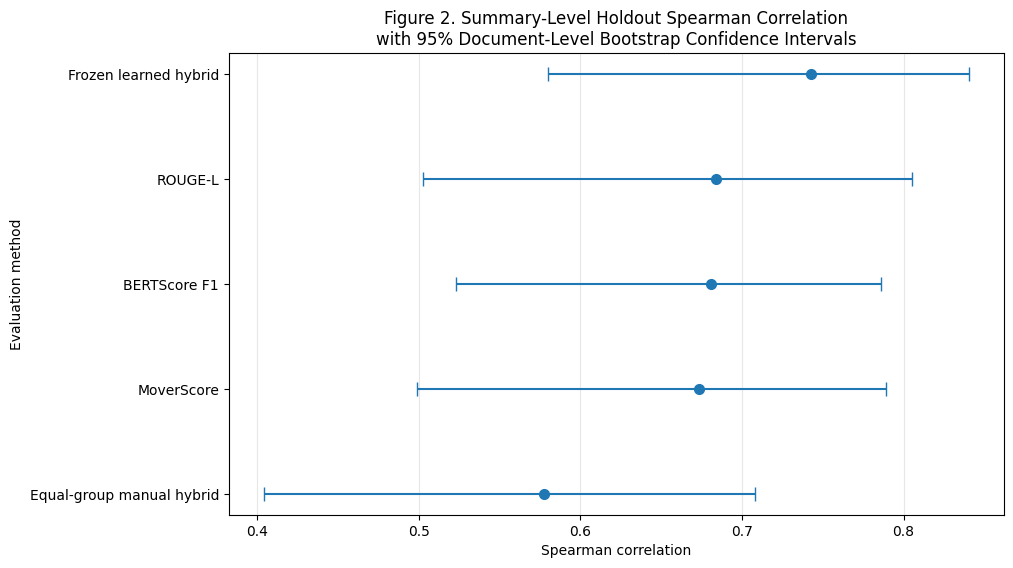

Figure 2 saved:
/Users/sudip/mr604_outputs/figures/final/figure_2_holdout_spearman_confidence_intervals.png


In [320]:
spearman_ci_df = (
    method_ci_df[
        method_ci_df[
            "Metric"
        ] == "Spearman"
    ]
    .sort_values(
        by="Point estimate",
        ascending=True
    )
    .reset_index(drop=True)
)


point_values = (
    spearman_ci_df[
        "Point estimate"
    ].to_numpy()
)

lower_errors = (
    point_values
    - spearman_ci_df[
        "95% CI lower"
    ].to_numpy()
)

upper_errors = (
    spearman_ci_df[
        "95% CI upper"
    ].to_numpy()
    - point_values
)


figure, axis = plt.subplots(
    figsize=(10, 6)
)


axis.errorbar(
    point_values,
    np.arange(
        len(spearman_ci_df)
    ),
    xerr=np.vstack(
        [
            lower_errors,
            upper_errors
        ]
    ),
    fmt="o",
    capsize=5,
    markersize=7
)


axis.set_yticks(
    np.arange(
        len(spearman_ci_df)
    )
)

axis.set_yticklabels(
    spearman_ci_df[
        "Method"
    ]
)

axis.set_xlabel(
    "Spearman correlation"
)

axis.set_ylabel(
    "Evaluation method"
)

axis.set_title(
    "Figure 2. Summary-Level Holdout Spearman Correlation\n"
    "with 95% Document-Level Bootstrap Confidence Intervals"
)

axis.grid(
    axis="x",
    alpha=0.3
)


FIGURE_2_PATH = (
    FINAL_FIGURE_DIR
    / "figure_2_holdout_spearman_confidence_intervals.png"
)


figure.savefig(
    FIGURE_2_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figure)


print("Figure 2 saved:")
print(FIGURE_2_PATH)

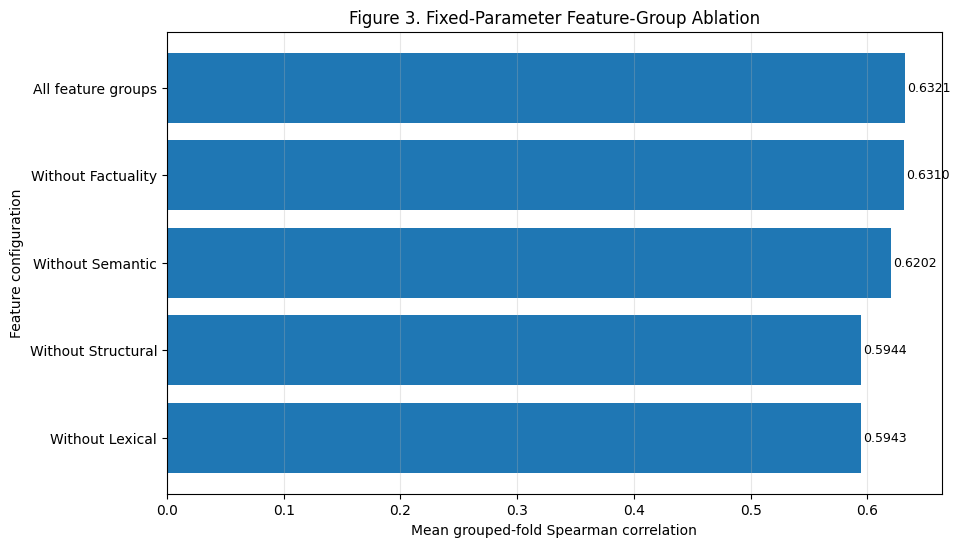

Figure 3 saved:
/Users/sudip/mr604_outputs/figures/final/figure_3_feature_group_ablation.png


In [322]:
ablation_plot_df = (
    fixed_ablation_df
    .sort_values(
        by="Mean fold Spearman",
        ascending=True
    )
    .reset_index(drop=True)
)


figure, axis = plt.subplots(
    figsize=(10, 6)
)


axis.barh(
    ablation_plot_df[
        "Configuration"
    ],
    ablation_plot_df[
        "Mean fold Spearman"
    ]
)


for row_index, row in (
    ablation_plot_df.iterrows()
):

    axis.text(
        row[
            "Mean fold Spearman"
        ] + 0.002,
        row_index,
        f"{row['Mean fold Spearman']:.4f}",
        verticalalignment="center",
        fontsize=9
    )


axis.set_xlabel(
    "Mean grouped-fold Spearman correlation"
)

axis.set_ylabel(
    "Feature configuration"
)

axis.set_title(
    "Figure 3. Fixed-Parameter Feature-Group Ablation"
)

axis.grid(
    axis="x",
    alpha=0.3
)


FIGURE_3_PATH = (
    FINAL_FIGURE_DIR
    / "figure_3_feature_group_ablation.png"
)


figure.savefig(
    FIGURE_3_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figure)


print("Figure 3 saved:")
print(FIGURE_3_PATH)

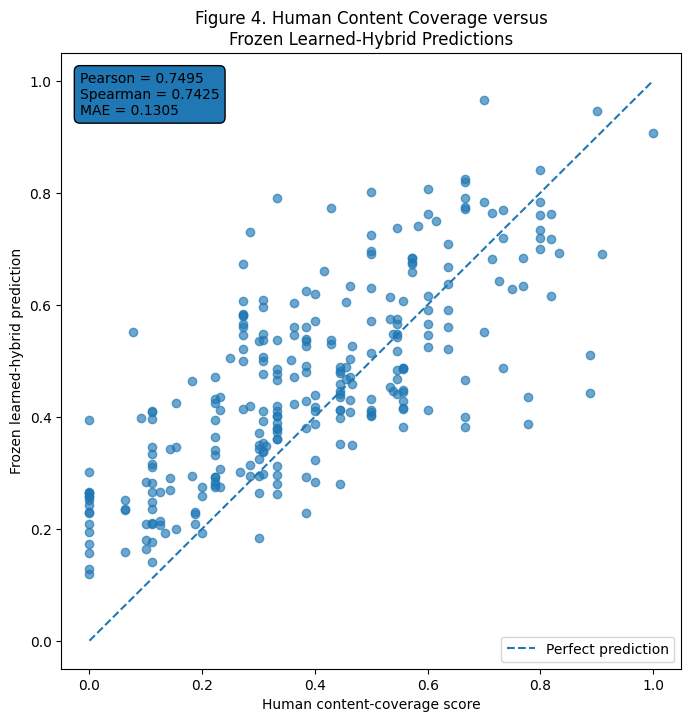

Figure 4 saved:
/Users/sudip/mr604_outputs/figures/final/figure_4_human_vs_learned_predictions.png


In [324]:
human_scores = (
    final_predictions_df[
        TARGET_COLUMN
    ].to_numpy(dtype=float)
)

learned_predictions = (
    final_predictions_df[
        "learned_hybrid_prediction"
    ].to_numpy(dtype=float)
)


minimum_axis_value = min(
    human_scores.min(),
    learned_predictions.min()
)

maximum_axis_value = max(
    human_scores.max(),
    learned_predictions.max()
)


learned_performance_row = (
    final_performance_df[
        final_performance_df[
            "Method"
        ] == "Frozen learned hybrid"
    ]
    .iloc[0]
)


figure, axis = plt.subplots(
    figsize=(8, 8)
)


axis.scatter(
    human_scores,
    learned_predictions,
    alpha=0.65
)


axis.plot(
    [
        minimum_axis_value,
        maximum_axis_value
    ],
    [
        minimum_axis_value,
        maximum_axis_value
    ],
    linestyle="--",
    label="Perfect prediction"
)


axis.set_xlabel(
    "Human content-coverage score"
)

axis.set_ylabel(
    "Frozen learned-hybrid prediction"
)

axis.set_title(
    "Figure 4. Human Content Coverage versus\n"
    "Frozen Learned-Hybrid Predictions"
)

axis.legend()


axis.text(
    0.03,
    0.97,
    (
        f"Pearson = "
        f"{learned_performance_row['Pearson']:.4f}\n"
        f"Spearman = "
        f"{learned_performance_row['Spearman']:.4f}\n"
        f"MAE = "
        f"{learned_performance_row['MAE']:.4f}"
    ),
    transform=axis.transAxes,
    verticalalignment="top",
    bbox={
        "boxstyle": "round,pad=0.4"
    }
)


FIGURE_4_PATH = (
    FINAL_FIGURE_DIR
    / "figure_4_human_vs_learned_predictions.png"
)


figure.savefig(
    FIGURE_4_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figure)


print("Figure 4 saved:")
print(FIGURE_4_PATH)

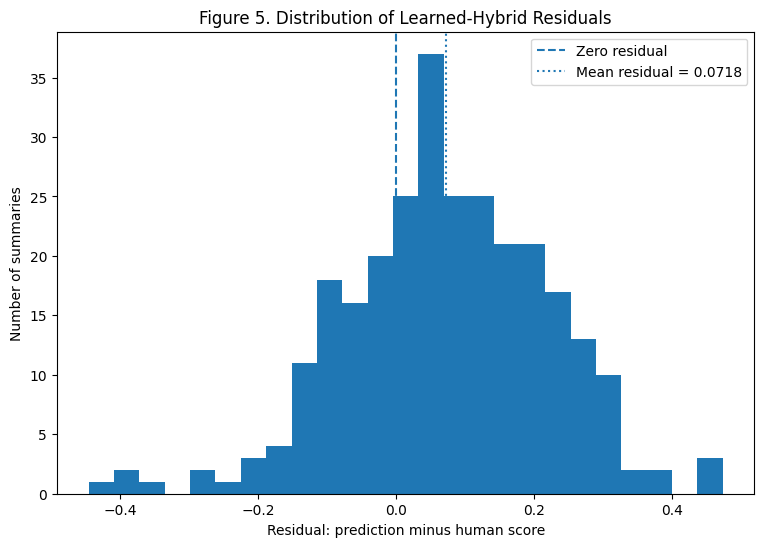

Figure 5 saved:
/Users/sudip/mr604_outputs/figures/final/figure_5_learned_hybrid_residual_distribution.png


In [326]:
learned_residuals = (
    learned_predictions
    - human_scores
)


mean_residual = float(
    np.mean(
        learned_residuals
    )
)


figure, axis = plt.subplots(
    figsize=(9, 6)
)


axis.hist(
    learned_residuals,
    bins=25
)


axis.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="Zero residual"
)


axis.axvline(
    mean_residual,
    linestyle=":",
    linewidth=1.5,
    label=(
        f"Mean residual = "
        f"{mean_residual:.4f}"
    )
)


axis.set_xlabel(
    "Residual: prediction minus human score"
)

axis.set_ylabel(
    "Number of summaries"
)

axis.set_title(
    "Figure 5. Distribution of Learned-Hybrid Residuals"
)

axis.legend()


FIGURE_5_PATH = (
    FINAL_FIGURE_DIR
    / "figure_5_learned_hybrid_residual_distribution.png"
)


figure.savefig(
    FIGURE_5_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figure)


print("Figure 5 saved:")
print(FIGURE_5_PATH)

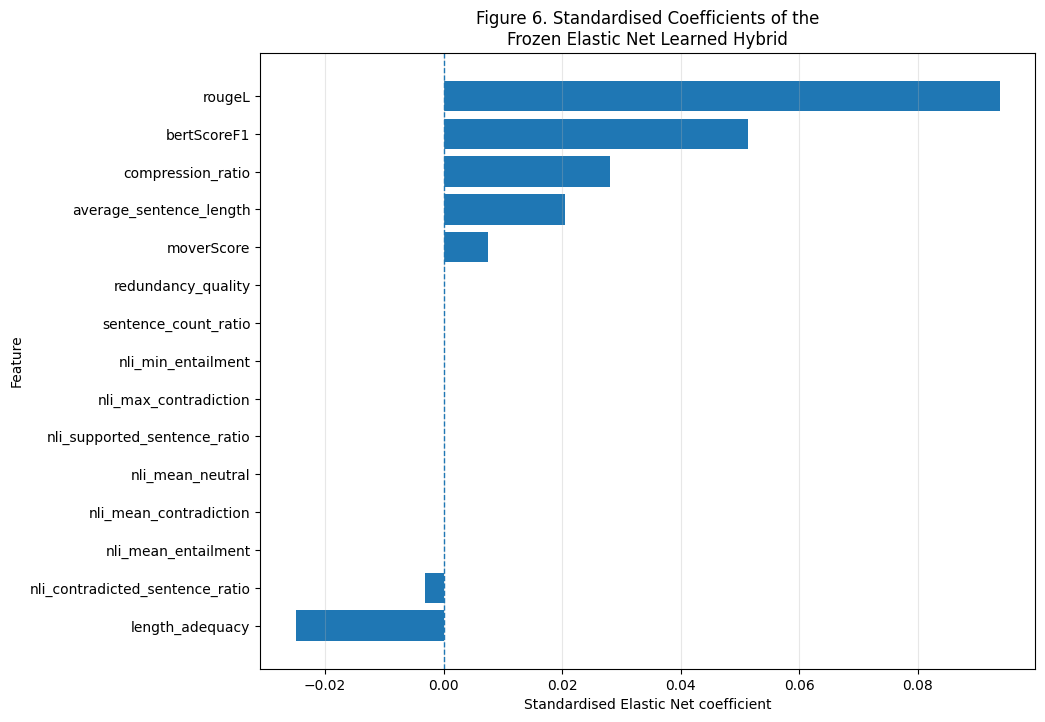

Figure 6 saved:
/Users/sudip/mr604_outputs/figures/final/figure_6_elastic_net_coefficients.png


In [328]:
coefficient_plot_df = (
    coefficient_df
    .sort_values(
        by="Standardised coefficient",
        ascending=True
    )
    .reset_index(drop=True)
)


figure, axis = plt.subplots(
    figsize=(10, 8)
)


axis.barh(
    coefficient_plot_df[
        "Feature"
    ],
    coefficient_plot_df[
        "Standardised coefficient"
    ]
)


axis.axvline(
    0,
    linestyle="--",
    linewidth=1
)


axis.set_xlabel(
    "Standardised Elastic Net coefficient"
)

axis.set_ylabel(
    "Feature"
)

axis.set_title(
    "Figure 6. Standardised Coefficients of the\n"
    "Frozen Elastic Net Learned Hybrid"
)

axis.grid(
    axis="x",
    alpha=0.3
)


FIGURE_6_PATH = (
    FINAL_FIGURE_DIR
    / "figure_6_elastic_net_coefficients.png"
)


figure.savefig(
    FIGURE_6_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figure)


print("Figure 6 saved:")
print(FIGURE_6_PATH)

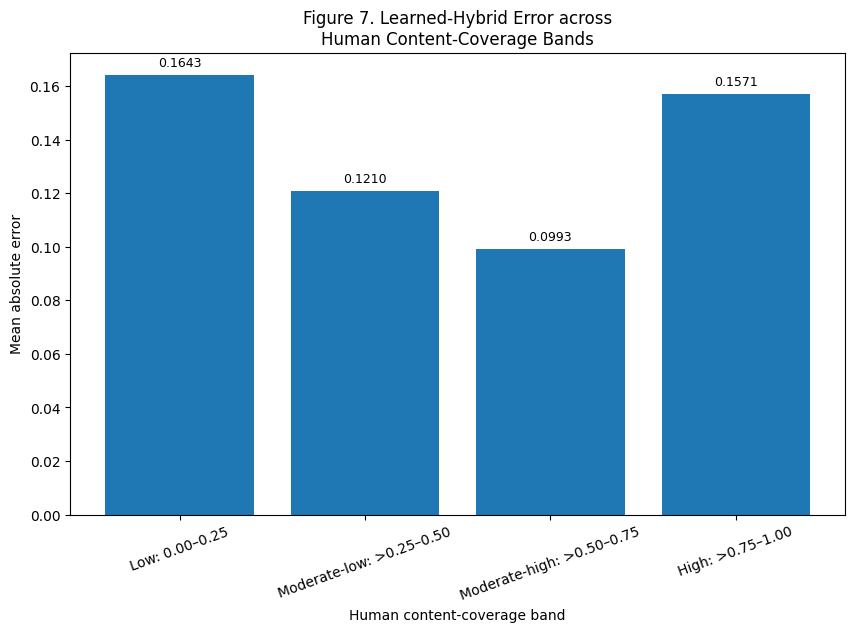

Figure 7 saved:
/Users/sudip/mr604_outputs/figures/final/figure_7_error_by_human_score_band.png


In [330]:
score_band_plot_df = (
    score_band_error_df.copy()
)


figure, axis = plt.subplots(
    figsize=(10, 6)
)


axis.bar(
    score_band_plot_df[
        "Human-score band"
    ],
    score_band_plot_df[
        "MAE"
    ]
)


axis.set_xlabel(
    "Human content-coverage band"
)

axis.set_ylabel(
    "Mean absolute error"
)

axis.set_title(
    "Figure 7. Learned-Hybrid Error across\n"
    "Human Content-Coverage Bands"
)


axis.tick_params(
    axis="x",
    rotation=20
)


for row_index, row in (
    score_band_plot_df.iterrows()
):

    axis.text(
        row_index,
        row["MAE"] + 0.003,
        f"{row['MAE']:.4f}",
        horizontalalignment="center",
        fontsize=9
    )


FIGURE_7_PATH = (
    FINAL_FIGURE_DIR
    / "figure_7_error_by_human_score_band.png"
)


figure.savefig(
    FIGURE_7_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figure)


print("Figure 7 saved:")
print(FIGURE_7_PATH)

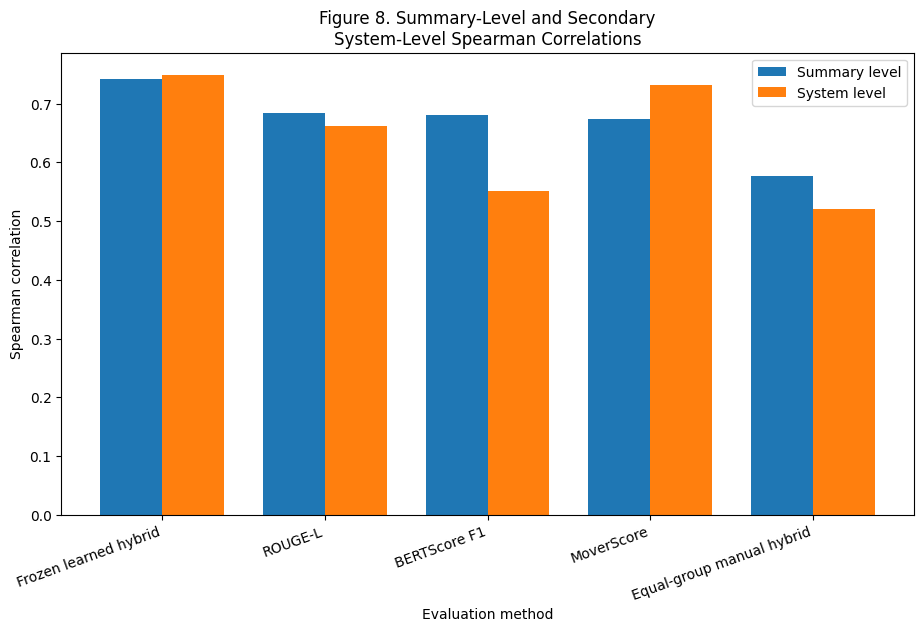

Figure 8 saved:
/Users/sudip/mr604_outputs/figures/final/figure_8_summary_and_system_level_spearman.png


In [332]:
if not system_performance_df.empty:

    summary_spearman_df = (
        final_performance_df[
            [
                "Method",
                "Spearman"
            ]
        ]
        .rename(columns={
            "Spearman": (
                "Summary-level Spearman"
            )
        })
    )


    system_spearman_df = (
        system_performance_df[
            [
                "Method",
                "Spearman"
            ]
        ]
        .rename(columns={
            "Spearman": (
                "System-level Spearman"
            )
        })
    )


    level_comparison_df = (
        summary_spearman_df
        .merge(
            system_spearman_df,
            on="Method",
            how="inner",
            validate="one_to_one"
        )
        .sort_values(
            by="Summary-level Spearman",
            ascending=False
        )
        .reset_index(drop=True)
    )


    x_positions = np.arange(
        len(
            level_comparison_df
        )
    )

    bar_width = 0.38


    figure, axis = plt.subplots(
        figsize=(11, 6)
    )


    axis.bar(
        x_positions
        - bar_width / 2,
        level_comparison_df[
            "Summary-level Spearman"
        ],
        bar_width,
        label="Summary level"
    )


    axis.bar(
        x_positions
        + bar_width / 2,
        level_comparison_df[
            "System-level Spearman"
        ],
        bar_width,
        label="System level"
    )


    axis.set_xticks(
        x_positions
    )

    axis.set_xticklabels(
        level_comparison_df[
            "Method"
        ],
        rotation=20,
        horizontalalignment="right"
    )


    axis.set_ylabel(
        "Spearman correlation"
    )

    axis.set_xlabel(
        "Evaluation method"
    )

    axis.set_title(
        "Figure 8. Summary-Level and Secondary\n"
        "System-Level Spearman Correlations"
    )

    axis.legend()


    FIGURE_8_PATH = (
        FINAL_FIGURE_DIR
        / "figure_8_summary_and_system_level_spearman.png"
    )


    figure.savefig(
        FIGURE_8_PATH,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figure)


    print("Figure 8 saved:")
    print(FIGURE_8_PATH)

else:

    FIGURE_8_PATH = None

    print(
        "System-level performance file was not found. "
        "Figure 8 was not generated."
    )

In [334]:
table_caption_records = [
    {
        "Table number": "Table 1",
        "File": TABLE_1_PATH.name,
        "Title": (
            "REALSumm Dataset and Document-Grouped "
            "Data-Split Summary"
        ),
        "Caption": (
            "Summary statistics for the complete REALSumm "
            "experiment, development partition and locked "
            "post-pilot holdout partition."
        )
    },

    {
        "Table number": "Table 2",
        "File": TABLE_2_PATH.name,
        "Title": (
            "Final Learned-Hybrid Feature Definitions"
        ),
        "Caption": (
            "Definitions and input relationships for the "
            "15 lexical, semantic, factuality and structural "
            "features used by the frozen learned hybrid."
        )
    },

    {
        "Table number": "Table 3",
        "File": TABLE_3_PATH.name,
        "Title": (
            "Grouped Cross-Validation Comparison of "
            "Candidate Regression Models"
        ),
        "Caption": (
            "Development performance of Linear Regression, "
            "Ridge, Lasso, Elastic Net and Random Forest "
            "using document-grouped cross-validation."
        )
    },

    {
        "Table number": "Table 4",
        "File": TABLE_4_PATH.name,
        "Title": (
            "Feature-Group Combination Search"
        ),
        "Caption": (
            "Best Elastic Net configuration for each of the "
            "15 non-empty feature-group combinations."
        )
    },

    {
        "Table number": "Table 5",
        "File": TABLE_5_PATH.name,
        "Title": (
            "Fixed-Parameter Feature-Group Ablation"
        ),
        "Caption": (
            "Change in grouped cross-validation performance "
            "after removing each feature group from the full "
            "15-feature configuration."
        )
    },

    {
        "Table number": "Table 6",
        "File": TABLE_6_PATH.name,
        "Title": (
            "Final Locked Holdout Performance"
        ),
        "Caption": (
            "Summary-level holdout comparison of individual "
            "metrics, the equal-group manual hybrid and the "
            "frozen learned hybrid."
        )
    },

    {
        "Table number": "Table 7",
        "File": TABLE_7_PATH.name,
        "Title": (
            "Document-Level Bootstrap Inference"
        ),
        "Caption": (
            "Bootstrap confidence intervals for the learned "
            "hybrid and paired differences against the "
            "strongest summary-level baseline."
        )
    },

    {
        "Table number": "Table 8",
        "File": TABLE_8_PATH.name,
        "Title": (
            "Final Learned-Hybrid Error Analysis"
        ),
        "Caption": (
            "Residual behaviour, error thresholds and "
            "summary-level wins against ROUGE-L and "
            "MoverScore."
        )
    }
]


figure_caption_records = [
    {
        "Figure number": "Figure 1",
        "File": FIGURE_1_PATH.name,
        "Title": (
            "Research Implementation Framework"
        ),
        "Caption": (
            "Complete implementation pipeline from REALSumm "
            "data preparation and feature extraction through "
            "model selection and final evaluation."
        )
    },

    {
        "Figure number": "Figure 2",
        "File": FIGURE_2_PATH.name,
        "Title": (
            "Holdout Spearman Confidence Intervals"
        ),
        "Caption": (
            "Summary-level Spearman point estimates and "
            "95% document-level bootstrap confidence "
            "intervals for all final methods."
        )
    },

    {
        "Figure number": "Figure 3",
        "File": FIGURE_3_PATH.name,
        "Title": (
            "Feature-Group Ablation"
        ),
        "Caption": (
            "Mean grouped-fold Spearman correlation for the "
            "full learned hybrid and each leave-one-group-out "
            "configuration."
        )
    },

    {
        "Figure number": "Figure 4",
        "File": FIGURE_4_PATH.name,
        "Title": (
            "Human Scores versus Learned Predictions"
        ),
        "Caption": (
            "Relationship between human content-coverage "
            "scores and frozen learned-hybrid predictions "
            "for 280 holdout summaries."
        )
    },

    {
        "Figure number": "Figure 5",
        "File": FIGURE_5_PATH.name,
        "Title": (
            "Learned-Hybrid Residual Distribution"
        ),
        "Caption": (
            "Distribution of prediction-minus-human-score "
            "residuals, showing the model's overall "
            "overprediction tendency."
        )
    },

    {
        "Figure number": "Figure 6",
        "File": FIGURE_6_PATH.name,
        "Title": (
            "Frozen Elastic Net Coefficients"
        ),
        "Caption": (
            "Standardised coefficients retained by the "
            "frozen Elastic Net learned hybrid."
        )
    },

    {
        "Figure number": "Figure 7",
        "File": FIGURE_7_PATH.name,
        "Title": (
            "Error by Human Content-Coverage Band"
        ),
        "Caption": (
            "Mean absolute error of the learned hybrid across "
            "four human content-coverage score bands."
        )
    }
]


if FIGURE_8_PATH is not None:

    figure_caption_records.append({
        "Figure number": "Figure 8",
        "File": FIGURE_8_PATH.name,
        "Title": (
            "Summary-Level and System-Level Spearman"
        ),
        "Caption": (
            "Comparison of primary summary-level and "
            "secondary system-level Spearman correlations "
            "for all evaluation methods."
        )
    })


table_caption_manifest = pd.DataFrame(
    table_caption_records
)

figure_caption_manifest = pd.DataFrame(
    figure_caption_records
)


TABLE_MANIFEST_PATH = (
    FINAL_TABLE_DIR
    / "final_table_caption_manifest.csv"
)

FIGURE_MANIFEST_PATH = (
    FINAL_FIGURE_DIR
    / "final_figure_caption_manifest.csv"
)


table_caption_manifest.to_csv(
    TABLE_MANIFEST_PATH,
    index=False
)

figure_caption_manifest.to_csv(
    FIGURE_MANIFEST_PATH,
    index=False
)


print("Final table caption manifest:")

display(
    table_caption_manifest
)


print("\nFinal figure caption manifest:")

display(
    figure_caption_manifest
)

Final table caption manifest:


,Table number,File,Title,Caption
0,Table 1,table_1_dataset_and_split_summary.csv,REALSumm Dataset and Document-Grouped Data-Split Summary,"Summary statistics for the complete REALSumm experiment, development partition and locked post-pilot holdout partition."
1,Table 2,table_2_final_feature_definitions.csv,Final Learned-Hybrid Feature Definitions,"Definitions and input relationships for the 15 lexical, semantic, factuality and structural features used by the frozen learned hybrid."
2,Table 3,table_3_candidate_model_comparison.csv,Grouped Cross-Validation Comparison of Candidate Regression Models,"Development performance of Linear Regression, Ridge, Lasso, Elastic Net and Random Forest using document-grouped cross-validation."
3,Table 4,table_4_feature_group_combinations.csv,Feature-Group Combination Search,Best Elastic Net configuration for each of the 15 non-empty feature-group combinations.
4,Table 5,table_5_fixed_parameter_ablation.csv,Fixed-Parameter Feature-Group Ablation,Change in grouped cross-validation performance after removing each feature group from the full 15-feature configuration.
5,Table 6,table_6_final_holdout_performance.csv,Final Locked Holdout Performance,"Summary-level holdout comparison of individual metrics, the equal-group manual hybrid and the frozen learned hybrid."
6,Table 7,table_7_bootstrap_inference.csv,Document-Level Bootstrap Inference,Bootstrap confidence intervals for the learned hybrid and paired differences against the strongest summary-level baseline.
7,Table 8,table_8_error_analysis_summary.csv,Final Learned-Hybrid Error Analysis,"Residual behaviour, error thresholds and summary-level wins against ROUGE-L and MoverScore."



Final figure caption manifest:


,Figure number,File,Title,Caption
0,Figure 1,figure_1_research_implementation_framework.png,Research Implementation Framework,Complete implementation pipeline from REALSumm data preparation and feature extraction through model selection and final evaluation.
1,Figure 2,figure_2_holdout_spearman_confidence_intervals.png,Holdout Spearman Confidence Intervals,Summary-level Spearman point estimates and 95% document-level bootstrap confidence intervals for all final methods.
2,Figure 3,figure_3_feature_group_ablation.png,Feature-Group Ablation,Mean grouped-fold Spearman correlation for the full learned hybrid and each leave-one-group-out configuration.
3,Figure 4,figure_4_human_vs_learned_predictions.png,Human Scores versus Learned Predictions,Relationship between human content-coverage scores and frozen learned-hybrid predictions for 280 holdout summaries.
4,Figure 5,figure_5_learned_hybrid_residual_distribution.png,Learned-Hybrid Residual Distribution,"Distribution of prediction-minus-human-score residuals, showing the model's overall overprediction tendency."
5,Figure 6,figure_6_elastic_net_coefficients.png,Frozen Elastic Net Coefficients,Standardised coefficients retained by the frozen Elastic Net learned hybrid.
6,Figure 7,figure_7_error_by_human_score_band.png,Error by Human Content-Coverage Band,Mean absolute error of the learned hybrid across four human content-coverage score bands.
7,Figure 8,figure_8_summary_and_system_level_spearman.png,Summary-Level and System-Level Spearman,Comparison of primary summary-level and secondary system-level Spearman correlations for all evaluation methods.


In [336]:
generated_table_paths = [
    TABLE_1_PATH,
    TABLE_2_PATH,
    TABLE_3_PATH,
    TABLE_4_PATH,
    TABLE_5_PATH,
    TABLE_6_PATH,
    TABLE_7_PATH,
    TABLE_8_PATH,
    TABLE_MANIFEST_PATH
]


generated_figure_paths = [
    FIGURE_1_PATH,
    FIGURE_2_PATH,
    FIGURE_3_PATH,
    FIGURE_4_PATH,
    FIGURE_5_PATH,
    FIGURE_6_PATH,
    FIGURE_7_PATH,
    FIGURE_MANIFEST_PATH
]


if FIGURE_8_PATH is not None:

    generated_figure_paths.append(
        FIGURE_8_PATH
    )


missing_final_outputs = [
    str(output_path)

    for output_path in (
        generated_table_paths
        + generated_figure_paths
    )

    if not output_path.exists()
]


if missing_final_outputs:

    raise FileNotFoundError(
        "Some Phase 14 outputs were not created: "
        f"{missing_final_outputs}"
    )


phase_14_summary = pd.DataFrame({
    "Item": [
        "Experimental implementation complete",
        "Additional model training performed",
        "Final thesis tables created",
        "Final thesis figures created",
        "Table caption manifest created",
        "Figure caption manifest created",
        "Final table folder",
        "Final figure folder",
        "Next major task"
    ],

    "Value": [
        "Yes",
        "No",
        8,
        len(
            figure_caption_manifest
        ),
        "Yes",
        "Yes",
        str(
            FINAL_TABLE_DIR
        ),
        str(
            FINAL_FIGURE_DIR
        ),
        (
            "Write the Methodology and Results chapters "
            "using the frozen outputs"
        )
    ]
})


PHASE_14_SUMMARY_PATH = (
    RESULT_DIR
    / "phase_14_completion_summary.csv"
)


phase_14_summary.to_csv(
    PHASE_14_SUMMARY_PATH,
    index=False
)


display(
    phase_14_summary
)

print(
    "PHASE 14 COMPLETED SUCCESSFULLY"
)

print(
    "\nTHE EXPERIMENTAL IMPLEMENTATION "
    "IS NOW 100% COMPLETE."
)

,Item,Value
0,Experimental implementation complete,Yes
1,Additional model training performed,No
2,Final thesis tables created,8
3,Final thesis figures created,8
4,Table caption manifest created,Yes
5,Figure caption manifest created,Yes
6,Final table folder,/Users/sudip/mr604_outputs/final_tables
7,Final figure folder,/Users/sudip/mr604_outputs/figures/final
8,Next major task,Write the Methodology and Results chapters using the frozen outputs


PHASE 14 COMPLETED SUCCESSFULLY

THE EXPERIMENTAL IMPLEMENTATION IS NOW 100% COMPLETE.


## 16. Development-Only Feature-Family Ablation

This section evaluates the contribution of the lexical, semantic, NLI-derived factuality, and structural feature families using the original 80-document development partition.

The analysis uses the original five document-grouped cross-validation folds and the frozen Elastic Net configuration selected during development. Each feature family is removed in turn while all model hyperparameters remain fixed. The locked holdout partition is not used.

In [12]:
# Load and validate development-only ablation inputs

import os
import json
import numpy as np
import pandas as pd

BASE = "/Users/sudip/mr604_outputs"

FEATURE_FILE = os.path.join(
    BASE,
    "features",
    "realsumm_development_complete_features.csv"
)

FOLD_FILE = os.path.join(
    BASE,
    "splits",
    "phase_5_grouped_cv_fold_manifest.csv"
)

HISTORIC_ABLATION_FILE = os.path.join(
    BASE,
    "results",
    "phase_8_fixed_parameter_ablation.csv"
)

CONFIG_FILE = os.path.join(
    BASE,
    "results",
    "phase_8_frozen_model_configuration.json"
)


print("=" * 105)
print("REALSumm ABLATION — RECOVERY STEP 3")
print("=" * 105)


# ============================================================
# 1. Load development features
# ============================================================

development_feature_df = pd.read_csv(
    FEATURE_FILE
)

print("\nA. DEVELOPMENT COMPLETE FEATURES")
print("-" * 105)

print(
    "Shape:",
    development_feature_df.shape
)

print(
    "Unique documents:",
    development_feature_df[
        "doc_id"
    ].nunique()
)

print(
    "Unique systems:",
    development_feature_df[
        "model"
    ].nunique()
)

print(
    "\nColumns:"
)

for i, col in enumerate(
    development_feature_df.columns,
    start=1
):
    print(
        f"{i:02d}. {col}"
    )


# ============================================================
# 2. Load exact original CV fold manifest
# ============================================================

fold_manifest = pd.read_csv(
    FOLD_FILE
)

print("\n" + "=" * 105)
print("B. ORIGINAL GROUPED CV FOLD MANIFEST")
print("=" * 105)

print(
    "Shape:",
    fold_manifest.shape
)

print(
    "Columns:",
    fold_manifest.columns.tolist()
)

display(
    fold_manifest.head(20)
)


if "cv_fold" in fold_manifest.columns:

    print(
        "\nDocuments per fold:"
    )

    display(
        fold_manifest[
            "cv_fold"
        ]
        .value_counts()
        .sort_index()
    )


# ============================================================
# 3. Load historic fixed ablation
# ============================================================

fixed_ablation_table = pd.read_csv(
    HISTORIC_ABLATION_FILE
)

print("\n" + "=" * 105)
print("C. HISTORIC FIXED ABLATION")
print("=" * 105)

print(
    "Shape:",
    fixed_ablation_table.shape
)

display(
    fixed_ablation_table
)


# ============================================================
# 4. Load frozen model configuration
# ============================================================

with open(
    CONFIG_FILE,
    "r"
) as f:

    frozen_model_config = json.load(
        f
    )


print("\n" + "=" * 105)
print("D. FROZEN MODEL CONFIGURATION")
print("=" * 105)

print(
    json.dumps(
        frozen_model_config,
        indent=2
    )
)


# ============================================================
# 5. Verify expected 15 modelling features
# ============================================================

REALSUMM_FEATURES = [

    # Lexical
    "rougeL",

    # Semantic
    "bertScoreF1",
    "moverScore",

    # Factuality / NLI
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment",

    # Structural
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]


missing_features = [

    feature
    for feature in REALSUMM_FEATURES

    if feature not in
    development_feature_df.columns
]


print("\n" + "=" * 105)
print("E. FEATURE INVENTORY CHECK")
print("=" * 105)

print(
    "Expected modelling features:",
    len(
        REALSUMM_FEATURES
    )
)

print(
    "Missing features:",
    missing_features
)


# ============================================================
# 6. Missing / non-finite check
# ============================================================

X_check = (
    development_feature_df[
        REALSUMM_FEATURES
    ]
    .astype(float)
)


print(
    "\nMissing feature values:",
    int(
        X_check
        .isna()
        .sum()
        .sum()
    )
)

print(
    "Non-finite feature values:",
    int(
        (
            ~np.isfinite(
                X_check.to_numpy()
            )
        )
        .sum()
    )
)


print(
    "Missing human targets:",
    int(
        development_feature_df[
            "human_content_coverage"
        ]
        .isna()
        .sum()
    )
)


# ============================================================
# 7. Development/fold identity verification
# ============================================================

development_docs = set(
    development_feature_df[
        "doc_id"
    ].unique()
)

manifest_docs = set(
    fold_manifest[
        "doc_id"
    ].unique()
)


print("\n" + "=" * 105)
print("F. DEVELOPMENT / FOLD IDENTITY CHECK")
print("=" * 105)

print(
    "Development documents:",
    len(
        development_docs
    )
)

print(
    "Manifest documents:",
    len(
        manifest_docs
    )
)

print(
    "Development docs missing from manifest:",
    len(
        development_docs
        - manifest_docs
    )
)

print(
    "Manifest docs missing from development:",
    len(
        manifest_docs
        - development_docs
    )
)


# ============================================================
# 8. Assertions
# ============================================================

assert development_feature_df.shape[0] == 1120

assert (
    development_feature_df[
        "doc_id"
    ].nunique()
    == 80
)

assert (
    development_feature_df[
        "model"
    ].nunique()
    == 14
)

assert len(
    fold_manifest
) == 80

assert len(
    missing_features
) == 0

assert (
    X_check
    .isna()
    .sum()
    .sum()
    == 0
)

assert np.isfinite(
    X_check.to_numpy()
).all()

assert (
    development_docs
    == manifest_docs
)


print("\n" + "=" * 105)
print("✅ RECOVERY STEP 3 PASSED")
print(
    "Development features, exact document folds, "
    "historic ablation results and frozen configuration "
    "were recovered successfully."
)
print(
    "The locked REALSumm holdout was not loaded."
)
print("=" * 105)

REALSumm ABLATION — RECOVERY STEP 3

A. DEVELOPMENT COMPLETE FEATURES
---------------------------------------------------------------------------------------------------------
Shape: (1120, 32)
Unique documents: 80
Unique systems: 14

Columns:
01. summary_id
02. doc_id
03. model
04. source
05. reference_summary
06. candidate_summary
07. rougeL
08. bertScoreF1
09. moverScore
10. human_content_coverage
11. source_clean
12. reference_clean
13. candidate_clean
14. source_word_count
15. reference_word_count
16. candidate_word_count
17. reference_sentence_count
18. candidate_sentence_count
19. repeated_bigram_rate
20. length_adequacy
21. sentence_count_ratio
22. redundancy_quality
23. compression_ratio
24. average_sentence_length
25. nli_mean_entailment
26. nli_mean_neutral
27. nli_mean_contradiction
28. nli_max_contradiction
29. nli_min_entailment
30. nli_sentence_count
31. nli_supported_sentence_ratio
32. nli_contradicted_sentence_ratio

B. ORIGINAL GROUPED CV FOLD MANIFEST
Shape: (80, 2)


,doc_id,cv_fold
0,7,1
1,9,1
2,24,1
3,35,1
4,40,1
5,41,1
6,43,1
7,53,1
8,66,1
9,69,1



Documents per fold:


cv_fold
1    16
2    16
3    16
4    16
5    16
Name: count, dtype: int64


C. HISTORIC FIXED ABLATION
Shape: (5, 20)


,Configuration,Included groups,Feature count,Mean fold Pearson,SD fold Pearson,Mean fold Spearman,SD fold Spearman,Mean fold Kendall,SD fold Kendall,Mean fold MAE,SD fold MAE,Mean fold RMSE,SD fold RMSE,Pooled OOF Pearson,Pooled OOF Spearman,Pooled OOF Kendall,Pooled OOF MAE,Pooled OOF RMSE,Spearman change vs all,MAE change vs all
0,All feature groups,Lexical + Semantic + Factuality + Structural,15,0.647300,0.054045,0.632133,0.060447,0.465959,0.056714,0.146310,0.004841,0.183636,0.010931,0.639769,0.627515,0.456710,0.146310,0.183896,0.000000,0.000000
1,Without Factuality,Lexical + Semantic + Structural,8,0.647127,0.054467,0.630990,0.061088,0.465112,0.057605,0.146231,0.004704,0.183589,0.010771,0.640068,0.627239,0.456619,0.146231,0.183841,-0.001144,-0.000079
2,Without Semantic,Lexical + Factuality + Structural,13,0.633989,0.054136,0.620211,0.056603,0.453554,0.050958,0.148952,0.007251,0.186183,0.012238,0.626527,0.613984,0.443994,0.148952,0.186505,-0.011922,0.002642
3,Without Structural,Lexical + Semantic + Factuality,10,0.610599,0.058814,0.594355,0.062259,0.433552,0.056285,0.151875,0.007064,0.190140,0.011487,0.605510,0.592115,0.427195,0.151875,0.190418,-0.037778,0.005564
4,Without Lexical,Semantic + Factuality + Structural,14,0.613800,0.061708,0.594312,0.068510,0.435048,0.061559,0.151235,0.005367,0.190749,0.011301,0.602083,0.585666,0.423196,0.151235,0.191017,-0.037822,0.004925



D. FROZEN MODEL CONFIGURATION
{
  "model_family": "Elastic Net",
  "selected_feature_groups": [
    "lexical",
    "semantic",
    "factuality",
    "structural"
  ],
  "selected_feature_columns": [
    "rougeL",
    "bertScoreF1",
    "moverScore",
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment",
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
  ],
  "selected_parameters": {
    "model__alpha": 0.01,
    "model__l1_ratio": 0.5
  },
  "selection_criterion": "Highest mean fold Spearman; mean fold MAE used as tie-breaker",
  "development_rows": 1120,
  "development_documents": 80,
  "grouped_cv_folds": 5,
  "mean_fold_spearman": 0.632133337526626,
  "pooled_oof_spearman": 0.6275148927871669,
  "pooled_oof_pearson": 0.6397685457457511,
  "pooled_

### Fixed Leave-One-Feature-Family-Out Ablation

The fixed Learned Hybrid configuration is evaluated on the development partition using the original five document-grouped cross-validation folds. Each feature family is removed in turn while the model configuration remains unchanged.

In [10]:
# ============================================================
# REALSumm ABLATION — STEP 4
# Reconstruct the ORIGINAL fixed ablation OOF predictions
#
# Development only:
#   1120 summaries
#   80 documents
#   14 systems
#
# Fixed:
#   StandardScaler
#   ElasticNet(alpha=0.01, l1_ratio=0.5)
#   Same original 5 document folds
#
# NO HOLDOUT USED
# NO RETUNING
# NO CLIPPING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error

from scipy.stats import pearsonr, spearmanr, kendalltau


print("=" * 110)
print("REALSumm ABLATION — STEP 4")
print("RECONSTRUCTING ORIGINAL FIXED OOF ABLATION")
print("=" * 110)


# ============================================================
# 1. Exact feature groups
# ============================================================

FEATURE_GROUPS = {

    "lexical": [
        "rougeL"
    ],

    "semantic": [
        "bertScoreF1",
        "moverScore"
    ],

    "factuality": [
        "nli_mean_entailment",
        "nli_mean_contradiction",
        "nli_mean_neutral",
        "nli_supported_sentence_ratio",
        "nli_contradicted_sentence_ratio",
        "nli_max_contradiction",
        "nli_min_entailment"
    ],

    "structural": [
        "length_adequacy",
        "sentence_count_ratio",
        "redundancy_quality",
        "compression_ratio",
        "average_sentence_length"
    ]
}


# ============================================================
# 2. Exact historic fixed-ablation configurations
# ============================================================

ABLATION_CONFIGS = {

    "All feature groups":
        FEATURE_GROUPS["lexical"]
        + FEATURE_GROUPS["semantic"]
        + FEATURE_GROUPS["factuality"]
        + FEATURE_GROUPS["structural"],

    "Without Factuality":
        FEATURE_GROUPS["lexical"]
        + FEATURE_GROUPS["semantic"]
        + FEATURE_GROUPS["structural"],

    "Without Semantic":
        FEATURE_GROUPS["lexical"]
        + FEATURE_GROUPS["factuality"]
        + FEATURE_GROUPS["structural"],

    "Without Structural":
        FEATURE_GROUPS["lexical"]
        + FEATURE_GROUPS["semantic"]
        + FEATURE_GROUPS["factuality"],

    "Without Lexical":
        FEATURE_GROUPS["semantic"]
        + FEATURE_GROUPS["factuality"]
        + FEATURE_GROUPS["structural"]
}


for name, features in ABLATION_CONFIGS.items():
    print(
        f"{name:25s}: "
        f"{len(features):2d} features"
    )


# ============================================================
# 3. Attach exact original fold assignments
# ============================================================

dev_ablation_df = (
    development_feature_df
    .copy()
)


fold_map = dict(
    zip(
        fold_manifest["doc_id"],
        fold_manifest["cv_fold"]
    )
)


dev_ablation_df["cv_fold"] = (
    dev_ablation_df["doc_id"]
    .map(fold_map)
)


assert dev_ablation_df["cv_fold"].notna().all()
assert len(dev_ablation_df) == 1120
assert dev_ablation_df["doc_id"].nunique() == 80


print("\nDocuments per fold:")

display(
    dev_ablation_df[
        ["doc_id", "cv_fold"]
    ]
    .drop_duplicates()
    ["cv_fold"]
    .value_counts()
    .sort_index()
)


print("\nSummaries per fold:")

display(
    dev_ablation_df[
        "cv_fold"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# 4. Fixed model constructor
# ============================================================

def make_realsumm_fixed_model():

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            ElasticNet(
                alpha=0.01,
                l1_ratio=0.5,
                max_iter=50000,
                tol=1e-5,
                random_state=20260723
            )
        )
    ])


# ============================================================
# 5. Metric helper
# ============================================================

def evaluate_predictions(y_true, y_pred):

    return {

        "Pearson":
            pearsonr(
                y_true,
                y_pred
            ).statistic,

        "Spearman":
            spearmanr(
                y_true,
                y_pred
            ).statistic,

        "Kendall":
            kendalltau(
                y_true,
                y_pred
            ).statistic,

        "MAE":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
    }


# ============================================================
# 6. Base OOF table
# ============================================================

TARGET = "human_content_coverage"


realsumm_ablation_oof_df = (
    dev_ablation_df[
        [
            "summary_id",
            "doc_id",
            "model",
            "cv_fold",
            TARGET
        ]
    ]
    .copy()
)


fold_results = []


# ============================================================
# 7. Fit five fixed configurations
# ============================================================

for config_name, features in ABLATION_CONFIGS.items():

    print(
        "\n" + "-" * 110
    )

    print(
        f"{config_name} | "
        f"{len(features)} features"
    )


    prediction_col = (
        config_name
        .lower()
        .replace(" ", "_")
        + "_oof"
    )


    predictions = np.full(
        len(dev_ablation_df),
        np.nan
    )


    for fold in [1, 2, 3, 4, 5]:

        train_mask = (
            dev_ablation_df[
                "cv_fold"
            ] != fold
        )

        validation_mask = (
            dev_ablation_df[
                "cv_fold"
            ] == fold
        )


        train_df = (
            dev_ablation_df
            .loc[train_mask]
        )

        validation_df = (
            dev_ablation_df
            .loc[validation_mask]
        )


        # ----------------------------------------
        # Document leakage checks
        # ----------------------------------------

        train_docs = set(
            train_df["doc_id"]
        )

        validation_docs = set(
            validation_df["doc_id"]
        )


        assert train_docs.isdisjoint(
            validation_docs
        )

        assert len(train_docs) == 64
        assert len(validation_docs) == 16

        assert len(train_df) == 896
        assert len(validation_df) == 224


        # ----------------------------------------
        # Data
        # ----------------------------------------

        X_train = (
            train_df[
                features
            ]
            .astype(float)
        )

        X_validation = (
            validation_df[
                features
            ]
            .astype(float)
        )

        y_train = (
            train_df[
                TARGET
            ]
            .astype(float)
            .to_numpy()
        )

        y_validation = (
            validation_df[
                TARGET
            ]
            .astype(float)
            .to_numpy()
        )


        # ----------------------------------------
        # Fit within fold
        # ----------------------------------------

        pipeline = (
            make_realsumm_fixed_model()
        )

        pipeline.fit(
            X_train,
            y_train
        )


        # IMPORTANT:
        # preserve original un-clipped predictions
        fold_predictions = (
            pipeline.predict(
                X_validation
            )
        )


        predictions[
            validation_mask.to_numpy()
        ] = fold_predictions


        fold_metrics = (
            evaluate_predictions(
                y_validation,
                fold_predictions
            )
        )


        fold_results.append({

            "Configuration":
                config_name,

            "Validation_fold":
                fold,

            "Feature_count":
                len(features),

            "Training_documents":
                64,

            "Validation_documents":
                16,

            "Validation_summaries":
                224,

            **fold_metrics
        })


    assert np.isfinite(
        predictions
    ).all()


    realsumm_ablation_oof_df[
        prediction_col
    ] = predictions


    print(
        f"Prediction range: "
        f"{predictions.min():.6f} "
        f"to "
        f"{predictions.max():.6f}"
    )


# ============================================================
# 8. Fold table
# ============================================================

realsumm_ablation_fold_results_df = (
    pd.DataFrame(
        fold_results
    )
)


assert len(
    realsumm_ablation_fold_results_df
) == 25


# ============================================================
# 9. Pooled OOF performance
# ============================================================

pooled_rows = []


for config_name, features in ABLATION_CONFIGS.items():

    prediction_col = (
        config_name
        .lower()
        .replace(" ", "_")
        + "_oof"
    )


    y_true = (
        realsumm_ablation_oof_df[
            TARGET
        ]
        .to_numpy()
    )

    y_pred = (
        realsumm_ablation_oof_df[
            prediction_col
        ]
        .to_numpy()
    )


    metrics = (
        evaluate_predictions(
            y_true,
            y_pred
        )
    )


    pooled_rows.append({

        "Configuration":
            config_name,

        "Feature_count":
            len(features),

        **metrics
    })


realsumm_ablation_reproduced_df = (
    pd.DataFrame(
        pooled_rows
    )
)


print(
    "\n" + "=" * 110
)

print(
    "REPRODUCED REALSumm FIXED ABLATION"
)

print(
    "=" * 110
)


display(
    realsumm_ablation_reproduced_df
    .round(6)
)


# ============================================================
# 10. Compare against saved historic results
# ============================================================

historic = (
    fixed_ablation_table[
        [
            "Configuration",
            "Pooled OOF Pearson",
            "Pooled OOF Spearman",
            "Pooled OOF Kendall",
            "Pooled OOF MAE",
            "Pooled OOF RMSE"
        ]
    ]
    .copy()
)


historic = historic.rename(
    columns={

        "Pooled OOF Pearson":
            "Historic_Pearson",

        "Pooled OOF Spearman":
            "Historic_Spearman",

        "Pooled OOF Kendall":
            "Historic_Kendall",

        "Pooled OOF MAE":
            "Historic_MAE",

        "Pooled OOF RMSE":
            "Historic_RMSE"
    }
)


reproduction_check_df = (
    realsumm_ablation_reproduced_df
    .merge(
        historic,
        on="Configuration",
        how="left"
    )
)


for metric in [
    "Pearson",
    "Spearman",
    "Kendall",
    "MAE",
    "RMSE"
]:

    reproduction_check_df[
        f"{metric}_Difference"
    ] = (

        reproduction_check_df[
            metric
        ]

        -

        reproduction_check_df[
            f"Historic_{metric}"
        ]
    )


print(
    "\n" + "=" * 125
)

print(
    "REPRODUCTION CHECK"
)

print(
    "=" * 125
)


display(
    reproduction_check_df[
        [
            "Configuration",

            "Pearson",
            "Historic_Pearson",
            "Pearson_Difference",

            "Spearman",
            "Historic_Spearman",
            "Spearman_Difference",

            "Kendall",
            "Historic_Kendall",
            "Kendall_Difference",

            "MAE",
            "Historic_MAE",
            "MAE_Difference",

            "RMSE",
            "Historic_RMSE",
            "RMSE_Difference"
        ]
    ]
    .round(10)
)


# ============================================================
# 11. Maximum reproduction error
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "MAXIMUM ABSOLUTE DIFFERENCE"
)

print(
    "=" * 110
)


max_differences = {}


for metric in [
    "Pearson",
    "Spearman",
    "Kendall",
    "MAE",
    "RMSE"
]:

    value = float(

        reproduction_check_df[
            f"{metric}_Difference"
        ]
        .abs()
        .max()
    )

    max_differences[
        metric
    ] = value


    print(
        f"{metric:10s}: "
        f"{value:.12f}"
    )


# ============================================================
# 12. Strict reproduction assertion
# ============================================================

for metric, value in max_differences.items():

    assert value < 1e-8, (
        f"{metric} did not reproduce "
        f"the historic ablation closely enough."
    )


# ============================================================
# 13. Integrity check
# ============================================================

prediction_columns = [

    col
    for col in
    realsumm_ablation_oof_df.columns

    if col.endswith(
        "_oof"
    )
]


print(
    "\nOOF prediction columns:"
)

for col in prediction_columns:
    print(
        " -",
        col
    )


print(
    "\nMissing predictions:",
    int(
        realsumm_ablation_oof_df[
            prediction_columns
        ]
        .isna()
        .sum()
        .sum()
    )
)


# ============================================================
# 14. Save
# ============================================================

realsumm_ablation_oof_df.to_parquet(
    "REALSUMM_ABLATION_FIXED_OOF_PREDICTIONS.parquet",
    index=False
)

realsumm_ablation_oof_df.to_csv(
    "REALSUMM_ABLATION_FIXED_OOF_PREDICTIONS.csv",
    index=False
)

realsumm_ablation_fold_results_df.to_csv(
    "REALSUMM_ABLATION_FIXED_FOLD_RESULTS.csv",
    index=False
)

realsumm_ablation_reproduced_df.to_csv(
    "REALSUMM_ABLATION_REPRODUCED_RESULTS.csv",
    index=False
)

reproduction_check_df.to_csv(
    "REALSUMM_ABLATION_REPRODUCTION_CHECK.csv",
    index=False
)


print("\nSaved:")
print(
    "REALSUMM_ABLATION_FIXED_OOF_PREDICTIONS.parquet"
)
print(
    "REALSUMM_ABLATION_FIXED_OOF_PREDICTIONS.csv"
)
print(
    "REALSUMM_ABLATION_FIXED_FOLD_RESULTS.csv"
)
print(
    "REALSUMM_ABLATION_REPRODUCED_RESULTS.csv"
)
print(
    "REALSUMM_ABLATION_REPRODUCTION_CHECK.csv"
)


print(
    "\n" + "=" * 110
)

print(
    "✅ REALSumm ABLATION STEP 4 PASSED"
)

print(
    "Historic development-set ablation reproduced "
    "using the exact original folds and frozen model."
)

print(
    "Locked holdout not used."
)

print(
    "=" * 110
)

REALSumm ABLATION — STEP 4
RECONSTRUCTING ORIGINAL FIXED OOF ABLATION
All feature groups       : 15 features
Without Factuality       :  8 features
Without Semantic         : 13 features
Without Structural       : 10 features
Without Lexical          : 14 features

Documents per fold:


cv_fold
1    16
2    16
3    16
4    16
5    16
Name: count, dtype: int64


Summaries per fold:


cv_fold
1    224
2    224
3    224
4    224
5    224
Name: count, dtype: int64


--------------------------------------------------------------------------------------------------------------
All feature groups | 15 features
Prediction range: -0.028283 to 0.961280

--------------------------------------------------------------------------------------------------------------
Without Factuality | 8 features
Prediction range: -0.030523 to 0.960065

--------------------------------------------------------------------------------------------------------------
Without Semantic | 13 features
Prediction range: 0.025935 to 0.910700

--------------------------------------------------------------------------------------------------------------
Without Structural | 10 features
Prediction range: -0.020707 to 0.976281

--------------------------------------------------------------------------------------------------------------
Without Lexical | 14 features
Prediction range: -0.029027 to 0.965904

REPRODUCED REALSumm FIXED ABLATION


,Configuration,Feature_count,Pearson,Spearman,Kendall,MAE,RMSE
0,All feature groups,15,0.639769,0.627515,0.456710,0.146310,0.183896
1,Without Factuality,8,0.640068,0.627239,0.456619,0.146231,0.183841
2,Without Semantic,13,0.626527,0.613984,0.443994,0.148952,0.186505
3,Without Structural,10,0.605510,0.592115,0.427195,0.151875,0.190418
4,Without Lexical,14,0.602083,0.585666,0.423196,0.151235,0.191017



REPRODUCTION CHECK


,Configuration,Pearson,Historic_Pearson,Pearson_Difference,Spearman,Historic_Spearman,Spearman_Difference,Kendall,Historic_Kendall,Kendall_Difference,MAE,Historic_MAE,MAE_Difference,RMSE,Historic_RMSE,RMSE_Difference
0,All feature groups,0.639769,0.639769,-0.0,0.627515,0.627515,0.0,0.456710,0.456710,0.0,0.146310,0.146310,0.0,0.183896,0.183896,0.0
1,Without Factuality,0.640068,0.640068,-0.0,0.627239,0.627239,0.0,0.456619,0.456619,0.0,0.146231,0.146231,0.0,0.183841,0.183841,0.0
2,Without Semantic,0.626527,0.626527,-0.0,0.613984,0.613984,0.0,0.443994,0.443994,0.0,0.148952,0.148952,0.0,0.186505,0.186505,0.0
3,Without Structural,0.605510,0.605510,0.0,0.592115,0.592115,0.0,0.427195,0.427195,0.0,0.151875,0.151875,0.0,0.190418,0.190418,0.0
4,Without Lexical,0.602083,0.602083,-0.0,0.585666,0.585666,0.0,0.423196,0.423196,0.0,0.151235,0.151235,0.0,0.191017,0.191017,0.0



MAXIMUM ABSOLUTE DIFFERENCE
Pearson   : 0.000000000000
Spearman  : 0.000000000000
Kendall   : 0.000000000000
MAE       : 0.000000000000
RMSE      : 0.000000000000

OOF prediction columns:
 - all_feature_groups_oof
 - without_factuality_oof
 - without_semantic_oof
 - without_structural_oof
 - without_lexical_oof

Missing predictions: 0

Saved:
REALSUMM_ABLATION_FIXED_OOF_PREDICTIONS.parquet
REALSUMM_ABLATION_FIXED_OOF_PREDICTIONS.csv
REALSUMM_ABLATION_FIXED_FOLD_RESULTS.csv
REALSUMM_ABLATION_REPRODUCED_RESULTS.csv
REALSUMM_ABLATION_REPRODUCTION_CHECK.csv

✅ REALSumm ABLATION STEP 4 PASSED
Historic development-set ablation reproduced using the exact original folds and frozen model.
Locked holdout not used.


### Paired Document-Level Bootstrap Inference

This analysis estimates uncertainty in the feature-family ablation results using 5,000 paired bootstrap resamples at the source-document level.

The full 15-feature Learned Hybrid configuration is compared with each leave-one-feature-family-out configuration while preserving the grouped document structure. Positive differences indicate better performance for the full configuration. The locked holdout set is not used.

In [12]:
# ============================================================
# REALSumm ABLATION — STEP 5
# Paired document-bootstrap inference for fixed OOF ablation
#
# 80 development documents
# 14 summaries per document
# 5000 document-bootstrap replicates
#
# Positive delta ALWAYS means:
# Full 15-feature model performs better.
#
# Correlations:
#   Full - Ablated
#
# Error metrics:
#   Ablated - Full
#
# NO HOLDOUT USED
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import (
    pearsonr,
    spearmanr,
    kendalltau
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


print("=" * 115)
print("REALSumm ABLATION — STEP 5")
print("PAIRED DOCUMENT-BOOTSTRAP INFERENCE")
print("=" * 115)


# ============================================================
# 1. Bootstrap specification
# ============================================================

N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)


TARGET = "human_content_coverage"


FULL_COLUMN = (
    "all_feature_groups_oof"
)


ABLATION_COLUMNS = {

    "Without Factuality":
        "without_factuality_oof",

    "Without Semantic":
        "without_semantic_oof",

    "Without Structural":
        "without_structural_oof",

    "Without Lexical":
        "without_lexical_oof"
}


ALL_METHOD_COLUMNS = {

    "All feature groups":
        FULL_COLUMN,

    **ABLATION_COLUMNS
}


print(
    "Development summaries:",
    len(
        realsumm_ablation_oof_df
    )
)

print(
    "Documents:",
    realsumm_ablation_oof_df[
        "doc_id"
    ].nunique()
)

print(
    "Systems per document:",
    realsumm_ablation_oof_df
    .groupby("doc_id")
    .size()
    .unique()
)

print(
    "Bootstrap replicates:",
    N_BOOTSTRAP
)

print(
    "Random seed:",
    BOOTSTRAP_SEED
)

print(
    "Resampling unit: source document"
)


# ============================================================
# 2. Integrity checks
# ============================================================

unique_docs = np.array(
    sorted(
        realsumm_ablation_oof_df[
            "doc_id"
        ].unique()
    )
)


assert len(unique_docs) == 80


rows_per_doc = (
    realsumm_ablation_oof_df
    .groupby("doc_id")
    .size()
)


assert (
    rows_per_doc == 14
).all()


required_prediction_columns = (
    list(
        ALL_METHOD_COLUMNS.values()
    )
)


assert (
    realsumm_ablation_oof_df[
        required_prediction_columns
    ]
    .notna()
    .all()
    .all()
)


# ============================================================
# 3. Pre-store row positions by document
# ============================================================

# This makes bootstrap much faster and ensures repeated sampled
# documents retain all 14 summaries each time.

doc_row_positions = {}


for doc_id in unique_docs:

    positions = np.flatnonzero(
        realsumm_ablation_oof_df[
            "doc_id"
        ].to_numpy()
        == doc_id
    )

    assert len(positions) == 14

    doc_row_positions[
        doc_id
    ] = positions


# ============================================================
# 4. Metric helper
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    return {

        "Pearson":
            pearsonr(
                y_true,
                y_pred
            ).statistic,

        "Spearman":
            spearmanr(
                y_true,
                y_pred
            ).statistic,

        "Kendall":
            kendalltau(
                y_true,
                y_pred
            ).statistic,

        "MAE":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
    }


# ============================================================
# 5. Observed original OOF results
# ============================================================

y_all = (
    realsumm_ablation_oof_df[
        TARGET
    ]
    .astype(float)
    .to_numpy()
)


observed_records = []


for method, column in ALL_METHOD_COLUMNS.items():

    y_pred = (
        realsumm_ablation_oof_df[
            column
        ]
        .astype(float)
        .to_numpy()
    )


    metrics = calculate_metrics(
        y_all,
        y_pred
    )


    observed_records.append({

        "Configuration":
            method,

        **metrics
    })


realsumm_ablation_observed_df = (
    pd.DataFrame(
        observed_records
    )
)


print(
    "\n" + "=" * 115
)

print(
    "OBSERVED FIXED OOF ABLATION"
)

print(
    "=" * 115
)


display(
    realsumm_ablation_observed_df
    .round(6)
)


# ============================================================
# 6. Bootstrap
# ============================================================

bootstrap_records = []


print(
    "\nRunning paired document bootstrap..."
)


for b in range(
    N_BOOTSTRAP
):

    # --------------------------------------------------------
    # Sample 80 source documents WITH replacement
    # --------------------------------------------------------

    sampled_docs = rng.choice(
        unique_docs,
        size=len(
            unique_docs
        ),
        replace=True
    )


    # Preserve all 14 summaries for each sampled doc,
    # including multiplicity when a document is sampled twice.
    sampled_positions = np.concatenate(
        [
            doc_row_positions[
                doc_id
            ]
            for doc_id
            in sampled_docs
        ]
    )


    assert len(
        sampled_positions
    ) == (
        80 * 14
    )


    y_boot = y_all[
        sampled_positions
    ]


    # --------------------------------------------------------
    # Evaluate every configuration on SAME sampled documents
    # --------------------------------------------------------

    for method, column in ALL_METHOD_COLUMNS.items():

        predictions_all = (
            realsumm_ablation_oof_df[
                column
            ]
            .astype(float)
            .to_numpy()
        )


        pred_boot = (
            predictions_all[
                sampled_positions
            ]
        )


        metrics = calculate_metrics(
            y_boot,
            pred_boot
        )


        bootstrap_records.append({

            "bootstrap":
                b + 1,

            "Configuration":
                method,

            **metrics
        })


    if (
        b + 1
    ) % 500 == 0:

        print(
            f"  completed "
            f"{b + 1:,} / "
            f"{N_BOOTSTRAP:,}"
        )


realsumm_ablation_bootstrap_df = (
    pd.DataFrame(
        bootstrap_records
    )
)


expected_rows = (
    N_BOOTSTRAP
    * len(
        ALL_METHOD_COLUMNS
    )
)


print(
    "\nBootstrap rows:",
    len(
        realsumm_ablation_bootstrap_df
    )
)

print(
    "Expected rows:",
    expected_rows
)


assert (
    len(
        realsumm_ablation_bootstrap_df
    )
    == expected_rows
)


# ============================================================
# 7. Individual configuration 95% CIs
# ============================================================

METRICS = [
    "Pearson",
    "Spearman",
    "Kendall",
    "MAE",
    "RMSE"
]


ci_records = []


observed_lookup = (
    realsumm_ablation_observed_df
    .set_index(
        "Configuration"
    )
)


for method in ALL_METHOD_COLUMNS:

    boot_method = (
        realsumm_ablation_bootstrap_df[
            realsumm_ablation_bootstrap_df[
                "Configuration"
            ] == method
        ]
    )


    for metric in METRICS:

        values = (
            boot_method[
                metric
            ]
            .to_numpy()
        )


        ci_records.append({

            "Configuration":
                method,

            "Metric":
                metric,

            "Observed":
                float(
                    observed_lookup.loc[
                        method,
                        metric
                    ]
                ),

            "Bootstrap_Mean":
                float(
                    np.mean(
                        values
                    )
                ),

            "CI_Lower":
                float(
                    np.percentile(
                        values,
                        2.5
                    )
                ),

            "CI_Upper":
                float(
                    np.percentile(
                        values,
                        97.5
                    )
                )
        })


realsumm_ablation_bootstrap_ci_df = (
    pd.DataFrame(
        ci_records
    )
)


# ============================================================
# 8. Compact individual CI table
# ============================================================

compact_ci_rows = []


for method in ALL_METHOD_COLUMNS:

    subset = (
        realsumm_ablation_bootstrap_ci_df[
            realsumm_ablation_bootstrap_ci_df[
                "Configuration"
            ] == method
        ]
        .set_index(
            "Metric"
        )
    )


    row = {
        "Configuration":
            method
    }


    for metric in METRICS:

        row[
            metric
        ] = subset.loc[
            metric,
            "Observed"
        ]

        row[
            f"{metric}_95%_CI"
        ] = (
            f"["
            f"{subset.loc[metric, 'CI_Lower']:.4f}, "
            f"{subset.loc[metric, 'CI_Upper']:.4f}"
            f"]"
        )


    compact_ci_rows.append(
        row
    )


realsumm_ablation_compact_ci_df = (
    pd.DataFrame(
        compact_ci_rows
    )
)


print(
    "\n" + "=" * 145
)

print(
    "REALSumm FIXED ABLATION WITH "
    "95% DOCUMENT-BOOTSTRAP CONFIDENCE INTERVALS"
)

print(
    "=" * 145
)


display(
    realsumm_ablation_compact_ci_df
    .round(6)
)


# ============================================================
# 9. Holm correction helper
# ============================================================

def holm_adjust(
    p_values
):

    p_values = np.asarray(
        p_values,
        dtype=float
    )


    m = len(
        p_values
    )


    order = np.argsort(
        p_values
    )


    sorted_p = (
        p_values[
            order
        ]
    )


    adjusted_sorted = np.empty(
        m,
        dtype=float
    )


    running_max = 0.0


    for i, p in enumerate(
        sorted_p
    ):

        adjusted_p = (
            (m - i)
            * p
        )


        running_max = max(
            running_max,
            adjusted_p
        )


        adjusted_sorted[
            i
        ] = min(
            running_max,
            1.0
        )


    adjusted = np.empty(
        m,
        dtype=float
    )


    adjusted[
        order
    ] = adjusted_sorted


    return adjusted


# ============================================================
# 10. Paired Full-vs-ablation bootstrap differences
# ============================================================

paired_records = []


# Pivot once:
# index = bootstrap replicate
# columns = configuration

for metric in METRICS:

    metric_pivot = (
        realsumm_ablation_bootstrap_df
        .pivot(
            index="bootstrap",
            columns="Configuration",
            values=metric
        )
        .sort_index()
    )


    assert len(
        metric_pivot
    ) == N_BOOTSTRAP


    full_boot = (
        metric_pivot[
            "All feature groups"
        ]
        .to_numpy()
    )


    for ablated_method in ABLATION_COLUMNS:

        ablated_boot = (
            metric_pivot[
                ablated_method
            ]
            .to_numpy()
        )


        # ----------------------------------------------------
        # Positive delta ALWAYS means Full is better
        # ----------------------------------------------------

        if metric in [
            "Pearson",
            "Spearman",
            "Kendall"
        ]:

            delta = (
                full_boot
                - ablated_boot
            )

            observed_delta = (
                observed_lookup.loc[
                    "All feature groups",
                    metric
                ]
                -
                observed_lookup.loc[
                    ablated_method,
                    metric
                ]
            )


        else:
            # Lower MAE/RMSE is better:
            # positive if ablated has MORE error than Full

            delta = (
                ablated_boot
                - full_boot
            )

            observed_delta = (
                observed_lookup.loc[
                    ablated_method,
                    metric
                ]
                -
                observed_lookup.loc[
                    "All feature groups",
                    metric
                ]
            )


        ci_lower = float(
            np.percentile(
                delta,
                2.5
            )
        )

        ci_upper = float(
            np.percentile(
                delta,
                97.5
            )
        )


        # ----------------------------------------------------
        # Empirical two-sided bootstrap p-value
        # +1 correction prevents p = 0
        # ----------------------------------------------------

        lower_tail = (
            np.sum(
                delta <= 0
            )
            + 1
        ) / (
            len(delta)
            + 1
        )


        upper_tail = (
            np.sum(
                delta >= 0
            )
            + 1
        ) / (
            len(delta)
            + 1
        )


        p_raw = min(
            1.0,
            2
            * min(
                lower_tail,
                upper_tail
            )
        )


        paired_records.append({

            "Metric":
                metric,

            "Ablation":
                ablated_method,

            "Observed_Delta":
                float(
                    observed_delta
                ),

            "Bootstrap_Mean_Delta":
                float(
                    np.mean(
                        delta
                    )
                ),

            "CI_Lower":
                ci_lower,

            "CI_Upper":
                ci_upper,

            "CI_Excludes_Zero":
                bool(
                    (
                        ci_lower > 0
                    )
                    or
                    (
                        ci_upper < 0
                    )
                ),

            "Raw_Bootstrap_P":
                float(
                    p_raw
                )
        })


realsumm_ablation_paired_df = (
    pd.DataFrame(
        paired_records
    )
)


# ============================================================
# 11. Holm correction separately within each metric
# ============================================================

realsumm_ablation_paired_df[
    "Holm_Adjusted_P"
] = np.nan


for metric in METRICS:

    mask = (
        realsumm_ablation_paired_df[
            "Metric"
        ] == metric
    )


    adjusted = holm_adjust(

        realsumm_ablation_paired_df
        .loc[
            mask,
            "Raw_Bootstrap_P"
        ]
        .to_numpy()
    )


    realsumm_ablation_paired_df.loc[
        mask,
        "Holm_Adjusted_P"
    ] = adjusted


realsumm_ablation_paired_df[
    "Significant_Holm_0.05"
] = (
    realsumm_ablation_paired_df[
        "Holm_Adjusted_P"
    ]
    < 0.05
)


# ============================================================
# 12. Display paired inference
# ============================================================

print(
    "\n" + "=" * 145
)

print(
    "FULL MODEL VS FEATURE-GROUP ABLATIONS"
)

print(
    "Positive delta = Full 15-feature model better"
)

print(
    "=" * 145
)


display(
    realsumm_ablation_paired_df[
        [
            "Metric",
            "Ablation",
            "Observed_Delta",
            "Bootstrap_Mean_Delta",
            "CI_Lower",
            "CI_Upper",
            "Raw_Bootstrap_P",
            "Holm_Adjusted_P",
            "Significant_Holm_0.05"
        ]
    ]
    .round(6)
)


# ============================================================
# 13. Human-readable significance summary
# ============================================================

print(
    "\n" + "=" * 115
)

print(
    "HOLM-CORRECTED ABLATION SIGNIFICANCE SUMMARY"
)

print(
    "=" * 115
)


for metric in METRICS:

    print(
        f"\n{metric}"
    )

    print(
        "-" * len(
            metric
        )
    )


    subset = (
        realsumm_ablation_paired_df[
            realsumm_ablation_paired_df[
                "Metric"
            ] == metric
        ]
    )


    for _, row in subset.iterrows():

        p = row[
            "Holm_Adjusted_P"
        ]


        if p < 0.001:

            p_text = (
                "p < .001"
            )

        else:

            p_text = (
                f"p = {p:.4f}"
            )


        status = (
            "SIGNIFICANT"
            if row[
                "Significant_Holm_0.05"
            ]
            else
            "NOT SIGNIFICANT"
        )


        print(

            f"  vs "
            f"{row['Ablation']:20s}"

            f" Δ="
            f"{row['Observed_Delta']:+.6f}"

            f" | 95% CI "
            f"[{row['CI_Lower']:.6f}, "
            f"{row['CI_Upper']:.6f}]"

            f" | {p_text}"

            f" | {status}"
        )


# ============================================================
# 14. Key family-contribution summary table
# ============================================================

family_names = {

    "Without Factuality":
        "Factuality/NLI",

    "Without Semantic":
        "Semantic",

    "Without Structural":
        "Structural",

    "Without Lexical":
        "Lexical"
}


family_summary_rows = []


for ablation, family in family_names.items():

    row = {
        "Feature_Family":
            family
    }


    for metric in METRICS:

        result = (
            realsumm_ablation_paired_df[
                (
                    realsumm_ablation_paired_df[
                        "Ablation"
                    ] == ablation
                )
                &
                (
                    realsumm_ablation_paired_df[
                        "Metric"
                    ] == metric
                )
            ]
            .iloc[0]
        )


        row[
            f"{metric}_Delta"
        ] = result[
            "Observed_Delta"
        ]

        row[
            f"{metric}_CI"
        ] = (
            f"["
            f"{result['CI_Lower']:.4f}, "
            f"{result['CI_Upper']:.4f}"
            f"]"
        )

        row[
            f"{metric}_Significant"
        ] = result[
            "Significant_Holm_0.05"
        ]


    family_summary_rows.append(
        row
    )


realsumm_ablation_family_summary_df = (
    pd.DataFrame(
        family_summary_rows
    )
)


print(
    "\n" + "=" * 145
)

print(
    "FEATURE-FAMILY CONTRIBUTION SUMMARY"
)

print(
    "=" * 145
)


display(
    realsumm_ablation_family_summary_df
    .round(6)
)


# ============================================================
# 15. Save everything
# ============================================================

realsumm_ablation_bootstrap_df.to_parquet(
    "REALSUMM_ABLATION_BOOTSTRAP_RAW.parquet",
    index=False
)

realsumm_ablation_bootstrap_ci_df.to_csv(
    "REALSUMM_ABLATION_BOOTSTRAP_CI.csv",
    index=False
)

realsumm_ablation_compact_ci_df.to_csv(
    "REALSUMM_ABLATION_BOOTSTRAP_COMPACT.csv",
    index=False
)

realsumm_ablation_paired_df.to_csv(
    "REALSUMM_ABLATION_PAIRED_SIGNIFICANCE.csv",
    index=False
)

realsumm_ablation_family_summary_df.to_csv(
    "REALSUMM_ABLATION_FAMILY_SUMMARY.csv",
    index=False
)


print(
    "\nSaved:"
)

print(
    "REALSUMM_ABLATION_BOOTSTRAP_RAW.parquet"
)

print(
    "REALSUMM_ABLATION_BOOTSTRAP_CI.csv"
)

print(
    "REALSUMM_ABLATION_BOOTSTRAP_COMPACT.csv"
)

print(
    "REALSUMM_ABLATION_PAIRED_SIGNIFICANCE.csv"
)

print(
    "REALSUMM_ABLATION_FAMILY_SUMMARY.csv"
)


print(
    "\n" + "=" * 115
)

print(
    "✅ REALSumm ABLATION STEP 5 PASSED"
)

print(
    "Paired document-bootstrap uncertainty and "
    "feature-family contribution inference completed."
)

print(
    "Locked holdout was not used."
)

print(
    "=" * 115
)

REALSumm ABLATION — STEP 5
PAIRED DOCUMENT-BOOTSTRAP INFERENCE
Development summaries: 1120
Documents: 80
Systems per document: [14]
Bootstrap replicates: 5000
Random seed: 42
Resampling unit: source document

OBSERVED FIXED OOF ABLATION


,Configuration,Pearson,Spearman,Kendall,MAE,RMSE
0,All feature groups,0.639769,0.627515,0.456710,0.146310,0.183896
1,Without Factuality,0.640068,0.627239,0.456619,0.146231,0.183841
2,Without Semantic,0.626527,0.613984,0.443994,0.148952,0.186505
3,Without Structural,0.605510,0.592115,0.427195,0.151875,0.190418
4,Without Lexical,0.602083,0.585666,0.423196,0.151235,0.191017



Running paired document bootstrap...
  completed 500 / 5,000
  completed 1,000 / 5,000
  completed 1,500 / 5,000
  completed 2,000 / 5,000
  completed 2,500 / 5,000
  completed 3,000 / 5,000
  completed 3,500 / 5,000
  completed 4,000 / 5,000
  completed 4,500 / 5,000
  completed 5,000 / 5,000

Bootstrap rows: 25000
Expected rows: 25000

REALSumm FIXED ABLATION WITH 95% DOCUMENT-BOOTSTRAP CONFIDENCE INTERVALS


,Configuration,Pearson,Pearson_95%_CI,Spearman,Spearman_95%_CI,Kendall,Kendall_95%_CI,MAE,MAE_95%_CI,RMSE,RMSE_95%_CI
0,All feature groups,0.639769,"[0.5652, 0.7050]",0.627515,"[0.5483, 0.6965]",0.456710,"[0.3928, 0.5168]",0.146310,"[0.1342, 0.1583]",0.183896,"[0.1690, 0.1980]"
1,Without Factuality,0.640068,"[0.5654, 0.7050]",0.627239,"[0.5479, 0.6967]",0.456619,"[0.3928, 0.5169]",0.146231,"[0.1341, 0.1583]",0.183841,"[0.1690, 0.1980]"
2,Without Semantic,0.626527,"[0.5512, 0.6914]",0.613984,"[0.5321, 0.6853]",0.443994,"[0.3790, 0.5050]",0.148952,"[0.1367, 0.1614]",0.186505,"[0.1717, 0.2004]"
3,Without Structural,0.605510,"[0.5303, 0.6722]",0.592115,"[0.5116, 0.6621]",0.427195,"[0.3639, 0.4865]",0.151875,"[0.1401, 0.1637]",0.190418,"[0.1761, 0.2040]"
4,Without Lexical,0.602083,"[0.5187, 0.6750]",0.585666,"[0.4988, 0.6638]",0.423196,"[0.3549, 0.4889]",0.151235,"[0.1387, 0.1641]",0.191017,"[0.1759, 0.2064]"



FULL MODEL VS FEATURE-GROUP ABLATIONS
Positive delta = Full 15-feature model better


,Metric,Ablation,Observed_Delta,Bootstrap_Mean_Delta,CI_Lower,CI_Upper,Raw_Bootstrap_P,Holm_Adjusted_P,Significant_Holm_0.05
0,Pearson,Without Factuality,-0.000299,-0.000279,-0.001396,0.000854,0.617477,0.617477,False
1,Pearson,Without Semantic,0.013241,0.013091,-0.003910,0.031168,0.134373,0.268746,False
2,Pearson,Without Structural,0.034259,0.034684,0.012763,0.056822,0.003999,0.015997,True
3,Pearson,Without Lexical,0.037686,0.037568,0.010114,0.065873,0.004799,0.015997,True
4,Spearman,Without Factuality,0.000276,0.000293,-0.000994,0.001724,0.695061,0.695061,False
5,Spearman,Without Semantic,0.013531,0.013398,-0.005670,0.033584,0.173565,0.347131,False
6,Spearman,Without Structural,0.035400,0.035680,0.011348,0.060671,0.007598,0.030394,True
7,Spearman,Without Lexical,0.041849,0.041720,0.010323,0.075479,0.008398,0.030394,True
8,Kendall,Without Factuality,0.000091,0.000101,-0.001070,0.001357,0.887023,0.887023,False
9,Kendall,Without Semantic,0.012716,0.012571,-0.003777,0.029288,0.131174,0.262348,False



HOLM-CORRECTED ABLATION SIGNIFICANCE SUMMARY

Pearson
-------
  vs Without Factuality   Δ=-0.000299 | 95% CI [-0.001396, 0.000854] | p = 0.6175 | NOT SIGNIFICANT
  vs Without Semantic     Δ=+0.013241 | 95% CI [-0.003910, 0.031168] | p = 0.2687 | NOT SIGNIFICANT
  vs Without Structural   Δ=+0.034259 | 95% CI [0.012763, 0.056822] | p = 0.0160 | SIGNIFICANT
  vs Without Lexical      Δ=+0.037686 | 95% CI [0.010114, 0.065873] | p = 0.0160 | SIGNIFICANT

Spearman
--------
  vs Without Factuality   Δ=+0.000276 | 95% CI [-0.000994, 0.001724] | p = 0.6951 | NOT SIGNIFICANT
  vs Without Semantic     Δ=+0.013531 | 95% CI [-0.005670, 0.033584] | p = 0.3471 | NOT SIGNIFICANT
  vs Without Structural   Δ=+0.035400 | 95% CI [0.011348, 0.060671] | p = 0.0304 | SIGNIFICANT
  vs Without Lexical      Δ=+0.041849 | 95% CI [0.010323, 0.075479] | p = 0.0304 | SIGNIFICANT

Kendall
-------
  vs Without Factuality   Δ=+0.000091 | 95% CI [-0.001070, 0.001357] | p = 0.8870 | NOT SIGNIFICANT
  vs Without Semantic

,Feature_Family,Pearson_Delta,Pearson_CI,Pearson_Significant,Spearman_Delta,Spearman_CI,Spearman_Significant,Kendall_Delta,Kendall_CI,Kendall_Significant,MAE_Delta,MAE_CI,MAE_Significant,RMSE_Delta,RMSE_CI,RMSE_Significant
0,Factuality/NLI,-0.000299,"[-0.0014, 0.0009]",False,0.000276,"[-0.0010, 0.0017]",False,0.000091,"[-0.0011, 0.0014]",False,-0.000079,"[-0.0003, 0.0002]",False,-0.000055,"[-0.0003, 0.0002]",False
1,Semantic,0.013241,"[-0.0039, 0.0312]",False,0.013531,"[-0.0057, 0.0336]",False,0.012716,"[-0.0038, 0.0293]",False,0.002642,"[-0.0005, 0.0061]",False,0.002609,"[-0.0006, 0.0061]",False
2,Structural,0.034259,"[0.0128, 0.0568]",True,0.035400,"[0.0113, 0.0607]",True,0.029514,"[0.0098, 0.0504]",True,0.005564,"[0.0016, 0.0093]",True,0.006521,"[0.0023, 0.0106]",True
3,Lexical,0.037686,"[0.0101, 0.0659]",True,0.041849,"[0.0103, 0.0755]",True,0.033514,"[0.0075, 0.0598]",True,0.004925,"[0.0003, 0.0094]",False,0.007121,"[0.0020, 0.0119]",True



Saved:
REALSUMM_ABLATION_BOOTSTRAP_RAW.parquet
REALSUMM_ABLATION_BOOTSTRAP_CI.csv
REALSUMM_ABLATION_BOOTSTRAP_COMPACT.csv
REALSUMM_ABLATION_PAIRED_SIGNIFICANCE.csv
REALSUMM_ABLATION_FAMILY_SUMMARY.csv

✅ REALSumm ABLATION STEP 5 PASSED
Paired document-bootstrap uncertainty and feature-family contribution inference completed.
Locked holdout was not used.


## 17. Within-Document Pairwise Ranking Evaluation

This section evaluates whether each automatic evaluation method correctly reproduces human preferences between pairs of candidate summaries generated for the same source document.

The analysis uses the frozen predictions from the 20-document locked holdout partition. Candidate-summary pairs are formed within each source document, human-score ties are excluded, and metric ties are treated as incorrect rankings. Uncertainty and pairwise differences are assessed using 5,000 paired document-level bootstrap resamples.

In [26]:
# ============================================================
# FINAL CONSOLIDATION — STEP 2D
# Inspect authoritative REALSumm final holdout predictions
#
# No model fitting
# No prediction generation
# No tuning
# No bootstrap yet
#
# We only inspect already-saved final predictions.
# ============================================================

import os
import pandas as pd

print("=" * 115)
print("FINAL CONSOLIDATION — STEP 2D")
print("INSPECTING REALSumm FINAL HOLDOUT PREDICTIONS")
print("=" * 115)


# ============================================================
# 1. Exact files
# ============================================================

PREDICTION_FILE = (
    "/Users/sudip/mr604_outputs/results/"
    "phase_10_final_holdout_predictions.csv"
)

SYSTEM_RANKING_FILE = (
    "/Users/sudip/mr604_outputs/results/"
    "phase_12_system_ranking_analysis.csv"
)


# ============================================================
# 2. File checks
# ============================================================

print("\nFILE CHECK")
print("-" * 115)

print(
    "Final holdout predictions:",
    "✅" if os.path.exists(PREDICTION_FILE) else "❌",
    PREDICTION_FILE
)

print(
    "System ranking analysis :",
    "✅" if os.path.exists(SYSTEM_RANKING_FILE) else "❌",
    SYSTEM_RANKING_FILE
)

assert os.path.exists(PREDICTION_FILE)


# ============================================================
# 3. Load authoritative final holdout predictions
# ============================================================

realsumm_final_predictions = pd.read_csv(
    PREDICTION_FILE
)


print("\n" + "=" * 115)
print("A. FINAL HOLDOUT PREDICTIONS")
print("=" * 115)

print(
    "Shape:",
    realsumm_final_predictions.shape
)

print(
    "\nColumns:"
)

for i, col in enumerate(
    realsumm_final_predictions.columns,
    start=1
):
    print(
        f"{i:02d}. {col}"
    )


print(
    "\nFirst rows:"
)

display(
    realsumm_final_predictions.head(10)
)


# ============================================================
# 4. Dataset identity checks
# ============================================================

if "doc_id" in realsumm_final_predictions.columns:

    print(
        "\nUnique documents:",
        realsumm_final_predictions[
            "doc_id"
        ].nunique()
    )

    print(
        "\nRows per document:"
    )

    display(
        realsumm_final_predictions
        .groupby("doc_id")
        .size()
        .value_counts()
        .sort_index()
    )


if "model" in realsumm_final_predictions.columns:

    print(
        "\nUnique systems:",
        realsumm_final_predictions[
            "model"
        ].nunique()
    )


# ============================================================
# 5. Inspect likely target / prediction columns
# ============================================================

keywords = [
    "human",
    "coverage",
    "target",
    "pred",
    "learned",
    "rouge",
    "bert",
    "mover",
    "manual"
]


candidate_columns = [

    col
    for col in realsumm_final_predictions.columns

    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]


print(
    "\nLikely target/prediction columns:"
)

for col in candidate_columns:

    print(
        " -",
        col
    )


# ============================================================
# 6. Numeric summary for likely score columns
# ============================================================

numeric_candidates = [

    col
    for col in candidate_columns

    if pd.api.types.is_numeric_dtype(
        realsumm_final_predictions[
            col
        ]
    )
]


if numeric_candidates:

    print(
        "\nNumeric score summary:"
    )

    display(
        realsumm_final_predictions[
            numeric_candidates
        ]
        .describe()
        .T
    )


# ============================================================
# 7. Inspect system-ranking file separately
# ============================================================

if os.path.exists(
    SYSTEM_RANKING_FILE
):

    realsumm_system_ranking = pd.read_csv(
        SYSTEM_RANKING_FILE
    )

    print("\n" + "=" * 115)
    print("B. SYSTEM RANKING ANALYSIS")
    print("=" * 115)

    print(
        "Shape:",
        realsumm_system_ranking.shape
    )

    print(
        "\nColumns:"
    )

    for i, col in enumerate(
        realsumm_system_ranking.columns,
        start=1
    ):
        print(
            f"{i:02d}. {col}"
        )

    print(
        "\nContents:"
    )

    display(
        realsumm_system_ranking
    )


print("\n" + "=" * 115)
print("✅ FINAL CONSOLIDATION STEP 2D COMPLETE")
print(
    "Authoritative final prediction schema inspected."
)
print(
    "No model fitting or new prediction generation performed."
)
print("=" * 115)

FINAL CONSOLIDATION — STEP 2D
INSPECTING REALSumm FINAL HOLDOUT PREDICTIONS

FILE CHECK
-------------------------------------------------------------------------------------------------------------------
Final holdout predictions: ✅ /Users/sudip/mr604_outputs/results/phase_10_final_holdout_predictions.csv
System ranking analysis : ✅ /Users/sudip/mr604_outputs/results/phase_12_system_ranking_analysis.csv

A. FINAL HOLDOUT PREDICTIONS
Shape: (280, 17)

Columns:
01. summary_id
02. doc_id
03. model
04. human_content_coverage
05. rougeL
06. bertScoreF1
07. moverScore
08. rougeL_calibrated_prediction
09. bertScoreF1_calibrated_prediction
10. moverScore_calibrated_prediction
11. lexical_group_score
12. semantic_group_score
13. factuality_group_score
14. structural_group_score
15. manual_hybrid_raw
16. manual_hybrid_calibrated_prediction
17. learned_hybrid_prediction

First rows:


,summary_id,doc_id,model,human_content_coverage,rougeL,bertScoreF1,moverScore,rougeL_calibrated_prediction,bertScoreF1_calibrated_prediction,moverScore_calibrated_prediction,lexical_group_score,semantic_group_score,factuality_group_score,structural_group_score,manual_hybrid_raw,manual_hybrid_calibrated_prediction,learned_hybrid_prediction
0,2,2,presumm_out_trans_abs.txt,0.000000,0.35165,0.109913,0.191368,0.385471,0.279005,0.303585,0.369113,0.293155,0.565819,0.852704,0.520197,0.360777,0.301570
1,3,3,presumm_out_trans_abs.txt,0.307692,0.42424,0.241386,0.265536,0.473669,0.409033,0.410122,0.465639,0.413992,0.929267,0.677378,0.621569,0.482925,0.506573
2,11,11,presumm_out_trans_abs.txt,0.133333,0.27184,0.085700,0.114572,0.288500,0.255058,0.193275,0.262985,0.226105,0.980418,0.817695,0.571801,0.422957,0.191925
3,15,15,presumm_out_trans_abs.txt,0.500000,0.28767,0.142081,0.168928,0.307734,0.310819,0.271353,0.284035,0.293924,0.814188,0.632413,0.506140,0.343839,0.409078
4,16,16,presumm_out_trans_abs.txt,0.636364,0.48571,0.380818,0.302185,0.548357,0.546934,0.462765,0.547379,0.512339,0.943770,0.509724,0.628303,0.491039,0.636667
5,20,20,presumm_out_trans_abs.txt,0.363636,0.42718,0.308325,0.272434,0.477242,0.475237,0.420029,0.469549,0.453618,0.503574,0.613755,0.510124,0.348639,0.470060
6,32,32,presumm_out_trans_abs.txt,0.384615,0.34091,0.122837,0.247702,0.372421,0.291787,0.384504,0.354831,0.339829,0.960209,0.565746,0.555154,0.402897,0.427344
7,38,38,presumm_out_trans_abs.txt,0.111111,0.30477,0.090340,0.158748,0.328511,0.259647,0.256730,0.306774,0.259855,0.861363,0.686309,0.528575,0.370872,0.345338
8,47,47,presumm_out_trans_abs.txt,0.000000,0.26666,0.105902,0.131739,0.282206,0.275037,0.217934,0.256097,0.248767,0.427124,0.749301,0.420322,0.240432,0.193697
9,49,49,presumm_out_trans_abs.txt,0.000000,0.26666,0.118413,0.208156,0.282206,0.287411,0.327700,0.256097,0.309476,0.944708,0.671530,0.545453,0.391208,0.242089



Unique documents: 20

Rows per document:


14    20
Name: count, dtype: int64


Unique systems: 14

Likely target/prediction columns:
 - human_content_coverage
 - rougeL
 - bertScoreF1
 - moverScore
 - rougeL_calibrated_prediction
 - bertScoreF1_calibrated_prediction
 - moverScore_calibrated_prediction
 - manual_hybrid_raw
 - manual_hybrid_calibrated_prediction
 - learned_hybrid_prediction

Numeric score summary:


,count,mean,std,min,25%,50%,75%,max
human_content_coverage,280.0,0.387646,0.222424,0.000000,0.222222,0.374126,0.545455,1.000000
rougeL,280.0,0.418185,0.135607,0.147370,0.309468,0.403925,0.500000,0.796460
bertScoreF1,280.0,0.283033,0.145487,-0.033431,0.169408,0.278005,0.384241,0.697332
moverScore,280.0,0.282741,0.100591,0.067848,0.216169,0.264048,0.349115,0.609542
rougeL_calibrated_prediction,280.0,0.466312,0.164766,0.137266,0.334218,0.448986,0.565720,0.925926
bertScoreF1_calibrated_prediction,280.0,0.450223,0.143889,0.137236,0.337846,0.445250,0.550319,0.859972
moverScore_calibrated_prediction,280.0,0.434835,0.144491,0.126160,0.339209,0.407983,0.530175,0.904256
manual_hybrid_raw,280.0,0.610968,0.103284,0.298486,0.546859,0.607873,0.671709,0.903361
manual_hybrid_calibrated_prediction,280.0,0.470151,0.124452,0.093626,0.392903,0.466422,0.543340,0.822470
learned_hybrid_prediction,280.0,0.459474,0.175308,0.118741,0.321396,0.439335,0.570599,0.966302



B. SYSTEM RANKING ANALYSIS
Shape: (14, 10)

Columns:
01. model
02. human_content_coverage
03. learned_hybrid_prediction
04. rougeL_calibrated_prediction
05. Human system rank
06. Learned-hybrid rank
07. ROUGE-L rank
08. Learned rank difference
09. Learned absolute rank difference
10. ROUGE-L absolute rank difference

Contents:


,model,human_content_coverage,learned_hybrid_prediction,rougeL_calibrated_prediction,Human system rank,Learned-hybrid rank,ROUGE-L rank,Learned rank difference,Learned absolute rank difference,ROUGE-L absolute rank difference
0,semsim_out.txt,0.535162,0.534895,0.519085,1.0,2.0,2.0,1.0,1.0,1.0
1,bart_out.txt,0.477524,0.558737,0.534059,2.0,1.0,1.0,-1.0,1.0,1.0
2,unilm_out_v1.txt,0.414175,0.494986,0.505454,3.0,3.0,3.0,0.0,0.0,0.0
3,fast_abs_rl_out_rerank.txt,0.411457,0.452129,0.456785,4.0,7.0,11.0,3.0,3.0,7.0
4,t5_out_11B.txt,0.386876,0.472491,0.490731,5.0,4.0,5.0,-1.0,1.0,0.0
5,t5_out_large.txt,0.374274,0.469910,0.478739,6.0,5.0,6.0,-1.0,1.0,0.0
6,unilm_out_v2.txt,0.373885,0.444328,0.498140,7.0,8.0,4.0,1.0,1.0,3.0
7,ptr_generator_out_pointer_gen_cov.txt,0.368392,0.409130,0.320367,8.0,14.0,14.0,6.0,6.0,6.0
8,presumm_out_ext_abs.txt,0.367620,0.432378,0.458959,9.0,11.0,10.0,2.0,2.0,1.0
9,presumm_out_abs.txt,0.367544,0.438590,0.465882,10.0,10.0,8.0,0.0,0.0,2.0



✅ FINAL CONSOLIDATION STEP 2D COMPLETE
Authoritative final prediction schema inspected.
No model fitting or new prediction generation performed.


In [28]:
# ============================================================
# FINAL CONSOLIDATION — STEP 2E
# REALSumm authoritative pairwise ranking evaluation
#
# Uses ONLY saved final holdout predictions.
#
# Pairwise comparison:
#   within each source document
#   all system pairs
#   exclude human-score ties
#   metric ties are NOT counted as correct
#
# Bootstrap:
#   5000 paired document resamples
#   same sampled documents for every metric
#
# No model fitting
# No tuning
# No new predictions
# ============================================================

import os
import itertools
import numpy as np
import pandas as pd


print("=" * 120)
print("FINAL CONSOLIDATION — STEP 2E")
print("REALSumm PAIRWISE RANKING + DOCUMENT BOOTSTRAP")
print("=" * 120)


# ============================================================
# 1. Configuration
# ============================================================

N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

TARGET = "human_content_coverage"


METHOD_COLUMNS = {

    "Learned Hybrid":
        "learned_hybrid_prediction",

    "MoverScore":
        "moverScore",

    "BERTScore F1":
        "bertScoreF1",

    "ROUGE-L":
        "rougeL",

    "Manual Hybrid":
        "manual_hybrid_raw"
}


BASELINES = [
    "MoverScore",
    "BERTScore F1",
    "ROUGE-L",
    "Manual Hybrid"
]


print(
    "Holdout rows:",
    len(realsumm_final_predictions)
)

print(
    "Documents:",
    realsumm_final_predictions[
        "doc_id"
    ].nunique()
)

print(
    "Systems:",
    realsumm_final_predictions[
        "model"
    ].nunique()
)

print(
    "Bootstrap replicates:",
    N_BOOTSTRAP
)


# ============================================================
# 2. Integrity checks
# ============================================================

assert len(
    realsumm_final_predictions
) == 280

assert (
    realsumm_final_predictions[
        "doc_id"
    ].nunique()
    == 20
)

assert (
    realsumm_final_predictions[
        "model"
    ].nunique()
    == 14
)


rows_per_doc = (
    realsumm_final_predictions
    .groupby("doc_id")
    .size()
)

assert (
    rows_per_doc == 14
).all()


required_columns = (
    [TARGET]
    + list(
        METHOD_COLUMNS.values()
    )
)


assert (
    realsumm_final_predictions[
        required_columns
    ]
    .notna()
    .all()
    .all()
)


# ============================================================
# 3. Construct every within-document pair
# ============================================================

pair_rows = []


for doc_id, doc_df in (
    realsumm_final_predictions
    .groupby(
        "doc_id",
        sort=True
    )
):

    doc_df = (
        doc_df
        .reset_index(
            drop=True
        )
    )


    assert len(
        doc_df
    ) == 14


    # 14 choose 2 = 91 possible pairs per document
    for i, j in itertools.combinations(
        range(
            len(doc_df)
        ),
        2
    ):

        row_i = doc_df.iloc[i]
        row_j = doc_df.iloc[j]


        human_i = float(
            row_i[
                TARGET
            ]
        )

        human_j = float(
            row_j[
                TARGET
            ]
        )


        human_difference = (
            human_i
            - human_j
        )


        human_tie = bool(
            np.isclose(
                human_difference,
                0.0,
                rtol=0.0,
                atol=1e-12
            )
        )


        pair_record = {

            "doc_id":
                doc_id,

            "system_i":
                row_i[
                    "model"
                ],

            "system_j":
                row_j[
                    "model"
                ],

            "human_i":
                human_i,

            "human_j":
                human_j,

            "human_difference":
                human_difference,

            "human_tie":
                human_tie
        }


        # ----------------------------------------------------
        # Metric pairwise decisions
        # ----------------------------------------------------

        for method, column in METHOD_COLUMNS.items():

            score_i = float(
                row_i[
                    column
                ]
            )

            score_j = float(
                row_j[
                    column
                ]
            )


            metric_difference = (
                score_i
                - score_j
            )


            metric_tie = bool(
                np.isclose(
                    metric_difference,
                    0.0,
                    rtol=0.0,
                    atol=1e-12
                )
            )


            if human_tie:

                correct = np.nan

            elif metric_tie:

                correct = 0.0

            else:

                correct = float(
                    np.sign(
                        human_difference
                    )
                    ==
                    np.sign(
                        metric_difference
                    )
                )


            safe_name = (
                method
                .lower()
                .replace(" ", "_")
                .replace("-", "")
            )


            pair_record[
                f"{safe_name}_metric_tie"
            ] = metric_tie

            pair_record[
                f"{safe_name}_correct"
            ] = correct


        pair_rows.append(
            pair_record
        )


realsumm_pairwise_pairs_df = (
    pd.DataFrame(
        pair_rows
    )
)


# ============================================================
# 4. Pair inventory
# ============================================================

possible_pairs = len(
    realsumm_pairwise_pairs_df
)

human_ties = int(
    realsumm_pairwise_pairs_df[
        "human_tie"
    ].sum()
)

valid_pairs = (
    possible_pairs
    - human_ties
)


print(
    "\n" + "=" * 120
)

print(
    "PAIR INVENTORY"
)

print(
    "=" * 120
)

print(
    "Possible within-document pairs:",
    possible_pairs
)

print(
    "Human-score ties:",
    human_ties
)

print(
    "Valid ordered pairs:",
    valid_pairs
)


assert possible_pairs == (
    20 * 91
)

assert (
    valid_pairs
    + human_ties
    == possible_pairs
)


# ============================================================
# 5. Overall micro pairwise accuracy
# ============================================================

result_rows = []


for method in METHOD_COLUMNS:

    safe_name = (
        method
        .lower()
        .replace(" ", "_")
        .replace("-", "")
    )


    correct_col = (
        f"{safe_name}_correct"
    )

    tie_col = (
        f"{safe_name}_metric_tie"
    )


    valid_df = (
        realsumm_pairwise_pairs_df[
            ~realsumm_pairwise_pairs_df[
                "human_tie"
            ]
        ]
    )


    correct_count = int(
        valid_df[
            correct_col
        ].sum()
    )

    metric_ties = int(
        valid_df[
            tie_col
        ].sum()
    )

    incorrect_count = (
        valid_pairs
        - correct_count
        - metric_ties
    )


    accuracy = (
        correct_count
        / valid_pairs
    )


    result_rows.append({

        "Method":
            method,

        "Pairwise_Accuracy":
            accuracy,

        "Correct":
            correct_count,

        "Metric_Ties":
            metric_ties,

        "Incorrect":
            incorrect_count,

        "Valid_Pairs":
            valid_pairs
    })


realsumm_pairwise_results_df = (
    pd.DataFrame(
        result_rows
    )
    .sort_values(
        "Pairwise_Accuracy",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 120
)

print(
    "REALSumm MICRO PAIRWISE RESULTS"
)

print(
    "=" * 120
)


display(
    realsumm_pairwise_results_df
    .round(6)
)


# ============================================================
# 6. Per-document pairwise accuracy
# ============================================================

doc_accuracy_rows = []


for doc_id, doc_pairs in (
    realsumm_pairwise_pairs_df
    .groupby(
        "doc_id",
        sort=True
    )
):

    valid_doc_pairs = (
        doc_pairs[
            ~doc_pairs[
                "human_tie"
            ]
        ]
    )


    n_valid = len(
        valid_doc_pairs
    )


    assert n_valid > 0


    for method in METHOD_COLUMNS:

        safe_name = (
            method
            .lower()
            .replace(" ", "_")
            .replace("-", "")
        )


        correct_col = (
            f"{safe_name}_correct"
        )


        accuracy = (
            valid_doc_pairs[
                correct_col
            ].sum()
            / n_valid
        )


        doc_accuracy_rows.append({

            "doc_id":
                doc_id,

            "Method":
                method,

            "Valid_Pairs":
                n_valid,

            "Correct":
                int(
                    valid_doc_pairs[
                        correct_col
                    ].sum()
                ),

            "Document_Accuracy":
                float(
                    accuracy
                )
        })


realsumm_pairwise_document_df = (
    pd.DataFrame(
        doc_accuracy_rows
    )
)


# ============================================================
# 7. Micro + macro summary
# ============================================================

macro_rows = []


for method in METHOD_COLUMNS:

    method_docs = (
        realsumm_pairwise_document_df[
            realsumm_pairwise_document_df[
                "Method"
            ] == method
        ]
    )


    micro = float(

        realsumm_pairwise_results_df
        .loc[
            realsumm_pairwise_results_df[
                "Method"
            ] == method,
            "Pairwise_Accuracy"
        ]
        .iloc[0]
    )


    macro = float(
        method_docs[
            "Document_Accuracy"
        ].mean()
    )


    macro_rows.append({

        "Method":
            method,

        "Micro_Pairwise_Accuracy":
            micro,

        "Macro_Document_Accuracy":
            macro,

        "Document_SD":
            float(
                method_docs[
                    "Document_Accuracy"
                ].std(
                    ddof=1
                )
            ),

        "Document_Min":
            float(
                method_docs[
                    "Document_Accuracy"
                ].min()
            ),

        "Document_Max":
            float(
                method_docs[
                    "Document_Accuracy"
                ].max()
            ),

        "Macro_minus_Micro":
            (
                macro
                - micro
            )
    })


realsumm_pairwise_micro_macro_df = (
    pd.DataFrame(
        macro_rows
    )
    .sort_values(
        "Micro_Pairwise_Accuracy",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 120
)

print(
    "REALSumm MICRO / MACRO PAIRWISE"
)

print(
    "=" * 120
)


display(
    realsumm_pairwise_micro_macro_df
    .round(6)
)


# ============================================================
# 8. Prepare document-level count table for bootstrap
# ============================================================

doc_ids = np.array(
    sorted(
        realsumm_pairwise_pairs_df[
            "doc_id"
        ].unique()
    )
)


assert len(
    doc_ids
) == 20


doc_counts = {}


for doc_id in doc_ids:

    doc_df = (
        realsumm_pairwise_pairs_df[
            realsumm_pairwise_pairs_df[
                "doc_id"
            ] == doc_id
        ]
    )


    valid_doc_df = (
        doc_df[
            ~doc_df[
                "human_tie"
            ]
        ]
    )


    doc_counts[
        doc_id
    ] = {

        "valid":
            len(
                valid_doc_df
            )
    }


    for method in METHOD_COLUMNS:

        safe_name = (
            method
            .lower()
            .replace(" ", "_")
            .replace("-", "")
        )


        doc_counts[
            doc_id
        ][
            method
        ] = float(

            valid_doc_df[
                f"{safe_name}_correct"
            ].sum()
        )


# ============================================================
# 9. Paired document bootstrap
# ============================================================

bootstrap_rows = []


print(
    "\nRunning 5,000 paired document-bootstrap replicates..."
)


for b in range(
    N_BOOTSTRAP
):

    sampled_docs = rng.choice(
        doc_ids,
        size=len(
            doc_ids
        ),
        replace=True
    )


    total_valid = sum(

        doc_counts[
            doc_id
        ][
            "valid"
        ]

        for doc_id
        in sampled_docs
    )


    bootstrap_record = {
        "bootstrap":
            b + 1
    }


    for method in METHOD_COLUMNS:

        total_correct = sum(

            doc_counts[
                doc_id
            ][
                method
            ]

            for doc_id
            in sampled_docs
        )


        bootstrap_record[
            method
        ] = (
            total_correct
            / total_valid
        )


    bootstrap_rows.append(
        bootstrap_record
    )


    if (
        b + 1
    ) % 500 == 0:

        print(
            f"  completed "
            f"{b + 1:,} / "
            f"{N_BOOTSTRAP:,}"
        )


realsumm_pairwise_bootstrap_df = (
    pd.DataFrame(
        bootstrap_rows
    )
)


assert len(
    realsumm_pairwise_bootstrap_df
) == N_BOOTSTRAP


# ============================================================
# 10. Individual bootstrap CIs
# ============================================================

ci_rows = []


observed_pairwise = (

    realsumm_pairwise_results_df
    .set_index(
        "Method"
    )[
        "Pairwise_Accuracy"
    ]
)


for method in METHOD_COLUMNS:

    values = (
        realsumm_pairwise_bootstrap_df[
            method
        ]
        .to_numpy()
    )


    ci_rows.append({

        "Method":
            method,

        "Pairwise_Accuracy":
            float(
                observed_pairwise.loc[
                    method
                ]
            ),

        "Bootstrap_Mean":
            float(
                np.mean(
                    values
                )
            ),

        "CI_Lower":
            float(
                np.percentile(
                    values,
                    2.5
                )
            ),

        "CI_Upper":
            float(
                np.percentile(
                    values,
                    97.5
                )
            )
    })


realsumm_pairwise_ci_df = (
    pd.DataFrame(
        ci_rows
    )
    .sort_values(
        "Pairwise_Accuracy",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 120
)

print(
    "REALSumm PAIRWISE ACCURACY — 95% DOCUMENT-BOOTSTRAP CI"
)

print(
    "=" * 120
)


display(
    realsumm_pairwise_ci_df
    .round(6)
)


# ============================================================
# 11. Holm helper
# ============================================================

def holm_adjust(
    p_values
):

    p_values = np.asarray(
        p_values,
        dtype=float
    )


    m = len(
        p_values
    )


    order = np.argsort(
        p_values
    )

    sorted_p = (
        p_values[
            order
        ]
    )


    adjusted_sorted = np.empty(
        m,
        dtype=float
    )


    running_max = 0.0


    for i, p in enumerate(
        sorted_p
    ):

        adjusted_p = (
            (m - i)
            * p
        )

        running_max = max(
            running_max,
            adjusted_p
        )

        adjusted_sorted[
            i
        ] = min(
            running_max,
            1.0
        )


    adjusted = np.empty(
        m,
        dtype=float
    )

    adjusted[
        order
    ] = adjusted_sorted


    return adjusted


# ============================================================
# 12. Learned Hybrid paired differences
# ============================================================

significance_rows = []


learned_boot = (
    realsumm_pairwise_bootstrap_df[
        "Learned Hybrid"
    ]
    .to_numpy()
)


for baseline in BASELINES:

    baseline_boot = (
        realsumm_pairwise_bootstrap_df[
            baseline
        ]
        .to_numpy()
    )


    delta = (
        learned_boot
        - baseline_boot
    )


    observed_delta = (

        observed_pairwise.loc[
            "Learned Hybrid"
        ]

        -

        observed_pairwise.loc[
            baseline
        ]
    )


    ci_lower = float(
        np.percentile(
            delta,
            2.5
        )
    )

    ci_upper = float(
        np.percentile(
            delta,
            97.5
        )
    )


    lower_tail = (
        np.sum(
            delta <= 0
        )
        + 1
    ) / (
        N_BOOTSTRAP
        + 1
    )


    upper_tail = (
        np.sum(
            delta >= 0
        )
        + 1
    ) / (
        N_BOOTSTRAP
        + 1
    )


    raw_p = min(
        1.0,
        2.0
        * min(
            lower_tail,
            upper_tail
        )
    )


    significance_rows.append({

        "Baseline":
            baseline,

        "Observed_Delta":
            float(
                observed_delta
            ),

        "Bootstrap_Mean_Delta":
            float(
                np.mean(
                    delta
                )
            ),

        "CI_Lower":
            ci_lower,

        "CI_Upper":
            ci_upper,

        "CI_Excludes_Zero":
            bool(
                (
                    ci_lower > 0
                )
                or
                (
                    ci_upper < 0
                )
            ),

        "Raw_Bootstrap_P":
            float(
                raw_p
            )
    })


realsumm_pairwise_significance_df = (
    pd.DataFrame(
        significance_rows
    )
)


realsumm_pairwise_significance_df[
    "Holm_Adjusted_P"
] = holm_adjust(

    realsumm_pairwise_significance_df[
        "Raw_Bootstrap_P"
    ]
    .to_numpy()
)


realsumm_pairwise_significance_df[
    "Significant_Holm_0.05"
] = (

    realsumm_pairwise_significance_df[
        "Holm_Adjusted_P"
    ]
    < 0.05
)


print(
    "\n" + "=" * 125
)

print(
    "LEARNED HYBRID VS BASELINES — PAIRED PAIRWISE BOOTSTRAP"
)

print(
    "Positive Δ = Learned Hybrid better"
)

print(
    "=" * 125
)


display(
    realsumm_pairwise_significance_df
    .round(6)
)


# ============================================================
# 13. Human-readable summary
# ============================================================

print(
    "\n" + "=" * 120
)

print(
    "HOLM-CORRECTED PAIRWISE SIGNIFICANCE SUMMARY"
)

print(
    "=" * 120
)


for _, row in (
    realsumm_pairwise_significance_df
    .iterrows()
):

    p = float(
        row[
            "Holm_Adjusted_P"
        ]
    )


    if p < 0.001:

        p_text = "p < .001"

    else:

        p_text = (
            f"p = {p:.4f}"
        )


    status = (
        "SIGNIFICANT"
        if row[
            "Significant_Holm_0.05"
        ]
        else
        "NOT SIGNIFICANT"
    )


    print(

        f"Learned vs "
        f"{row['Baseline']:15s}"

        f" Δ="
        f"{row['Observed_Delta']:+.6f}"

        f" | 95% CI "
        f"[{row['CI_Lower']:.6f}, "
        f"{row['CI_Upper']:.6f}]"

        f" | {p_text}"

        f" | {status}"
    )


# ============================================================
# 14. Save authoritative REALSumm pairwise package
# ============================================================

OUTPUT_DIR = (
    "/Users/sudip/"
    "mr604_outputs/final_tables"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


realsumm_pairwise_pairs_df.to_parquet(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_PAIRS.parquet"
    ),
    index=False
)


realsumm_pairwise_results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_RESULTS.csv"
    ),
    index=False
)


realsumm_pairwise_document_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_DOCUMENT_LEVEL.csv"
    ),
    index=False
)


realsumm_pairwise_micro_macro_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_MICRO_MACRO.csv"
    ),
    index=False
)


realsumm_pairwise_bootstrap_df.to_parquet(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_BOOTSTRAP_RAW.parquet"
    ),
    index=False
)


realsumm_pairwise_ci_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_BOOTSTRAP_CI.csv"
    ),
    index=False
)


realsumm_pairwise_significance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "REALSUMM_FINAL_PAIRWISE_SIGNIFICANCE.csv"
    ),
    index=False
)


print(
    "\nSaved authoritative REALSumm pairwise outputs "
    f"to:\n{OUTPUT_DIR}"
)


print(
    "\n" + "=" * 120
)

print(
    "✅ FINAL CONSOLIDATION STEP 2E PASSED"
)

print(
    "REALSumm final pairwise ranking evaluation completed "
    "from frozen holdout predictions."
)

print(
    "No models were refitted and no predictions regenerated."
)

print(
    "=" * 120
)

FINAL CONSOLIDATION — STEP 2E
REALSumm PAIRWISE RANKING + DOCUMENT BOOTSTRAP
Holdout rows: 280
Documents: 20
Systems: 14
Bootstrap replicates: 5000

PAIR INVENTORY
Possible within-document pairs: 1820
Human-score ties: 342
Valid ordered pairs: 1478

REALSumm MICRO PAIRWISE RESULTS


,Method,Pairwise_Accuracy,Correct,Metric_Ties,Incorrect,Valid_Pairs
0,Learned Hybrid,0.769959,1138,0,340,1478
1,MoverScore,0.745602,1102,0,376,1478
2,ROUGE-L,0.720568,1065,4,409,1478
3,BERTScore F1,0.702977,1039,0,439,1478
4,Manual Hybrid,0.664411,982,0,496,1478



REALSumm MICRO / MACRO PAIRWISE


,Method,Micro_Pairwise_Accuracy,Macro_Document_Accuracy,Document_SD,Document_Min,Document_Max,Macro_minus_Micro
0,Learned Hybrid,0.769959,0.770162,0.131861,0.455882,0.932432,0.000202
1,MoverScore,0.745602,0.743114,0.117389,0.397260,0.898551,-0.002488
2,ROUGE-L,0.720568,0.720341,0.137871,0.411765,0.959459,-0.000227
3,BERTScore F1,0.702977,0.700796,0.125713,0.465753,0.921053,-0.002181
4,Manual Hybrid,0.664411,0.666806,0.144966,0.402597,0.878378,0.002395



Running 5,000 paired document-bootstrap replicates...
  completed 500 / 5,000
  completed 1,000 / 5,000
  completed 1,500 / 5,000
  completed 2,000 / 5,000
  completed 2,500 / 5,000
  completed 3,000 / 5,000
  completed 3,500 / 5,000
  completed 4,000 / 5,000
  completed 4,500 / 5,000
  completed 5,000 / 5,000

REALSumm PAIRWISE ACCURACY — 95% DOCUMENT-BOOTSTRAP CI


,Method,Pairwise_Accuracy,Bootstrap_Mean,CI_Lower,CI_Upper
0,Learned Hybrid,0.769959,0.769934,0.711792,0.821603
1,MoverScore,0.745602,0.745652,0.692205,0.791695
2,ROUGE-L,0.720568,0.720424,0.661072,0.775217
3,BERTScore F1,0.702977,0.702689,0.649013,0.752718
4,Manual Hybrid,0.664411,0.664155,0.602393,0.725760



LEARNED HYBRID VS BASELINES — PAIRED PAIRWISE BOOTSTRAP
Positive Δ = Learned Hybrid better


,Baseline,Observed_Delta,Bootstrap_Mean_Delta,CI_Lower,CI_Upper,CI_Excludes_Zero,Raw_Bootstrap_P,Holm_Adjusted_P,Significant_Holm_0.05
0,MoverScore,0.024357,0.024282,-0.025488,0.074949,False,0.359928,0.359928,False
1,BERTScore F1,0.066982,0.067246,0.034618,0.101240,True,0.000400,0.001600,True
2,ROUGE-L,0.049391,0.049510,0.014705,0.083224,True,0.007598,0.015197,True
3,Manual Hybrid,0.105548,0.105779,0.047846,0.169735,True,0.000400,0.001600,True



HOLM-CORRECTED PAIRWISE SIGNIFICANCE SUMMARY
Learned vs MoverScore      Δ=+0.024357 | 95% CI [-0.025488, 0.074949] | p = 0.3599 | NOT SIGNIFICANT
Learned vs BERTScore F1    Δ=+0.066982 | 95% CI [0.034618, 0.101240] | p = 0.0016 | SIGNIFICANT
Learned vs ROUGE-L         Δ=+0.049391 | 95% CI [0.014705, 0.083224] | p = 0.0152 | SIGNIFICANT
Learned vs Manual Hybrid   Δ=+0.105548 | 95% CI [0.047846, 0.169735] | p = 0.0016 | SIGNIFICANT

Saved authoritative REALSumm pairwise outputs to:
/Users/sudip/mr604_outputs/final_tables

✅ FINAL CONSOLIDATION STEP 2E PASSED
REALSumm final pairwise ranking evaluation completed from frozen holdout predictions.
No models were refitted and no predictions regenerated.


## 18. Final Frozen Model Specification

This section reports the final frozen REALSumm Learned Hybrid model used for holdout evaluation.

The saved Elastic Net pipeline is inspected to document the feature scaling parameters, fitted coefficients, intercept, and final hyperparameter configuration. No model fitting or additional evaluation is performed in this section.

In [7]:
from pathlib import Path
import joblib
import pandas as pd

MODEL_PATH = Path(
    "/Users/sudip/mr604_outputs/models/final_frozen_elastic_net_pipeline.joblib"
)

print("Model exists:", MODEL_PATH.exists())

final_realsumm_pipeline = joblib.load(MODEL_PATH)

print("\nLoaded pipeline:")
print(final_realsumm_pipeline)

print("\nPipeline steps:")
print(final_realsumm_pipeline.named_steps)

Model exists: True


/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.5.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(



Loaded pipeline:
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 ElasticNet(alpha=0.01, max_iter=50000, random_state=20260723,
                            tol=1e-05))])

Pipeline steps:
{'scaler': StandardScaler(), 'model': ElasticNet(alpha=0.01, max_iter=50000, random_state=20260723, tol=1e-05)}


/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator ElasticNet from version 1.5.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.5.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [9]:
scaler = final_realsumm_pipeline.named_steps["scaler"]
model = final_realsumm_pipeline.named_steps["model"]

FEATURES = [
    "rougeL",
    "bertScoreF1",
    "moverScore",
    "nli_mean_entailment",
    "nli_mean_contradiction",
    "nli_mean_neutral",
    "nli_supported_sentence_ratio",
    "nli_contradicted_sentence_ratio",
    "nli_max_contradiction",
    "nli_min_entailment",
    "length_adequacy",
    "sentence_count_ratio",
    "redundancy_quality",
    "compression_ratio",
    "average_sentence_length"
]

realsumm_appendix = pd.DataFrame({
    "Feature": FEATURES,
    "Scaler mean": scaler.mean_,
    "Scaler scale": scaler.scale_,
    "Coefficient": model.coef_
})

display(realsumm_appendix.round(10))

print("\nINTERCEPT:")
print(f"{float(model.intercept_):.10f}")

,Feature,Scaler mean,Scaler scale,Coefficient
0,rougeL,0.395462,0.116053,0.093859
1,bertScoreF1,0.271385,0.139257,0.051371
2,moverScore,0.285434,0.089291,0.007450
3,nli_mean_entailment,0.825266,0.192822,0.000000
4,nli_mean_contradiction,0.067355,0.126290,-0.000000
5,nli_mean_neutral,0.107379,0.141819,-0.000000
6,nli_supported_sentence_ratio,0.857809,0.221591,0.000000
7,nli_contradicted_sentence_ratio,0.061759,0.152119,-0.003137
8,nli_max_contradiction,0.186696,0.310635,-0.000000
9,nli_min_entailment,0.590718,0.388628,0.000000



INTERCEPT:
0.4387030455


In [11]:
print("Alpha:", model.alpha)
print("L1 ratio:", model.l1_ratio)
print("Max iterations:", model.max_iter)
print("Tolerance:", model.tol)
print("Random state:", model.random_state)

Alpha: 0.01
L1 ratio: 0.5
Max iterations: 50000
Tolerance: 1e-05
Random state: 20260723


In [13]:
print("REALSumm intercept:", repr(float(model.intercept_)))

REALSumm intercept: 0.43870304546643835
